# Occupational classification, version 11

## My decision on input types

I have preserved the complete version 10 notebook, its executed results, and its experimental comparisons. This version makes the input encoding choices explicit before the data-handling code. The new field audit is a documentation and verification step. It does not replace previous training or present historical results as newly measured results.

The assignment states "הקובץ מכיל גם הסבר על כל שדה בקובץ ( חוצץ - Metadata )." I use the workbook's `Metadata` sheet as the source for interpreting each column. The assignment does not prescribe TF-IDF or one-hot encoding. I choose the representation based on the kind of information stored in each field.

A `TEXT` declaration alone does not prove that an input is freely written. Likewise, an integer storage format does not prove that the values are quantities. I distinguish the source's declared categories from descriptions, numerical measurements, identifiers, and final classification codes. When the input interface is not documented, I do not claim that a value came from a predefined dropdown.

# Occupational classification · Final evidence-based submission · V7

**Research deliverable:** the complete, preserved original study, followed by the independent six-column comparison, ten-fold hyperparameter optimization, the 1,824-option result ledger, all comparison graphs, a selected three-classifier soft-voting ensemble, an independently verified held-out assessment, and **final retraining on all 191 fully labeled records** with nine human-review predictions.

**Navigation:** the original V5 sequence remains immediately below. The independent V6 experiment starts at **V6 continuation**. The embedded data and final selected model appear at **Final V7 assessment**. Every original and newly added numerical result is preserved inside this notebook. The 10-slide presentation provides a visual executive summary.

**Source scope:** simulated survey records, not deployment evidence. The final ensemble is selected for the research submission, not authorized for autonomous production coding.

# Occupational classification · Interview research · Version 5

**Objective.** Produce a verifiable, end-to-end classification study for the simulated CBS survey, with explicit decisions for all 18 source columns, eight model representations, group-aware validation, and separately evaluated contextual grouping.

**Source contract.** The source Excel workbook is loaded directly from the public repository or from a byte-identical local file specified through `CBS_OCCUPATION_WORKBOOK_PATH`. The SHA-256 fingerprint prevents silently analyzing a different dataset. The original workbook is never modified.

**Reproducibility.** This notebook runs on Google Colab with common scientific Python packages. All transformations that learn parameters are fitted inside the training portions of the respective evaluation splits. The notebook uses precise, self-describing code identifiers and separates steps into readable logical blocks.

## Block 01. Read the specified assignment dataset

**Assignment basis.** "מצורף קובץ עם ה-dataset של סקרים לדוגמא (חוצץ - Survey Dataset) ." The assignment also identifies the `Metadata` sheet as the explanation of the fields.

**My decision.** I verify the workbook identity before analyzing it. This prevents silently fitting models to a modified dataset or a workbook with different field definitions. Loading the original two sheets is necessary for modeling and for checking all field decisions against the supplied data.

In [1]:
from __future__ import annotations

import hashlib
import io
import json
import os
import platform
import re
import urllib.request
import warnings

from pathlib import Path
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn

from IPython.display import display
from matplotlib.ticker import MaxNLocator
from scipy.sparse import issparse
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.cluster import KMeans
from sklearn.compose import ColumnTransformer
from sklearn.exceptions import ConvergenceWarning
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, calinski_harabasz_score, classification_report
from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, normalize


ORIGINAL_WORKBOOK_PUBLIC_URL = "https://raw.githubusercontent.com/shulruferor-sudo/Advance-Data-Science/main/Datasets/cbs_occupation_survey_sample/DUMMY_DATASET.xlsx"
ORIGINAL_WORKBOOK_EXPECTED_SHA256 = "e1e7f391c0675dd14830eaae6b5cd114edc256f18b956bb48a454b0b1209e1ac"
OUTPUT_DIRECTORY = Path(os.environ.get("CBS_OCCUPATION_OUTPUT_DIRECTORY", "occupational_classification_v5_outputs"))
OUTPUT_DIRECTORY.mkdir(parents=True, exist_ok=True)

OCCUPATIONAL_DESCRIPTION_COLUMNS = ["SugAvoda", "ShemMachlaka", "SugMachlaka", "EzoAvoda", "TeurPeula", "TeurTafkid"]
NOMINAL_SURVEY_COLUMNS = ["MenahelEtMi", "MaamadAvoda", "MakorSachar", "TeudaGvoha"]
NUMERICAL_SURVEY_COLUMNS = ["shnotlimud"]
MODEL_INPUT_COLUMNS = OCCUPATIONAL_DESCRIPTION_COLUMNS + NOMINAL_SURVEY_COLUMNS + NUMERICAL_SURVEY_COLUMNS
PARTICIPANT_DESCRIPTION_SIGNATURE_COLUMNS = ["ShemAvoda", *OCCUPATIONAL_DESCRIPTION_COLUMNS]
OCCUPATION_CLASSIFICATION_TARGET_COLUMN = "SemelMishlachSofi"
NONINFORMATIVE_DESCRIPTION_VALUES = {'כנ"ל', 'כנ״ל', 'חסוי', 'לא יכול לפרט', '0'}

MAXIMUM_CONTEXTUAL_GROUPS_SAFETY_LIMIT = 1000
CONTEXTUAL_GROUPING_INITIALIZATIONS = 3
CONTEXTUAL_GROUPING_MAXIMUM_ITERATIONS = 150
MAXIMUM_CHARACTER_NGRAM_FEATURES = 900
REPRODUCIBLE_RANDOM_STATE = 42


source_workbook_local_path = os.environ.get("CBS_OCCUPATION_WORKBOOK_PATH")

if source_workbook_local_path:
    original_workbook_bytes = Path(source_workbook_local_path).read_bytes()
else:
    workbook_download_request = urllib.request.Request(ORIGINAL_WORKBOOK_PUBLIC_URL, headers={"User-Agent": "occupation-classification-interview-v5"})

    with urllib.request.urlopen(workbook_download_request, timeout=60) as downloaded_workbook:
        original_workbook_bytes = downloaded_workbook.read()

actual_source_workbook_sha256 = hashlib.sha256(original_workbook_bytes).hexdigest()
assert actual_source_workbook_sha256 == ORIGINAL_WORKBOOK_EXPECTED_SHA256, "Source dataset bytes differ from audited original"

original_survey_workbook = pd.ExcelFile(io.BytesIO(original_workbook_bytes), engine="openpyxl")
assert set(original_survey_workbook.sheet_names) == {"Survey Dataset", "Metadata"}

source_field_metadata = pd.read_excel(original_survey_workbook, sheet_name="Metadata", usecols="A:D", dtype="string")
source_field_metadata.columns = source_field_metadata.columns.astype(str).str.strip()
assert source_field_metadata.columns.tolist() == ["משתנה", "הסבר", "פורמט", "ערכים אפשריים"]

source_field_metadata = source_field_metadata.loc[source_field_metadata["משתנה"].notna()].copy()
source_field_metadata["משתנה"] = source_field_metadata["משתנה"].str.strip()
source_field_metadata["פורמט"] = source_field_metadata["פורמט"].str.strip()
assert source_field_metadata.shape == (18, 4)
assert source_field_metadata["משתנה"].is_unique
assert set(source_field_metadata["פורמט"]) <= {"INTEGER", "TEXT", "DATE"}

original_text_columns = source_field_metadata.loc[source_field_metadata["פורמט"].eq("TEXT"), "משתנה"].tolist()
original_survey_sheet = pd.read_excel(original_survey_workbook, sheet_name="Survey Dataset", dtype={field_name: "string" for field_name in original_text_columns})

participant_survey_records = original_survey_sheet.loc[original_survey_sheet["ID"].notna()].reset_index(drop=True)
nonparticipant_summary_rows = original_survey_sheet.loc[original_survey_sheet["ID"].isna()]

assert participant_survey_records.shape == (200, 18)
assert len(nonparticipant_summary_rows) == 1
assert set(source_field_metadata["משתנה"]) == set(participant_survey_records.columns)

print("Original workbook SHA-256:", actual_source_workbook_sha256)
print("Participant survey rows:", len(participant_survey_records))
print("Metadata fields:", len(source_field_metadata))
print("Nonparticipant summary rows excluded:", len(nonparticipant_summary_rows))
print("Python:", platform.python_version(), "| scikit-learn:", sklearn.__version__)

Original workbook SHA-256: e1e7f391c0675dd14830eaae6b5cd114edc256f18b956bb48a454b0b1209e1ac
Participant survey rows: 200
Metadata fields: 18
Nonparticipant summary rows excluded: 1
Python: 3.13.5 | scikit-learn: 1.8.0


## Block 02. Identify every field before encoding it

**Assignment basis.** "הקובץ מכיל גם הסבר על כל שדה בקובץ ( חוצץ - Metadata )." The instructions require a model that predicts `SemelMishlachSofi`. They do not request a particular encoder.

**My methodological decision.** I apply TF-IDF to open-ended occupational descriptions because different phrases can share informative words and character sequences. I apply one-hot encoding to fields whose values are explicitly enumerated categories because their numeric codes identify distinct labels without meaningful arithmetic distances. I retain years of education as a numerical measurement. I do not encode identifiers, the prediction target, or features whose availability and role have not been justified.

**Why this helps.** This prevents integer category codes from being treated as numerical magnitudes. It also avoids treating every entire free-written description as a separate categorical label. Both transformations are fitted only to the training partition inside each relevant evaluation stage.

| Source field | Evidence-based input type | Chosen treatment | Reason |
|:---|:---|:---|:---|
| `ID` | Sequential row identifier | Audit only | Identifies records but does not describe occupation |
| `YeshuvAvoda` | Locality name, entry control not documented | Excluded initially | No declared dropdown categories, and locality is not the work performed |
| `ShemAvoda` | Employer name, entry control not documented | Grouping audit only | Retain the name for identifying repeated descriptions without memorizing employers as model features |
| `SugAvoda` | Open-ended description of employer activity | TF-IDF | Terms describe work context |
| `ShemMachlaka` | Open-ended department name | TF-IDF | Department descriptions can contain informative terms |
| `SugMachlaka` | Open-ended department activity | TF-IDF | Terms describe department activity |
| `EzoAvoda` | Open-ended work description | TF-IDF | Describes the participant's actual work |
| `TeurPeula` | Open-ended actions description | TF-IDF | Describes the participant's actual activities |
| `TeurTafkid` | Open-ended job title | TF-IDF | Job titles share useful terms despite spelling variation |
| `MenahelEtMi` | Declared coded category | One-hot | Different kinds of supervisory responsibility are category labels |
| `MaamadAvoda` | Declared coded category | One-hot | Employment statuses are category labels |
| `MakorSachar` | Declared coded category with conditional applicability | One-hot | Salary source is a category and its applicability depends on employment status |
| `TeudaGvoha` | Declared coded category | One-hot | Qualification codes describe distinct education categories |
| `shnotlimud` | Numerical measurement | Numerical preprocessing | Years of education have an interpretable numerical meaning |
| `Gil` | Numerical measurement | Excluded initially | Age is not required to represent the participant's described work |
| `TarichHathala` | Date | Excluded initially | A duration feature would require an established reference date |
| `SemelAnafSofi` | Four-character industry classification code | Excluded initially | Its availability before occupational classification is not established |
| `SemelMishlachSofi` | Four-character target classification code | Prediction target | Using the desired answer as a feature would invalidate evaluation |

**Data limitation.** The metadata explicitly enumerates the four coded survey inputs. It does not document whether locality and employer names were entered manually or selected from a list. I exclude those two inputs from the initial model rather than inventing their entry method.

**Implementation.** I name the selected TF-IDF and one-hot field lists explicitly, and I verify the decision against the original `Metadata` and `Survey Dataset` sheets.

Scikit-learn reference: https://scikit-learn.org/stable/modules/generated/sklearn.feature_extraction.text.TfidfVectorizer.html

Scikit-learn reference: https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.OneHotEncoder.html

In [ ]:
COLUMN_TREATMENT_BY_NAME = {
    "ID": ("identifier", "audit_only"),
    "YeshuvAvoda": ("locality_name_entry_method_unverified", "excluded"),
    "ShemAvoda": ("employer_name_entry_method_unverified", "grouping_only"),
    "SugAvoda": ("free_written_description", "TF-IDF"),
    "ShemMachlaka": ("free_written_description", "TF-IDF"),
    "SugMachlaka": ("free_written_description", "TF-IDF"),
    "EzoAvoda": ("free_written_description", "TF-IDF"),
    "TeurPeula": ("free_written_description", "TF-IDF"),
    "TeurTafkid": ("free_written_description", "TF-IDF"),
    "MenahelEtMi": ("metadata_declared_category", "one-hot"),
    "MaamadAvoda": ("metadata_declared_category", "one-hot"),
    "MakorSachar": ("metadata_declared_category", "one-hot"),
    "TeudaGvoha": ("metadata_declared_category", "one-hot"),
    "shnotlimud": ("numerical_measurement", "numeric"),
    "Gil": ("numerical_measurement", "excluded"),
    "TarichHathala": ("date", "excluded"),
    "SemelAnafSofi": ("classification_code_availability_unverified", "excluded"),
    "SemelMishlachSofi": ("classification_target", "target"),
}

source_column_definitions = source_field_metadata.set_index("משתנה", verify_integrity=True)
assert set(COLUMN_TREATMENT_BY_NAME) == set(source_column_definitions.index)
assert set(COLUMN_TREATMENT_BY_NAME) == set(participant_survey_records.columns)

TFIDF_SOURCE_COLUMNS = [name for name, (meaning, encoding) in COLUMN_TREATMENT_BY_NAME.items() if encoding == "TF-IDF"]
ONE_HOT_SOURCE_COLUMNS = [name for name, (meaning, encoding) in COLUMN_TREATMENT_BY_NAME.items() if encoding == "one-hot"]
assert TFIDF_SOURCE_COLUMNS == OCCUPATIONAL_DESCRIPTION_COLUMNS
assert ONE_HOT_SOURCE_COLUMNS == NOMINAL_SURVEY_COLUMNS

for field_name in TFIDF_SOURCE_COLUMNS:
    assert source_column_definitions.loc[field_name, "פורמט"] == "TEXT"
    assert pd.isna(source_column_definitions.loc[field_name, "ערכים אפשריים"])

for field_name in ONE_HOT_SOURCE_COLUMNS:
    assert source_column_definitions.loc[field_name, "פורמט"] == "INTEGER"
    assert bool(re.search(r"(?m)^\s*\d+\.", str(source_column_definitions.loc[field_name, "ערכים אפשריים"])))

field_encoding_audit = pd.DataFrame([
    {
        "field": field_name,
        "source_description": source_column_definitions.loc[field_name, "הסבר"],
        "declared_format": source_column_definitions.loc[field_name, "פורמט"],
        "field_kind": meaning,
        "chosen_treatment": encoding,
    }
    for field_name, (meaning, encoding) in COLUMN_TREATMENT_BY_NAME.items()
])

assert len(field_encoding_audit) == 18
print("Free-written occupational fields using TF-IDF:", TFIDF_SOURCE_COLUMNS)
print("Metadata-declared categorical fields using one-hot encoding:", ONE_HOT_SOURCE_COLUMNS)
display(field_encoding_audit)

## All 18 source columns · Metadata-driven audit

Each original field is assessed against its own metadata-declared type, enumerations, code width, missingness, and explicit modeling role. Coded integers are interpreted as nominal categories where the metadata declares an enumeration. Partial occupation labels containing `X` are flagged for manual review, not treated as complete training targets.

The salary-source field is governed by the employment-status applicability relation documented in the source metadata. Other role decisions use operational leakage considerations rather than guessing from column data types alone.

Audited fields: 18
Detected type/domain violations: 5
Employment/salary applicability conflicts: 9


,field_name,metadata_declared_format,modeling_role,missing_values,distinct_populated_values,validation_issue_count,partial_code_count
0,ID,INTEGER,identity_for_audit,0,200,0,0
1,YeshuvAvoda,TEXT,audit_only_not_approved_as_feature,0,21,0,0
2,ShemAvoda,TEXT,description_signature_only,0,82,0,0
3,SugAvoda,TEXT,occupational_text_representation,25,78,0,0
4,ShemMachlaka,TEXT,occupational_text_representation,64,61,0,0
5,SugMachlaka,TEXT,occupational_text_representation,134,35,0,0
6,EzoAvoda,TEXT,occupational_text_representation,7,84,0,0
7,TeurPeula,TEXT,occupational_text_representation,136,32,0,0
8,TeurTafkid,TEXT,occupational_text_representation,172,16,0,0
9,MenahelEtMi,INTEGER,nominal_encoded_feature,168,3,0,0


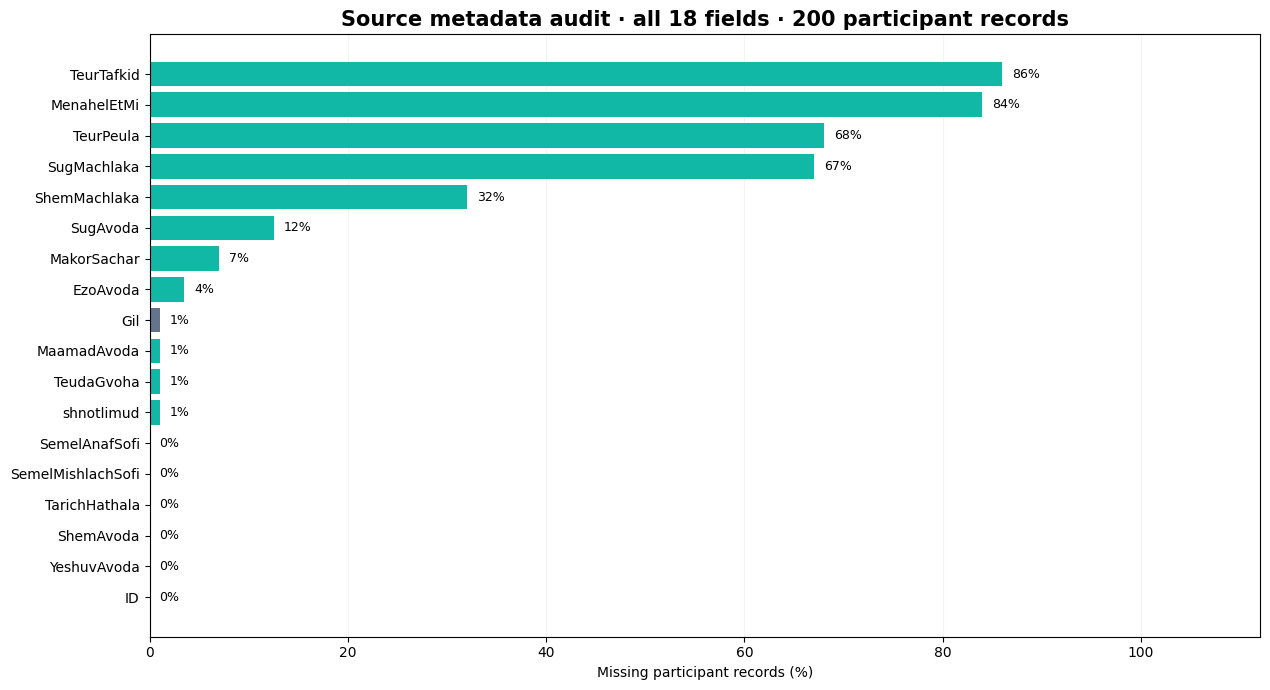

In [2]:
def infer_declared_enumerations_from_metadata(raw_enumeration_description):
    if pd.isna(raw_enumeration_description):
        return {}

    observed_code_descriptions = re.findall(r"(?m)^\s*(\d+)\.\s*(\S[^\n]*?)\s*$", str(raw_enumeration_description))

    return {int(code): description.strip() for code, description in observed_code_descriptions}


def infer_declared_code_width_from_metadata(raw_field_description):
    if pd.isna(raw_field_description):
        return None

    expected_code_width_match = re.search(r"מורכב\s*מ\s*[-־]?\s*(\d+)\s*ספרות", str(raw_field_description))

    return int(expected_code_width_match.group(1)) if expected_code_width_match else None


def identify_populated_source_values(source_field_values):
    return source_field_values.notna() & source_field_values.astype("string").str.strip().fillna("").ne("")


field_metadata_by_column = source_field_metadata.set_index("משתנה", verify_integrity=True)
declared_field_enumerations = {field_name: infer_declared_enumerations_from_metadata(field_metadata_by_column.loc[field_name, "ערכים אפשריים"]) for field_name in participant_survey_records.columns}
declared_field_code_widths = {field_name: infer_declared_code_width_from_metadata(field_metadata_by_column.loc[field_name, "הסבר"]) for field_name in participant_survey_records.columns}

assert declared_field_code_widths[OCCUPATION_CLASSIFICATION_TARGET_COLUMN] == 4
assert declared_field_code_widths["SemelAnafSofi"] == 4
assert set(OCCUPATIONAL_DESCRIPTION_COLUMNS) <= set(original_text_columns)
assert all(declared_field_enumerations[feature_name] for feature_name in NOMINAL_SURVEY_COLUMNS)
assert all(field_metadata_by_column.loc[feature_name, "פורמט"] == "INTEGER" for feature_name in NUMERICAL_SURVEY_COLUMNS)


source_column_audit_records = []
source_validation_issue_records = []

for field_name in participant_survey_records.columns:
    original_field_values = participant_survey_records[field_name]
    populated_field_values = identify_populated_source_values(original_field_values)
    expected_field_format = field_metadata_by_column.loc[field_name, "פורמט"]
    parsed_numeric_field_values = pd.to_numeric(original_field_values, errors="coerce") if expected_field_format == "INTEGER" else None
    field_validation_masks = {}

    if expected_field_format == "INTEGER":
        field_validation_masks["non_numeric"] = populated_field_values & parsed_numeric_field_values.isna()
        field_validation_masks["non_integral"] = parsed_numeric_field_values.notna() & parsed_numeric_field_values.mod(1).ne(0)

        if declared_field_enumerations[field_name]:
            field_validation_masks["outside_metadata_enumeration"] = parsed_numeric_field_values.notna() & ~parsed_numeric_field_values.isin(declared_field_enumerations[field_name])

    if expected_field_format == "TEXT" and declared_field_code_widths[field_name]:
        standardized_code_values = original_field_values.astype("string").str.strip()
        expected_code_shape = rf"[0-9Xx]{{{declared_field_code_widths[field_name]}}}"
        field_validation_masks["invalid_code_shape"] = populated_field_values & ~standardized_code_values.str.fullmatch(expected_code_shape, na=False)
        field_validation_masks["partially_classified_code"] = standardized_code_values.str.fullmatch(expected_code_shape, na=False) & standardized_code_values.str.contains("X", case=False, regex=False, na=False)

    if expected_field_format == "DATE":
        parsed_date_values = pd.to_datetime(original_field_values, errors="coerce", format="mixed")
        field_validation_masks["unparseable_date"] = populated_field_values & parsed_date_values.isna()

    for validation_rule_name, detected_issue_mask in field_validation_masks.items():
        if validation_rule_name == "partially_classified_code":
            continue

        for participant_row_number in participant_survey_records.index[detected_issue_mask.fillna(False)]:
            source_validation_issue_records.append({"participant_id": participant_survey_records.loc[participant_row_number, "ID"], "field_name": field_name, "validation_rule_name": validation_rule_name, "original_value": str(original_field_values.loc[participant_row_number])})

    declared_field_role = (
        "target_for_classification" if field_name == OCCUPATION_CLASSIFICATION_TARGET_COLUMN else
        "occupational_text_representation" if field_name in OCCUPATIONAL_DESCRIPTION_COLUMNS else
        "nominal_encoded_feature" if field_name in NOMINAL_SURVEY_COLUMNS else
        "numeric_imputed_feature" if field_name in NUMERICAL_SURVEY_COLUMNS else
        "identity_for_audit" if field_name == "ID" else
        "description_signature_only" if field_name == "ShemAvoda" else
        "excluded_to_prevent_unverified_operational_leakage" if field_name == "SemelAnafSofi" else
        "audit_only_not_approved_as_feature"
    )

    source_column_audit_records.append({
        "field_name": field_name,
        "metadata_declared_format": expected_field_format,
        "modeling_role": declared_field_role,
        "missing_values": int((~populated_field_values).sum()),
        "missing_percentage": float((~populated_field_values).mean() * 100),
        "distinct_populated_values": int(original_field_values.loc[populated_field_values].astype("string").nunique()),
        "metadata_enum_count": len(declared_field_enumerations[field_name]),
        "declared_code_width": declared_field_code_widths[field_name],
        "validation_issue_count": int(sum(detected_issue_mask.fillna(False).sum() for rule_name, detected_issue_mask in field_validation_masks.items() if rule_name != "partially_classified_code")),
        "partial_code_count": int(field_validation_masks["partially_classified_code"].sum()) if "partially_classified_code" in field_validation_masks else 0,
    })


source_column_audit = pd.DataFrame(source_column_audit_records)
source_validation_issues = pd.DataFrame(source_validation_issue_records)

assert len(source_column_audit) == 18
assert source_column_audit["field_name"].is_unique

applicable_salary_statuses = {code for code, meaning in declared_field_enumerations["MaamadAvoda"].items() if "שכיר" in meaning or "חבר קואופרטיב" in meaning}
assert applicable_salary_statuses == {1, 5}

reported_employment_status = pd.to_numeric(participant_survey_records["MaamadAvoda"], errors="coerce")
reported_salary_source_present = identify_populated_source_values(participant_survey_records["MakorSachar"])
nonapplicable_salary_source_conflicts = reported_employment_status.notna() & ~reported_employment_status.isin(applicable_salary_statuses) & reported_salary_source_present

print("Audited fields:", len(source_column_audit))
print("Detected type/domain violations:", len(source_validation_issues))
print("Employment/salary applicability conflicts:", int(nonapplicable_salary_source_conflicts.sum()))
display(source_column_audit[["field_name", "metadata_declared_format", "modeling_role", "missing_values", "distinct_populated_values", "validation_issue_count", "partial_code_count"]])


missingness_figure, missingness_axis = plt.subplots(figsize=(12.8, 7.0))
missingness_visual_data = source_column_audit.sort_values("missing_percentage")
missingness_role_colors = ["#12B8A6" if role in {"occupational_text_representation", "nominal_encoded_feature", "numeric_imputed_feature"} else "#64748B" for role in missingness_visual_data["modeling_role"]]

missingness_axis.barh(missingness_visual_data["field_name"], missingness_visual_data["missing_percentage"], color=missingness_role_colors)
missingness_axis.set_xlabel("Missing participant records (%)")
missingness_axis.set_xlim(0, 112)
missingness_axis.set_title("Source metadata audit · all 18 fields · 200 participant records", fontsize=15, weight="bold")
missingness_axis.grid(axis="x", alpha=0.15)
missingness_axis.set_axisbelow(True)

for visual_row_number, missing_percentage in enumerate(missingness_visual_data["missing_percentage"]):
    missingness_axis.text(missing_percentage + 1, visual_row_number, f"{missing_percentage:.0f}%", va="center", fontsize=9)

missingness_figure.tight_layout()
missingness_figure.savefig(OUTPUT_DIRECTORY / "all_18_metadata_fields_missingness.png", dpi=170, bbox_inches="tight")
plt.show()

## Block 04. Prepare model inputs and define target-label masks

**Assignment basis.** "המערכת אינה מחייבת את מילוי של כל השדות שבסקר, לכן ניתן לשדר את הסקרים שמולאו חלקית." The assignment also states "סימולים הכוללים את האות X : אלה רשומות שהסמלנים לא יכלו לסמלן בצורה מלאה."

**My decision.** I keep incomplete input fields because missing information is expected. I use `completely_labeled_records_mask` to select records with four known target digits for supervised training. I use `partially_labeled_records_mask` to select records containing an `X` in the four-character target for separate prediction and human review. Those records are not discarded from the prediction workflow.

**Advantage.** I avoid teaching the classifier that an incomplete human classification is a valid completed class, while retaining the records for which an automated suggestion is especially useful.

**Input handling.** The descriptive-field mask converts a small declared set of non-descriptive markers to empty text. This avoids learning token patterns from withholding or placeholder statements. This is my own convention, not an explicit requirement. The token `כנ"ל` means a reference to previous content, so replacing it with empty text may lose useful context. I retain that limitation in the audit rather than claiming it is harmless. I encode enumerated survey fields as nominal values, and preserve missing or inapplicable values distinctly where the metadata establishes the condition.

**Conditional salary-source decision.** The metadata explains that `MakorSachar` is filled only for employee or cooperative-member statuses as identified by `MaamadAvoda`. I therefore distinguish a genuinely missing salary source from a status for which the field does not apply.

**Validation design.** I keep the existing grouped holdout and internal validation strategy to reduce repeated-description leakage. Because the file lacks a verified stable participant identity across submissions, the grouping is a proxy and cannot establish that all repeated participants are grouped correctly.

## Feature preparation · Training-only learning · Leakage boundaries

The model uses six occupational text fields, four declared nominal fields, and one numerical education field. Identifiers, employer name, locality, start date, age, and final industry code remain outside the baseline feature set. In particular, availability of the final industry code before occupation classification is unverified.

A grouped external holdout is frozen before fitting representations. Internal evaluation uses three separate group-aware partitions derived only from the training set. Text-based groups are **proxies** for repeated descriptions, not verified participant identities, because stable respondent identifiers and submission timestamps are absent.

In [3]:
def normalize_description_text_for_participant_grouping(raw_description):
    if pd.isna(raw_description):
        return ""

    standardized_description = re.sub(r"[^\w\u0590-\u05ff]+", " ", str(raw_description).lower())

    return " ".join(standardized_description.split())


def prepare_occupation_model_features(source_survey_records):
    prepared_model_inputs = pd.DataFrame(index=source_survey_records.index)

    for occupational_description_column in OCCUPATIONAL_DESCRIPTION_COLUMNS:
        cleaned_descriptions = source_survey_records[occupational_description_column].astype("string").fillna("").str.replace(r"\s+", " ", regex=True).str.strip()
        prepared_model_inputs[occupational_description_column] = cleaned_descriptions.mask(cleaned_descriptions.isin(NONINFORMATIVE_DESCRIPTION_VALUES), "").astype(str)

    for nominal_survey_column in NOMINAL_SURVEY_COLUMNS:
        numerical_nominal_codes = pd.to_numeric(source_survey_records[nominal_survey_column], errors="coerce").astype("Int64")
        prepared_model_inputs[nominal_survey_column] = numerical_nominal_codes.astype("string").fillna("MISSING").astype(str)

    employment_status_values = pd.to_numeric(source_survey_records["MaamadAvoda"], errors="coerce")
    employment_status_eligible_for_salary_source = employment_status_values.isin(applicable_salary_statuses)
    employment_status_unknown = employment_status_values.isna()

    prepared_model_inputs.loc[~employment_status_eligible_for_salary_source & ~employment_status_unknown, "MakorSachar"] = "NOT_APPLICABLE"
    prepared_model_inputs.loc[employment_status_unknown, "MakorSachar"] = "APPLICABILITY_UNKNOWN"

    for numerical_survey_column in NUMERICAL_SURVEY_COLUMNS:
        prepared_model_inputs[numerical_survey_column] = pd.to_numeric(source_survey_records[numerical_survey_column], errors="coerce")

    assert prepared_model_inputs.columns.tolist() == MODEL_INPUT_COLUMNS

    return prepared_model_inputs


original_occupation_codes = participant_survey_records[OCCUPATION_CLASSIFICATION_TARGET_COLUMN].astype("string").str.strip()
completely_labeled_records_mask = original_occupation_codes.str.fullmatch(r"\d{4}", na=False)
partially_labeled_records_mask = original_occupation_codes.str.fullmatch(r"[0-9Xx]{4}", na=False) & original_occupation_codes.str.contains("X", case=False, regex=False, na=False)

assert completely_labeled_records_mask.sum() == 191
assert partially_labeled_records_mask.sum() == 9
assert (completely_labeled_records_mask | partially_labeled_records_mask).all()

participant_description_signatures = participant_survey_records[PARTICIPANT_DESCRIPTION_SIGNATURE_COLUMNS].apply(
    lambda survey_record: "|".join(normalize_description_text_for_participant_grouping(survey_record[field_name]) for field_name in PARTICIPANT_DESCRIPTION_SIGNATURE_COLUMNS), axis=1
)

completely_labeled_participant_records = participant_survey_records.loc[completely_labeled_records_mask].copy()
partially_labeled_participant_records = participant_survey_records.loc[partially_labeled_records_mask].copy()

all_labeled_model_inputs = prepare_occupation_model_features(completely_labeled_participant_records)
all_labeled_occupation_codes = completely_labeled_participant_records[OCCUPATION_CLASSIFICATION_TARGET_COLUMN].astype(str)
all_labeled_description_groups = participant_description_signatures.loc[completely_labeled_participant_records.index]

external_holdout_group_splitter = GroupShuffleSplit(n_splits=1, test_size=0.22, random_state=REPRODUCIBLE_RANDOM_STATE)
training_row_positions, external_holdout_row_positions = next(external_holdout_group_splitter.split(all_labeled_model_inputs, all_labeled_occupation_codes, groups=all_labeled_description_groups))

training_model_inputs = all_labeled_model_inputs.iloc[training_row_positions]
external_holdout_model_inputs = all_labeled_model_inputs.iloc[external_holdout_row_positions]
training_occupation_codes = all_labeled_occupation_codes.iloc[training_row_positions]
external_holdout_occupation_codes = all_labeled_occupation_codes.iloc[external_holdout_row_positions]
training_description_groups = all_labeled_description_groups.iloc[training_row_positions]
external_holdout_description_groups = all_labeled_description_groups.iloc[external_holdout_row_positions]

assert len(training_model_inputs) == 149
assert len(external_holdout_model_inputs) == 42
assert set(training_description_groups).isdisjoint(set(external_holdout_description_groups))
assert OCCUPATION_CLASSIFICATION_TARGET_COLUMN not in training_model_inputs
assert "SemelAnafSofi" not in training_model_inputs

internal_validation_group_splitter = GroupShuffleSplit(n_splits=3, test_size=0.24, random_state=REPRODUCIBLE_RANDOM_STATE + 10)
internal_validation_group_partitions = list(internal_validation_group_splitter.split(training_model_inputs, training_occupation_codes, groups=training_description_groups))

for training_fold_positions, validation_fold_positions in internal_validation_group_partitions:
    assert set(training_description_groups.iloc[training_fold_positions]).isdisjoint(set(training_description_groups.iloc[validation_fold_positions]))

print("Training participant records:", len(training_model_inputs))
print("External holdout participant records:", len(external_holdout_model_inputs))
print("Unseen occupational target codes in holdout:", int((~external_holdout_occupation_codes.isin(set(training_occupation_codes))).sum()))
print("Separate group-aware internal validation partitions:", len(internal_validation_group_partitions))

Training participant records: 149
External holdout participant records: 42
Unseen occupational target codes in holdout: 8
Separate group-aware internal validation partitions: 3


## Training-only text transformers · Explicit contextual grouping

One transformer generates direct character n-gram TF-IDF representations. Another trains a separate contextual grouping for each occupational text column, with explicit sparse or dense input storage and L2 normalization.

The number of groups is evaluated at every integer from two through `min(1000, number_of_distinct_training_descriptions - 1)`. Candidate scores use the Calinski–Harabasz variance ratio, which compares between-group dispersion against within-group dispersion. The optimal number of contextual groups means *the highest valid score among tested candidates*, not a universally optimal semantic or production grouping.

`KMeans` is the published scikit-learn estimator for **both sparse and dense inputs**, rather than a different library estimator named “SparseKMeans.” Smoothing is varied before the normalization step. Fitted encoders and groups never use target codes.

In [4]:
def standardize_text_vectorizer_input(source_description_values):
    if isinstance(source_description_values, pd.DataFrame):
        selected_text_values = source_description_values.iloc[:, 0]
    elif isinstance(source_description_values, pd.Series):
        selected_text_values = source_description_values
    else:
        selected_text_values = pd.Series(np.asarray(source_description_values, dtype=object).reshape(-1))

    return selected_text_values.fillna("").astype(str).tolist()


class EmptySafeOccupationalTfidfEncoding(BaseEstimator, TransformerMixin):
    def __init__(self, l2_normalization_enabled=True, tfidf_smoothing_enabled=True, maximum_character_features=MAXIMUM_CHARACTER_NGRAM_FEATURES):
        self.l2_normalization_enabled = l2_normalization_enabled
        self.tfidf_smoothing_enabled = tfidf_smoothing_enabled
        self.maximum_character_features = maximum_character_features

    def fit(self, source_description_values, occupational_target_codes=None):
        training_descriptions = standardize_text_vectorizer_input(source_description_values)
        self.all_training_descriptions_empty_ = not any(len(text_value) >= 2 for text_value in training_descriptions)
        self.learned_text_vectorizer_ = None

        if not self.all_training_descriptions_empty_:
            self.learned_text_vectorizer_ = TfidfVectorizer(
                analyzer="char",
                ngram_range=(2, 4),
                max_features=self.maximum_character_features,
                norm="l2" if self.l2_normalization_enabled else None,
                smooth_idf=self.tfidf_smoothing_enabled,
                sublinear_tf=True,
            )

            self.learned_text_vectorizer_.fit(training_descriptions)

        return self

    def transform(self, source_description_values):
        prediction_descriptions = standardize_text_vectorizer_input(source_description_values)

        if self.all_training_descriptions_empty_:
            from scipy.sparse import csr_matrix

            return csr_matrix((len(prediction_descriptions), 1), dtype=float)

        return self.learned_text_vectorizer_.transform(prediction_descriptions)


class TrainingOnlyVarianceBalancedContextualGrouping(BaseEstimator, TransformerMixin):
    def __init__(self, occupational_description_columns=tuple(OCCUPATIONAL_DESCRIPTION_COLUMNS), tfidf_smoothing_enabled=True, vector_storage_format="sparse", maximum_contextual_groups=MAXIMUM_CONTEXTUAL_GROUPS_SAFETY_LIMIT, repeated_initializations=CONTEXTUAL_GROUPING_INITIALIZATIONS, maximum_iterations=CONTEXTUAL_GROUPING_MAXIMUM_ITERATIONS, random_state=REPRODUCIBLE_RANDOM_STATE):
        self.occupational_description_columns = occupational_description_columns
        self.tfidf_smoothing_enabled = tfidf_smoothing_enabled
        self.vector_storage_format = vector_storage_format
        self.maximum_contextual_groups = maximum_contextual_groups
        self.repeated_initializations = repeated_initializations
        self.maximum_iterations = maximum_iterations
        self.random_state = random_state

    def fit(self, source_description_frame, occupational_target_codes=None):
        if self.vector_storage_format not in {"dense", "sparse"}:
            raise ValueError("Only dense and sparse vector storage formats are supported")

        training_description_frame = pd.DataFrame(source_description_frame, columns=self.occupational_description_columns)
        self.trained_column_encoders_ = {}
        self.candidate_variance_balance_evaluations_ = []
        self.optimal_contextual_grouping_configurations_ = []
        self.optimal_contextual_group_memberships_ = []

        for occupational_text_column in self.occupational_description_columns:
            distinct_training_descriptions = sorted(description for description in training_description_frame[occupational_text_column].fillna("").astype(str).unique() if description.strip())
            number_of_distinct_descriptions = len(distinct_training_descriptions)

            trained_column_configuration = {
                "fallback_only": True,
                "known_description_group_assignments": {},
                "optimal_number_of_contextual_groups": None,
            }

            column_candidate_evaluations = []
            fitted_candidate_models = {}
            number_of_distinct_vector_representations = 0

            if number_of_distinct_descriptions >= 3:
                column_vectorizer = EmptySafeOccupationalTfidfEncoding(l2_normalization_enabled=True, tfidf_smoothing_enabled=self.tfidf_smoothing_enabled)
                normalized_sparse_description_vectors = column_vectorizer.fit_transform(distinct_training_descriptions).tocsr()
                normalized_dense_description_vectors = normalized_sparse_description_vectors.toarray()
                normalized_vector_norms = np.linalg.norm(normalized_dense_description_vectors, axis=1)

                np.testing.assert_allclose(normalized_vector_norms[normalized_vector_norms > 0], 1.0, rtol=1e-12, atol=1e-12)

                number_of_distinct_vector_representations = int(np.unique(np.round(normalized_dense_description_vectors, 12), axis=0).shape[0])
                actual_description_vectors = normalized_dense_description_vectors if self.vector_storage_format == "dense" else normalized_sparse_description_vectors
                maximum_tested_number_of_contextual_groups = min(self.maximum_contextual_groups, number_of_distinct_descriptions - 1)

                for number_of_contextual_groups in range(2, maximum_tested_number_of_contextual_groups + 1):
                    contextual_grouping_model = KMeans(n_clusters=number_of_contextual_groups, n_init=self.repeated_initializations, max_iter=self.maximum_iterations, random_state=self.random_state, algorithm="lloyd")
                    estimator_error_message = ""

                    try:
                        with warnings.catch_warnings(record=True) as convergence_warnings:
                            warnings.simplefilter("always", category=ConvergenceWarning)
                            observed_group_assignments = contextual_grouping_model.fit_predict(actual_description_vectors)

                        observed_number_of_groups = int(np.unique(observed_group_assignments).size)
                        estimator_warning_messages = " | ".join(str(warning.message) for warning in convergence_warnings)
                    except Exception as estimator_failure:
                        observed_group_assignments = np.array([], dtype=int)
                        observed_number_of_groups = 0
                        estimator_warning_messages = ""
                        estimator_error_message = f"{type(estimator_failure).__name__}: {estimator_failure}"

                    variance_balance_score = np.nan
                    within_group_dispersion = np.nan
                    evaluation_status = "valid"
                    observed_singleton_group_count = 0

                    if estimator_error_message:
                        evaluation_status = "estimator_failed"
                    elif observed_number_of_groups != number_of_contextual_groups:
                        evaluation_status = "fewer_nonempty_groups_than_requested"
                    else:
                        within_group_dispersion = float(contextual_grouping_model.inertia_)
                        observed_group_sizes = np.bincount(observed_group_assignments)
                        observed_singleton_group_count = int(np.count_nonzero(observed_group_sizes == 1))

                        if within_group_dispersion <= 1e-13:
                            evaluation_status = "zero_within_group_variance"
                        else:
                            variance_balance_score = float(calinski_harabasz_score(normalized_dense_description_vectors, observed_group_assignments))

                            if not np.isfinite(variance_balance_score):
                                evaluation_status = "nonfinite_variance_balance_score"
                            else:
                                fitted_candidate_models[number_of_contextual_groups] = contextual_grouping_model

                    candidate_evaluation = {
                        "occupational_text_column": occupational_text_column,
                        "tfidf_smoothing_enabled": self.tfidf_smoothing_enabled,
                        "vector_storage_format": self.vector_storage_format,
                        "number_of_distinct_text_values": number_of_distinct_descriptions,
                        "number_of_distinct_vector_representations": number_of_distinct_vector_representations,
                        "number_of_contextual_groups": number_of_contextual_groups,
                        "observed_number_of_contextual_groups": observed_number_of_groups,
                        "within_group_dispersion": within_group_dispersion,
                        "variance_balance_score": variance_balance_score,
                        "number_of_singleton_groups": observed_singleton_group_count,
                        "evaluation_status": evaluation_status,
                        "estimator_warning_messages": estimator_warning_messages,
                    }

                    column_candidate_evaluations.append(candidate_evaluation)
                    self.candidate_variance_balance_evaluations_.append(candidate_evaluation)

                valid_grouping_candidates = [candidate for candidate in column_candidate_evaluations if candidate["evaluation_status"] == "valid"]

                if valid_grouping_candidates:
                    optimal_grouping_candidate = sorted(valid_grouping_candidates, key=lambda candidate: (-candidate["variance_balance_score"], candidate["number_of_contextual_groups"]))[0]
                    optimal_number_of_contextual_groups = optimal_grouping_candidate["number_of_contextual_groups"]
                    selected_contextual_grouping_model = fitted_candidate_models[optimal_number_of_contextual_groups]

                    trained_column_configuration = {
                        "fallback_only": False,
                        "known_description_group_assignments": dict(zip(distinct_training_descriptions, selected_contextual_grouping_model.labels_)),
                        "optimal_number_of_contextual_groups": optimal_number_of_contextual_groups,
                        "selected_contextual_grouping_model": selected_contextual_grouping_model,
                        "learned_text_vectorizer": column_vectorizer,
                    }

                    for original_training_description, selected_group_number in zip(distinct_training_descriptions, selected_contextual_grouping_model.labels_):
                        self.optimal_contextual_group_memberships_.append({
                            "occupational_text_column": occupational_text_column,
                            "tfidf_smoothing_enabled": self.tfidf_smoothing_enabled,
                            "vector_storage_format": self.vector_storage_format,
                            "observed_description": original_training_description,
                            "assigned_contextual_group": f"contextual_group_{int(selected_group_number):03d}",
                        })

            self.trained_column_encoders_[occupational_text_column] = trained_column_configuration
            self.optimal_contextual_grouping_configurations_.append({
                "occupational_text_column": occupational_text_column,
                "tfidf_smoothing_enabled": self.tfidf_smoothing_enabled,
                "vector_storage_format": self.vector_storage_format,
                "number_of_distinct_text_values": number_of_distinct_descriptions,
                "number_of_candidate_group_counts": len(column_candidate_evaluations),
                "number_of_valid_candidate_group_counts": sum(candidate["evaluation_status"] == "valid" for candidate in column_candidate_evaluations),
                "optimal_number_of_contextual_groups": trained_column_configuration["optimal_number_of_contextual_groups"],
                "optimal_variance_balance_score": optimal_grouping_candidate["variance_balance_score"] if not trained_column_configuration["fallback_only"] else np.nan,
                "optimal_singleton_group_count": optimal_grouping_candidate["number_of_singleton_groups"] if not trained_column_configuration["fallback_only"] else np.nan,
            })

        return self

    def transform(self, source_description_frame):
        prediction_description_frame = pd.DataFrame(source_description_frame, columns=self.occupational_description_columns)
        categorical_grouping_features = np.empty((len(prediction_description_frame), len(self.occupational_description_columns)), dtype=object)

        for text_column_position, occupational_text_column in enumerate(self.occupational_description_columns):
            trained_column_configuration = self.trained_column_encoders_[occupational_text_column]
            prediction_descriptions = prediction_description_frame[occupational_text_column].fillna("").astype(str).tolist()
            predicted_contextual_groups = []

            for occupational_description in prediction_descriptions:
                if not occupational_description.strip():
                    predicted_contextual_groups.append("MISSING_DESCRIPTION")
                elif occupational_description in trained_column_configuration["known_description_group_assignments"]:
                    existing_group_number = int(trained_column_configuration["known_description_group_assignments"][occupational_description])
                    predicted_contextual_groups.append(f"contextual_group_{existing_group_number:03d}")
                elif trained_column_configuration["fallback_only"]:
                    predicted_contextual_groups.append("UNSEEN_DESCRIPTION")
                else:
                    unseen_description_vector = trained_column_configuration["learned_text_vectorizer"].transform([occupational_description])
                    unseen_description_group = int(trained_column_configuration["selected_contextual_grouping_model"].predict(unseen_description_vector if self.vector_storage_format == "sparse" else unseen_description_vector.toarray())[0])
                    predicted_contextual_groups.append(f"contextual_group_{unseen_description_group:03d}")

            categorical_grouping_features[:, text_column_position] = predicted_contextual_groups

        return categorical_grouping_features

    def get_feature_names_out(self, input_features=None):
        return np.asarray(self.occupational_description_columns, dtype=object)


print("Eight representation experiments use the same source-column contracts and classifier")

Eight representation experiments use the same source-column contracts and classifier


## Block 06. Preserve the completed experimental encoding comparisons

**Assignment basis.** The assignment requires training a model to predict `SemelMishlachSofi`. It does not request eight text representations or one-hot encoding of free-written descriptions.

**My decision.** The previously completed comparisons remain visible because the study already evaluated them. One-hot encoding of whole free-written descriptions is an alternative that was tested, not the justified default for open-ended text. The selected modeling route must be described according to the transformation it actually performs. TF-IDF of the raw description and one-hot encoding of metadata-declared category codes remain separate operations.

**Advantage.** Keeping historical comparison evidence makes the experiment auditable without implying that all tested representations are equally appropriate. The version 10 results are retained as historical measurements. This documentation change does not constitute a new training run or a new performance estimate.

## Four direct encodings + four contextual grouping configurations

The **four direct encodings** are one-hot of whole description labels, direct unnormalized and unsmoothed TF-IDF, L2-normalized unsmoothed TF-IDF, and L2-normalized smoothed TF-IDF.

The **four contextual grouping configurations** use L2-normalized TF-IDF with dense or sparse `KMeans` inputs and smoothed or unsmoothed inverse-document-frequency. The selected group identifiers are nominally encoded before classification.

Every representation uses exactly the same six text columns, four nominal columns, numeric education preprocessing, and logistic regression classifier.

In [5]:
EVALUATED_OCCUPATIONAL_TEXT_REPRESENTATIONS = [
    {"representation_name": "01 · One-hot description labels", "representation_family": "one_hot", "l2_normalization_enabled": False, "tfidf_smoothing_enabled": None, "vector_storage_format": None},
    {"representation_name": "02 · Direct TF-IDF · no L2 · unsmoothed", "representation_family": "direct_tfidf", "l2_normalization_enabled": False, "tfidf_smoothing_enabled": False, "vector_storage_format": "sparse"},
    {"representation_name": "03 · Direct TF-IDF · L2 · unsmoothed", "representation_family": "direct_tfidf", "l2_normalization_enabled": True, "tfidf_smoothing_enabled": False, "vector_storage_format": "sparse"},
    {"representation_name": "04 · Direct TF-IDF · L2 · smoothed", "representation_family": "direct_tfidf", "l2_normalization_enabled": True, "tfidf_smoothing_enabled": True, "vector_storage_format": "sparse"},
    {"representation_name": "05 · Contextual groups · dense · unsmoothed", "representation_family": "contextual_grouping", "l2_normalization_enabled": True, "tfidf_smoothing_enabled": False, "vector_storage_format": "dense"},
    {"representation_name": "06 · Contextual groups · sparse · unsmoothed", "representation_family": "contextual_grouping", "l2_normalization_enabled": True, "tfidf_smoothing_enabled": False, "vector_storage_format": "sparse"},
    {"representation_name": "07 · Contextual groups · dense · smoothed", "representation_family": "contextual_grouping", "l2_normalization_enabled": True, "tfidf_smoothing_enabled": True, "vector_storage_format": "dense"},
    {"representation_name": "08 · Contextual groups · sparse · smoothed", "representation_family": "contextual_grouping", "l2_normalization_enabled": True, "tfidf_smoothing_enabled": True, "vector_storage_format": "sparse"},
]

assert len(EVALUATED_OCCUPATIONAL_TEXT_REPRESENTATIONS) == 8


def build_training_only_occupation_classification_pipeline(representation_configuration):
    representation_family = representation_configuration["representation_family"]

    if representation_family == "one_hot":
        occupational_description_transformers = [("occupational_description_one_hot_encoding", OneHotEncoder(handle_unknown="ignore"), OCCUPATIONAL_DESCRIPTION_COLUMNS)]

    elif representation_family == "direct_tfidf":
        occupational_description_transformers = [
            (
                f"direct_tfidf_encoding_of_{occupational_text_column}",
                EmptySafeOccupationalTfidfEncoding(
                    l2_normalization_enabled=representation_configuration["l2_normalization_enabled"],
                    tfidf_smoothing_enabled=representation_configuration["tfidf_smoothing_enabled"],
                ),
                occupational_text_column,
            )
            for occupational_text_column in OCCUPATIONAL_DESCRIPTION_COLUMNS
        ]

    elif representation_family == "contextual_grouping":
        training_only_contextual_grouping = TrainingOnlyVarianceBalancedContextualGrouping(
            occupational_description_columns=tuple(OCCUPATIONAL_DESCRIPTION_COLUMNS),
            tfidf_smoothing_enabled=representation_configuration["tfidf_smoothing_enabled"],
            vector_storage_format=representation_configuration["vector_storage_format"],
        )

        occupational_description_transformers = [
            (
                "selected_contextual_group_labels_then_one_hot",
                Pipeline([
                    ("optimal_contextual_grouping_by_variance_balance", training_only_contextual_grouping),
                    ("nominal_encoding_of_contextual_group_labels", OneHotEncoder(handle_unknown="ignore")),
                ]),
                OCCUPATIONAL_DESCRIPTION_COLUMNS,
            )
        ]

    else:
        raise ValueError("Unknown occupational text representation")

    survey_feature_transformer = ColumnTransformer(
        [
            *occupational_description_transformers,
            ("source_nominal_code_one_hot_encoding", OneHotEncoder(handle_unknown="ignore"), NOMINAL_SURVEY_COLUMNS),
            (
                "numerical_source_feature_preprocessing",
                Pipeline([
                    ("training_median_imputation", SimpleImputer(strategy="median", add_indicator=True)),
                    ("training_only_standardization", StandardScaler()),
                ]),
                NUMERICAL_SURVEY_COLUMNS,
            ),
        ],
        remainder="drop",
        sparse_threshold=1.0,
    )

    occupational_classifier = LogisticRegression(C=1.0, solver="lbfgs", max_iter=1200, random_state=REPRODUCIBLE_RANDOM_STATE)

    return Pipeline([
        ("train_only_survey_representation", survey_feature_transformer),
        ("four_digit_occupation_code_classifier", occupational_classifier),
    ])


def measure_occupation_classification_performance(actual_occupation_codes, predicted_occupation_codes):
    return {
        "accuracy": float(accuracy_score(actual_occupation_codes, predicted_occupation_codes)),
        "macro_precision": float(precision_score(actual_occupation_codes, predicted_occupation_codes, average="macro", zero_division=0)),
        "macro_recall": float(recall_score(actual_occupation_codes, predicted_occupation_codes, average="macro", zero_division=0)),
        "macro_f1": float(f1_score(actual_occupation_codes, predicted_occupation_codes, average="macro", zero_division=0)),
        "weighted_f1": float(f1_score(actual_occupation_codes, predicted_occupation_codes, average="weighted", zero_division=0)),
    }


for representation_configuration in EVALUATED_OCCUPATIONAL_TEXT_REPRESENTATIONS:
    print(representation_configuration["representation_name"])

01 · One-hot description labels
02 · Direct TF-IDF · no L2 · unsmoothed
03 · Direct TF-IDF · L2 · unsmoothed
04 · Direct TF-IDF · L2 · smoothed
05 · Contextual groups · dense · unsmoothed
06 · Contextual groups · sparse · unsmoothed
07 · Contextual groups · dense · smoothed
08 · Contextual groups · sparse · smoothed


## Group-aware classification evaluation · Eight pipelines

All models are fitted separately within each internal validation fold. Selection uses the mean **macro-F1**, with macro-recall and a predeclared complexity order resolving ties. The 42-record external holdout is evaluated after the internal selection is fixed. Other holdout scores are shown as transparent comparisons and are not used to revise the selected configuration.

The notebook reports accuracy, macro-precision, macro-recall, macro-F1, weighted-F1, exact correct counts, fitted feature dimensions, and training runtime. These are simulation results rather than estimates of operational accuracy.

In [6]:
internal_validation_performance_records = []

for validation_partition_number, (training_fold_positions, validation_fold_positions) in enumerate(internal_validation_group_partitions, start=1):
    fold_training_inputs = training_model_inputs.iloc[training_fold_positions]
    fold_validation_inputs = training_model_inputs.iloc[validation_fold_positions]
    fold_training_occupation_codes = training_occupation_codes.iloc[training_fold_positions]
    fold_validation_occupation_codes = training_occupation_codes.iloc[validation_fold_positions]

    for representation_configuration in EVALUATED_OCCUPATIONAL_TEXT_REPRESENTATIONS:
        occupation_classification_pipeline = build_training_only_occupation_classification_pipeline(representation_configuration)
        training_start_time = perf_counter()

        occupation_classification_pipeline.fit(fold_training_inputs, fold_training_occupation_codes)
        predicted_validation_occupation_codes = occupation_classification_pipeline.predict(fold_validation_inputs)

        recorded_validation_performance = {
            "internal_validation_partition": validation_partition_number,
            "representation_name": representation_configuration["representation_name"],
            "representation_family": representation_configuration["representation_family"],
            "training_participant_records": len(fold_training_inputs),
            "validation_participant_records": len(fold_validation_inputs),
            "unseen_occupation_code_records": int((~fold_validation_occupation_codes.isin(set(fold_training_occupation_codes))).sum()),
            "training_elapsed_seconds": perf_counter() - training_start_time,
        }

        recorded_validation_performance.update(measure_occupation_classification_performance(fold_validation_occupation_codes, predicted_validation_occupation_codes))
        internal_validation_performance_records.append(recorded_validation_performance)

    print(f"Completed internal validation partition {validation_partition_number} of {len(internal_validation_group_partitions)}", flush=True)


internal_validation_performance = pd.DataFrame(internal_validation_performance_records)
internal_representation_summary = (
    internal_validation_performance.groupby(["representation_name", "representation_family"], as_index=False)
    .agg(
        internal_macro_f1_mean=("macro_f1", "mean"),
        internal_macro_f1_standard_deviation=("macro_f1", "std"),
        internal_macro_recall_mean=("macro_recall", "mean"),
        internal_accuracy_mean=("accuracy", "mean"),
        cumulative_training_elapsed_seconds=("training_elapsed_seconds", "sum"),
    )
)

representation_complexity_order = {configuration["representation_name"]: representation_number for representation_number, configuration in enumerate(EVALUATED_OCCUPATIONAL_TEXT_REPRESENTATIONS)}
internal_representation_summary["representation_complexity_order"] = internal_representation_summary["representation_name"].map(representation_complexity_order)

internal_representation_summary = internal_representation_summary.sort_values(
    ["internal_macro_f1_mean", "internal_macro_recall_mean", "representation_complexity_order"], ascending=[False, False, True]
).reset_index(drop=True)

internally_selected_representation_name = internal_representation_summary.loc[0, "representation_name"]

print("Selected by internal grouped validation only:", internally_selected_representation_name)
display(internal_representation_summary.round(4))


external_holdout_performance_records = []
external_holdout_predicted_codes_by_representation = {}
fully_trained_classification_pipelines = {}

for representation_configuration in EVALUATED_OCCUPATIONAL_TEXT_REPRESENTATIONS:
    representation_name = representation_configuration["representation_name"]
    occupation_classification_pipeline = build_training_only_occupation_classification_pipeline(representation_configuration)
    training_start_time = perf_counter()

    occupation_classification_pipeline.fit(training_model_inputs, training_occupation_codes)
    external_holdout_prediction = occupation_classification_pipeline.predict(external_holdout_model_inputs)
    transformed_training_input_dimensions = occupation_classification_pipeline.named_steps["train_only_survey_representation"].transform(training_model_inputs).shape[1]

    observed_holdout_performance = {
        "representation_name": representation_name,
        "representation_family": representation_configuration["representation_family"],
        "correctly_classified_participant_records": int(np.sum(external_holdout_prediction == external_holdout_occupation_codes.to_numpy())),
        "total_transformed_input_features": int(transformed_training_input_dimensions),
        "training_elapsed_seconds": perf_counter() - training_start_time,
    }

    observed_holdout_performance.update(measure_occupation_classification_performance(external_holdout_occupation_codes, external_holdout_prediction))
    external_holdout_performance_records.append(observed_holdout_performance)
    external_holdout_predicted_codes_by_representation[representation_name] = external_holdout_prediction
    fully_trained_classification_pipelines[representation_name] = occupation_classification_pipeline

    print("Completed frozen holdout assessment:", representation_name, flush=True)


external_holdout_performance = pd.DataFrame(external_holdout_performance_records)
external_holdout_performance["internally_selected"] = external_holdout_performance["representation_name"].eq(internally_selected_representation_name)

external_holdout_predictions = pd.DataFrame({
    "participant_id": completely_labeled_participant_records.iloc[external_holdout_row_positions]["ID"].astype(int).to_numpy(),
    "actual_occupation_code": external_holdout_occupation_codes.to_numpy(),
    **external_holdout_predicted_codes_by_representation,
})

assert len(external_holdout_performance) == 8
assert len(external_holdout_predictions) == 42

print("Frozen holdout comparisons across eight representations:")
display(external_holdout_performance.round(4))

Completed internal validation partition 1 of 3


Completed internal validation partition 2 of 3


Completed internal validation partition 3 of 3


Selected by internal grouped validation only: 02 · Direct TF-IDF · no L2 · unsmoothed


,representation_name,representation_family,internal_macro_f1_mean,internal_macro_f1_standard_deviation,internal_macro_recall_mean,internal_accuracy_mean,cumulative_training_elapsed_seconds,representation_complexity_order
0,02 · Direct TF-IDF · no L2 · unsmoothed,direct_tfidf,0.5225,0.0147,0.5539,0.6783,3.9430,1
1,03 · Direct TF-IDF · L2 · unsmoothed,direct_tfidf,0.4604,0.0515,0.4807,0.6309,0.9242,2
2,04 · Direct TF-IDF · L2 · smoothed,direct_tfidf,0.4604,0.0515,0.4807,0.6309,0.9263,3
3,07 · Contextual groups · dense · smoothed,contextual_grouping,0.4258,0.0107,0.4469,0.6022,3.9568,6
4,08 · Contextual groups · sparse · smoothed,contextual_grouping,0.4258,0.0107,0.4469,0.6022,9.0826,7
5,05 · Contextual groups · dense · unsmoothed,contextual_grouping,0.4210,0.0107,0.4417,0.6022,4.5049,4
6,06 · Contextual groups · sparse · unsmoothed,contextual_grouping,0.4210,0.0107,0.4417,0.6022,9.4232,5
7,01 · One-hot description labels,one_hot,0.3722,0.0169,0.3903,0.5462,0.1295,0


Completed frozen holdout assessment: 01 · One-hot description labels


... (5 outputs left out)

Completed frozen holdout assessment: 07 · Contextual groups · dense · smoothed


Completed frozen holdout assessment: 08 · Contextual groups · sparse · smoothed


Frozen holdout comparisons across eight representations:


,representation_name,representation_family,correctly_classified_participant_records,total_transformed_input_features,training_elapsed_seconds,accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,internally_selected
0,01 · One-hot description labels,one_hot,30,269,0.0527,0.7143,0.5071,0.5309,0.5033,0.6954,False
1,02 · Direct TF-IDF · no L2 · unsmoothed,direct_tfidf,27,4090,2.9374,0.6429,0.4550,0.4568,0.4461,0.6185,True
2,03 · Direct TF-IDF · L2 · unsmoothed,direct_tfidf,31,4090,0.3663,0.7381,0.4737,0.5185,0.4879,0.6973,False
3,04 · Direct TF-IDF · L2 · smoothed,direct_tfidf,31,4090,0.3589,0.7381,0.4737,0.5185,0.4879,0.6973,False
4,05 · Contextual groups · dense · unsmoothed,contextual_grouping,32,262,1.8207,0.7619,0.4949,0.5357,0.5092,0.7350,False
5,06 · Contextual groups · sparse · unsmoothed,contextual_grouping,32,262,4.2297,0.7619,0.4949,0.5357,0.5092,0.7350,False
6,07 · Contextual groups · dense · smoothed,contextual_grouping,32,262,1.9529,0.7619,0.4949,0.5357,0.5092,0.7350,False
7,08 · Contextual groups · sparse · smoothed,contextual_grouping,32,262,4.1966,0.7619,0.4949,0.5357,0.5092,0.7350,False


## Every contextual grouping candidate · Actual variance-balance curves

Four curves are plotted for **each of six original occupational description columns**, using the identical candidate group-count sequence within that column. Every measured score is exported to CSV, with all four evaluated configurations represented and the selected scores annotated.

The horizontal axes show integer numbers of contextual groups and the vertical axes show integer score ticks. Numeric labels preserve decimal score precision at selected optima. Full candidate tables retain unrounded scores.

**Interpretive warning.** Optimizing Calinski–Harabasz may produce almost one group per distinct description. Inspect the number of singleton groups before concluding that the optimization created useful contextual consolidation.

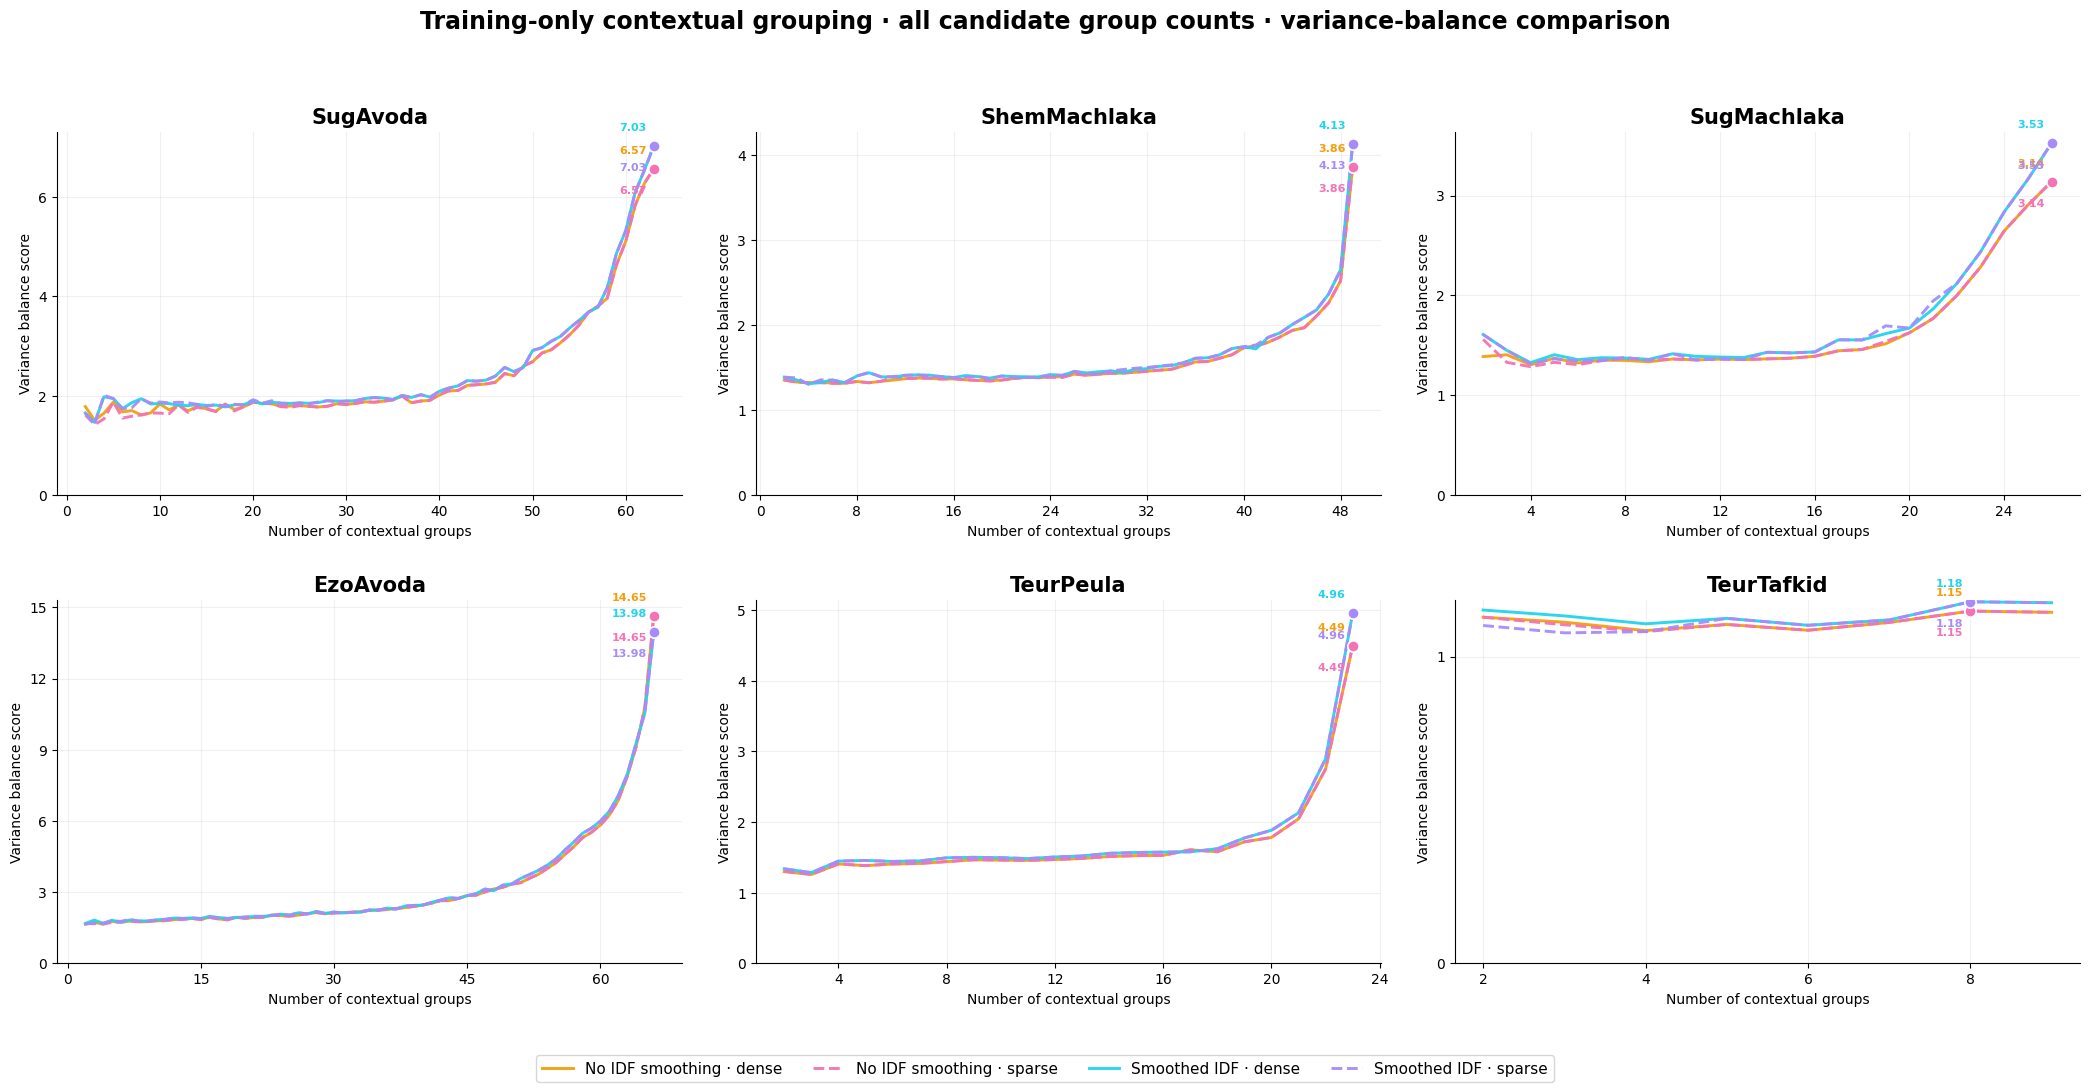

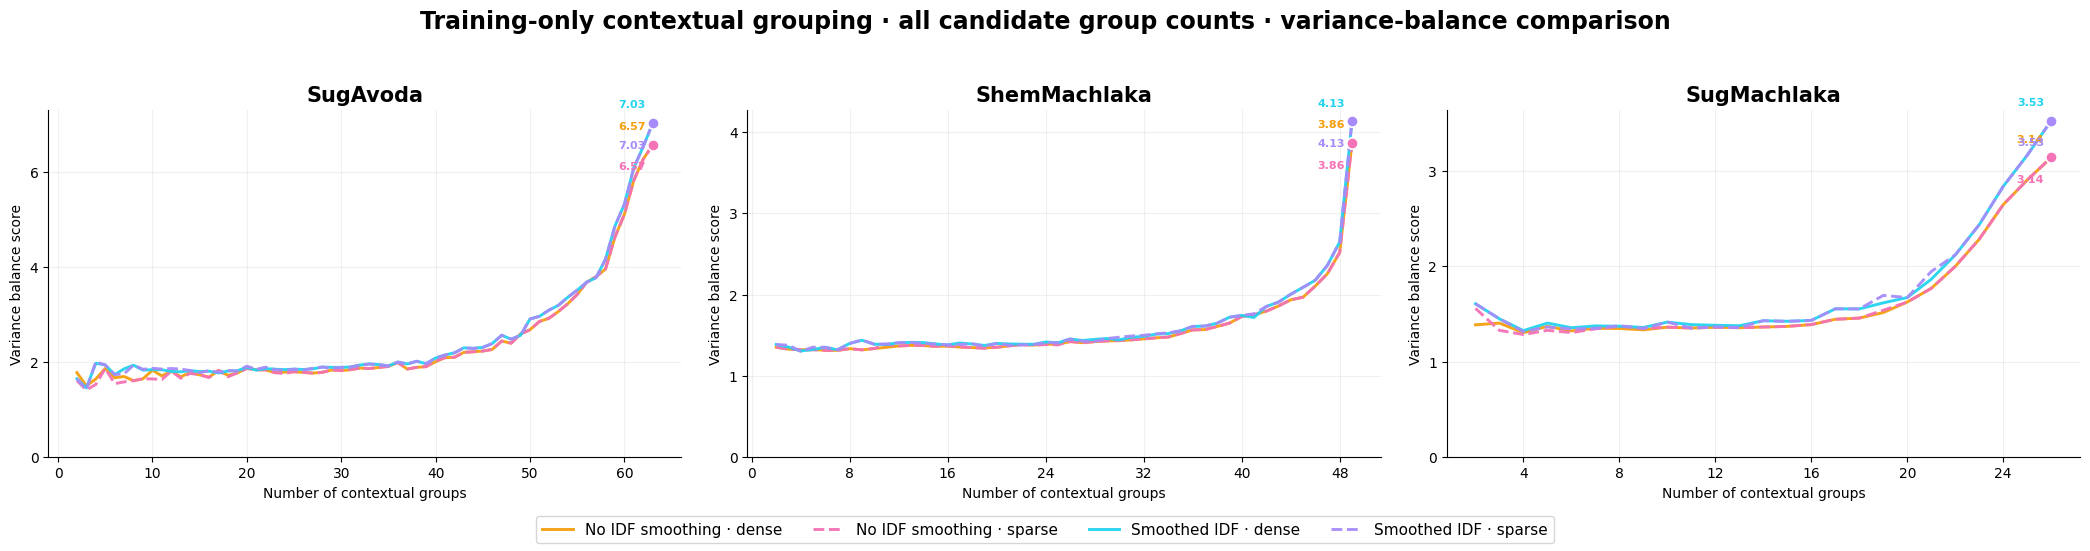

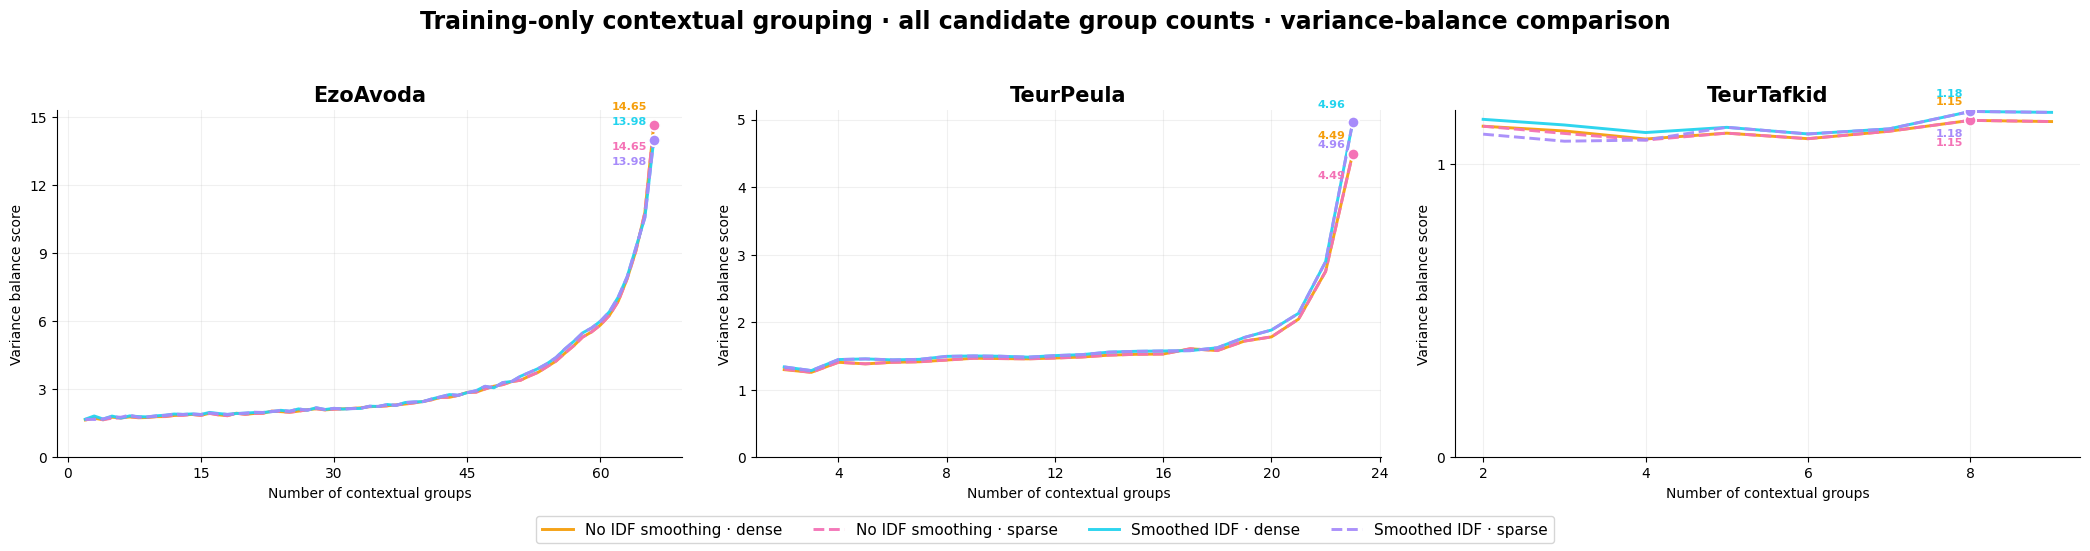

Complete candidate evaluations: 920
Mathematically invalid candidate evaluations: 0


,occupational_text_column,tfidf_smoothing_enabled,vector_storage_format,number_of_distinct_text_values,number_of_candidate_group_counts,number_of_valid_candidate_group_counts,optimal_number_of_contextual_groups,optimal_variance_balance_score,optimal_singleton_group_count,fraction_of_groups_containing_one_description
0,SugAvoda,False,dense,64,62,62,63,6.5677,62,0.9841
1,ShemMachlaka,False,dense,50,48,48,49,3.8639,48,0.9796
2,SugMachlaka,False,dense,27,25,25,26,3.1400,25,0.9615
3,EzoAvoda,False,dense,67,65,65,66,14.6493,65,0.9848
4,TeurPeula,False,dense,24,22,22,23,4.4938,22,0.9565
5,TeurTafkid,False,dense,10,8,8,8,1.1482,6,0.7500
6,SugAvoda,False,sparse,64,62,62,63,6.5677,62,0.9841
7,ShemMachlaka,False,sparse,50,48,48,49,3.8639,48,0.9796
8,SugMachlaka,False,sparse,27,25,25,26,3.1400,25,0.9615
9,EzoAvoda,False,sparse,67,65,65,66,14.6493,65,0.9848


In [7]:
all_contextual_grouping_candidate_evaluations = []
all_optimal_contextual_grouping_configurations = []
all_optimal_group_memberships = []

for representation_configuration in EVALUATED_OCCUPATIONAL_TEXT_REPRESENTATIONS:
    if representation_configuration["representation_family"] != "contextual_grouping":
        continue

    matching_fitted_pipeline = fully_trained_classification_pipelines[representation_configuration["representation_name"]]
    matched_survey_encoder = matching_fitted_pipeline.named_steps["train_only_survey_representation"]
    selected_grouping_preprocessor = matched_survey_encoder.named_transformers_["selected_contextual_group_labels_then_one_hot"]
    selected_contextual_grouping_transformer = selected_grouping_preprocessor.named_steps["optimal_contextual_grouping_by_variance_balance"]

    all_contextual_grouping_candidate_evaluations.extend(selected_contextual_grouping_transformer.candidate_variance_balance_evaluations_)
    all_optimal_contextual_grouping_configurations.extend(selected_contextual_grouping_transformer.optimal_contextual_grouping_configurations_)
    all_optimal_group_memberships.extend(selected_contextual_grouping_transformer.optimal_contextual_group_memberships_)


contextual_grouping_candidate_evaluations = pd.DataFrame(all_contextual_grouping_candidate_evaluations)
optimal_contextual_grouping_configurations = pd.DataFrame(all_optimal_contextual_grouping_configurations)
observed_optimal_contextual_group_memberships = pd.DataFrame(all_optimal_group_memberships)

assert len(optimal_contextual_grouping_configurations) == 24
assert len(contextual_grouping_candidate_evaluations) == 920
assert (contextual_grouping_candidate_evaluations["evaluation_status"] == "valid").all()

for occupational_text_column in OCCUPATIONAL_DESCRIPTION_COLUMNS:
    per_column_candidates = contextual_grouping_candidate_evaluations.loc[contextual_grouping_candidate_evaluations["occupational_text_column"].eq(occupational_text_column)]
    all_evaluated_group_sequences = [grouping_partition["number_of_contextual_groups"].tolist() for _, grouping_partition in per_column_candidates.groupby(["tfidf_smoothing_enabled", "vector_storage_format"])]
    declared_number_of_distinct_descriptions = int(per_column_candidates["number_of_distinct_text_values"].iloc[0])
    required_candidate_group_counts = list(range(2, min(MAXIMUM_CONTEXTUAL_GROUPS_SAFETY_LIMIT, declared_number_of_distinct_descriptions - 1) + 1))

    assert len(all_evaluated_group_sequences) == 4
    assert all(actual_group_sequence == required_candidate_group_counts for actual_group_sequence in all_evaluated_group_sequences)


contextual_grouping_legend_definitions = [
    (False, "dense", "No IDF smoothing · dense", "#F59E0B", "-"),
    (False, "sparse", "No IDF smoothing · sparse", "#F472B6", "--"),
    (True, "dense", "Smoothed IDF · dense", "#22D3EE", "-"),
    (True, "sparse", "Smoothed IDF · sparse", "#A78BFA", "--"),
]


def draw_contextual_grouping_variance_balance_curves(occupational_text_columns_to_display, figure_filename, number_of_plot_columns):
    number_of_plot_rows = int(np.ceil(len(occupational_text_columns_to_display) / number_of_plot_columns))
    comparison_figure, contextual_grouping_plot_axes = plt.subplots(number_of_plot_rows, number_of_plot_columns, figsize=(7.0 * number_of_plot_columns, 5.5 * number_of_plot_rows), squeeze=False)

    for occupational_text_column, contextual_grouping_plot_axis in zip(occupational_text_columns_to_display, contextual_grouping_plot_axes.flat):
        text_column_candidates = contextual_grouping_candidate_evaluations.loc[contextual_grouping_candidate_evaluations["occupational_text_column"].eq(occupational_text_column)]

        for smoothing_enabled, storage_format, configuration_label, plotted_line_color, plotted_line_style in contextual_grouping_legend_definitions:
            matching_configuration_candidates = text_column_candidates.loc[text_column_candidates["tfidf_smoothing_enabled"].eq(smoothing_enabled) & text_column_candidates["vector_storage_format"].eq(storage_format)].sort_values("number_of_contextual_groups")
            matching_configuration_optimum = optimal_contextual_grouping_configurations.loc[optimal_contextual_grouping_configurations["occupational_text_column"].eq(occupational_text_column) & optimal_contextual_grouping_configurations["tfidf_smoothing_enabled"].eq(smoothing_enabled) & optimal_contextual_grouping_configurations["vector_storage_format"].eq(storage_format)].iloc[0]

            contextual_grouping_plot_axis.plot(matching_configuration_candidates["number_of_contextual_groups"], matching_configuration_candidates["variance_balance_score"], color=plotted_line_color, linestyle=plotted_line_style, linewidth=2.1, alpha=0.95, label=configuration_label)

            optimal_number_of_contextual_groups = int(matching_configuration_optimum["optimal_number_of_contextual_groups"])
            optimal_variance_balance_score = float(matching_configuration_optimum["optimal_variance_balance_score"])

            contextual_grouping_plot_axis.scatter(optimal_number_of_contextual_groups, optimal_variance_balance_score, color=plotted_line_color, edgecolor="white", s=65, linewidth=1.1, zorder=6)
            contextual_grouping_plot_axis.annotate(f"{optimal_variance_balance_score:.2f}", (optimal_number_of_contextual_groups, optimal_variance_balance_score), xytext=(-5, 11 if storage_format == "dense" else -18), textcoords="offset points", fontsize=8, color=plotted_line_color, ha="right", weight="bold")

        contextual_grouping_plot_axis.set_title(occupational_text_column, fontsize=15, weight="bold")
        contextual_grouping_plot_axis.set_xlabel("Number of contextual groups", fontsize=10)
        contextual_grouping_plot_axis.set_ylabel("Variance balance score", fontsize=10)
        contextual_grouping_plot_axis.xaxis.set_major_locator(MaxNLocator(integer=True, nbins=7))
        contextual_grouping_plot_axis.yaxis.set_major_locator(MaxNLocator(integer=True, nbins=7))
        contextual_grouping_plot_axis.set_ylim(bottom=0)
        contextual_grouping_plot_axis.grid(alpha=0.18)
        contextual_grouping_plot_axis.spines[["top", "right"]].set_visible(False)

    visible_plot_axes = list(contextual_grouping_plot_axes.flat)

    for unused_plot_axis in visible_plot_axes[len(occupational_text_columns_to_display):]:
        unused_plot_axis.set_visible(False)

    legend_handles, legend_names = visible_plot_axes[0].get_legend_handles_labels()
    comparison_figure.legend(legend_handles, legend_names, ncol=4, loc="lower center", fontsize=11)
    comparison_figure.suptitle("Training-only contextual grouping · all candidate group counts · variance-balance comparison", fontsize=17, fontweight="bold")
    comparison_figure.tight_layout(rect=(0, 0.06, 1, 0.94), h_pad=2.7, w_pad=2.0)
    comparison_figure.savefig(OUTPUT_DIRECTORY / figure_filename, dpi=180, bbox_inches="tight")
    plt.show()


draw_contextual_grouping_variance_balance_curves(OCCUPATIONAL_DESCRIPTION_COLUMNS, "four_clustering_configs_all_six_text_columns.png", number_of_plot_columns=3)
draw_contextual_grouping_variance_balance_curves(OCCUPATIONAL_DESCRIPTION_COLUMNS[:3], "four_clustering_configs_first_three_text_columns.png", number_of_plot_columns=3)
draw_contextual_grouping_variance_balance_curves(OCCUPATIONAL_DESCRIPTION_COLUMNS[3:], "four_clustering_configs_last_three_text_columns.png", number_of_plot_columns=3)


optimal_grouping_summary_for_display = optimal_contextual_grouping_configurations.copy()
optimal_grouping_summary_for_display["fraction_of_groups_containing_one_description"] = optimal_grouping_summary_for_display["optimal_singleton_group_count"] / optimal_grouping_summary_for_display["optimal_number_of_contextual_groups"]

print("Complete candidate evaluations:", len(contextual_grouping_candidate_evaluations))
print("Mathematically invalid candidate evaluations:", int(contextual_grouping_candidate_evaluations["evaluation_status"].ne("valid").sum()))
display(optimal_grouping_summary_for_display.round(4))

## Graphical performance comparison · Validation, holdout, dimensions, cost

The following charts display the observed macro metrics, internal-to-external comparison, transformed feature dimensions, and observed execution time for all eight representations. Model-selection statements must use internal validation only.

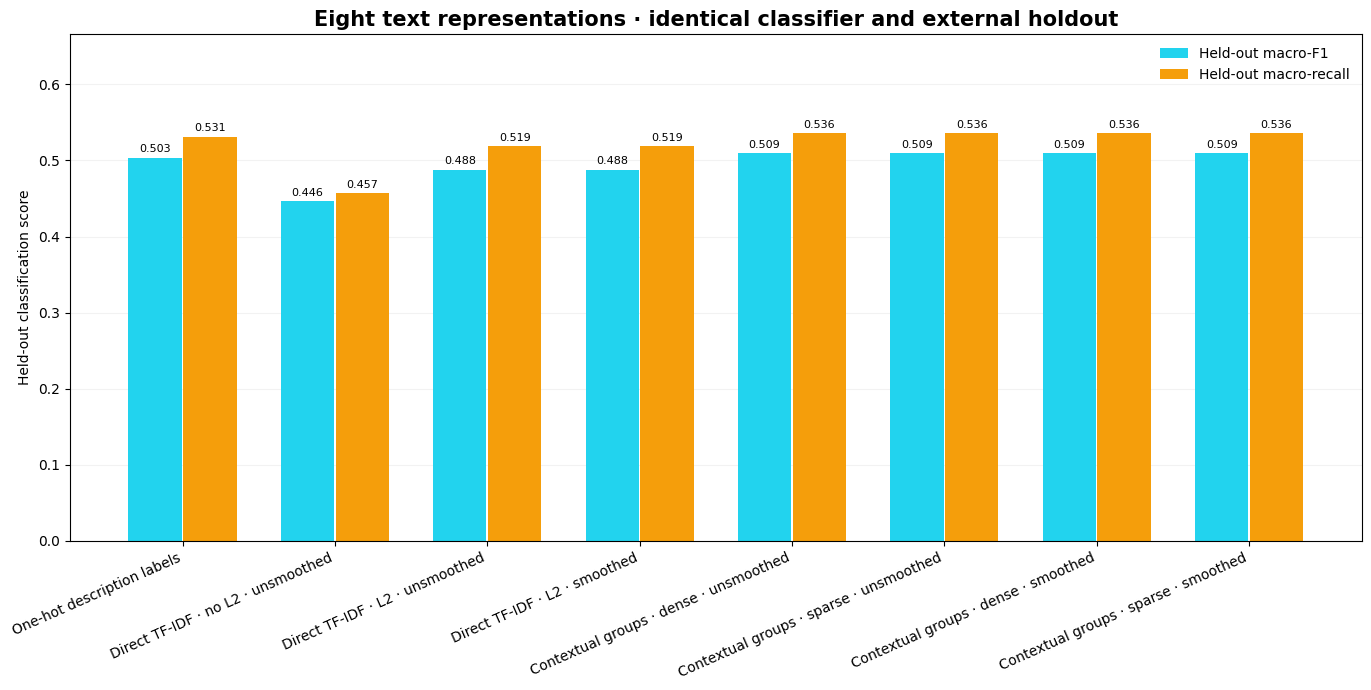

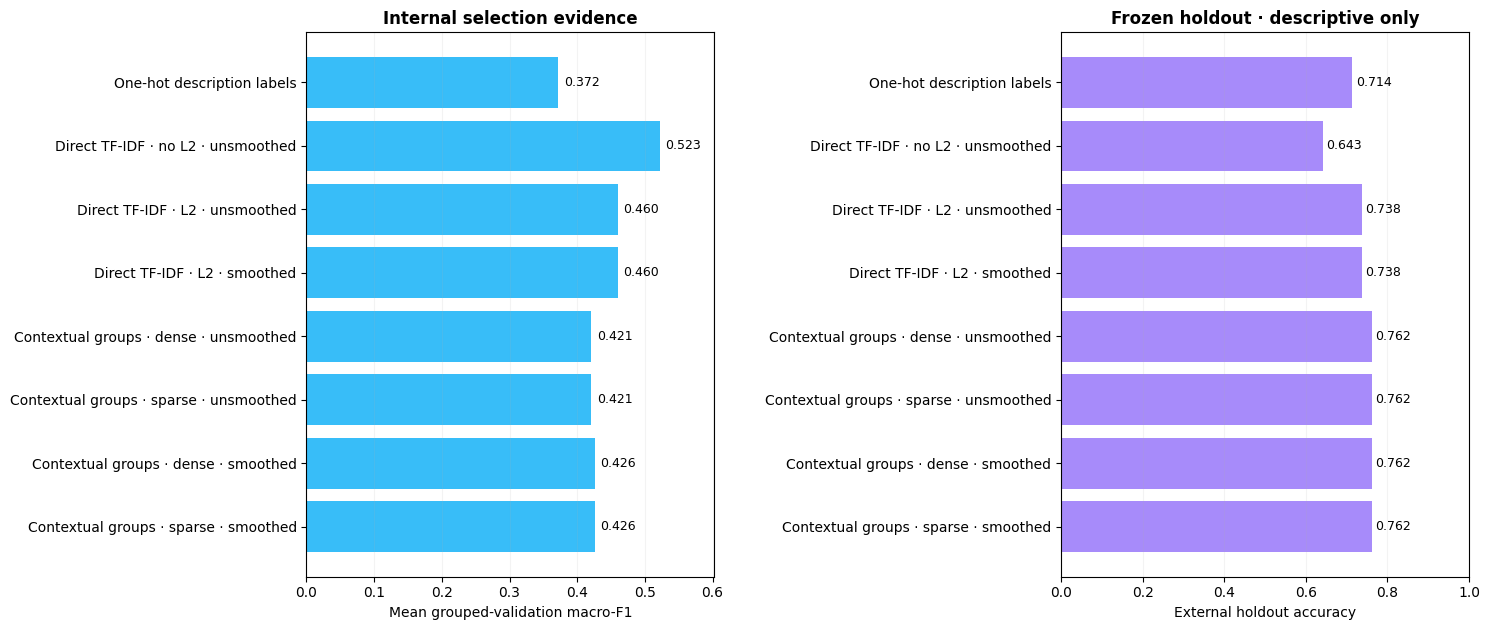

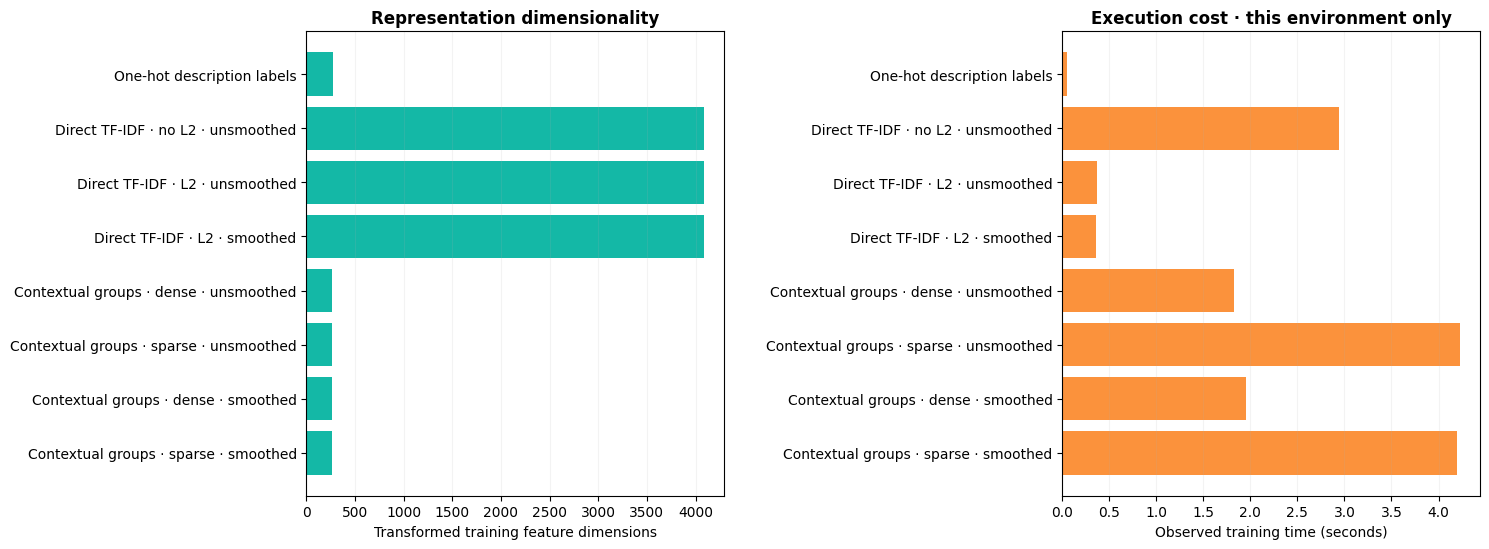

In [8]:
representation_plot_order = [configuration["representation_name"] for configuration in EVALUATED_OCCUPATIONAL_TEXT_REPRESENTATIONS]
internal_metric_plot_data = internal_representation_summary.set_index("representation_name").loc[representation_plot_order]
external_metric_plot_data = external_holdout_performance.set_index("representation_name").loc[representation_plot_order]
readable_representation_axis_labels = [representation_name.split(" · ", maxsplit=1)[-1] for representation_name in representation_plot_order]


heldout_metric_figure, heldout_metric_axis = plt.subplots(figsize=(14, 7.0))
representation_horizontal_positions = np.arange(len(representation_plot_order))

heldout_metric_axis.bar(representation_horizontal_positions - 0.18, external_metric_plot_data["macro_f1"], width=0.35, label="Held-out macro-F1", color="#22D3EE")
heldout_metric_axis.bar(representation_horizontal_positions + 0.18, external_metric_plot_data["macro_recall"], width=0.35, label="Held-out macro-recall", color="#F59E0B")
heldout_metric_axis.set_xticks(representation_horizontal_positions, readable_representation_axis_labels, rotation=24, ha="right")
heldout_metric_axis.set_ylim(0, max(0.55, float(external_metric_plot_data[["macro_f1", "macro_recall"]].max().max()) + 0.13))
heldout_metric_axis.set_ylabel("Held-out classification score")
heldout_metric_axis.set_title("Eight text representations · identical classifier and external holdout", weight="bold", fontsize=15)
heldout_metric_axis.grid(axis="y", alpha=0.16)
heldout_metric_axis.set_axisbelow(True)
heldout_metric_axis.legend(frameon=False)

for plotted_bar in heldout_metric_axis.patches:
    heldout_metric_axis.annotate(f"{plotted_bar.get_height():.3f}", (plotted_bar.get_x() + plotted_bar.get_width() / 2, plotted_bar.get_height()), xytext=(0, 4), textcoords="offset points", ha="center", fontsize=8)

heldout_metric_figure.tight_layout()
heldout_metric_figure.savefig(OUTPUT_DIRECTORY / "eight_representations_heldout_macro_metrics.png", dpi=180, bbox_inches="tight")
plt.show()


comparison_metric_figure, comparison_metric_axes = plt.subplots(1, 2, figsize=(15, 6.4))

comparison_metric_axes[0].barh(readable_representation_axis_labels[::-1], internal_metric_plot_data["internal_macro_f1_mean"].to_numpy()[::-1], color="#38BDF8")
comparison_metric_axes[0].set_xlabel("Mean grouped-validation macro-F1")
comparison_metric_axes[0].set_title("Internal selection evidence", weight="bold")
comparison_metric_axes[0].set_xlim(0, max(0.5, float(internal_metric_plot_data["internal_macro_f1_mean"].max()) + 0.08))
comparison_metric_axes[0].grid(axis="x", alpha=0.15)

comparison_metric_axes[1].barh(readable_representation_axis_labels[::-1], external_metric_plot_data["accuracy"].to_numpy()[::-1], color="#A78BFA")
comparison_metric_axes[1].set_xlabel("External holdout accuracy")
comparison_metric_axes[1].set_title("Frozen holdout · descriptive only", weight="bold")
comparison_metric_axes[1].set_xlim(0, 1)
comparison_metric_axes[1].grid(axis="x", alpha=0.15)

for comparison_metric_axis in comparison_metric_axes:
    for metric_bar in comparison_metric_axis.patches:
        comparison_metric_axis.text(metric_bar.get_width() + 0.008, metric_bar.get_y() + metric_bar.get_height() / 2, f"{metric_bar.get_width():.3f}", va="center", fontsize=9)

comparison_metric_figure.tight_layout(w_pad=3)
comparison_metric_figure.savefig(OUTPUT_DIRECTORY / "internal_validation_versus_external_holdout.png", dpi=180, bbox_inches="tight")
plt.show()


representation_cost_figure, representation_cost_axes = plt.subplots(1, 2, figsize=(15, 5.6))
representation_cost_axes[0].barh(readable_representation_axis_labels[::-1], external_metric_plot_data["total_transformed_input_features"].to_numpy()[::-1], color="#14B8A6")
representation_cost_axes[0].set_xlabel("Transformed training feature dimensions")
representation_cost_axes[0].set_title("Representation dimensionality", weight="bold")
representation_cost_axes[0].grid(axis="x", alpha=0.15)

representation_cost_axes[1].barh(readable_representation_axis_labels[::-1], external_metric_plot_data["training_elapsed_seconds"].to_numpy()[::-1], color="#FB923C")
representation_cost_axes[1].set_xlabel("Observed training time (seconds)")
representation_cost_axes[1].set_title("Execution cost · this environment only", weight="bold")
representation_cost_axes[1].grid(axis="x", alpha=0.15)

representation_cost_figure.tight_layout(w_pad=3)
representation_cost_figure.savefig(OUTPUT_DIRECTORY / "eight_representations_feature_dimensions_and_cost.png", dpi=180, bbox_inches="tight")
plt.show()

## Verified artifacts · Partial codes for mandatory human review

All source field audits, candidate scores, selected group counts, group memberships, internal evaluation partitions, holdout metrics and individual predictions are exported as reproducible CSV files.

After the evaluation is complete, the **internally selected** representation is refitted using the 191 complete labels to generate suggestions for nine partially labeled records. Those suggestions are **not** verified occupation codes and require human coder review.

### Methodological limitations and independent sources

- Original records are synthetic and manually labeled, with no independent ground-truth corrections.
- Source `ID` is a row number, not a verified persistent respondent identifier. No timestamp-based repetition control is possible.
- The chosen variance-balance score is a mathematical clustering diagnostic, not occupational-semantic validation. Singleton-dominant solutions remain a real failure mode.
- Unseen occupational labels in holdout and low-support classes limit macro metric stability.
- Production requires validated participant linkage, longitudinal splits, independent labels, human review, and drift monitoring.

**Official documentation:** [scikit-learn KMeans](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.KMeans.html), [Calinski–Harabasz score](https://scikit-learn.org/stable/modules/clustering.html#calinski-harabasz-index), [TF-IDF parameters](https://scikit-learn.org/stable/modules/generated/sklearn.feature_extraction.text.TfidfVectorizer.html), [GroupShuffleSplit](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GroupShuffleSplit.html), [common pitfalls and leakage](https://scikit-learn.org/stable/common_pitfalls.html).

In [9]:
source_column_audit.to_csv(OUTPUT_DIRECTORY / "all_18_source_fields_metadata_audit.csv", index=False, encoding="utf-8-sig")
source_validation_issues.to_csv(OUTPUT_DIRECTORY / "source_type_and_domain_validation_issues.csv", index=False, encoding="utf-8-sig")
internal_validation_performance.to_csv(OUTPUT_DIRECTORY / "eight_representations_grouped_internal_validation.csv", index=False, encoding="utf-8-sig")
internal_representation_summary.to_csv(OUTPUT_DIRECTORY / "eight_representations_validation_ranking.csv", index=False, encoding="utf-8-sig")
external_holdout_performance.to_csv(OUTPUT_DIRECTORY / "eight_representations_frozen_holdout_metrics.csv", index=False, encoding="utf-8-sig")
external_holdout_predictions.to_csv(OUTPUT_DIRECTORY / "every_holdout_prediction_for_eight_representations.csv", index=False, encoding="utf-8-sig")
contextual_grouping_candidate_evaluations.to_csv(OUTPUT_DIRECTORY / "every_contextual_group_count_variance_balance_score.csv", index=False, encoding="utf-8-sig")
optimal_grouping_summary_for_display.to_csv(OUTPUT_DIRECTORY / "optimal_number_of_contextual_groups_by_variance_balance.csv", index=False, encoding="utf-8-sig")
observed_optimal_contextual_group_memberships.to_csv(OUTPUT_DIRECTORY / "observed_contextual_group_description_memberships.csv", index=False, encoding="utf-8-sig")


selected_representation_configuration = next(configuration for configuration in EVALUATED_OCCUPATIONAL_TEXT_REPRESENTATIONS if configuration["representation_name"] == internally_selected_representation_name)
selected_full_labeled_model = build_training_only_occupation_classification_pipeline(selected_representation_configuration)
selected_full_labeled_model.fit(all_labeled_model_inputs, all_labeled_occupation_codes)

partially_labeled_model_inputs = prepare_occupation_model_features(partially_labeled_participant_records)
suggested_codes_for_human_review = selected_full_labeled_model.predict(partially_labeled_model_inputs)

human_review_proposals = pd.DataFrame({
    "participant_id": partially_labeled_participant_records["ID"].astype(int).to_numpy(),
    "original_partially_labeled_code": partially_labeled_participant_records[OCCUPATION_CLASSIFICATION_TARGET_COLUMN].astype(str).to_numpy(),
    "unverified_model_suggested_code": suggested_codes_for_human_review,
    "operational_status": "mandatory_human_coder_review",
})

assert len(human_review_proposals) == 9
human_review_proposals.to_csv(OUTPUT_DIRECTORY / "nine_partially_labeled_cases_for_human_review.csv", index=False, encoding="utf-8-sig")


example_unseen_description_inputs = external_holdout_model_inputs.iloc[:2].copy()

for occupational_text_column in OCCUPATIONAL_DESCRIPTION_COLUMNS:
    example_unseen_description_inputs[occupational_text_column] = f"previously_unseen_occupation_description_{occupational_text_column}"

for representation_configuration in EVALUATED_OCCUPATIONAL_TEXT_REPRESENTATIONS:
    verified_model = fully_trained_classification_pipelines[representation_configuration["representation_name"]]
    assert len(verified_model.predict(example_unseen_description_inputs)) == 2


selected_holdout_predictions = external_holdout_predicted_codes_by_representation[internally_selected_representation_name]
selected_model_per_class_report = classification_report(external_holdout_occupation_codes, selected_holdout_predictions, zero_division=0, output_dict=True)
selected_model_per_class_table = pd.DataFrame(selected_model_per_class_report).T.drop(index=["accuracy", "macro avg", "weighted avg"], errors="ignore")
selected_model_per_class_table.index.name = "occupation_code"
selected_model_per_class_table.to_csv(OUTPUT_DIRECTORY / "internally_selected_model_per_class_holdout_metrics.csv", encoding="utf-8-sig")


verified_experiment_manifest = {
    "source_workbook_sha256": actual_source_workbook_sha256,
    "python_version": platform.python_version(),
    "scikit_learn_version": sklearn.__version__,
    "participant_records": len(participant_survey_records),
    "metadata_verified_columns": len(source_column_audit),
    "labeled_training_records": len(training_model_inputs),
    "external_holdout_records": len(external_holdout_model_inputs),
    "partially_labeled_human_review_records": len(partially_labeled_model_inputs),
    "candidate_representations": len(EVALUATED_OCCUPATIONAL_TEXT_REPRESENTATIONS),
    "candidate_contextual_grouping_configurations": 4,
    "candidate_contextual_group_count_evaluations": len(contextual_grouping_candidate_evaluations),
    "candidate_contextual_group_count_invalid_evaluations": int(contextual_grouping_candidate_evaluations["evaluation_status"].ne("valid").sum()),
    "optimal_grouping_selection_rule": "maximum finite Calinski-Harabasz score among all training-only candidate group counts; ties select fewer contextual groups",
    "contextual_grouping_selection_warning": "The score typically selects nearly one group per distinct description; mathematical score optimization does not prove useful semantic grouping",
    "classifier_selection_rule": "maximum mean macro-F1 on three grouped internal validation partitions, with macro-recall and fixed complexity order breaking ties",
    "selected_representation_on_internal_validation": internally_selected_representation_name,
    "source_workbook_modified": False,
    "occupation_code_predictions_for_partial_labels_are_verified": False,
    "required_future_production_evidence": ["stable participant keys and version timestamps", "human-confirmed occupational coding labels", "time-aware and participant-grouped evaluation", "availability review for the final industry code", "semantic validation of contextual groups"],
}

(OUTPUT_DIRECTORY / "verified_experiment_manifest.json").write_text(json.dumps(verified_experiment_manifest, ensure_ascii=False, indent=2), encoding="utf-8")

print("All 18 source columns audited with declared metadata roles")
print("Eight representation pipelines evaluated on identical source and splits")
print("All contextual group-count scores exported without omitted candidates")
print("Nine partial occupation-code suggestions reserved for human review")
print("Original dataset is unchanged")
print("Internally selected classification representation:", internally_selected_representation_name)
display(human_review_proposals)

All 18 source columns audited with declared metadata roles
Eight representation pipelines evaluated on identical source and splits
All contextual group-count scores exported without omitted candidates
Nine partial occupation-code suggestions reserved for human review
Original dataset is unchanged
Internally selected classification representation: 02 · Direct TF-IDF · no L2 · unsmoothed


,participant_id,original_partially_labeled_code,unverified_model_suggested_code,operational_status
0,18,1XXX,2511,mandatory_human_coder_review
1,45,XXXX,2511,mandatory_human_coder_review
2,50,1XXX,2511,mandatory_human_coder_review
3,81,1XXX,2511,mandatory_human_coder_review
4,108,XXXX,2511,mandatory_human_coder_review
5,113,1XXX,2511,mandatory_human_coder_review
6,142,XXXX,2511,mandatory_human_coder_review
7,165,335X,3354,mandatory_human_coder_review
8,193,XXXX,3354,mandatory_human_coder_review


## Conclusion

**The classification system is a controlled prototype, not an approved production classifier.** Every source column has an explicit role, all eight representation variants use comparable evaluation conditions, and the contextual grouping findings are reported with their limitations. The presentation summarizes these same computed results without selecting models from external-holdout scores.

## V6 continuation · complete independent, column-by-column assessment

The nine V5 sections above remain unchanged, including their completed source-column audit, existing classifier training, held-out prediction sequence, and the original eight joint-feature representation comparisons. The following V6 sections are **additive**, not a replacement for those verified experiments.

The new comparison assesses **six text columns individually**, without combining their text features. Each column traverses **eight representations** and **ten group-disjoint, approximately class-stratified folds**. Each representation fits its text transformer only on the relevant fold training records. Contextual group counts are separately optimized by the Calinski–Harabasz between/within dispersion criterion using distinct training descriptions. Dense and sparse storage of scikit-learn `KMeans` are evaluated separately, as are IDF-smoothed and unsmoothed inputs.

Each transformed column is independently scored with **three distinct model families**: logistic regression, multinomial Naive Bayes, and random forest. Two explicit hyperparameter candidates are fitted for each family. Thirty-two three-model **soft-voting** combinations are evaluated from those trained classifiers' class probabilities with fixed weight candidates. Consequently, **all 38 candidates for every one of the 48 column–encoding paths** receive scores, not merely the leading candidate.

The primary metrics are **macro recall and macro F1**, with **accuracy** and **macro precision** also reported. Fold-wise results, pooled out-of-fold scores, individual predictions, every context-group candidate, and the separately assessed external holdout are retained. **No candidate is adopted automatically.**

Important limits: the 149 training records contain 52 occupation codes, including singleton classes, so some group-aware folds cannot contain every code in both their training and validation partitions. Macro metrics are therefore variable, and probabilistic calibration of the ensemble has **not** been verified. Per-path parameter rankings are descriptive comparisons on these same folds, not unbiased nested-CV estimates. External holdout results must not be used to tune parameters retrospectively.

### Reproducible 10-fold group-aware experiment, parameter candidates and probability voting

In [ ]:
from __future__ import annotations

import itertools
import json
import os
import platform
import time
import warnings

from collections import defaultdict
from pathlib import Path

import numpy as np
import pandas as pd
import sklearn

from scipy.sparse import issparse
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.naive_bayes import MultinomialNB
from sklearn.preprocessing import OneHotEncoder


OUTPUT_DIRECTORY_V6 = Path(os.environ.get('CBS_OCCUPATION_SUPPLEMENTAL_OUTPUT_DIRECTORY', 'occupational_classification_v6_outputs'))
OUTPUT_DIRECTORY_V6.mkdir(parents=True, exist_ok=True)

TEN_FOLD_STRATIFIED_PARTICIPANT_GROUP_VALIDATION = StratifiedGroupKFold(n_splits=10, shuffle=True, random_state=REPRODUCIBLE_RANDOM_STATE)

with warnings.catch_warnings(record=True) as cross_validation_setup_warnings:
    warnings.simplefilter('always')
    ten_fold_training_validation_positions = list(TEN_FOLD_STRATIFIED_PARTICIPANT_GROUP_VALIDATION.split(training_model_inputs, training_occupation_codes, training_description_groups))


EVALUATED_TEXT_ENCODING_PATHS = [
    {'path_name': 'description_labels_one_hot_encoding', 'representation_family': 'one_hot_encoding', 'tfidf_smoothing_enabled': None, 'l2_normalization_enabled': False, 'contextual_vector_storage_format': None},
    {'path_name': 'direct_tfidf_without_l2_and_without_idf_smoothing', 'representation_family': 'direct_tfidf', 'tfidf_smoothing_enabled': False, 'l2_normalization_enabled': False, 'contextual_vector_storage_format': None},
    {'path_name': 'direct_tfidf_with_l2_and_without_idf_smoothing', 'representation_family': 'direct_tfidf', 'tfidf_smoothing_enabled': False, 'l2_normalization_enabled': True, 'contextual_vector_storage_format': None},
    {'path_name': 'direct_tfidf_with_l2_and_with_idf_smoothing', 'representation_family': 'direct_tfidf', 'tfidf_smoothing_enabled': True, 'l2_normalization_enabled': True, 'contextual_vector_storage_format': None},
    {'path_name': 'contextual_grouping_dense_without_idf_smoothing', 'representation_family': 'contextual_grouping', 'tfidf_smoothing_enabled': False, 'l2_normalization_enabled': True, 'contextual_vector_storage_format': 'dense'},
    {'path_name': 'contextual_grouping_sparse_without_idf_smoothing', 'representation_family': 'contextual_grouping', 'tfidf_smoothing_enabled': False, 'l2_normalization_enabled': True, 'contextual_vector_storage_format': 'sparse'},
    {'path_name': 'contextual_grouping_dense_with_idf_smoothing', 'representation_family': 'contextual_grouping', 'tfidf_smoothing_enabled': True, 'l2_normalization_enabled': True, 'contextual_vector_storage_format': 'dense'},
    {'path_name': 'contextual_grouping_sparse_with_idf_smoothing', 'representation_family': 'contextual_grouping', 'tfidf_smoothing_enabled': True, 'l2_normalization_enabled': True, 'contextual_vector_storage_format': 'sparse'},
]


EVALUATED_CLASSIFIER_HYPERPARAMETERS = [
    {'model_name': 'logistic_regression', 'candidate_name': 'logistic_regression__regularization_strength_0p3', 'parameters': {'C': 0.3, 'class_weight': 'balanced', 'max_iter': 1000, 'solver': 'lbfgs'}},
    {'model_name': 'logistic_regression', 'candidate_name': 'logistic_regression__regularization_strength_3', 'parameters': {'C': 3.0, 'class_weight': 'balanced', 'max_iter': 1000, 'solver': 'lbfgs'}},
    {'model_name': 'multinomial_naive_bayes', 'candidate_name': 'multinomial_naive_bayes__additive_smoothing_0p3', 'parameters': {'alpha': 0.3}},
    {'model_name': 'multinomial_naive_bayes', 'candidate_name': 'multinomial_naive_bayes__additive_smoothing_1p3', 'parameters': {'alpha': 1.3}},
    {'model_name': 'random_forest', 'candidate_name': 'random_forest__minimum_leaf_records_1', 'parameters': {'n_estimators': 48, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'class_weight': 'balanced_subsample', 'n_jobs': 1}},
    {'model_name': 'random_forest', 'candidate_name': 'random_forest__minimum_leaf_records_3', 'parameters': {'n_estimators': 48, 'min_samples_leaf': 3, 'max_features': 'sqrt', 'class_weight': 'balanced_subsample', 'n_jobs': 1}},
]


EVALUATED_SOFT_VOTING_WEIGHT_COMBINATIONS = [
    {'weight_name': 'equal_probability_weights', 'weights': (1, 1, 1)},
    {'weight_name': 'double_logistic_regression_weight', 'weights': (2, 1, 1)},
    {'weight_name': 'double_naive_bayes_weight', 'weights': (1, 2, 1)},
    {'weight_name': 'double_random_forest_weight', 'weights': (1, 1, 2)},
]


SOURCE_DESCRIPTION_COLUMN_NAMES = tuple(OCCUPATIONAL_DESCRIPTION_COLUMNS)
VALIDATION_CLASSIFICATION_METRICS = ('macro_recall', 'macro_f1', 'accuracy', 'macro_precision')


for training_fold_positions, validation_fold_positions in ten_fold_training_validation_positions:
    assert set(training_description_groups.iloc[training_fold_positions]).isdisjoint(set(training_description_groups.iloc[validation_fold_positions]))

assert len(set(np.concatenate([validation_fold_positions for _, validation_fold_positions in ten_fold_training_validation_positions]))) == len(training_model_inputs)


CANDIDATES_BY_MODEL_TYPE = {
    model_type: [hyperparameters for hyperparameters in EVALUATED_CLASSIFIER_HYPERPARAMETERS if hyperparameters['model_name'] == model_type]
    for model_type in ('logistic_regression', 'multinomial_naive_bayes', 'random_forest')
}


def build_classification_model_for_explicit_hyperparameters(model_configuration):
    classifier_type_name = model_configuration['model_name']
    classifier_hyperparameters = dict(model_configuration['parameters'])

    if classifier_type_name == 'logistic_regression':
        return LogisticRegression(**classifier_hyperparameters, random_state=REPRODUCIBLE_RANDOM_STATE)

    if classifier_type_name == 'multinomial_naive_bayes':
        return MultinomialNB(**classifier_hyperparameters)

    if classifier_type_name == 'random_forest':
        return RandomForestClassifier(**classifier_hyperparameters, random_state=REPRODUCIBLE_RANDOM_STATE)

    raise ValueError(f'Unknown supervised model type: {classifier_type_name}')


def transform_single_description_column_using_training_only_fits(occupational_description_column, encoding_configuration, training_descriptions, prediction_descriptions):
    column_training_values = training_descriptions[[occupational_description_column]]
    column_prediction_values = prediction_descriptions[[occupational_description_column]]
    representation_family = encoding_configuration['representation_family']
    evaluated_contextual_group_count_candidates = []
    selected_contextual_group_count = np.nan

    if representation_family == 'one_hot_encoding':
        fitted_text_representation = OneHotEncoder(handle_unknown='ignore')
        transformed_training_descriptions = fitted_text_representation.fit_transform(column_training_values)
        transformed_prediction_descriptions = fitted_text_representation.transform(column_prediction_values)

    elif representation_family == 'direct_tfidf':
        fitted_text_representation = EmptySafeOccupationalTfidfEncoding(l2_normalization_enabled=encoding_configuration['l2_normalization_enabled'], tfidf_smoothing_enabled=encoding_configuration['tfidf_smoothing_enabled'])
        transformed_training_descriptions = fitted_text_representation.fit_transform(column_training_values)
        transformed_prediction_descriptions = fitted_text_representation.transform(column_prediction_values)

    elif representation_family == 'contextual_grouping':
        fitted_contextual_grouping = TrainingOnlyVarianceBalancedContextualGrouping(occupational_description_columns=(occupational_description_column,), tfidf_smoothing_enabled=encoding_configuration['tfidf_smoothing_enabled'], vector_storage_format=encoding_configuration['contextual_vector_storage_format'])
        fitted_contextual_grouping.fit(column_training_values)
        evaluated_contextual_group_count_candidates = fitted_contextual_grouping.candidate_variance_balance_evaluations_
        selected_contextual_group_count = fitted_contextual_grouping.optimal_contextual_grouping_configurations_[0]['optimal_number_of_contextual_groups']

        fitted_nominal_group_encoder = OneHotEncoder(handle_unknown='ignore')
        transformed_training_descriptions = fitted_nominal_group_encoder.fit_transform(fitted_contextual_grouping.transform(column_training_values))
        transformed_prediction_descriptions = fitted_nominal_group_encoder.transform(fitted_contextual_grouping.transform(column_prediction_values))

    else:
        raise ValueError(f'Unknown text representation: {representation_family}')

    return transformed_training_descriptions, transformed_prediction_descriptions, evaluated_contextual_group_count_candidates, selected_contextual_group_count


def calculate_full_classification_metrics(actual_codes, predicted_codes):
    return {
        'macro_recall': float(recall_score(actual_codes, predicted_codes, average='macro', zero_division=0)),
        'macro_f1': float(f1_score(actual_codes, predicted_codes, average='macro', zero_division=0)),
        'accuracy': float(accuracy_score(actual_codes, predicted_codes)),
        'macro_precision': float(precision_score(actual_codes, predicted_codes, average='macro', zero_division=0)),
    }


def compose_every_hyperparameter_path_from_prediction_probabilities(predicted_probabilities_by_model_candidate, observed_training_classes):
    for classifier_configuration in EVALUATED_CLASSIFIER_HYPERPARAMETERS:
        classifier_candidate_name = classifier_configuration['candidate_name']
        predicted_class_probabilities = predicted_probabilities_by_model_candidate[classifier_candidate_name]
        predicted_class_labels = observed_training_classes[np.argmax(predicted_class_probabilities, axis=1)]

        yield {
            'candidate_name': classifier_candidate_name,
            'model_name': classifier_configuration['model_name'],
            'hyperparameters': json.dumps(classifier_configuration['parameters'], sort_keys=True),
            'soft_voting_weights': None,
            'predicted_codes': predicted_class_labels,
        }

    for logistic_configuration, naive_bayes_configuration, random_forest_configuration in itertools.product(CANDIDATES_BY_MODEL_TYPE['logistic_regression'], CANDIDATES_BY_MODEL_TYPE['multinomial_naive_bayes'], CANDIDATES_BY_MODEL_TYPE['random_forest']):
        member_model_configurations = [logistic_configuration, naive_bayes_configuration, random_forest_configuration]
        member_candidate_names = tuple(member_configuration['candidate_name'] for member_configuration in member_model_configurations)
        member_probability_matrices = [predicted_probabilities_by_model_candidate[member_candidate_name] for member_candidate_name in member_candidate_names]

        for ensemble_weight_configuration in EVALUATED_SOFT_VOTING_WEIGHT_COMBINATIONS:
            normalized_probability_weights = np.asarray(ensemble_weight_configuration['weights'], dtype=float)
            soft_voting_probabilities = sum(member_probability * corresponding_weight for member_probability, corresponding_weight in zip(member_probability_matrices, normalized_probability_weights)) / np.sum(normalized_probability_weights)
            predicted_class_labels = observed_training_classes[np.argmax(soft_voting_probabilities, axis=1)]

            yield {
                'candidate_name': 'soft_voting__' + '__'.join(member_candidate_names) + '__' + ensemble_weight_configuration['weight_name'],
                'model_name': 'soft_voting_three_distinct_model_types',
                'hyperparameters': json.dumps({'member_models': member_candidate_names}, sort_keys=True),
                'soft_voting_weights': ensemble_weight_configuration['weight_name'],
                'predicted_codes': predicted_class_labels,
            }


def fit_every_model_on_single_transformed_training_partition(transformed_training_descriptions, actual_training_codes, transformed_prediction_descriptions):
    probabilities_by_model = {}
    fitted_class_order = None

    for classifier_configuration in EVALUATED_CLASSIFIER_HYPERPARAMETERS:
        classification_model = build_classification_model_for_explicit_hyperparameters(classifier_configuration)
        classification_model.fit(transformed_training_descriptions, actual_training_codes)
        candidate_class_order = np.asarray(classification_model.classes_)

        if fitted_class_order is None:
            fitted_class_order = candidate_class_order
        else:
            np.testing.assert_array_equal(fitted_class_order, candidate_class_order)

        probabilities_by_model[classifier_configuration['candidate_name']] = classification_model.predict_proba(transformed_prediction_descriptions)

    return probabilities_by_model, fitted_class_order




### Every fold, every column, every encoding, every individual model and every soft-voting combination

In [ ]:
validated_fold_metric_records = []
validated_fold_prediction_records = []
training_only_contextual_grouping_candidate_records = []
fold_transformation_audit_records = []
external_holdout_metric_records = []
external_holdout_prediction_records = []
all_candidate_out_of_fold_predictions = {}


for occupational_description_column in SOURCE_DESCRIPTION_COLUMN_NAMES:
    for encoding_configuration in EVALUATED_TEXT_ENCODING_PATHS:
        representation_path_name = encoding_configuration['path_name']
        complete_candidate_prediction_vectors = defaultdict(lambda: np.full(len(training_model_inputs), '', dtype=object))
        candidate_descriptive_metadata = {}
        representation_start_time = time.monotonic()

        for validation_fold_number, (training_fold_positions, validation_fold_positions) in enumerate(ten_fold_training_validation_positions, start=1):
            fold_training_inputs = training_model_inputs.iloc[training_fold_positions]
            fold_validation_inputs = training_model_inputs.iloc[validation_fold_positions]
            fold_training_codes = training_occupation_codes.iloc[training_fold_positions].to_numpy()
            fold_validation_codes = training_occupation_codes.iloc[validation_fold_positions].to_numpy()
            fold_validation_participant_ids = completely_labeled_participant_records.iloc[training_row_positions].iloc[validation_fold_positions]['ID'].to_numpy()

            fold_training_vectors, fold_validation_vectors, contextual_grouping_candidate_records, optimal_number_of_contextual_groups = transform_single_description_column_using_training_only_fits(occupational_description_column, encoding_configuration, fold_training_inputs, fold_validation_inputs)

            fold_transformation_audit_records.append({
                'occupational_text_column': occupational_description_column,
                'representation_path': representation_path_name,
                'fold_number': validation_fold_number,
                'number_of_training_records': len(training_fold_positions),
                'number_of_validation_records': len(validation_fold_positions),
                'number_of_training_target_classes': len(set(fold_training_codes)),
                'number_of_validation_target_classes_unseen_in_fold_training': len(set(fold_validation_codes) - set(fold_training_codes)),
                'number_of_unseen_label_validation_records': sum(code not in set(fold_training_codes) for code in fold_validation_codes),
                'number_of_transformed_features': fold_training_vectors.shape[1],
                'optimal_number_of_contextual_groups': optimal_number_of_contextual_groups,
                'observed_sparse_training_matrix': bool(issparse(fold_training_vectors)),
                'source_description_column_count': 1,
            })

            for variance_balance_candidate_record in contextual_grouping_candidate_records:
                training_only_contextual_grouping_candidate_records.append({
                    'representation_path': representation_path_name,
                    'fold_number': validation_fold_number,
                    **variance_balance_candidate_record,
                })

            fold_probabilities_by_model, fold_training_class_order = fit_every_model_on_single_transformed_training_partition(fold_training_vectors, fold_training_codes, fold_validation_vectors)

            for candidate_prediction_record in compose_every_hyperparameter_path_from_prediction_probabilities(fold_probabilities_by_model, fold_training_class_order):
                classifier_candidate_name = candidate_prediction_record['candidate_name']
                predicted_validation_codes = candidate_prediction_record['predicted_codes']
                candidate_descriptive_metadata[classifier_candidate_name] = candidate_prediction_record
                complete_candidate_prediction_vectors[classifier_candidate_name][validation_fold_positions] = predicted_validation_codes

                candidate_metric_record = {
                    'occupational_text_column': occupational_description_column,
                    'representation_path': representation_path_name,
                    'fold_number': validation_fold_number,
                    'classifier_candidate_name': classifier_candidate_name,
                    'model_name': candidate_prediction_record['model_name'],
                    'hyperparameters': candidate_prediction_record['hyperparameters'],
                    'soft_voting_weights': candidate_prediction_record['soft_voting_weights'],
                    'number_of_training_records': len(training_fold_positions),
                    'number_of_validation_records': len(validation_fold_positions),
                    'unseen_label_validation_records': sum(code not in set(fold_training_codes) for code in fold_validation_codes),
                }

                candidate_metric_record.update(calculate_full_classification_metrics(fold_validation_codes, predicted_validation_codes))
                validated_fold_metric_records.append(candidate_metric_record)

                for participant_id, actual_code, predicted_code in zip(fold_validation_participant_ids, fold_validation_codes, predicted_validation_codes):
                    validated_fold_prediction_records.append({
                        'occupational_text_column': occupational_description_column,
                        'representation_path': representation_path_name,
                        'classifier_candidate_name': classifier_candidate_name,
                        'fold_number': validation_fold_number,
                        'participant_id': int(participant_id),
                        'actual_occupation_code': actual_code,
                        'predicted_occupation_code': predicted_code,
                    })

        for classifier_candidate_name, candidate_prediction_vector in complete_candidate_prediction_vectors.items():
            assert np.all(candidate_prediction_vector != '')
            candidate_metadata = candidate_descriptive_metadata[classifier_candidate_name]
            pooled_ten_fold_candidate_metrics = {
                'occupational_text_column': occupational_description_column,
                'representation_path': representation_path_name,
                'classifier_candidate_name': classifier_candidate_name,
                'model_name': candidate_metadata['model_name'],
                'hyperparameters': candidate_metadata['hyperparameters'],
                'soft_voting_weights': candidate_metadata['soft_voting_weights'],
                'number_of_out_of_fold_records': len(candidate_prediction_vector),
                'number_of_completed_validation_folds': len(ten_fold_training_validation_positions),
            }

            pooled_ten_fold_candidate_metrics.update(calculate_full_classification_metrics(training_occupation_codes.to_numpy(), candidate_prediction_vector))
            all_candidate_out_of_fold_predictions[(occupational_description_column, representation_path_name, classifier_candidate_name)] = pooled_ten_fold_candidate_metrics

        complete_training_vectors, external_holdout_vectors, all_training_contextual_candidates, full_training_optimal_number_of_contextual_groups = transform_single_description_column_using_training_only_fits(occupational_description_column, encoding_configuration, training_model_inputs, external_holdout_model_inputs)

        for variance_balance_candidate_record in all_training_contextual_candidates:
            training_only_contextual_grouping_candidate_records.append({'representation_path': representation_path_name, 'fold_number': 0, **variance_balance_candidate_record})

        holdout_probabilities_by_model, full_training_class_order = fit_every_model_on_single_transformed_training_partition(complete_training_vectors, training_occupation_codes.to_numpy(), external_holdout_vectors)

        for candidate_prediction_record in compose_every_hyperparameter_path_from_prediction_probabilities(holdout_probabilities_by_model, full_training_class_order):
            classifier_candidate_name = candidate_prediction_record['candidate_name']
            holdout_prediction = candidate_prediction_record['predicted_codes']

            candidate_holdout_metric_record = {
                'occupational_text_column': occupational_description_column,
                'representation_path': representation_path_name,
                'classifier_candidate_name': classifier_candidate_name,
                'model_name': candidate_prediction_record['model_name'],
                'hyperparameters': candidate_prediction_record['hyperparameters'],
                'soft_voting_weights': candidate_prediction_record['soft_voting_weights'],
                'number_of_holdout_records': len(external_holdout_model_inputs),
                'external_holdout_used_for_model_selection': False,
            }

            candidate_holdout_metric_record.update(calculate_full_classification_metrics(external_holdout_occupation_codes.to_numpy(), holdout_prediction))
            external_holdout_metric_records.append(candidate_holdout_metric_record)

            for participant_id, actual_code, predicted_code in zip(completely_labeled_participant_records.iloc[external_holdout_row_positions]['ID'], external_holdout_occupation_codes, holdout_prediction):
                external_holdout_prediction_records.append({
                    'occupational_text_column': occupational_description_column,
                    'representation_path': representation_path_name,
                    'classifier_candidate_name': classifier_candidate_name,
                    'participant_id': int(participant_id),
                    'actual_occupation_code': actual_code,
                    'predicted_occupation_code': predicted_code,
                })

        print('Evaluated', occupational_description_column, representation_path_name, 'folds', len(ten_fold_training_validation_positions), 'candidate_paths', len(complete_candidate_prediction_vectors), 'seconds', round(time.monotonic() - representation_start_time, 1), flush=True)




### Preserve all candidate score records, held-out predictions, and source validation evidence

In [ ]:
pooled_ten_fold_candidate_scores = pd.DataFrame(all_candidate_out_of_fold_predictions.values())
ten_fold_candidate_scores = pd.DataFrame(validated_fold_metric_records)
ten_fold_candidate_predictions = pd.DataFrame(validated_fold_prediction_records)
external_holdout_candidate_scores = pd.DataFrame(external_holdout_metric_records)
external_holdout_candidate_predictions = pd.DataFrame(external_holdout_prediction_records)
fold_preprocessing_audit = pd.DataFrame(fold_transformation_audit_records)
variance_balance_candidate_scores = pd.DataFrame(training_only_contextual_grouping_candidate_records)


mean_fold_metrics_by_candidate = ten_fold_candidate_scores.groupby(['occupational_text_column', 'representation_path', 'classifier_candidate_name'], as_index=False).agg(mean_fold_macro_recall=('macro_recall', 'mean'), mean_fold_macro_f1=('macro_f1', 'mean'), mean_fold_accuracy=('accuracy', 'mean'), std_fold_macro_f1=('macro_f1', 'std'), mean_fold_macro_precision=('macro_precision', 'mean'))

pooled_ten_fold_candidate_scores = pooled_ten_fold_candidate_scores.merge(mean_fold_metrics_by_candidate, on=['occupational_text_column', 'representation_path', 'classifier_candidate_name'], validate='one_to_one')
pooled_ten_fold_candidate_scores = pooled_ten_fold_candidate_scores.sort_values(['occupational_text_column', 'representation_path', 'macro_f1', 'macro_recall', 'accuracy'], ascending=[True, True, False, False, False]).reset_index(drop=True)


score_summary_file = OUTPUT_DIRECTORY_V6 / 'all_text_columns_all_encoding_paths_all_classifiers_all_hyperparameters_ten_fold_scores.csv'
fold_score_file = OUTPUT_DIRECTORY_V6 / 'every_individual_group_aware_validation_fold_score.csv'
validation_prediction_file = OUTPUT_DIRECTORY_V6 / 'every_ten_fold_validation_prediction_for_every_candidate.csv.gz'
holdout_score_file = OUTPUT_DIRECTORY_V6 / 'every_classifier_and_ensemble_external_holdout_score.csv'
holdout_prediction_file = OUTPUT_DIRECTORY_V6 / 'every_external_holdout_prediction_for_every_candidate.csv.gz'
contextual_candidate_file = OUTPUT_DIRECTORY_V6 / 'every_training_only_contextual_group_count_variance_balance_score.csv'
preprocessing_audit_file = OUTPUT_DIRECTORY_V6 / 'every_fold_single_column_transformation_audit.csv'


pooled_ten_fold_candidate_scores.to_csv(score_summary_file, index=False, encoding='utf-8-sig')
ten_fold_candidate_scores.to_csv(fold_score_file, index=False, encoding='utf-8-sig')
ten_fold_candidate_predictions.to_csv(validation_prediction_file, index=False, compression='gzip')
external_holdout_candidate_scores.to_csv(holdout_score_file, index=False, encoding='utf-8-sig')
external_holdout_candidate_predictions.to_csv(holdout_prediction_file, index=False, compression='gzip')
variance_balance_candidate_scores.to_csv(contextual_candidate_file, index=False, encoding='utf-8-sig')
fold_preprocessing_audit.to_csv(preprocessing_audit_file, index=False, encoding='utf-8-sig')


source_columns_by_group_number = {field_name: field_position for field_position, field_name in enumerate(SOURCE_DESCRIPTION_COLUMN_NAMES)}
encoding_paths_by_position = {path_configuration['path_name']: path_position for path_position, path_configuration in enumerate(EVALUATED_TEXT_ENCODING_PATHS)}


model_family_optimized_scores = (pooled_ten_fold_candidate_scores.sort_values(['macro_f1', 'macro_recall', 'accuracy'], ascending=[False, False, False]).groupby(['occupational_text_column', 'representation_path', 'model_name'], as_index=False).first())
model_family_optimized_scores.to_csv(OUTPUT_DIRECTORY_V6 / 'highest_scoring_tested_hyperparameter_per_model_type_for_each_path.csv', index=False, encoding='utf-8-sig')

all_candidate_comparison = pooled_ten_fold_candidate_scores.merge(external_holdout_candidate_scores[['occupational_text_column', 'representation_path', 'classifier_candidate_name', 'macro_recall', 'macro_f1', 'accuracy']].rename(columns={'macro_recall': 'holdout_macro_recall', 'macro_f1': 'holdout_macro_f1', 'accuracy': 'holdout_accuracy'}), on=['occupational_text_column', 'representation_path', 'classifier_candidate_name'], validate='one_to_one')
all_candidate_comparison.to_csv(OUTPUT_DIRECTORY_V6 / 'complete_validation_and_holdout_candidate_comparison.csv', index=False, encoding='utf-8-sig')


full_experiment_manifest = {
    'original_workbook_sha256': actual_source_workbook_sha256,
    'scikit_learn_version': sklearn.__version__,
    'python_version': platform.python_version(),
    'number_of_complete_label_records': int(len(all_labeled_model_inputs)),
    'number_of_training_records': int(len(training_model_inputs)),
    'number_of_external_holdout_records': int(len(external_holdout_model_inputs)),
    'number_of_training_target_classes': int(training_occupation_codes.nunique()),
    'number_of_external_holdout_records_with_occupation_codes_unseen_in_training': int((~external_holdout_occupation_codes.isin(set(training_occupation_codes))).sum()),
    'number_of_cross_validation_folds': len(ten_fold_training_validation_positions),
    'number_of_occupational_text_columns': len(SOURCE_DESCRIPTION_COLUMN_NAMES),
    'occupational_text_columns': SOURCE_DESCRIPTION_COLUMN_NAMES,
    'number_of_encoding_paths_per_column': len(EVALUATED_TEXT_ENCODING_PATHS),
    'number_of_base_classifier_hyperparameter_candidates_per_encoding': len(EVALUATED_CLASSIFIER_HYPERPARAMETERS),
    'number_of_soft_voting_ensembles_per_encoding': int(len(CANDIDATES_BY_MODEL_TYPE['logistic_regression']) * len(CANDIDATES_BY_MODEL_TYPE['multinomial_naive_bayes']) * len(CANDIDATES_BY_MODEL_TYPE['random_forest']) * len(EVALUATED_SOFT_VOTING_WEIGHT_COMBINATIONS)),
    'number_of_distinct_score_candidates': len(pooled_ten_fold_candidate_scores),
    'number_of_fold_score_records': len(ten_fold_candidate_scores),
    'number_of_cross_validation_predictions': len(ten_fold_candidate_predictions),
    'number_of_external_holdout_score_records': len(external_holdout_candidate_scores),
    'number_of_external_holdout_predictions': len(external_holdout_candidate_predictions),
    'number_of_training_only_contextual_grouping_candidate_evaluations': len(variance_balance_candidate_scores),
    'number_of_invalid_contextual_grouping_candidates': int(variance_balance_candidate_scores['evaluation_status'].ne('valid').sum()),
    'number_of_evaluated_source_text_columns_per_model': 1,
    'holdout_used_for_selection': False,
    'soft_voting_probability_calibration_verified': False,
    'macro_recall_and_macro_f1_are_priority_metrics': True,
    'ranked_candidate_does_not_mean_model_adopted': True,
    'folding_warnings': [str(warning.message) for warning in cross_validation_setup_warnings],
}


(OUTPUT_DIRECTORY_V6 / 'complete_experiment_manifest.json').write_text(json.dumps(full_experiment_manifest, ensure_ascii=False, indent=2), encoding='utf-8')


print('Completed:', json.dumps(full_experiment_manifest, ensure_ascii=False), flush=True)
print('Highest pooled ten-fold macro-F1 candidate (observed only, not adopted):', pooled_ten_fold_candidate_scores[['occupational_text_column', 'representation_path', 'model_name', 'macro_recall', 'macro_f1', 'accuracy']].sort_values(['macro_f1', 'macro_recall'], ascending=False).head(5).to_string(index=False), flush=True)


## Complete V6 experiment results · numerical observations

**Source verification:** SHA-256 `e1e7f391c0675dd14830eaae6b5cd114edc256f18b956bb48a454b0b1209e1ac`; 200 participant records; 191 complete occupation codes; 149 training records; 42 held-out records; 9 partial codes retained for human review.

**Actual measurements:** 10 complete group-disjoint folds × 6 independent text columns × 8 representations × 38 classifier or ensemble candidates = **18240 separately scored fold outcomes**, including **1824 pooled candidate comparisons**. Additional individual predictions and the four contextual-grouping variance-balance sweeps are preserved.

**Leading observed candidate in each column** (macro-F1 ordering of the tested candidates; **not an adopted model**):

| occupational_text_column   | representation_path                               | model_name                             |   macro_recall |   macro_f1 |   accuracy |
|:---------------------------|:--------------------------------------------------|:---------------------------------------|---------------:|-----------:|-----------:|
| EzoAvoda                   | contextual_grouping_dense_with_idf_smoothing      | soft_voting_three_distinct_model_types |         0.4155 |     0.385  |     0.6309 |
| SugAvoda                   | direct_tfidf_with_l2_and_with_idf_smoothing       | soft_voting_three_distinct_model_types |         0.2583 |     0.2601 |     0.4027 |
| ShemMachlaka               | direct_tfidf_without_l2_and_without_idf_smoothing | random_forest                          |         0.2006 |     0.195  |     0.2953 |
| SugMachlaka                | direct_tfidf_without_l2_and_without_idf_smoothing | logistic_regression                    |         0.1218 |     0.1171 |     0.1342 |
| TeurPeula                  | direct_tfidf_without_l2_and_without_idf_smoothing | logistic_regression                    |         0.0689 |     0.0581 |     0.094  |
| TeurTafkid                 | description_labels_one_hot_encoding               | logistic_regression                    |         0.0705 |     0.0429 |     0.1074 |

All candidate scores, including the lowest-scoring paths, are available in `occupational_classification_v6_outputs/all_text_columns_all_encoding_paths_all_classifiers_all_hyperparameters_ten_fold_scores.csv`. Fold-level scores, predicted codes, comparison with the external holdout, and the contextual-grouping optimizer trials are stored beside that file and regenerated when the notebook runs.

**Interpretation:** Macro recall and macro F1 are the main classification comparisons. Accuracy remains visible. Differences across the score tables are descriptive on this synthetic, small and highly imbalanced training partition. Contextual variance-balance optimization sometimes produces almost one group per distinct description. This does not establish useful semantic consolidation. Three-model probability averaging is a soft-voting experiment, not evidence of calibrated predictive probabilities. The original V5 classifier, its separate holdout, and its nine human-review suggestions remain intact above.

### Macro recall across all 48 independently assessed representation paths

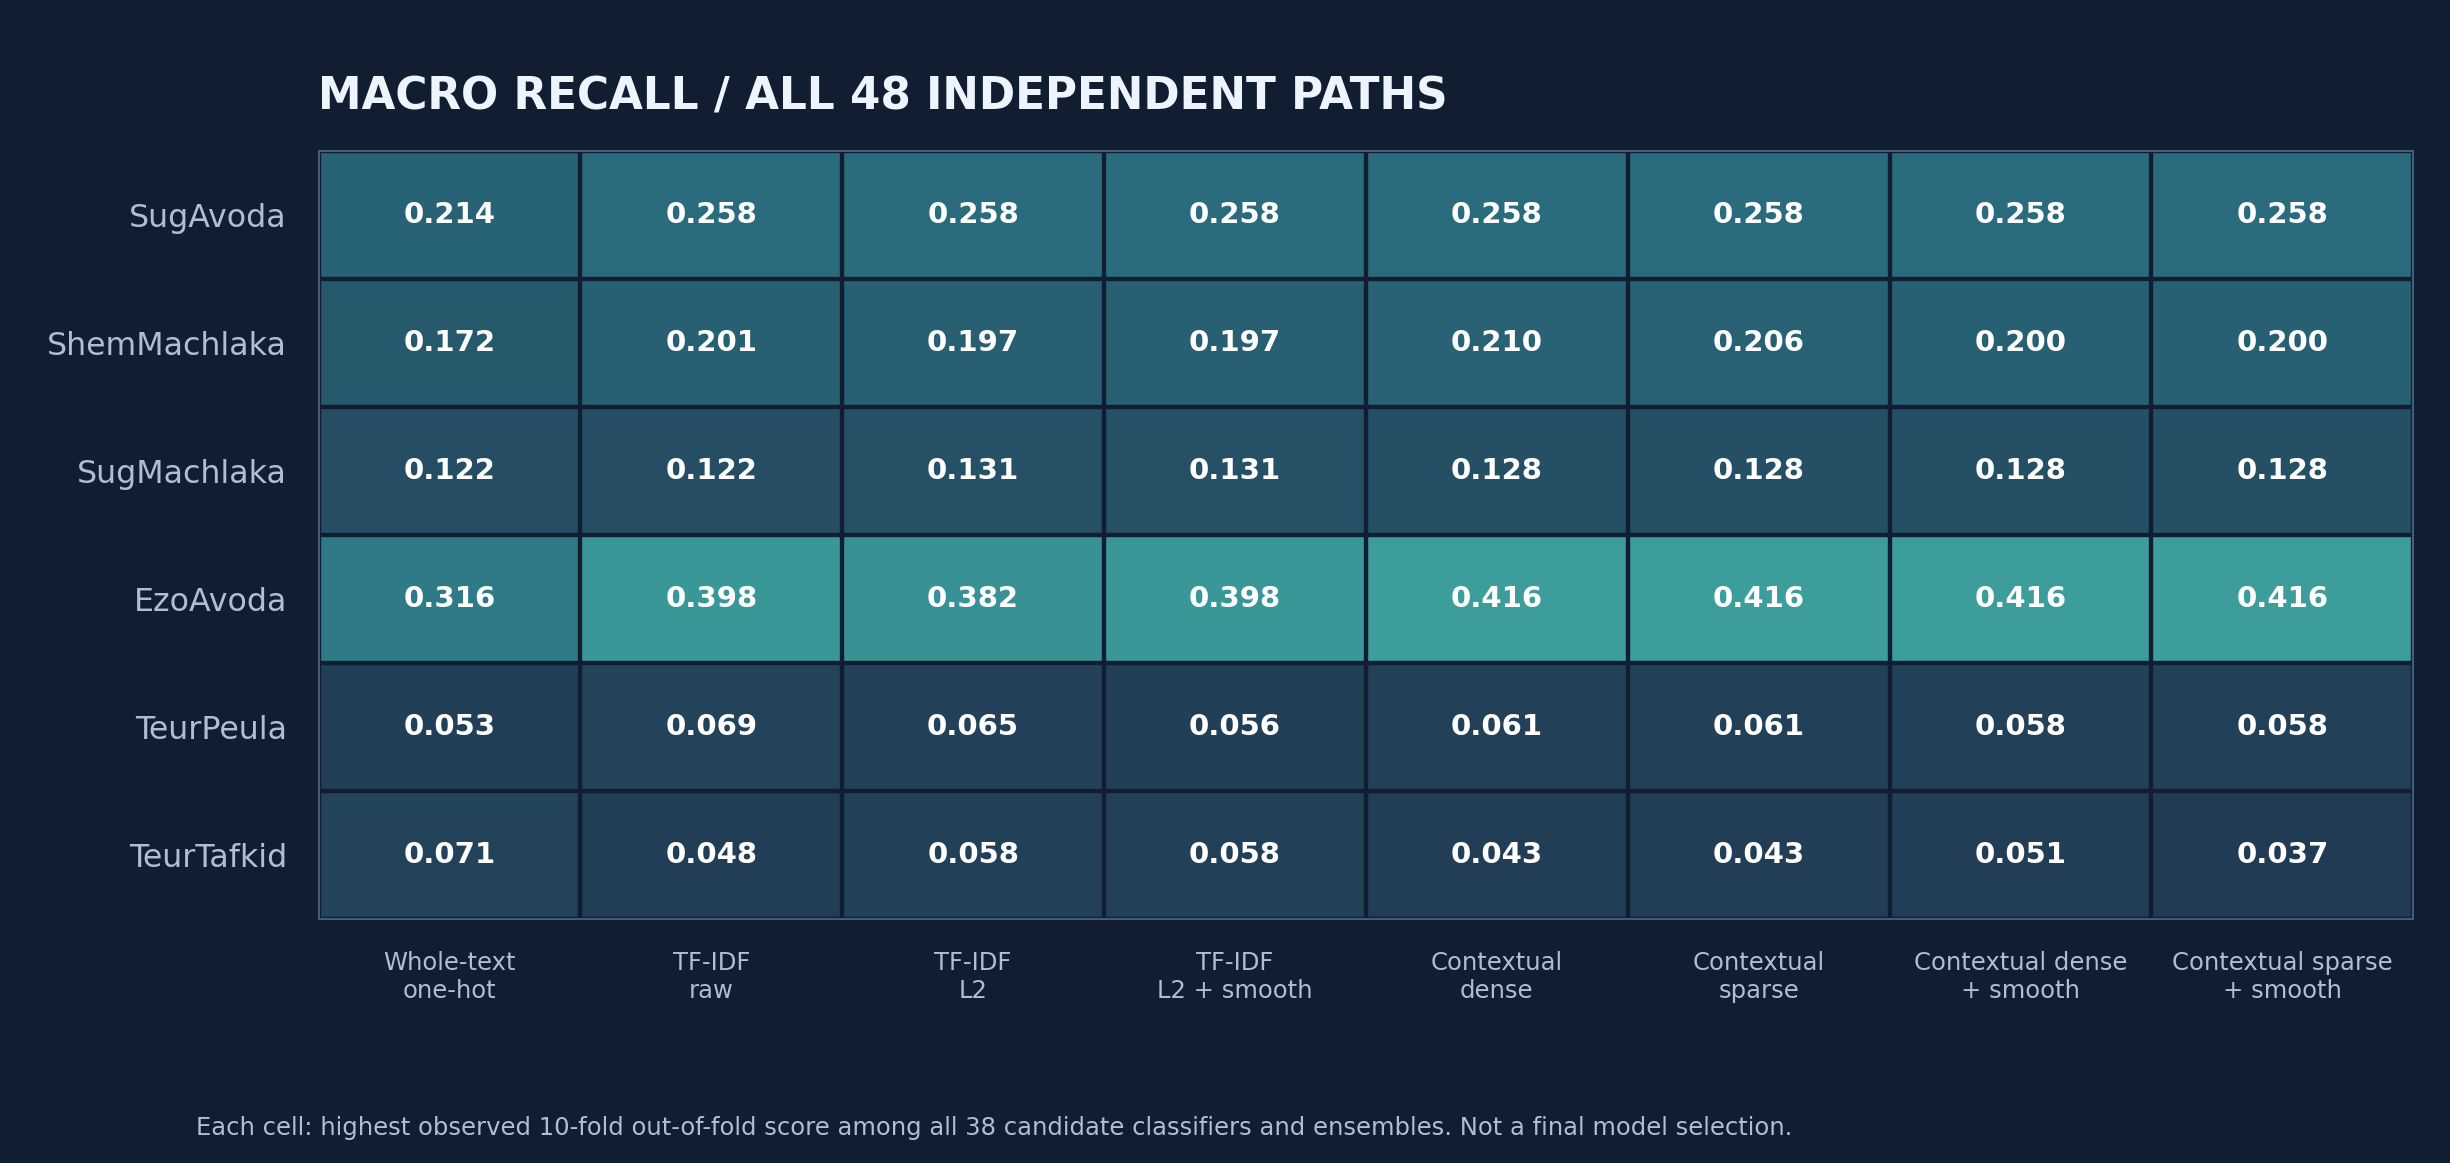

### Macro F1 across all 48 independently assessed representation paths

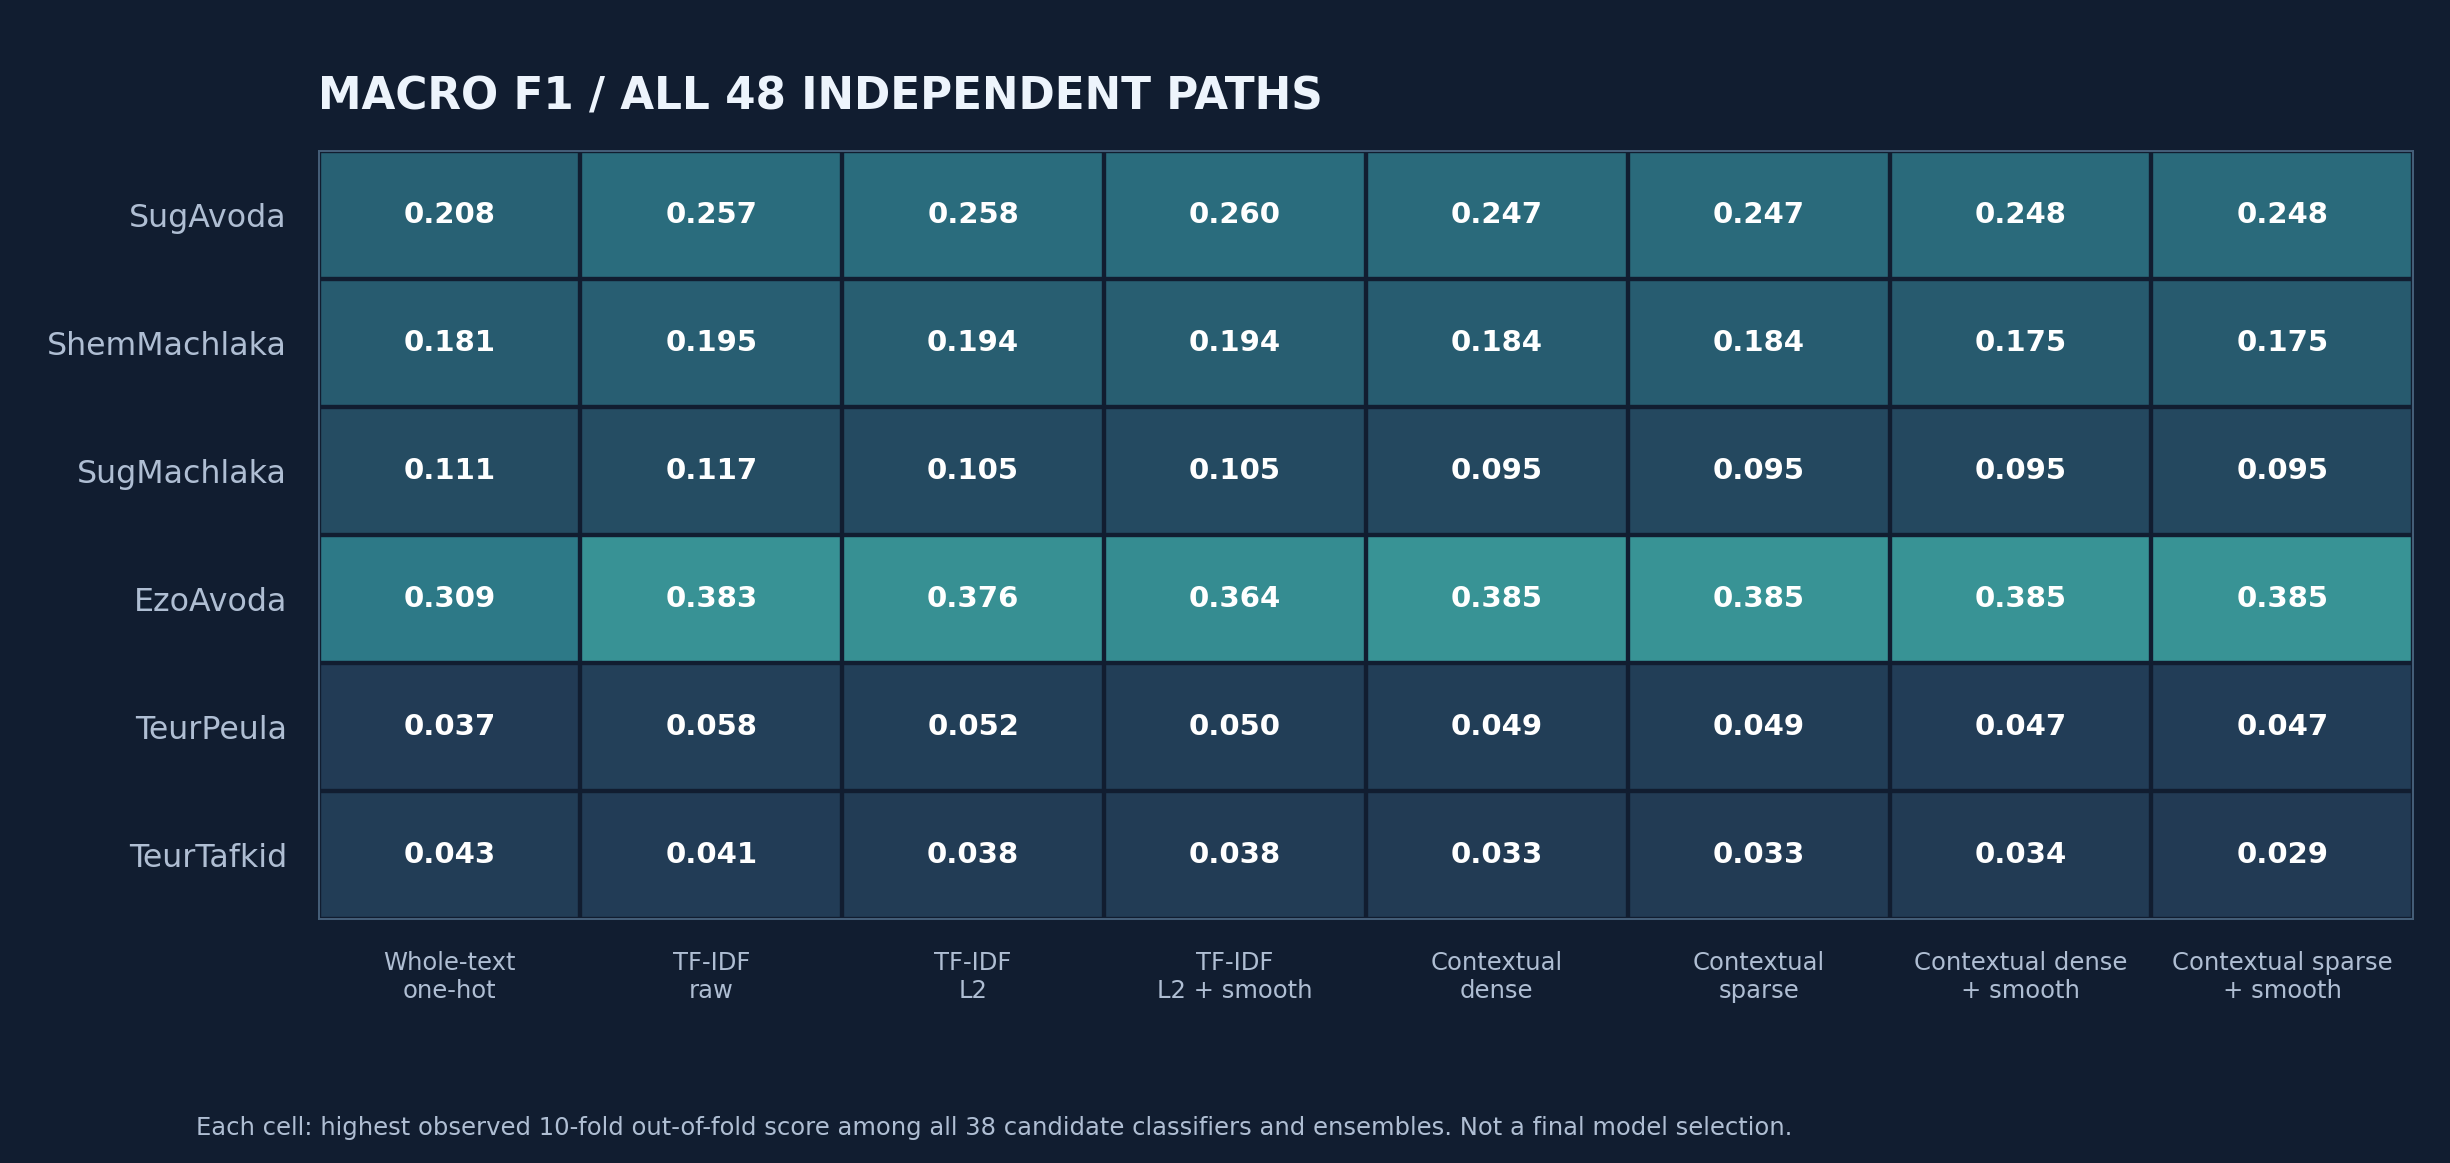

### Accuracy across all 48 independently assessed representation paths

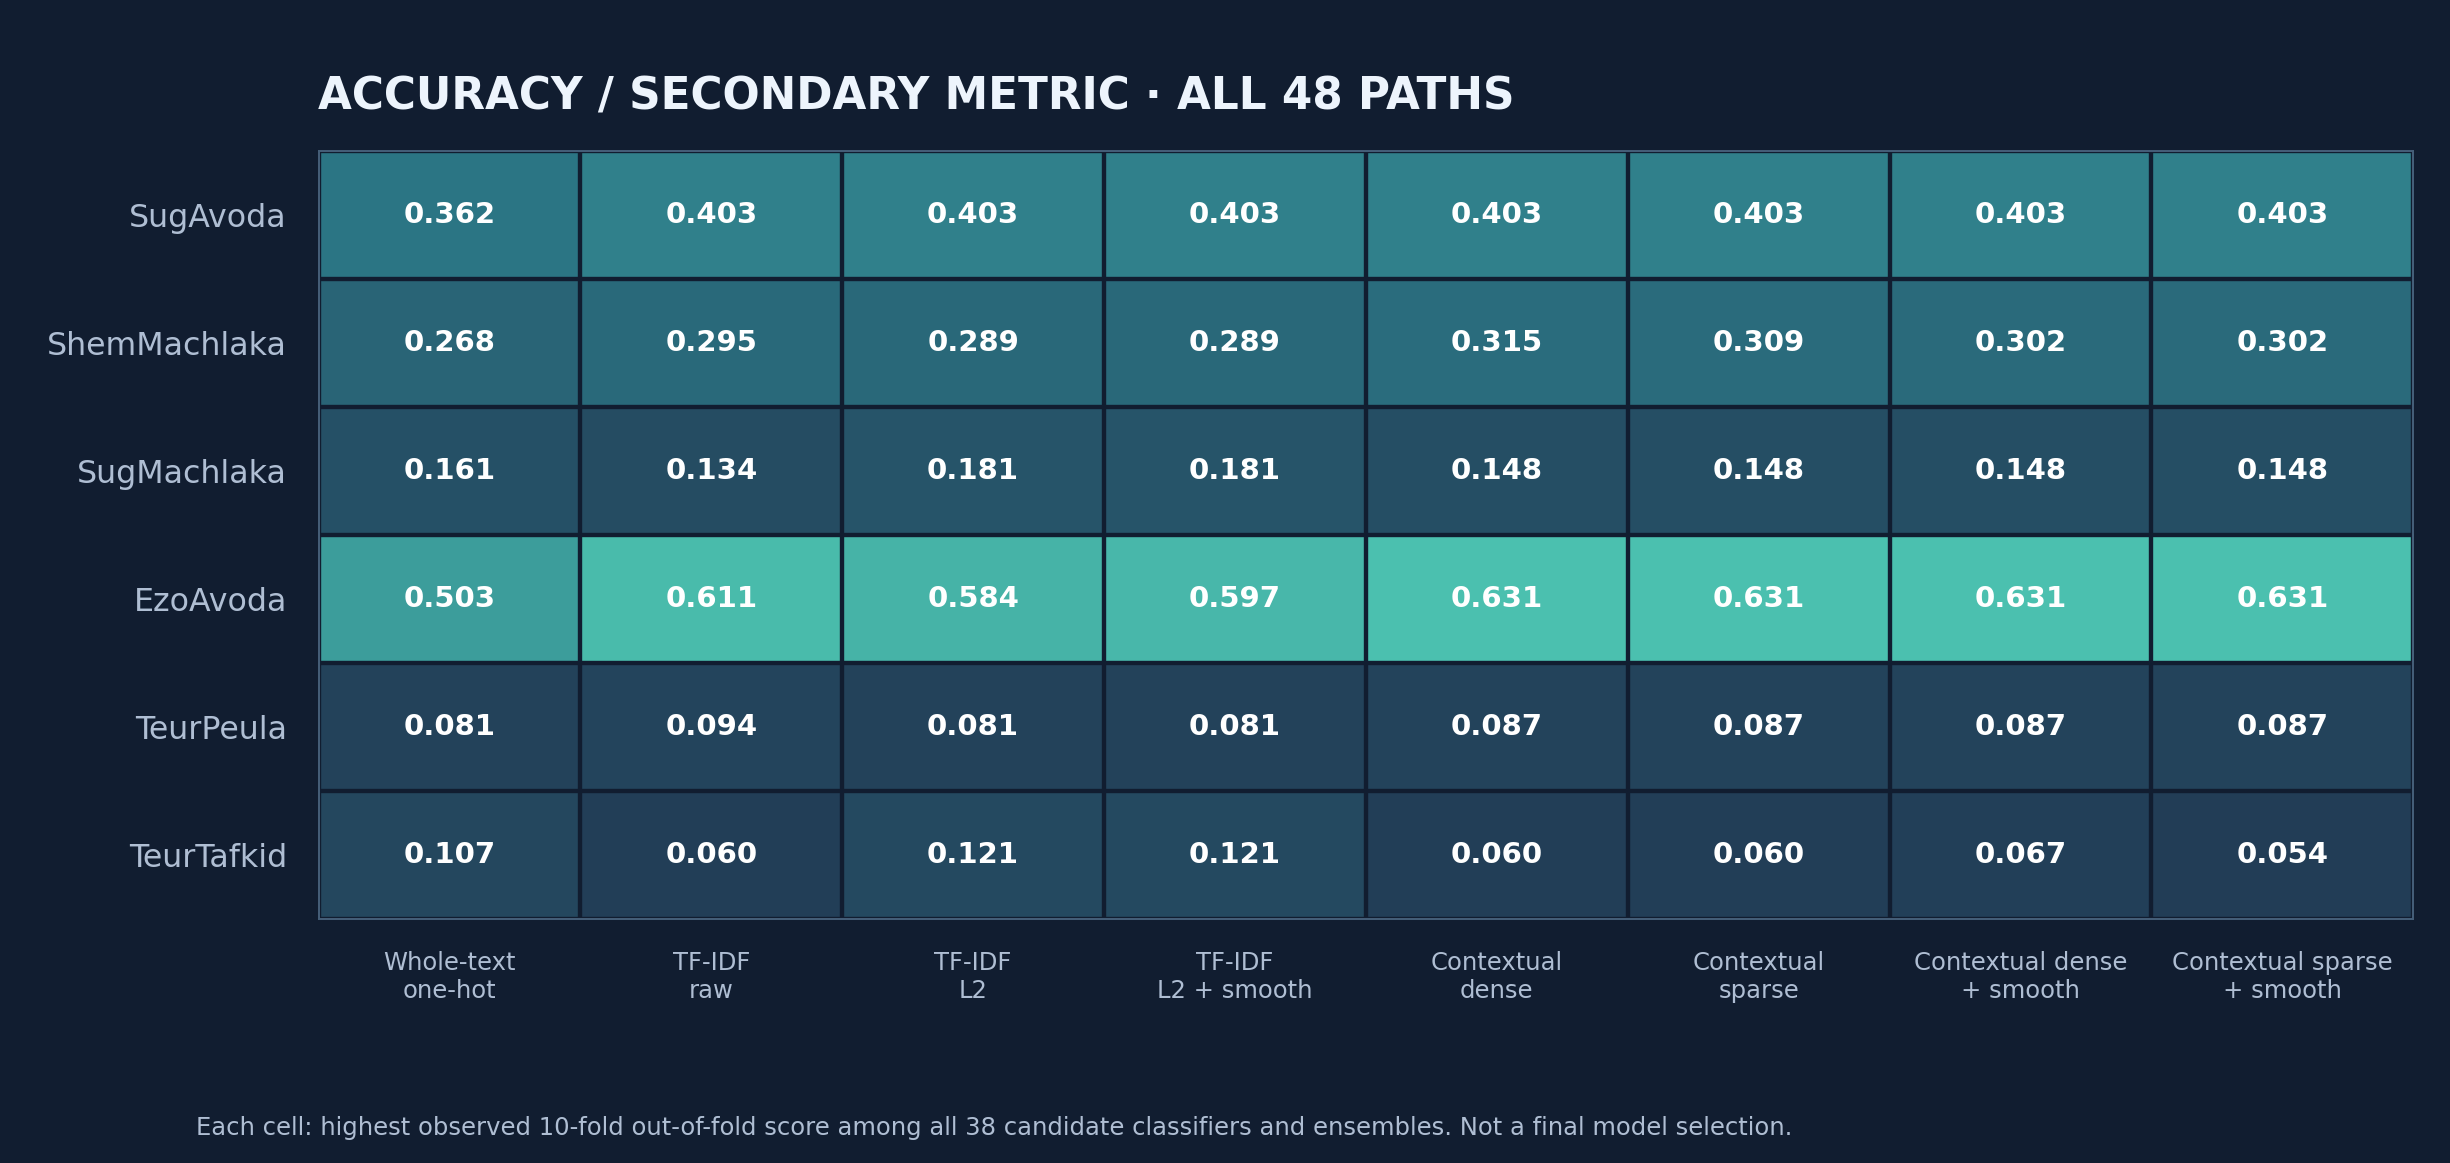

### Three model types and the probability-averaged soft-voting ensemble

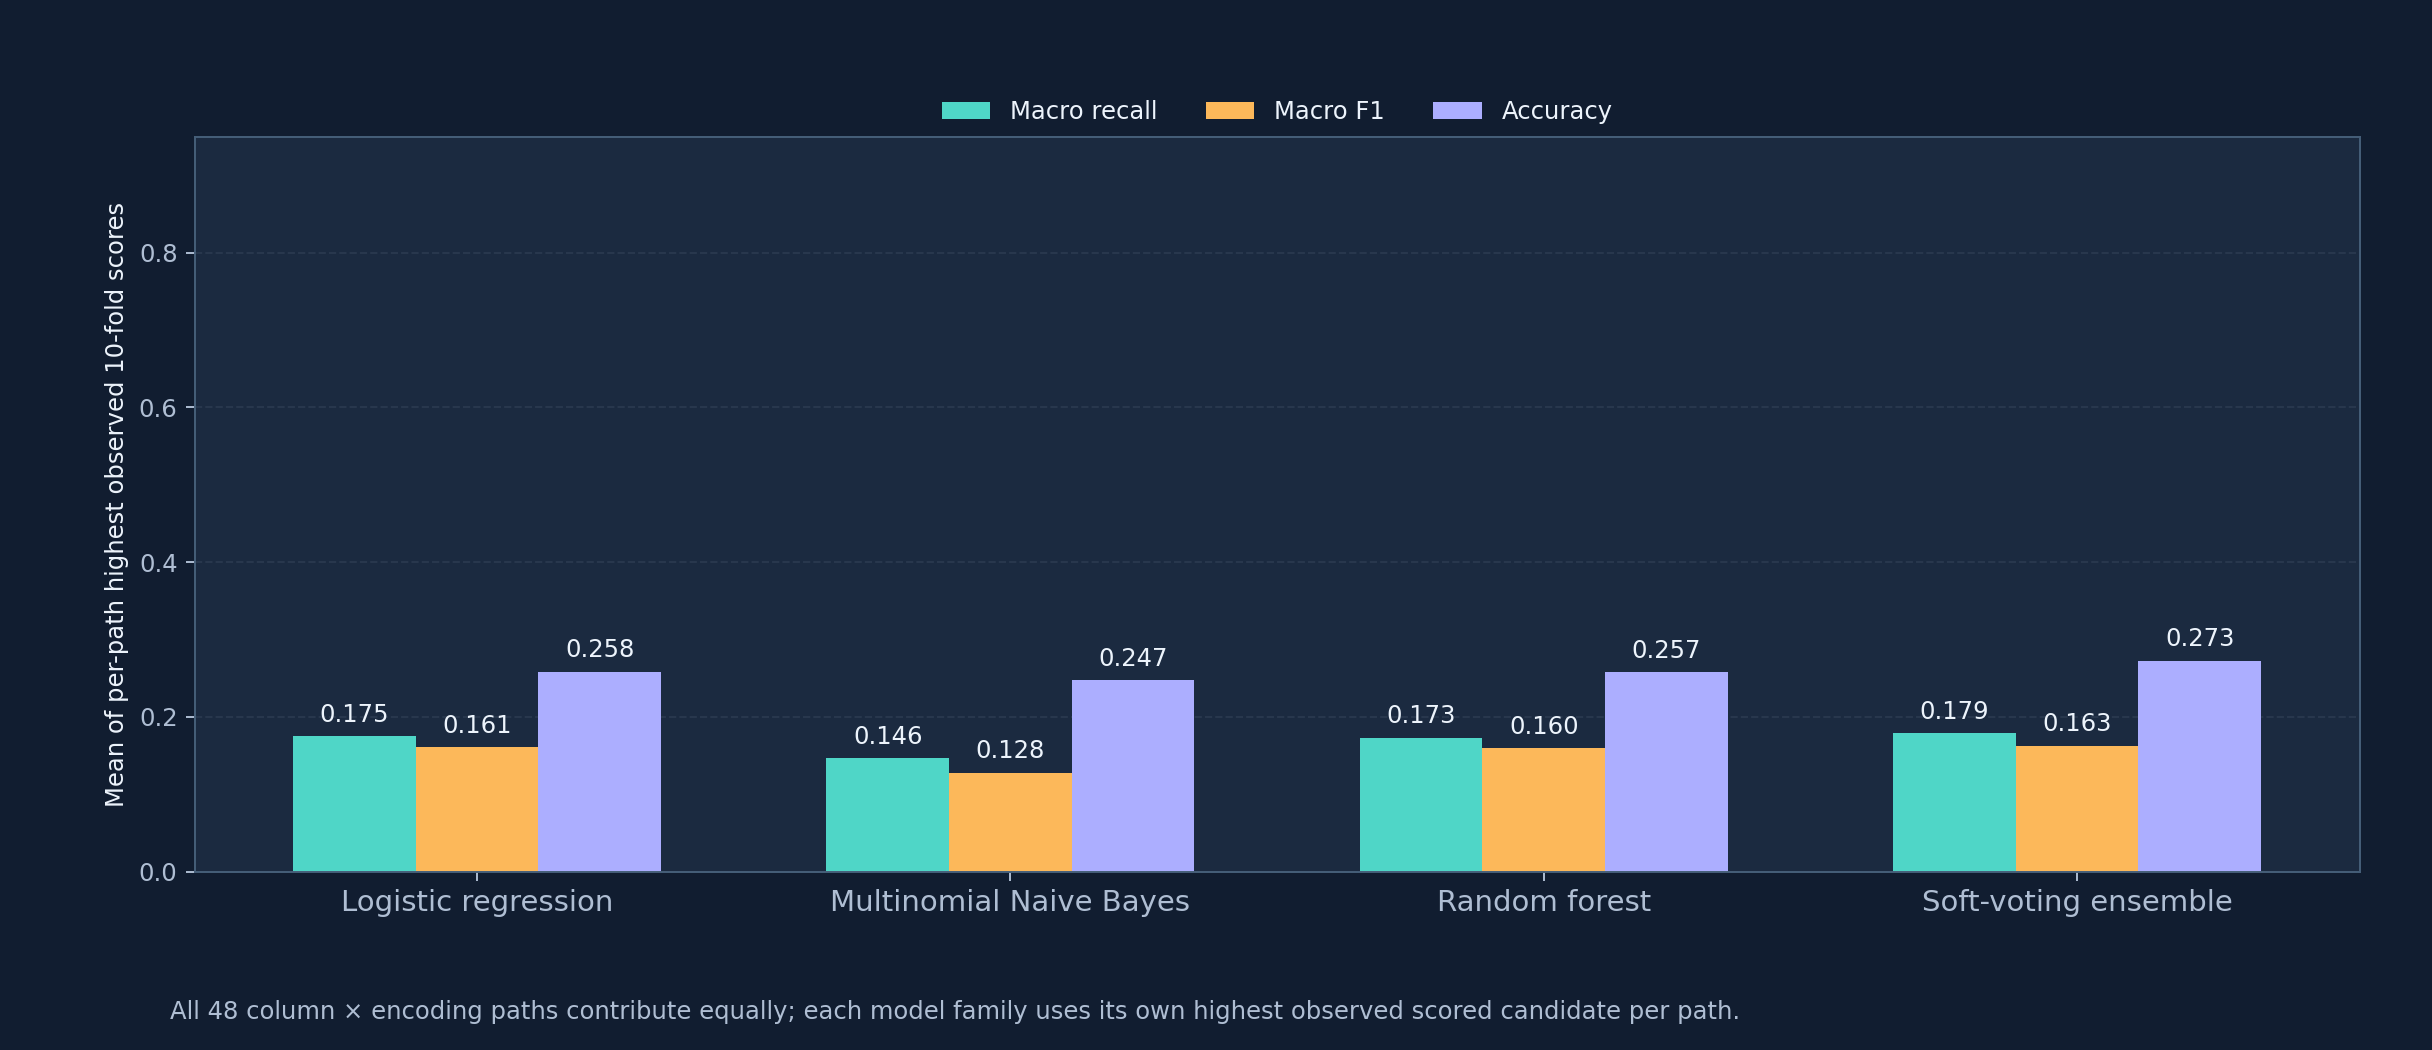

### Observed variance-balance optimal contextual-group counts

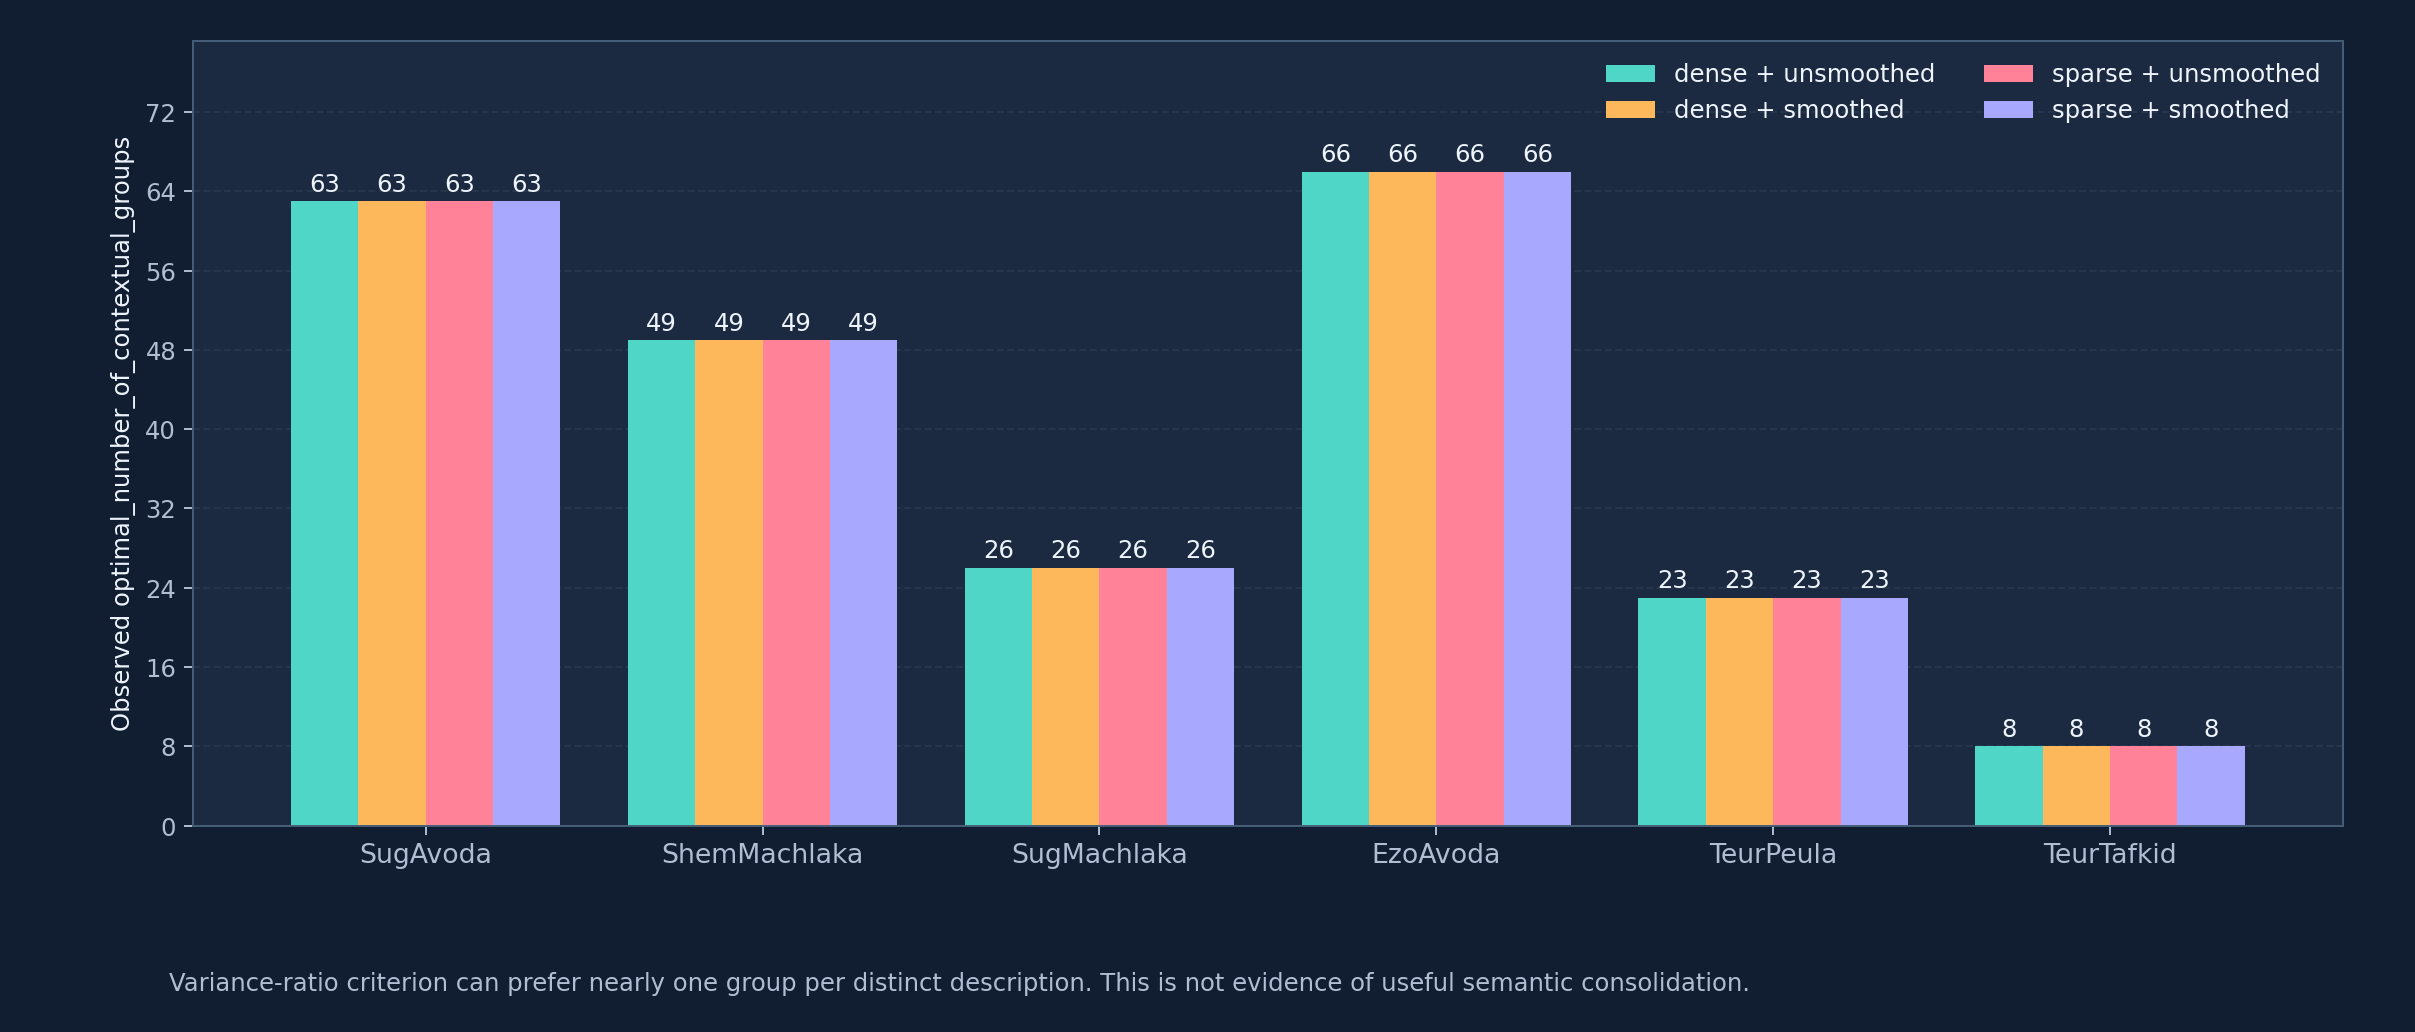

## Verification and handoff

The original V5 notebook remains unchanged. The appended experiment preserves all candidates, measures **10 folds for each candidate**, and does **not** combine occupational text columns. Code is intentionally separated into logical sections with blank lines and does not contain inline Python comments. Every reference to the optimal number of contextual groups uses its descriptive full name. The external holdout is for comparison, not retrospective tuning.

For complete exact scores and individual records, use the accompanying V6 results bundle. Candidate parameters and soft-voting weights are also written to the score CSV files. No model is selected for deployment; the evaluator chooses after reviewing the displayed evidence.

**Historical handoff note:** this was the V6 state before the V7 final selection and full-data retraining below. The new V7 sections embed the complete evidence inside the notebook and supersede the earlier statement that no research model had been selected.

# Final V7 assessment · complete evidence, model selection, and full-data retraining

This section **extends rather than replaces** the original V5 predictive sequence and the executed V6 independent-column comparison. The original baseline, source metadata audit, all 1,824 candidate configurations, 18,240 validation-fold outcomes, candidate hyperparameters, individual predictions, and the corresponding held-out assessments remain preserved.

All experimental records are embedded **inside this notebook** as checksum-verified evidence snapshots. The full source-training code above remains executable for independently regenerating the experiments. The snapshots permit immediate inspection without requiring the reader to repeat 18,240 model evaluations just to inspect results. The dataset itself remains the unchanged original workbook, validated by SHA-256 in the opening cell.

**Primary selection criterion:** highest arithmetic mean of macro-F1 across ten group-disjoint validation folds. For exact ties, the deterministic tie-breakers are higher mean fold macro-recall, lower fold-score standard deviation, and preference for sparse rather than dense representations and unsmoothed rather than smoothed IDF where measured scores are identical. The external holdout is **never a selection criterion**. Macro-F1 computed on pooled out-of-fold predictions is reported separately because it is not generally equal to the mean of ten fold-level macro-F1 scores.

**Interpretation limit:** the same validation folds were used for comparing hyperparameters and selecting among many candidates. Accordingly, the winning validation metric is subject to selection optimism. Grouping keys are description-based proxies rather than verified participant identifiers. The survey dataset is synthetic, and the final model is not approved for autonomous classification.

In [ ]:
from base64 import b64decode
from hashlib import sha256
from io import BytesIO
from zipfile import ZipFile

import json
import pandas as pd


RECORDED_EXPERIMENT_COMPACT_ARCHIVE_BASE64 = (
    '...'
)


verified_experiment_evidence_tables = {}
verified_experiment_evidence_json = {}

with ZipFile(BytesIO(b64decode(''.join(RECORDED_EXPERIMENT_COMPACT_ARCHIVE_BASE64)))) as embedded_evidence_archive:
    original_evidence_hashes = json.loads(embedded_evidence_archive.read('file_sha256_manifest.json'))

    for evidence_filename, expected_sha256 in original_evidence_hashes.items():
        evidence_file_bytes = embedded_evidence_archive.read(evidence_filename)
        assert sha256(evidence_file_bytes).hexdigest() == expected_sha256

        if evidence_filename.endswith('.csv') or evidence_filename.endswith('.csv.gz'):
            file_compression = 'gzip' if evidence_filename.endswith('.csv.gz') else None
            verified_experiment_evidence_tables[evidence_filename] = pd.read_csv(BytesIO(evidence_file_bytes), compression=file_compression, low_memory=False)

        if evidence_filename.endswith('.json'):
            verified_experiment_evidence_json[evidence_filename] = json.loads(evidence_file_bytes.decode('utf-8'))


assert len(verified_experiment_evidence_tables['all_text_columns_all_encoding_paths_all_classifiers_all_hyperparameters_ten_fold_scores.csv']) == 1824
assert len(verified_experiment_evidence_tables['every_individual_group_aware_validation_fold_score.csv']) == 18240
assert len(verified_experiment_evidence_tables['every_ten_fold_validation_prediction_for_every_candidate.csv.gz']) == 271776
assert len(verified_experiment_evidence_tables['every_classifier_and_ensemble_external_holdout_score.csv']) == 1824
assert len(verified_experiment_evidence_tables['every_external_holdout_prediction_for_every_candidate.csv.gz']) == 76608
assert len(verified_experiment_evidence_tables['every_training_only_contextual_group_count_variance_balance_score.csv']) == 9428

print('Checksum-verified embedded records:', len(original_evidence_hashes))
print('All 1,824 candidates, 18,240 fold scores, 271,776 validation predictions, 76,608 holdout predictions and 9,428 clustering evaluations are available within the notebook.')


## Every evaluated option · complete score tables and per-fold evidence

The expandable table is the **complete 1,824-row training-only selection ledger**, not a filtered shortlist. It includes every text column, representation, classifier, member hyperparameters, soft-voting weights, fold-level mean and variability, and independent holdout diagnostics. The 18,240-fold table, 271,776 validation predictions, 76,608 holdout predictions and 9,428 contextual-group-count evaluations are retained as full in-notebook dataframes, with their original machine-readable columns preserved. Every tested path can be inspected by filtering those dataframes.

The original V5 baseline trained on multiple fields and remains explicitly labeled as the historical baseline. **The independent V6/V7 comparison never combines text columns into a single predictive feature matrix.**

### All 1,824 evaluated paths · visible without rerunning training

This is the complete ranked table, not a top-N selection. The exact 18,240 fold scores and all individual predictions are embedded in the next code cell for on-demand inspection.

<details><summary><strong>Expand the entire 1,824-row experimental decision ledger</strong> — all candidates, all columns, all representations, all scores</summary><div style="height:700px;overflow:auto;font-size:11px;margin-top:14px;border:1px solid #aab;"><table class="dataframe">
  <thead>
    <tr style="text-align: right;">
      <th>training_only_selection_rank</th>
      <th>occupational_text_column</th>
      <th>representation_path</th>
      <th>model_name</th>
      <th>classifier_candidate_name</th>
      <th>soft_voting_weights</th>
      <th>mean_fold_macro_f1</th>
      <th>std_fold_macro_f1</th>
      <th>mean_fold_macro_recall</th>
      <th>macro_f1</th>
      <th>accuracy</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <td>1</td>
      <td>EzoAvoda</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.51360</td>
      <td>0.13511</td>
      <td>0.53373</td>
      <td>0.38503</td>
      <td>0.63087</td>
    </tr>
    <tr>
      <td>2</td>
      <td>EzoAvoda</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.51360</td>
      <td>0.13511</td>
      <td>0.53373</td>
      <td>0.38503</td>
      <td>0.63087</td>
    </tr>
    <tr>
      <td>3</td>
      <td>EzoAvoda</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.51360</td>
      <td>0.13511</td>
      <td>0.53373</td>
      <td>0.38503</td>
      <td>0.63087</td>
    </tr>
    <tr>
      <td>4</td>
      <td>EzoAvoda</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.51360</td>
      <td>0.13511</td>
      <td>0.53373</td>
      <td>0.38503</td>
      <td>0.63087</td>
    </tr>
    <tr>
      <td>5</td>
      <td>EzoAvoda</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.50886</td>
      <td>0.17747</td>
      <td>0.53288</td>
      <td>0.35415</td>
      <td>0.61745</td>
    </tr>
    <tr>
      <td>6</td>
      <td>EzoAvoda</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.50886</td>
      <td>0.17747</td>
      <td>0.53288</td>
      <td>0.35565</td>
      <td>0.61745</td>
    </tr>
    <tr>
      <td>7</td>
      <td>EzoAvoda</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.50672</td>
      <td>0.19184</td>
      <td>0.52335</td>
      <td>0.38048</td>
      <td>0.61074</td>
    </tr>
    <tr>
      <td>8</td>
      <td>EzoAvoda</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.50672</td>
      <td>0.19184</td>
      <td>0.52335</td>
      <td>0.38323</td>
      <td>0.61074</td>
    </tr>
    <tr>
      <td>9</td>
      <td>EzoAvoda</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.50672</td>
      <td>0.19184</td>
      <td>0.52335</td>
      <td>0.36520</td>
      <td>0.61074</td>
    </tr>
    <tr>
      <td>10</td>
      <td>EzoAvoda</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.50672</td>
      <td>0.19184</td>
      <td>0.52335</td>
      <td>0.36795</td>
      <td>0.61074</td>
    </tr>
    <tr>
      <td>11</td>
      <td>EzoAvoda</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.50672</td>
      <td>0.19184</td>
      <td>0.52335</td>
      <td>0.38048</td>
      <td>0.61074</td>
    </tr>
    <tr>
      <td>12</td>
      <td>EzoAvoda</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.50672</td>
      <td>0.19184</td>
      <td>0.52335</td>
      <td>0.38048</td>
      <td>0.61074</td>
    </tr>
    <tr>
      <td>13</td>
      <td>EzoAvoda</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.50672</td>
      <td>0.19184</td>
      <td>0.52335</td>
      <td>0.36520</td>
      <td>0.61074</td>
    </tr>
    <tr>
      <td>14</td>
      <td>EzoAvoda</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.50672</td>
      <td>0.19184</td>
      <td>0.52335</td>
      <td>0.36520</td>
      <td>0.61074</td>
    </tr>
    <tr>
      <td>15</td>
      <td>EzoAvoda</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.50577</td>
      <td>0.16885</td>
      <td>0.52064</td>
      <td>0.35803</td>
      <td>0.59732</td>
    </tr>
    <tr>
      <td>16</td>
      <td>EzoAvoda</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.50465</td>
      <td>0.19435</td>
      <td>0.53608</td>
      <td>0.35568</td>
      <td>0.60403</td>
    </tr>
    <tr>
      <td>17</td>
      <td>EzoAvoda</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.50465</td>
      <td>0.19435</td>
      <td>0.53608</td>
      <td>0.35568</td>
      <td>0.60403</td>
    </tr>
    <tr>
      <td>18</td>
      <td>EzoAvoda</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.50363</td>
      <td>0.17288</td>
      <td>0.53326</td>
      <td>0.36533</td>
      <td>0.61074</td>
    </tr>
    <tr>
      <td>19</td>
      <td>EzoAvoda</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.49997</td>
      <td>0.18908</td>
      <td>0.52383</td>
      <td>0.34658</td>
      <td>0.60403</td>
    </tr>
    <tr>
      <td>20</td>
      <td>EzoAvoda</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.49956</td>
      <td>0.17225</td>
      <td>0.51443</td>
      <td>0.35756</td>
      <td>0.59732</td>
    </tr>
    <tr>
      <td>21</td>
      <td>EzoAvoda</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.49838</td>
      <td>0.20176</td>
      <td>0.51502</td>
      <td>0.37202</td>
      <td>0.59732</td>
    </tr>
    <tr>
      <td>22</td>
      <td>EzoAvoda</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.49838</td>
      <td>0.20176</td>
      <td>0.51502</td>
      <td>0.37202</td>
      <td>0.59732</td>
    </tr>
    <tr>
      <td>23</td>
      <td>EzoAvoda</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.49838</td>
      <td>0.20176</td>
      <td>0.51502</td>
      <td>0.35728</td>
      <td>0.59732</td>
    </tr>
    <tr>
      <td>24</td>
      <td>EzoAvoda</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.49838</td>
      <td>0.20176</td>
      <td>0.51502</td>
      <td>0.35728</td>
      <td>0.59732</td>
    </tr>
    <tr>
      <td>25</td>
      <td>EzoAvoda</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.49838</td>
      <td>0.20176</td>
      <td>0.51502</td>
      <td>0.37202</td>
      <td>0.59732</td>
    </tr>
    <tr>
      <td>26</td>
      <td>EzoAvoda</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.49838</td>
      <td>0.20176</td>
      <td>0.51502</td>
      <td>0.37202</td>
      <td>0.59732</td>
    </tr>
    <tr>
      <td>27</td>
      <td>EzoAvoda</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.49838</td>
      <td>0.20176</td>
      <td>0.51502</td>
      <td>0.35728</td>
      <td>0.59732</td>
    </tr>
    <tr>
      <td>28</td>
      <td>EzoAvoda</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.49838</td>
      <td>0.20176</td>
      <td>0.51502</td>
      <td>0.35728</td>
      <td>0.59732</td>
    </tr>
    <tr>
      <td>29</td>
      <td>EzoAvoda</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.49747</td>
      <td>0.17335</td>
      <td>0.52254</td>
      <td>0.35697</td>
      <td>0.61074</td>
    </tr>
    <tr>
      <td>30</td>
      <td>EzoAvoda</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>random_forest</td>
      <td>random_forest__minimum_leaf_records_1</td>
      <td>NaN</td>
      <td>0.49730</td>
      <td>0.15765</td>
      <td>0.51331</td>
      <td>0.37832</td>
      <td>0.61745</td>
    </tr>
    <tr>
      <td>31</td>
      <td>EzoAvoda</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.49730</td>
      <td>0.15765</td>
      <td>0.51331</td>
      <td>0.37832</td>
      <td>0.61745</td>
    </tr>
    <tr>
      <td>32</td>
      <td>EzoAvoda</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.49730</td>
      <td>0.15765</td>
      <td>0.51331</td>
      <td>0.37648</td>
      <td>0.61745</td>
    </tr>
    <tr>
      <td>33</td>
      <td>EzoAvoda</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.49730</td>
      <td>0.15765</td>
      <td>0.51331</td>
      <td>0.37832</td>
      <td>0.61745</td>
    </tr>
    <tr>
      <td>34</td>
      <td>EzoAvoda</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.49730</td>
      <td>0.15765</td>
      <td>0.51331</td>
      <td>0.37832</td>
      <td>0.61745</td>
    </tr>
    <tr>
      <td>35</td>
      <td>EzoAvoda</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.49730</td>
      <td>0.15765</td>
      <td>0.51331</td>
      <td>0.37832</td>
      <td>0.61745</td>
    </tr>
    <tr>
      <td>36</td>
      <td>EzoAvoda</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.49730</td>
      <td>0.15765</td>
      <td>0.51331</td>
      <td>0.37832</td>
      <td>0.61745</td>
    </tr>
    <tr>
      <td>37</td>
      <td>EzoAvoda</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.49730</td>
      <td>0.15765</td>
      <td>0.51331</td>
      <td>0.37832</td>
      <td>0.61745</td>
    </tr>
    <tr>
      <td>38</td>
      <td>EzoAvoda</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.49730</td>
      <td>0.15765</td>
      <td>0.51331</td>
      <td>0.37832</td>
      <td>0.61745</td>
    </tr>
    <tr>
      <td>39</td>
      <td>EzoAvoda</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.49730</td>
      <td>0.15765</td>
      <td>0.51331</td>
      <td>0.37832</td>
      <td>0.61745</td>
    </tr>
    <tr>
      <td>40</td>
      <td>EzoAvoda</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.49730</td>
      <td>0.15765</td>
      <td>0.51331</td>
      <td>0.37832</td>
      <td>0.61745</td>
    </tr>
    <tr>
      <td>41</td>
      <td>EzoAvoda</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.49730</td>
      <td>0.15765</td>
      <td>0.51331</td>
      <td>0.37832</td>
      <td>0.61745</td>
    </tr>
    <tr>
      <td>42</td>
      <td>EzoAvoda</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.49730</td>
      <td>0.15765</td>
      <td>0.51331</td>
      <td>0.37832</td>
      <td>0.61745</td>
    </tr>
    <tr>
      <td>43</td>
      <td>EzoAvoda</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.49730</td>
      <td>0.15765</td>
      <td>0.51331</td>
      <td>0.37832</td>
      <td>0.61745</td>
    </tr>
    <tr>
      <td>44</td>
      <td>EzoAvoda</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.49730</td>
      <td>0.15765</td>
      <td>0.51331</td>
      <td>0.37832</td>
      <td>0.61745</td>
    </tr>
    <tr>
      <td>45</td>
      <td>EzoAvoda</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.49730</td>
      <td>0.15765</td>
      <td>0.51331</td>
      <td>0.37832</td>
      <td>0.61745</td>
    </tr>
    <tr>
      <td>46</td>
      <td>EzoAvoda</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.49730</td>
      <td>0.15765</td>
      <td>0.51331</td>
      <td>0.37832</td>
      <td>0.61745</td>
    </tr>
    <tr>
      <td>47</td>
      <td>EzoAvoda</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.49730</td>
      <td>0.15765</td>
      <td>0.51331</td>
      <td>0.37832</td>
      <td>0.61745</td>
    </tr>
    <tr>
      <td>48</td>
      <td>EzoAvoda</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.49730</td>
      <td>0.15765</td>
      <td>0.51331</td>
      <td>0.37832</td>
      <td>0.61745</td>
    </tr>
    <tr>
      <td>49</td>
      <td>EzoAvoda</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.49730</td>
      <td>0.15765</td>
      <td>0.51331</td>
      <td>0.37832</td>
      <td>0.61745</td>
    </tr>
    <tr>
      <td>50</td>
      <td>EzoAvoda</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.49730</td>
      <td>0.15765</td>
      <td>0.51331</td>
      <td>0.37832</td>
      <td>0.61745</td>
    </tr>
    <tr>
      <td>51</td>
      <td>EzoAvoda</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.49730</td>
      <td>0.15765</td>
      <td>0.51331</td>
      <td>0.37832</td>
      <td>0.61745</td>
    </tr>
    <tr>
      <td>52</td>
      <td>EzoAvoda</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.49730</td>
      <td>0.15765</td>
      <td>0.51331</td>
      <td>0.37832</td>
      <td>0.61745</td>
    </tr>
    <tr>
      <td>53</td>
      <td>EzoAvoda</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.49730</td>
      <td>0.15765</td>
      <td>0.51331</td>
      <td>0.37832</td>
      <td>0.61745</td>
    </tr>
    <tr>
      <td>54</td>
      <td>EzoAvoda</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.49730</td>
      <td>0.15765</td>
      <td>0.51331</td>
      <td>0.37832</td>
      <td>0.61745</td>
    </tr>
    <tr>
      <td>55</td>
      <td>EzoAvoda</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>random_forest</td>
      <td>random_forest__minimum_leaf_records_1</td>
      <td>NaN</td>
      <td>0.49730</td>
      <td>0.15765</td>
      <td>0.51331</td>
      <td>0.37832</td>
      <td>0.61745</td>
    </tr>
    <tr>
      <td>56</td>
      <td>EzoAvoda</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.49730</td>
      <td>0.15765</td>
      <td>0.51331</td>
      <td>0.37832</td>
      <td>0.61745</td>
    </tr>
    <tr>
      <td>57</td>
      <td>EzoAvoda</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.49730</td>
      <td>0.15765</td>
      <td>0.51331</td>
      <td>0.37648</td>
      <td>0.61745</td>
    </tr>
    <tr>
      <td>58</td>
      <td>EzoAvoda</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.49730</td>
      <td>0.15765</td>
      <td>0.51331</td>
      <td>0.37832</td>
      <td>0.61745</td>
    </tr>
    <tr>
      <td>59</td>
      <td>EzoAvoda</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.49730</td>
      <td>0.15765</td>
      <td>0.51331</td>
      <td>0.37832</td>
      <td>0.61745</td>
    </tr>
    <tr>
      <td>60</td>
      <td>EzoAvoda</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.49730</td>
      <td>0.15765</td>
      <td>0.51331</td>
      <td>0.37832</td>
      <td>0.61745</td>
    </tr>
    <tr>
      <td>61</td>
      <td>EzoAvoda</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.49730</td>
      <td>0.15765</td>
      <td>0.51331</td>
      <td>0.37832</td>
      <td>0.61745</td>
    </tr>
    <tr>
      <td>62</td>
      <td>EzoAvoda</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.49730</td>
      <td>0.15765</td>
      <td>0.51331</td>
      <td>0.37832</td>
      <td>0.61745</td>
    </tr>
    <tr>
      <td>63</td>
      <td>EzoAvoda</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.49730</td>
      <td>0.15765</td>
      <td>0.51331</td>
      <td>0.37832</td>
      <td>0.61745</td>
    </tr>
    <tr>
      <td>64</td>
      <td>EzoAvoda</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.49730</td>
      <td>0.15765</td>
      <td>0.51331</td>
      <td>0.37832</td>
      <td>0.61745</td>
    </tr>
    <tr>
      <td>65</td>
      <td>EzoAvoda</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.49730</td>
      <td>0.15765</td>
      <td>0.51331</td>
      <td>0.37832</td>
      <td>0.61745</td>
    </tr>
    <tr>
      <td>66</td>
      <td>EzoAvoda</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.49730</td>
      <td>0.15765</td>
      <td>0.51331</td>
      <td>0.37832</td>
      <td>0.61745</td>
    </tr>
    <tr>
      <td>67</td>
      <td>EzoAvoda</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.49730</td>
      <td>0.15765</td>
      <td>0.51331</td>
      <td>0.37832</td>
      <td>0.61745</td>
    </tr>
    <tr>
      <td>68</td>
      <td>EzoAvoda</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.49730</td>
      <td>0.15765</td>
      <td>0.51331</td>
      <td>0.37832</td>
      <td>0.61745</td>
    </tr>
    <tr>
      <td>69</td>
      <td>EzoAvoda</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.49730</td>
      <td>0.15765</td>
      <td>0.51331</td>
      <td>0.37832</td>
      <td>0.61745</td>
    </tr>
    <tr>
      <td>70</td>
      <td>EzoAvoda</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.49730</td>
      <td>0.15765</td>
      <td>0.51331</td>
      <td>0.37832</td>
      <td>0.61745</td>
    </tr>
    <tr>
      <td>71</td>
      <td>EzoAvoda</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.49730</td>
      <td>0.15765</td>
      <td>0.51331</td>
      <td>0.37832</td>
      <td>0.61745</td>
    </tr>
    <tr>
      <td>72</td>
      <td>EzoAvoda</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.49730</td>
      <td>0.15765</td>
      <td>0.51331</td>
      <td>0.37832</td>
      <td>0.61745</td>
    </tr>
    <tr>
      <td>73</td>
      <td>EzoAvoda</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.49730</td>
      <td>0.15765</td>
      <td>0.51331</td>
      <td>0.37832</td>
      <td>0.61745</td>
    </tr>
    <tr>
      <td>74</td>
      <td>EzoAvoda</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.49730</td>
      <td>0.15765</td>
      <td>0.51331</td>
      <td>0.37832</td>
      <td>0.61745</td>
    </tr>
    <tr>
      <td>75</td>
      <td>EzoAvoda</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.49730</td>
      <td>0.15765</td>
      <td>0.51331</td>
      <td>0.37832</td>
      <td>0.61745</td>
    </tr>
    <tr>
      <td>76</td>
      <td>EzoAvoda</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.49730</td>
      <td>0.15765</td>
      <td>0.51331</td>
      <td>0.37832</td>
      <td>0.61745</td>
    </tr>
    <tr>
      <td>77</td>
      <td>EzoAvoda</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.49730</td>
      <td>0.15765</td>
      <td>0.51331</td>
      <td>0.37832</td>
      <td>0.61745</td>
    </tr>
    <tr>
      <td>78</td>
      <td>EzoAvoda</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.49730</td>
      <td>0.15765</td>
      <td>0.51331</td>
      <td>0.37832</td>
      <td>0.61745</td>
    </tr>
    <tr>
      <td>79</td>
      <td>EzoAvoda</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.49730</td>
      <td>0.15765</td>
      <td>0.51331</td>
      <td>0.37832</td>
      <td>0.61745</td>
    </tr>
    <tr>
      <td>80</td>
      <td>EzoAvoda</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>random_forest</td>
      <td>random_forest__minimum_leaf_records_1</td>
      <td>NaN</td>
      <td>0.49730</td>
      <td>0.15765</td>
      <td>0.51331</td>
      <td>0.37832</td>
      <td>0.61745</td>
    </tr>
    <tr>
      <td>81</td>
      <td>EzoAvoda</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.49730</td>
      <td>0.15765</td>
      <td>0.51331</td>
      <td>0.37832</td>
      <td>0.61745</td>
    </tr>
    <tr>
      <td>82</td>
      <td>EzoAvoda</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.49730</td>
      <td>0.15765</td>
      <td>0.51331</td>
      <td>0.37648</td>
      <td>0.61745</td>
    </tr>
    <tr>
      <td>83</td>
      <td>EzoAvoda</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.49730</td>
      <td>0.15765</td>
      <td>0.51331</td>
      <td>0.37832</td>
      <td>0.61745</td>
    </tr>
    <tr>
      <td>84</td>
      <td>EzoAvoda</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.49730</td>
      <td>0.15765</td>
      <td>0.51331</td>
      <td>0.37832</td>
      <td>0.61745</td>
    </tr>
    <tr>
      <td>85</td>
      <td>EzoAvoda</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.49730</td>
      <td>0.15765</td>
      <td>0.51331</td>
      <td>0.37832</td>
      <td>0.61745</td>
    </tr>
    <tr>
      <td>86</td>
      <td>EzoAvoda</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.49730</td>
      <td>0.15765</td>
      <td>0.51331</td>
      <td>0.37832</td>
      <td>0.61745</td>
    </tr>
    <tr>
      <td>87</td>
      <td>EzoAvoda</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.49730</td>
      <td>0.15765</td>
      <td>0.51331</td>
      <td>0.37832</td>
      <td>0.61745</td>
    </tr>
    <tr>
      <td>88</td>
      <td>EzoAvoda</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.49730</td>
      <td>0.15765</td>
      <td>0.51331</td>
      <td>0.37832</td>
      <td>0.61745</td>
    </tr>
    <tr>
      <td>89</td>
      <td>EzoAvoda</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.49730</td>
      <td>0.15765</td>
      <td>0.51331</td>
      <td>0.37832</td>
      <td>0.61745</td>
    </tr>
    <tr>
      <td>90</td>
      <td>EzoAvoda</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.49730</td>
      <td>0.15765</td>
      <td>0.51331</td>
      <td>0.37832</td>
      <td>0.61745</td>
    </tr>
    <tr>
      <td>91</td>
      <td>EzoAvoda</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.49730</td>
      <td>0.15765</td>
      <td>0.51331</td>
      <td>0.37832</td>
      <td>0.61745</td>
    </tr>
    <tr>
      <td>92</td>
      <td>EzoAvoda</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.49730</td>
      <td>0.15765</td>
      <td>0.51331</td>
      <td>0.37832</td>
      <td>0.61745</td>
    </tr>
    <tr>
      <td>93</td>
      <td>EzoAvoda</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.49730</td>
      <td>0.15765</td>
      <td>0.51331</td>
      <td>0.37832</td>
      <td>0.61745</td>
    </tr>
    <tr>
      <td>94</td>
      <td>EzoAvoda</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.49730</td>
      <td>0.15765</td>
      <td>0.51331</td>
      <td>0.37832</td>
      <td>0.61745</td>
    </tr>
    <tr>
      <td>95</td>
      <td>EzoAvoda</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.49730</td>
      <td>0.15765</td>
      <td>0.51331</td>
      <td>0.37832</td>
      <td>0.61745</td>
    </tr>
    <tr>
      <td>96</td>
      <td>EzoAvoda</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.49730</td>
      <td>0.15765</td>
      <td>0.51331</td>
      <td>0.37832</td>
      <td>0.61745</td>
    </tr>
    <tr>
      <td>97</td>
      <td>EzoAvoda</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.49730</td>
      <td>0.15765</td>
      <td>0.51331</td>
      <td>0.37832</td>
      <td>0.61745</td>
    </tr>
    <tr>
      <td>98</td>
      <td>EzoAvoda</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.49730</td>
      <td>0.15765</td>
      <td>0.51331</td>
      <td>0.37832</td>
      <td>0.61745</td>
    </tr>
    <tr>
      <td>99</td>
      <td>EzoAvoda</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.49730</td>
      <td>0.15765</td>
      <td>0.51331</td>
      <td>0.37832</td>
      <td>0.61745</td>
    </tr>
    <tr>
      <td>100</td>
      <td>EzoAvoda</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.49730</td>
      <td>0.15765</td>
      <td>0.51331</td>
      <td>0.37832</td>
      <td>0.61745</td>
    </tr>
    <tr>
      <td>101</td>
      <td>EzoAvoda</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.49730</td>
      <td>0.15765</td>
      <td>0.51331</td>
      <td>0.37832</td>
      <td>0.61745</td>
    </tr>
    <tr>
      <td>102</td>
      <td>EzoAvoda</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.49730</td>
      <td>0.15765</td>
      <td>0.51331</td>
      <td>0.37832</td>
      <td>0.61745</td>
    </tr>
    <tr>
      <td>103</td>
      <td>EzoAvoda</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.49730</td>
      <td>0.15765</td>
      <td>0.51331</td>
      <td>0.37832</td>
      <td>0.61745</td>
    </tr>
    <tr>
      <td>104</td>
      <td>EzoAvoda</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.49730</td>
      <td>0.15765</td>
      <td>0.51331</td>
      <td>0.37832</td>
      <td>0.61745</td>
    </tr>
    <tr>
      <td>105</td>
      <td>EzoAvoda</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>random_forest</td>
      <td>random_forest__minimum_leaf_records_1</td>
      <td>NaN</td>
      <td>0.49730</td>
      <td>0.15765</td>
      <td>0.51331</td>
      <td>0.37832</td>
      <td>0.61745</td>
    </tr>
    <tr>
      <td>106</td>
      <td>EzoAvoda</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.49730</td>
      <td>0.15765</td>
      <td>0.51331</td>
      <td>0.37832</td>
      <td>0.61745</td>
    </tr>
    <tr>
      <td>107</td>
      <td>EzoAvoda</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.49730</td>
      <td>0.15765</td>
      <td>0.51331</td>
      <td>0.37648</td>
      <td>0.61745</td>
    </tr>
    <tr>
      <td>108</td>
      <td>EzoAvoda</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.49730</td>
      <td>0.15765</td>
      <td>0.51331</td>
      <td>0.37832</td>
      <td>0.61745</td>
    </tr>
    <tr>
      <td>109</td>
      <td>EzoAvoda</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.49730</td>
      <td>0.15765</td>
      <td>0.51331</td>
      <td>0.37832</td>
      <td>0.61745</td>
    </tr>
    <tr>
      <td>110</td>
      <td>EzoAvoda</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.49730</td>
      <td>0.15765</td>
      <td>0.51331</td>
      <td>0.37832</td>
      <td>0.61745</td>
    </tr>
    <tr>
      <td>111</td>
      <td>EzoAvoda</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.49730</td>
      <td>0.15765</td>
      <td>0.51331</td>
      <td>0.37832</td>
      <td>0.61745</td>
    </tr>
    <tr>
      <td>112</td>
      <td>EzoAvoda</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.49730</td>
      <td>0.15765</td>
      <td>0.51331</td>
      <td>0.37832</td>
      <td>0.61745</td>
    </tr>
    <tr>
      <td>113</td>
      <td>EzoAvoda</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.49730</td>
      <td>0.15765</td>
      <td>0.51331</td>
      <td>0.37832</td>
      <td>0.61745</td>
    </tr>
    <tr>
      <td>114</td>
      <td>EzoAvoda</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.49730</td>
      <td>0.15765</td>
      <td>0.51331</td>
      <td>0.37832</td>
      <td>0.61745</td>
    </tr>
    <tr>
      <td>115</td>
      <td>EzoAvoda</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.49730</td>
      <td>0.15765</td>
      <td>0.51331</td>
      <td>0.37832</td>
      <td>0.61745</td>
    </tr>
    <tr>
      <td>116</td>
      <td>EzoAvoda</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.49730</td>
      <td>0.15765</td>
      <td>0.51331</td>
      <td>0.37832</td>
      <td>0.61745</td>
    </tr>
    <tr>
      <td>117</td>
      <td>EzoAvoda</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.49730</td>
      <td>0.15765</td>
      <td>0.51331</td>
      <td>0.37832</td>
      <td>0.61745</td>
    </tr>
    <tr>
      <td>118</td>
      <td>EzoAvoda</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.49730</td>
      <td>0.15765</td>
      <td>0.51331</td>
      <td>0.37832</td>
      <td>0.61745</td>
    </tr>
    <tr>
      <td>119</td>
      <td>EzoAvoda</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.49730</td>
      <td>0.15765</td>
      <td>0.51331</td>
      <td>0.37832</td>
      <td>0.61745</td>
    </tr>
    <tr>
      <td>120</td>
      <td>EzoAvoda</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.49730</td>
      <td>0.15765</td>
      <td>0.51331</td>
      <td>0.37832</td>
      <td>0.61745</td>
    </tr>
    <tr>
      <td>121</td>
      <td>EzoAvoda</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.49730</td>
      <td>0.15765</td>
      <td>0.51331</td>
      <td>0.37832</td>
      <td>0.61745</td>
    </tr>
    <tr>
      <td>122</td>
      <td>EzoAvoda</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.49730</td>
      <td>0.15765</td>
      <td>0.51331</td>
      <td>0.37832</td>
      <td>0.61745</td>
    </tr>
    <tr>
      <td>123</td>
      <td>EzoAvoda</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.49730</td>
      <td>0.15765</td>
      <td>0.51331</td>
      <td>0.37832</td>
      <td>0.61745</td>
    </tr>
    <tr>
      <td>124</td>
      <td>EzoAvoda</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.49730</td>
      <td>0.15765</td>
      <td>0.51331</td>
      <td>0.37832</td>
      <td>0.61745</td>
    </tr>
    <tr>
      <td>125</td>
      <td>EzoAvoda</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.49730</td>
      <td>0.15765</td>
      <td>0.51331</td>
      <td>0.37832</td>
      <td>0.61745</td>
    </tr>
    <tr>
      <td>126</td>
      <td>EzoAvoda</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.49730</td>
      <td>0.15765</td>
      <td>0.51331</td>
      <td>0.37832</td>
      <td>0.61745</td>
    </tr>
    <tr>
      <td>127</td>
      <td>EzoAvoda</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.49730</td>
      <td>0.15765</td>
      <td>0.51331</td>
      <td>0.37832</td>
      <td>0.61745</td>
    </tr>
    <tr>
      <td>128</td>
      <td>EzoAvoda</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.49730</td>
      <td>0.15765</td>
      <td>0.51331</td>
      <td>0.37832</td>
      <td>0.61745</td>
    </tr>
    <tr>
      <td>129</td>
      <td>EzoAvoda</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.49730</td>
      <td>0.15765</td>
      <td>0.51331</td>
      <td>0.37832</td>
      <td>0.61745</td>
    </tr>
    <tr>
      <td>130</td>
      <td>EzoAvoda</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.49707</td>
      <td>0.16802</td>
      <td>0.52244</td>
      <td>0.35305</td>
      <td>0.61074</td>
    </tr>
    <tr>
      <td>131</td>
      <td>EzoAvoda</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.49612</td>
      <td>0.15631</td>
      <td>0.50504</td>
      <td>0.37079</td>
      <td>0.59060</td>
    </tr>
    <tr>
      <td>132</td>
      <td>EzoAvoda</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.49612</td>
      <td>0.15631</td>
      <td>0.50504</td>
      <td>0.37079</td>
      <td>0.59060</td>
    </tr>
    <tr>
      <td>133</td>
      <td>EzoAvoda</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.49612</td>
      <td>0.18176</td>
      <td>0.51291</td>
      <td>0.37865</td>
      <td>0.60403</td>
    </tr>
    <tr>
      <td>134</td>
      <td>EzoAvoda</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.49527</td>
      <td>0.16823</td>
      <td>0.51429</td>
      <td>0.35490</td>
      <td>0.61074</td>
    </tr>
    <tr>
      <td>135</td>
      <td>EzoAvoda</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.49521</td>
      <td>0.17072</td>
      <td>0.52225</td>
      <td>0.35180</td>
      <td>0.61074</td>
    </tr>
    <tr>
      <td>136</td>
      <td>EzoAvoda</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.49422</td>
      <td>0.15925</td>
      <td>0.50313</td>
      <td>0.36896</td>
      <td>0.59060</td>
    </tr>
    <tr>
      <td>137</td>
      <td>EzoAvoda</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.49389</td>
      <td>0.18409</td>
      <td>0.51053</td>
      <td>0.36200</td>
      <td>0.60403</td>
    </tr>
    <tr>
      <td>138</td>
      <td>EzoAvoda</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.49389</td>
      <td>0.18409</td>
      <td>0.51053</td>
      <td>0.36200</td>
      <td>0.60403</td>
    </tr>
    <tr>
      <td>139</td>
      <td>EzoAvoda</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.49167</td>
      <td>0.19091</td>
      <td>0.52493</td>
      <td>0.36104</td>
      <td>0.60403</td>
    </tr>
    <tr>
      <td>140</td>
      <td>EzoAvoda</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.49061</td>
      <td>0.15857</td>
      <td>0.49929</td>
      <td>0.36619</td>
      <td>0.59060</td>
    </tr>
    <tr>
      <td>141</td>
      <td>EzoAvoda</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.49059</td>
      <td>0.16021</td>
      <td>0.49929</td>
      <td>0.36896</td>
      <td>0.59060</td>
    </tr>
    <tr>
      <td>142</td>
      <td>EzoAvoda</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.48993</td>
      <td>0.15980</td>
      <td>0.50467</td>
      <td>0.37576</td>
      <td>0.59060</td>
    </tr>
    <tr>
      <td>143</td>
      <td>EzoAvoda</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.48954</td>
      <td>0.19122</td>
      <td>0.51897</td>
      <td>0.35286</td>
      <td>0.60403</td>
    </tr>
    <tr>
      <td>144</td>
      <td>EzoAvoda</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.48927</td>
      <td>0.19180</td>
      <td>0.52062</td>
      <td>0.35024</td>
      <td>0.60403</td>
    </tr>
    <tr>
      <td>145</td>
      <td>EzoAvoda</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.48922</td>
      <td>0.16829</td>
      <td>0.49456</td>
      <td>0.36651</td>
      <td>0.58389</td>
    </tr>
    <tr>
      <td>146</td>
      <td>EzoAvoda</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.48922</td>
      <td>0.16829</td>
      <td>0.49456</td>
      <td>0.36651</td>
      <td>0.58389</td>
    </tr>
    <tr>
      <td>147</td>
      <td>EzoAvoda</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.48922</td>
      <td>0.16829</td>
      <td>0.49456</td>
      <td>0.37613</td>
      <td>0.58389</td>
    </tr>
    <tr>
      <td>148</td>
      <td>EzoAvoda</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.48864</td>
      <td>0.15656</td>
      <td>0.49734</td>
      <td>0.36791</td>
      <td>0.59060</td>
    </tr>
    <tr>
      <td>149</td>
      <td>EzoAvoda</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.48864</td>
      <td>0.15656</td>
      <td>0.49734</td>
      <td>0.36791</td>
      <td>0.59060</td>
    </tr>
    <tr>
      <td>150</td>
      <td>EzoAvoda</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.48779</td>
      <td>0.15886</td>
      <td>0.50351</td>
      <td>0.35784</td>
      <td>0.59060</td>
    </tr>
    <tr>
      <td>151</td>
      <td>EzoAvoda</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>multinomial_naive_bayes</td>
      <td>multinomial_naive_bayes__additive_smoothing_1p3</td>
      <td>NaN</td>
      <td>0.48775</td>
      <td>0.18517</td>
      <td>0.50560</td>
      <td>0.35059</td>
      <td>0.59060</td>
    </tr>
    <tr>
      <td>152</td>
      <td>EzoAvoda</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.48729</td>
      <td>0.15792</td>
      <td>0.50357</td>
      <td>0.35837</td>
      <td>0.59060</td>
    </tr>
    <tr>
      <td>153</td>
      <td>EzoAvoda</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.48715</td>
      <td>0.18068</td>
      <td>0.51101</td>
      <td>0.34465</td>
      <td>0.59732</td>
    </tr>
    <tr>
      <td>154</td>
      <td>EzoAvoda</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.48698</td>
      <td>0.15945</td>
      <td>0.49544</td>
      <td>0.35886</td>
      <td>0.59060</td>
    </tr>
    <tr>
      <td>155</td>
      <td>EzoAvoda</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.48658</td>
      <td>0.15991</td>
      <td>0.50077</td>
      <td>0.37522</td>
      <td>0.59060</td>
    </tr>
    <tr>
      <td>156</td>
      <td>EzoAvoda</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.48658</td>
      <td>0.15991</td>
      <td>0.50077</td>
      <td>0.37522</td>
      <td>0.59060</td>
    </tr>
    <tr>
      <td>157</td>
      <td>EzoAvoda</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.48658</td>
      <td>0.15991</td>
      <td>0.50077</td>
      <td>0.36058</td>
      <td>0.59060</td>
    </tr>
    <tr>
      <td>158</td>
      <td>EzoAvoda</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.48654</td>
      <td>0.16535</td>
      <td>0.49738</td>
      <td>0.34887</td>
      <td>0.58389</td>
    </tr>
    <tr>
      <td>159</td>
      <td>EzoAvoda</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.48570</td>
      <td>0.19051</td>
      <td>0.51513</td>
      <td>0.34589</td>
      <td>0.60403</td>
    </tr>
    <tr>
      <td>160</td>
      <td>EzoAvoda</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.48416</td>
      <td>0.18388</td>
      <td>0.51320</td>
      <td>0.34437</td>
      <td>0.60403</td>
    </tr>
    <tr>
      <td>161</td>
      <td>EzoAvoda</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>logistic_regression</td>
      <td>logistic_regression__regularization_strength_0p3</td>
      <td>NaN</td>
      <td>0.48396</td>
      <td>0.14013</td>
      <td>0.49985</td>
      <td>0.37255</td>
      <td>0.61074</td>
    </tr>
    <tr>
      <td>162</td>
      <td>EzoAvoda</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>logistic_regression</td>
      <td>logistic_regression__regularization_strength_3</td>
      <td>NaN</td>
      <td>0.48396</td>
      <td>0.14013</td>
      <td>0.49985</td>
      <td>0.37255</td>
      <td>0.61074</td>
    </tr>
    <tr>
      <td>163</td>
      <td>EzoAvoda</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>logistic_regression</td>
      <td>logistic_regression__regularization_strength_0p3</td>
      <td>NaN</td>
      <td>0.48396</td>
      <td>0.14013</td>
      <td>0.49985</td>
      <td>0.37255</td>
      <td>0.61074</td>
    </tr>
    <tr>
      <td>164</td>
      <td>EzoAvoda</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>logistic_regression</td>
      <td>logistic_regression__regularization_strength_3</td>
      <td>NaN</td>
      <td>0.48396</td>
      <td>0.14013</td>
      <td>0.49985</td>
      <td>0.37255</td>
      <td>0.61074</td>
    </tr>
    <tr>
      <td>165</td>
      <td>EzoAvoda</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>logistic_regression</td>
      <td>logistic_regression__regularization_strength_0p3</td>
      <td>NaN</td>
      <td>0.48396</td>
      <td>0.14013</td>
      <td>0.49985</td>
      <td>0.37255</td>
      <td>0.61074</td>
    </tr>
    <tr>
      <td>166</td>
      <td>EzoAvoda</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>logistic_regression</td>
      <td>logistic_regression__regularization_strength_3</td>
      <td>NaN</td>
      <td>0.48396</td>
      <td>0.14013</td>
      <td>0.49985</td>
      <td>0.37255</td>
      <td>0.61074</td>
    </tr>
    <tr>
      <td>167</td>
      <td>EzoAvoda</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>logistic_regression</td>
      <td>logistic_regression__regularization_strength_0p3</td>
      <td>NaN</td>
      <td>0.48396</td>
      <td>0.14013</td>
      <td>0.49985</td>
      <td>0.37255</td>
      <td>0.61074</td>
    </tr>
    <tr>
      <td>168</td>
      <td>EzoAvoda</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>logistic_regression</td>
      <td>logistic_regression__regularization_strength_3</td>
      <td>NaN</td>
      <td>0.48396</td>
      <td>0.14013</td>
      <td>0.49985</td>
      <td>0.37255</td>
      <td>0.61074</td>
    </tr>
    <tr>
      <td>169</td>
      <td>EzoAvoda</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.48330</td>
      <td>0.17269</td>
      <td>0.50009</td>
      <td>0.37549</td>
      <td>0.59060</td>
    </tr>
    <tr>
      <td>170</td>
      <td>EzoAvoda</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.48326</td>
      <td>0.18766</td>
      <td>0.52455</td>
      <td>0.33518</td>
      <td>0.57047</td>
    </tr>
    <tr>
      <td>171</td>
      <td>EzoAvoda</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.48326</td>
      <td>0.18766</td>
      <td>0.52455</td>
      <td>0.33518</td>
      <td>0.57047</td>
    </tr>
    <tr>
      <td>172</td>
      <td>EzoAvoda</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.48323</td>
      <td>0.16659</td>
      <td>0.49214</td>
      <td>0.35133</td>
      <td>0.57718</td>
    </tr>
    <tr>
      <td>173</td>
      <td>EzoAvoda</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>logistic_regression</td>
      <td>logistic_regression__regularization_strength_3</td>
      <td>NaN</td>
      <td>0.48283</td>
      <td>0.17590</td>
      <td>0.50073</td>
      <td>0.36167</td>
      <td>0.59060</td>
    </tr>
    <tr>
      <td>174</td>
      <td>EzoAvoda</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.48255</td>
      <td>0.18180</td>
      <td>0.48789</td>
      <td>0.37500</td>
      <td>0.57718</td>
    </tr>
    <tr>
      <td>175</td>
      <td>EzoAvoda</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.48208</td>
      <td>0.17286</td>
      <td>0.49555</td>
      <td>0.37697</td>
      <td>0.59060</td>
    </tr>
    <tr>
      <td>176</td>
      <td>EzoAvoda</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.48141</td>
      <td>0.17671</td>
      <td>0.49527</td>
      <td>0.37395</td>
      <td>0.58389</td>
    </tr>
    <tr>
      <td>177</td>
      <td>EzoAvoda</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.48094</td>
      <td>0.19046</td>
      <td>0.50179</td>
      <td>0.33259</td>
      <td>0.59060</td>
    </tr>
    <tr>
      <td>178</td>
      <td>EzoAvoda</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>multinomial_naive_bayes</td>
      <td>multinomial_naive_bayes__additive_smoothing_0p3</td>
      <td>NaN</td>
      <td>0.48060</td>
      <td>0.19349</td>
      <td>0.49846</td>
      <td>0.36347</td>
      <td>0.58389</td>
    </tr>
    <tr>
      <td>179</td>
      <td>EzoAvoda</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.47960</td>
      <td>0.16726</td>
      <td>0.48830</td>
      <td>0.35133</td>
      <td>0.57718</td>
    </tr>
    <tr>
      <td>180</td>
      <td>EzoAvoda</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.47853</td>
      <td>0.17786</td>
      <td>0.49295</td>
      <td>0.37448</td>
      <td>0.58389</td>
    </tr>
    <tr>
      <td>181</td>
      <td>EzoAvoda</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.47853</td>
      <td>0.17786</td>
      <td>0.49295</td>
      <td>0.35927</td>
      <td>0.58389</td>
    </tr>
    <tr>
      <td>182</td>
      <td>EzoAvoda</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.47840</td>
      <td>0.16199</td>
      <td>0.51156</td>
      <td>0.32145</td>
      <td>0.57047</td>
    </tr>
    <tr>
      <td>183</td>
      <td>EzoAvoda</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.47824</td>
      <td>0.17189</td>
      <td>0.49170</td>
      <td>0.36229</td>
      <td>0.59060</td>
    </tr>
    <tr>
      <td>184</td>
      <td>EzoAvoda</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.47814</td>
      <td>0.18194</td>
      <td>0.51138</td>
      <td>0.33059</td>
      <td>0.57047</td>
    </tr>
    <tr>
      <td>185</td>
      <td>EzoAvoda</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.47814</td>
      <td>0.18194</td>
      <td>0.51138</td>
      <td>0.33059</td>
      <td>0.57047</td>
    </tr>
    <tr>
      <td>186</td>
      <td>EzoAvoda</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.47814</td>
      <td>0.18194</td>
      <td>0.51138</td>
      <td>0.33059</td>
      <td>0.57047</td>
    </tr>
    <tr>
      <td>187</td>
      <td>EzoAvoda</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.47814</td>
      <td>0.18194</td>
      <td>0.51138</td>
      <td>0.33059</td>
      <td>0.57047</td>
    </tr>
    <tr>
      <td>188</td>
      <td>EzoAvoda</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.47727</td>
      <td>0.16018</td>
      <td>0.48851</td>
      <td>0.36138</td>
      <td>0.59060</td>
    </tr>
    <tr>
      <td>189</td>
      <td>EzoAvoda</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.47727</td>
      <td>0.16018</td>
      <td>0.48851</td>
      <td>0.35913</td>
      <td>0.59060</td>
    </tr>
    <tr>
      <td>190</td>
      <td>EzoAvoda</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.47707</td>
      <td>0.17412</td>
      <td>0.48969</td>
      <td>0.35858</td>
      <td>0.58389</td>
    </tr>
    <tr>
      <td>191</td>
      <td>EzoAvoda</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.47683</td>
      <td>0.16755</td>
      <td>0.49307</td>
      <td>0.34389</td>
      <td>0.58389</td>
    </tr>
    <tr>
      <td>192</td>
      <td>EzoAvoda</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.47656</td>
      <td>0.16140</td>
      <td>0.49042</td>
      <td>0.36073</td>
      <td>0.59060</td>
    </tr>
    <tr>
      <td>193</td>
      <td>EzoAvoda</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.47599</td>
      <td>0.15172</td>
      <td>0.48467</td>
      <td>0.35562</td>
      <td>0.58389</td>
    </tr>
    <tr>
      <td>194</td>
      <td>EzoAvoda</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>logistic_regression</td>
      <td>logistic_regression__regularization_strength_3</td>
      <td>NaN</td>
      <td>0.47584</td>
      <td>0.18547</td>
      <td>0.48544</td>
      <td>0.36940</td>
      <td>0.56376</td>
    </tr>
    <tr>
      <td>195</td>
      <td>EzoAvoda</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.47537</td>
      <td>0.16280</td>
      <td>0.48661</td>
      <td>0.35955</td>
      <td>0.59060</td>
    </tr>
    <tr>
      <td>196</td>
      <td>EzoAvoda</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.47316</td>
      <td>0.16918</td>
      <td>0.49418</td>
      <td>0.33385</td>
      <td>0.59732</td>
    </tr>
    <tr>
      <td>197</td>
      <td>EzoAvoda</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.47266</td>
      <td>0.15789</td>
      <td>0.47800</td>
      <td>0.35317</td>
      <td>0.57718</td>
    </tr>
    <tr>
      <td>198</td>
      <td>EzoAvoda</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.47266</td>
      <td>0.15789</td>
      <td>0.47800</td>
      <td>0.35091</td>
      <td>0.57718</td>
    </tr>
    <tr>
      <td>199</td>
      <td>EzoAvoda</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.47075</td>
      <td>0.16049</td>
      <td>0.47610</td>
      <td>0.35133</td>
      <td>0.57718</td>
    </tr>
    <tr>
      <td>200</td>
      <td>EzoAvoda</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.47075</td>
      <td>0.16049</td>
      <td>0.47610</td>
      <td>0.35133</td>
      <td>0.57718</td>
    </tr>
    <tr>
      <td>201</td>
      <td>EzoAvoda</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>logistic_regression</td>
      <td>logistic_regression__regularization_strength_3</td>
      <td>NaN</td>
      <td>0.46949</td>
      <td>0.15905</td>
      <td>0.48727</td>
      <td>0.35590</td>
      <td>0.58389</td>
    </tr>
    <tr>
      <td>202</td>
      <td>EzoAvoda</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.46798</td>
      <td>0.15855</td>
      <td>0.47610</td>
      <td>0.34749</td>
      <td>0.57718</td>
    </tr>
    <tr>
      <td>203</td>
      <td>EzoAvoda</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.46726</td>
      <td>0.19210</td>
      <td>0.50562</td>
      <td>0.32959</td>
      <td>0.58389</td>
    </tr>
    <tr>
      <td>204</td>
      <td>EzoAvoda</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>random_forest</td>
      <td>random_forest__minimum_leaf_records_1</td>
      <td>NaN</td>
      <td>0.46609</td>
      <td>0.15546</td>
      <td>0.47976</td>
      <td>0.35869</td>
      <td>0.57047</td>
    </tr>
    <tr>
      <td>205</td>
      <td>EzoAvoda</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>random_forest</td>
      <td>random_forest__minimum_leaf_records_1</td>
      <td>NaN</td>
      <td>0.46446</td>
      <td>0.16661</td>
      <td>0.46962</td>
      <td>0.36473</td>
      <td>0.56376</td>
    </tr>
    <tr>
      <td>206</td>
      <td>EzoAvoda</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.46409</td>
      <td>0.17381</td>
      <td>0.46943</td>
      <td>0.35021</td>
      <td>0.57047</td>
    </tr>
    <tr>
      <td>207</td>
      <td>EzoAvoda</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.46409</td>
      <td>0.17381</td>
      <td>0.46943</td>
      <td>0.35021</td>
      <td>0.57047</td>
    </tr>
    <tr>
      <td>208</td>
      <td>EzoAvoda</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.46403</td>
      <td>0.16264</td>
      <td>0.47249</td>
      <td>0.34044</td>
      <td>0.57047</td>
    </tr>
    <tr>
      <td>209</td>
      <td>EzoAvoda</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.46403</td>
      <td>0.16264</td>
      <td>0.47249</td>
      <td>0.34044</td>
      <td>0.57047</td>
    </tr>
    <tr>
      <td>210</td>
      <td>EzoAvoda</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>logistic_regression</td>
      <td>logistic_regression__regularization_strength_0p3</td>
      <td>NaN</td>
      <td>0.46321</td>
      <td>0.16051</td>
      <td>0.48553</td>
      <td>0.36379</td>
      <td>0.59732</td>
    </tr>
    <tr>
      <td>211</td>
      <td>EzoAvoda</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.46283</td>
      <td>0.20238</td>
      <td>0.49472</td>
      <td>0.31568</td>
      <td>0.55705</td>
    </tr>
    <tr>
      <td>212</td>
      <td>EzoAvoda</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>random_forest</td>
      <td>random_forest__minimum_leaf_records_3</td>
      <td>NaN</td>
      <td>0.46157</td>
      <td>0.20011</td>
      <td>0.49770</td>
      <td>0.32516</td>
      <td>0.57718</td>
    </tr>
    <tr>
      <td>213</td>
      <td>EzoAvoda</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>logistic_regression</td>
      <td>logistic_regression__regularization_strength_0p3</td>
      <td>NaN</td>
      <td>0.46121</td>
      <td>0.17131</td>
      <td>0.47060</td>
      <td>0.36176</td>
      <td>0.55705</td>
    </tr>
    <tr>
      <td>214</td>
      <td>EzoAvoda</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.45797</td>
      <td>0.16818</td>
      <td>0.49502</td>
      <td>0.31962</td>
      <td>0.56376</td>
    </tr>
    <tr>
      <td>215</td>
      <td>EzoAvoda</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>random_forest</td>
      <td>random_forest__minimum_leaf_records_3</td>
      <td>NaN</td>
      <td>0.45538</td>
      <td>0.19029</td>
      <td>0.48231</td>
      <td>0.31993</td>
      <td>0.57047</td>
    </tr>
    <tr>
      <td>216</td>
      <td>EzoAvoda</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.45538</td>
      <td>0.19029</td>
      <td>0.48231</td>
      <td>0.32091</td>
      <td>0.57047</td>
    </tr>
    <tr>
      <td>217</td>
      <td>EzoAvoda</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>random_forest</td>
      <td>random_forest__minimum_leaf_records_1</td>
      <td>NaN</td>
      <td>0.45368</td>
      <td>0.16632</td>
      <td>0.45884</td>
      <td>0.35127</td>
      <td>0.56376</td>
    </tr>
    <tr>
      <td>218</td>
      <td>EzoAvoda</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.45333</td>
      <td>0.12188</td>
      <td>0.48729</td>
      <td>0.31035</td>
      <td>0.54362</td>
    </tr>
    <tr>
      <td>219</td>
      <td>EzoAvoda</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.45333</td>
      <td>0.12188</td>
      <td>0.48729</td>
      <td>0.31035</td>
      <td>0.54362</td>
    </tr>
    <tr>
      <td>220</td>
      <td>EzoAvoda</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.45333</td>
      <td>0.12188</td>
      <td>0.48729</td>
      <td>0.31035</td>
      <td>0.54362</td>
    </tr>
    <tr>
      <td>221</td>
      <td>EzoAvoda</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.45333</td>
      <td>0.12188</td>
      <td>0.48729</td>
      <td>0.31035</td>
      <td>0.54362</td>
    </tr>
    <tr>
      <td>222</td>
      <td>EzoAvoda</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.45265</td>
      <td>0.17310</td>
      <td>0.48455</td>
      <td>0.31019</td>
      <td>0.55034</td>
    </tr>
    <tr>
      <td>223</td>
      <td>EzoAvoda</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>random_forest</td>
      <td>random_forest__minimum_leaf_records_3</td>
      <td>NaN</td>
      <td>0.44998</td>
      <td>0.19411</td>
      <td>0.48309</td>
      <td>0.31081</td>
      <td>0.56376</td>
    </tr>
    <tr>
      <td>224</td>
      <td>EzoAvoda</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>multinomial_naive_bayes</td>
      <td>multinomial_naive_bayes__additive_smoothing_0p3</td>
      <td>NaN</td>
      <td>0.44814</td>
      <td>0.13700</td>
      <td>0.49323</td>
      <td>0.28556</td>
      <td>0.54362</td>
    </tr>
    <tr>
      <td>225</td>
      <td>EzoAvoda</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>multinomial_naive_bayes</td>
      <td>multinomial_naive_bayes__additive_smoothing_0p3</td>
      <td>NaN</td>
      <td>0.44814</td>
      <td>0.13700</td>
      <td>0.49323</td>
      <td>0.28556</td>
      <td>0.54362</td>
    </tr>
    <tr>
      <td>226</td>
      <td>EzoAvoda</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.44164</td>
      <td>0.17139</td>
      <td>0.47919</td>
      <td>0.30138</td>
      <td>0.53691</td>
    </tr>
    <tr>
      <td>227</td>
      <td>EzoAvoda</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>logistic_regression</td>
      <td>logistic_regression__regularization_strength_0p3</td>
      <td>NaN</td>
      <td>0.44160</td>
      <td>0.14985</td>
      <td>0.46392</td>
      <td>0.35802</td>
      <td>0.57718</td>
    </tr>
    <tr>
      <td>228</td>
      <td>EzoAvoda</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>multinomial_naive_bayes</td>
      <td>multinomial_naive_bayes__additive_smoothing_0p3</td>
      <td>NaN</td>
      <td>0.44155</td>
      <td>0.11132</td>
      <td>0.48295</td>
      <td>0.28665</td>
      <td>0.53020</td>
    </tr>
    <tr>
      <td>229</td>
      <td>EzoAvoda</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.44155</td>
      <td>0.11132</td>
      <td>0.48295</td>
      <td>0.28665</td>
      <td>0.53020</td>
    </tr>
    <tr>
      <td>230</td>
      <td>EzoAvoda</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.44155</td>
      <td>0.11132</td>
      <td>0.48295</td>
      <td>0.28665</td>
      <td>0.53020</td>
    </tr>
    <tr>
      <td>231</td>
      <td>EzoAvoda</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>multinomial_naive_bayes</td>
      <td>multinomial_naive_bayes__additive_smoothing_0p3</td>
      <td>NaN</td>
      <td>0.44155</td>
      <td>0.11132</td>
      <td>0.48295</td>
      <td>0.28665</td>
      <td>0.53020</td>
    </tr>
    <tr>
      <td>232</td>
      <td>EzoAvoda</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.44155</td>
      <td>0.11132</td>
      <td>0.48295</td>
      <td>0.28665</td>
      <td>0.53020</td>
    </tr>
    <tr>
      <td>233</td>
      <td>EzoAvoda</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.44155</td>
      <td>0.11132</td>
      <td>0.48295</td>
      <td>0.28665</td>
      <td>0.53020</td>
    </tr>
    <tr>
      <td>234</td>
      <td>EzoAvoda</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>multinomial_naive_bayes</td>
      <td>multinomial_naive_bayes__additive_smoothing_0p3</td>
      <td>NaN</td>
      <td>0.44155</td>
      <td>0.11132</td>
      <td>0.48295</td>
      <td>0.28665</td>
      <td>0.53020</td>
    </tr>
    <tr>
      <td>235</td>
      <td>EzoAvoda</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.44155</td>
      <td>0.11132</td>
      <td>0.48295</td>
      <td>0.28665</td>
      <td>0.53020</td>
    </tr>
    <tr>
      <td>236</td>
      <td>EzoAvoda</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.44155</td>
      <td>0.11132</td>
      <td>0.48295</td>
      <td>0.28665</td>
      <td>0.53020</td>
    </tr>
    <tr>
      <td>237</td>
      <td>EzoAvoda</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>multinomial_naive_bayes</td>
      <td>multinomial_naive_bayes__additive_smoothing_0p3</td>
      <td>NaN</td>
      <td>0.44155</td>
      <td>0.11132</td>
      <td>0.48295</td>
      <td>0.28665</td>
      <td>0.53020</td>
    </tr>
    <tr>
      <td>238</td>
      <td>EzoAvoda</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.44155</td>
      <td>0.11132</td>
      <td>0.48295</td>
      <td>0.28665</td>
      <td>0.53020</td>
    </tr>
    <tr>
      <td>239</td>
      <td>EzoAvoda</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.44155</td>
      <td>0.11132</td>
      <td>0.48295</td>
      <td>0.28665</td>
      <td>0.53020</td>
    </tr>
    <tr>
      <td>240</td>
      <td>EzoAvoda</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.43688</td>
      <td>0.17280</td>
      <td>0.47507</td>
      <td>0.30086</td>
      <td>0.53691</td>
    </tr>
    <tr>
      <td>241</td>
      <td>EzoAvoda</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.43514</td>
      <td>0.15471</td>
      <td>0.48479</td>
      <td>0.30943</td>
      <td>0.50336</td>
    </tr>
    <tr>
      <td>242</td>
      <td>EzoAvoda</td>
      <td>description_labels_one_hot_encoding</td>
      <td>logistic_regression</td>
      <td>logistic_regression__regularization_strength_0p3</td>
      <td>NaN</td>
      <td>0.41783</td>
      <td>0.18022</td>
      <td>0.46207</td>
      <td>0.29982</td>
      <td>0.48993</td>
    </tr>
    <tr>
      <td>243</td>
      <td>EzoAvoda</td>
      <td>description_labels_one_hot_encoding</td>
      <td>random_forest</td>
      <td>random_forest__minimum_leaf_records_1</td>
      <td>NaN</td>
      <td>0.41783</td>
      <td>0.18022</td>
      <td>0.46207</td>
      <td>0.29982</td>
      <td>0.48993</td>
    </tr>
    <tr>
      <td>244</td>
      <td>EzoAvoda</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.41783</td>
      <td>0.18022</td>
      <td>0.46207</td>
      <td>0.29982</td>
      <td>0.48993</td>
    </tr>
    <tr>
      <td>245</td>
      <td>EzoAvoda</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.41783</td>
      <td>0.18022</td>
      <td>0.46207</td>
      <td>0.29982</td>
      <td>0.48993</td>
    </tr>
    <tr>
      <td>246</td>
      <td>EzoAvoda</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.41783</td>
      <td>0.18022</td>
      <td>0.46207</td>
      <td>0.29982</td>
      <td>0.48993</td>
    </tr>
    <tr>
      <td>247</td>
      <td>EzoAvoda</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.41783</td>
      <td>0.18022</td>
      <td>0.46207</td>
      <td>0.29982</td>
      <td>0.48993</td>
    </tr>
    <tr>
      <td>248</td>
      <td>EzoAvoda</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.41783</td>
      <td>0.18022</td>
      <td>0.46207</td>
      <td>0.29982</td>
      <td>0.48993</td>
    </tr>
    <tr>
      <td>249</td>
      <td>EzoAvoda</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.41783</td>
      <td>0.18022</td>
      <td>0.46207</td>
      <td>0.29982</td>
      <td>0.48993</td>
    </tr>
    <tr>
      <td>250</td>
      <td>EzoAvoda</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.41783</td>
      <td>0.18022</td>
      <td>0.46207</td>
      <td>0.29982</td>
      <td>0.48993</td>
    </tr>
    <tr>
      <td>251</td>
      <td>EzoAvoda</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.41783</td>
      <td>0.18022</td>
      <td>0.46207</td>
      <td>0.29982</td>
      <td>0.48993</td>
    </tr>
    <tr>
      <td>252</td>
      <td>EzoAvoda</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.41783</td>
      <td>0.18022</td>
      <td>0.46207</td>
      <td>0.29982</td>
      <td>0.48993</td>
    </tr>
    <tr>
      <td>253</td>
      <td>EzoAvoda</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.41783</td>
      <td>0.18022</td>
      <td>0.46207</td>
      <td>0.29982</td>
      <td>0.48993</td>
    </tr>
    <tr>
      <td>254</td>
      <td>EzoAvoda</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.41783</td>
      <td>0.18022</td>
      <td>0.46207</td>
      <td>0.29982</td>
      <td>0.48993</td>
    </tr>
    <tr>
      <td>255</td>
      <td>EzoAvoda</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.41783</td>
      <td>0.18022</td>
      <td>0.46207</td>
      <td>0.29982</td>
      <td>0.48993</td>
    </tr>
    <tr>
      <td>256</td>
      <td>EzoAvoda</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.41783</td>
      <td>0.18022</td>
      <td>0.46207</td>
      <td>0.29982</td>
      <td>0.48993</td>
    </tr>
    <tr>
      <td>257</td>
      <td>EzoAvoda</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.41783</td>
      <td>0.18022</td>
      <td>0.46207</td>
      <td>0.29982</td>
      <td>0.48993</td>
    </tr>
    <tr>
      <td>258</td>
      <td>EzoAvoda</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.41783</td>
      <td>0.18022</td>
      <td>0.46207</td>
      <td>0.29982</td>
      <td>0.48993</td>
    </tr>
    <tr>
      <td>259</td>
      <td>EzoAvoda</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.41783</td>
      <td>0.18022</td>
      <td>0.46207</td>
      <td>0.29982</td>
      <td>0.48993</td>
    </tr>
    <tr>
      <td>260</td>
      <td>EzoAvoda</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.41783</td>
      <td>0.18022</td>
      <td>0.46207</td>
      <td>0.29982</td>
      <td>0.48993</td>
    </tr>
    <tr>
      <td>261</td>
      <td>EzoAvoda</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.41783</td>
      <td>0.18022</td>
      <td>0.46207</td>
      <td>0.29982</td>
      <td>0.48993</td>
    </tr>
    <tr>
      <td>262</td>
      <td>EzoAvoda</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.41783</td>
      <td>0.18022</td>
      <td>0.46207</td>
      <td>0.29982</td>
      <td>0.48993</td>
    </tr>
    <tr>
      <td>263</td>
      <td>EzoAvoda</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.41783</td>
      <td>0.18022</td>
      <td>0.46207</td>
      <td>0.29982</td>
      <td>0.48993</td>
    </tr>
    <tr>
      <td>264</td>
      <td>EzoAvoda</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.41783</td>
      <td>0.18022</td>
      <td>0.46207</td>
      <td>0.29982</td>
      <td>0.48993</td>
    </tr>
    <tr>
      <td>265</td>
      <td>EzoAvoda</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.41783</td>
      <td>0.18022</td>
      <td>0.46207</td>
      <td>0.29982</td>
      <td>0.48993</td>
    </tr>
    <tr>
      <td>266</td>
      <td>EzoAvoda</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.41783</td>
      <td>0.18022</td>
      <td>0.46207</td>
      <td>0.29982</td>
      <td>0.48993</td>
    </tr>
    <tr>
      <td>267</td>
      <td>EzoAvoda</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.41783</td>
      <td>0.18022</td>
      <td>0.46207</td>
      <td>0.29982</td>
      <td>0.48993</td>
    </tr>
    <tr>
      <td>268</td>
      <td>EzoAvoda</td>
      <td>description_labels_one_hot_encoding</td>
      <td>logistic_regression</td>
      <td>logistic_regression__regularization_strength_3</td>
      <td>NaN</td>
      <td>0.40522</td>
      <td>0.16696</td>
      <td>0.44925</td>
      <td>0.29405</td>
      <td>0.48322</td>
    </tr>
    <tr>
      <td>269</td>
      <td>EzoAvoda</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.40213</td>
      <td>0.11948</td>
      <td>0.45424</td>
      <td>0.27022</td>
      <td>0.44966</td>
    </tr>
    <tr>
      <td>270</td>
      <td>EzoAvoda</td>
      <td>description_labels_one_hot_encoding</td>
      <td>multinomial_naive_bayes</td>
      <td>multinomial_naive_bayes__additive_smoothing_0p3</td>
      <td>NaN</td>
      <td>0.39720</td>
      <td>0.11959</td>
      <td>0.44803</td>
      <td>0.26048</td>
      <td>0.44295</td>
    </tr>
    <tr>
      <td>271</td>
      <td>EzoAvoda</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.39720</td>
      <td>0.11959</td>
      <td>0.44803</td>
      <td>0.26048</td>
      <td>0.44295</td>
    </tr>
    <tr>
      <td>272</td>
      <td>EzoAvoda</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.39720</td>
      <td>0.11959</td>
      <td>0.44803</td>
      <td>0.26048</td>
      <td>0.44295</td>
    </tr>
    <tr>
      <td>273</td>
      <td>EzoAvoda</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.35568</td>
      <td>0.14780</td>
      <td>0.40339</td>
      <td>0.22621</td>
      <td>0.43624</td>
    </tr>
    <tr>
      <td>274</td>
      <td>EzoAvoda</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.35568</td>
      <td>0.14780</td>
      <td>0.40339</td>
      <td>0.22621</td>
      <td>0.43624</td>
    </tr>
    <tr>
      <td>275</td>
      <td>EzoAvoda</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.35568</td>
      <td>0.14780</td>
      <td>0.40339</td>
      <td>0.22621</td>
      <td>0.43624</td>
    </tr>
    <tr>
      <td>276</td>
      <td>EzoAvoda</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.35568</td>
      <td>0.14780</td>
      <td>0.40339</td>
      <td>0.22621</td>
      <td>0.43624</td>
    </tr>
    <tr>
      <td>277</td>
      <td>SugAvoda</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.32461</td>
      <td>0.08914</td>
      <td>0.33146</td>
      <td>0.24490</td>
      <td>0.40940</td>
    </tr>
    <tr>
      <td>278</td>
      <td>SugAvoda</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.32461</td>
      <td>0.08914</td>
      <td>0.33146</td>
      <td>0.24874</td>
      <td>0.40940</td>
    </tr>
    <tr>
      <td>279</td>
      <td>SugAvoda</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.32437</td>
      <td>0.08892</td>
      <td>0.33122</td>
      <td>0.25057</td>
      <td>0.40940</td>
    </tr>
    <tr>
      <td>280</td>
      <td>SugAvoda</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.32237</td>
      <td>0.09200</td>
      <td>0.33338</td>
      <td>0.24733</td>
      <td>0.40940</td>
    </tr>
    <tr>
      <td>281</td>
      <td>SugAvoda</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.32237</td>
      <td>0.09200</td>
      <td>0.33338</td>
      <td>0.24771</td>
      <td>0.40940</td>
    </tr>
    <tr>
      <td>282</td>
      <td>SugAvoda</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.32237</td>
      <td>0.09200</td>
      <td>0.33338</td>
      <td>0.24742</td>
      <td>0.40940</td>
    </tr>
    <tr>
      <td>283</td>
      <td>SugAvoda</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.32227</td>
      <td>0.09965</td>
      <td>0.33491</td>
      <td>0.24628</td>
      <td>0.40268</td>
    </tr>
    <tr>
      <td>284</td>
      <td>SugAvoda</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.32213</td>
      <td>0.09178</td>
      <td>0.33314</td>
      <td>0.24926</td>
      <td>0.40940</td>
    </tr>
    <tr>
      <td>285</td>
      <td>SugAvoda</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.32070</td>
      <td>0.09028</td>
      <td>0.32880</td>
      <td>0.24652</td>
      <td>0.40268</td>
    </tr>
    <tr>
      <td>286</td>
      <td>SugAvoda</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.31843</td>
      <td>0.09252</td>
      <td>0.33107</td>
      <td>0.24510</td>
      <td>0.40268</td>
    </tr>
    <tr>
      <td>287</td>
      <td>SugAvoda</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>random_forest</td>
      <td>random_forest__minimum_leaf_records_1</td>
      <td>NaN</td>
      <td>0.31712</td>
      <td>0.07526</td>
      <td>0.33013</td>
      <td>0.25720</td>
      <td>0.40268</td>
    </tr>
    <tr>
      <td>288</td>
      <td>SugAvoda</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.31711</td>
      <td>0.09333</td>
      <td>0.32521</td>
      <td>0.24009</td>
      <td>0.40268</td>
    </tr>
    <tr>
      <td>289</td>
      <td>SugAvoda</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.31666</td>
      <td>0.09565</td>
      <td>0.32793</td>
      <td>0.24485</td>
      <td>0.40268</td>
    </tr>
    <tr>
      <td>290</td>
      <td>SugAvoda</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.31548</td>
      <td>0.06878</td>
      <td>0.32365</td>
      <td>0.25561</td>
      <td>0.41611</td>
    </tr>
    <tr>
      <td>291</td>
      <td>SugAvoda</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.31548</td>
      <td>0.06878</td>
      <td>0.32365</td>
      <td>0.25561</td>
      <td>0.41611</td>
    </tr>
    <tr>
      <td>292</td>
      <td>SugAvoda</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.31548</td>
      <td>0.06878</td>
      <td>0.32365</td>
      <td>0.25561</td>
      <td>0.41611</td>
    </tr>
    <tr>
      <td>293</td>
      <td>SugAvoda</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.31548</td>
      <td>0.06878</td>
      <td>0.32365</td>
      <td>0.25561</td>
      <td>0.41611</td>
    </tr>
    <tr>
      <td>294</td>
      <td>SugAvoda</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.31487</td>
      <td>0.09587</td>
      <td>0.32713</td>
      <td>0.24185</td>
      <td>0.40268</td>
    </tr>
    <tr>
      <td>295</td>
      <td>SugAvoda</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.31431</td>
      <td>0.10051</td>
      <td>0.32255</td>
      <td>0.24075</td>
      <td>0.39597</td>
    </tr>
    <tr>
      <td>296</td>
      <td>SugAvoda</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>random_forest</td>
      <td>random_forest__minimum_leaf_records_1</td>
      <td>NaN</td>
      <td>0.31427</td>
      <td>0.07373</td>
      <td>0.32702</td>
      <td>0.26011</td>
      <td>0.40268</td>
    </tr>
    <tr>
      <td>297</td>
      <td>SugAvoda</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.31427</td>
      <td>0.07373</td>
      <td>0.32702</td>
      <td>0.26011</td>
      <td>0.40268</td>
    </tr>
    <tr>
      <td>298</td>
      <td>SugAvoda</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.31427</td>
      <td>0.07373</td>
      <td>0.32702</td>
      <td>0.26011</td>
      <td>0.40268</td>
    </tr>
    <tr>
      <td>299</td>
      <td>SugAvoda</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.31427</td>
      <td>0.07373</td>
      <td>0.32702</td>
      <td>0.26011</td>
      <td>0.40268</td>
    </tr>
    <tr>
      <td>300</td>
      <td>SugAvoda</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.31427</td>
      <td>0.07373</td>
      <td>0.32702</td>
      <td>0.26011</td>
      <td>0.40268</td>
    </tr>
    <tr>
      <td>301</td>
      <td>SugAvoda</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.31427</td>
      <td>0.07373</td>
      <td>0.32702</td>
      <td>0.26011</td>
      <td>0.40268</td>
    </tr>
    <tr>
      <td>302</td>
      <td>SugAvoda</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.31427</td>
      <td>0.07373</td>
      <td>0.32702</td>
      <td>0.26014</td>
      <td>0.40268</td>
    </tr>
    <tr>
      <td>303</td>
      <td>SugAvoda</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.31427</td>
      <td>0.07373</td>
      <td>0.32702</td>
      <td>0.26011</td>
      <td>0.40268</td>
    </tr>
    <tr>
      <td>304</td>
      <td>SugAvoda</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.31427</td>
      <td>0.07373</td>
      <td>0.32702</td>
      <td>0.26011</td>
      <td>0.40268</td>
    </tr>
    <tr>
      <td>305</td>
      <td>SugAvoda</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.31427</td>
      <td>0.07373</td>
      <td>0.32702</td>
      <td>0.25840</td>
      <td>0.40268</td>
    </tr>
    <tr>
      <td>306</td>
      <td>SugAvoda</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.31427</td>
      <td>0.07373</td>
      <td>0.32702</td>
      <td>0.25840</td>
      <td>0.40268</td>
    </tr>
    <tr>
      <td>307</td>
      <td>SugAvoda</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.31427</td>
      <td>0.07373</td>
      <td>0.32702</td>
      <td>0.25840</td>
      <td>0.40268</td>
    </tr>
    <tr>
      <td>308</td>
      <td>SugAvoda</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.31298</td>
      <td>0.07287</td>
      <td>0.32531</td>
      <td>0.25131</td>
      <td>0.41611</td>
    </tr>
    <tr>
      <td>309</td>
      <td>SugAvoda</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.31298</td>
      <td>0.07287</td>
      <td>0.32531</td>
      <td>0.25131</td>
      <td>0.41611</td>
    </tr>
    <tr>
      <td>310</td>
      <td>SugAvoda</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.31298</td>
      <td>0.07287</td>
      <td>0.32531</td>
      <td>0.25131</td>
      <td>0.41611</td>
    </tr>
    <tr>
      <td>311</td>
      <td>SugAvoda</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.31292</td>
      <td>0.06851</td>
      <td>0.32108</td>
      <td>0.25413</td>
      <td>0.41611</td>
    </tr>
    <tr>
      <td>312</td>
      <td>SugAvoda</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.31292</td>
      <td>0.06851</td>
      <td>0.32108</td>
      <td>0.25413</td>
      <td>0.41611</td>
    </tr>
    <tr>
      <td>313</td>
      <td>SugAvoda</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.31292</td>
      <td>0.06851</td>
      <td>0.32108</td>
      <td>0.25413</td>
      <td>0.41611</td>
    </tr>
    <tr>
      <td>314</td>
      <td>SugAvoda</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.31276</td>
      <td>0.07571</td>
      <td>0.32430</td>
      <td>0.25785</td>
      <td>0.40268</td>
    </tr>
    <tr>
      <td>315</td>
      <td>SugAvoda</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.31276</td>
      <td>0.07571</td>
      <td>0.32430</td>
      <td>0.25785</td>
      <td>0.40268</td>
    </tr>
    <tr>
      <td>316</td>
      <td>SugAvoda</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.31237</td>
      <td>0.10077</td>
      <td>0.32046</td>
      <td>0.24228</td>
      <td>0.39597</td>
    </tr>
    <tr>
      <td>317</td>
      <td>SugAvoda</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.31158</td>
      <td>0.10206</td>
      <td>0.31831</td>
      <td>0.23874</td>
      <td>0.39597</td>
    </tr>
    <tr>
      <td>318</td>
      <td>SugAvoda</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.31042</td>
      <td>0.07253</td>
      <td>0.32275</td>
      <td>0.24982</td>
      <td>0.41611</td>
    </tr>
    <tr>
      <td>319</td>
      <td>SugAvoda</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.31023</td>
      <td>0.07035</td>
      <td>0.32257</td>
      <td>0.25044</td>
      <td>0.41611</td>
    </tr>
    <tr>
      <td>320</td>
      <td>SugAvoda</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.31017</td>
      <td>0.06582</td>
      <td>0.31834</td>
      <td>0.25207</td>
      <td>0.41611</td>
    </tr>
    <tr>
      <td>321</td>
      <td>SugAvoda</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.30884</td>
      <td>0.08422</td>
      <td>0.32110</td>
      <td>0.23061</td>
      <td>0.38926</td>
    </tr>
    <tr>
      <td>322</td>
      <td>SugAvoda</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.30815</td>
      <td>0.08773</td>
      <td>0.31499</td>
      <td>0.24423</td>
      <td>0.39597</td>
    </tr>
    <tr>
      <td>323</td>
      <td>SugAvoda</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.30815</td>
      <td>0.08773</td>
      <td>0.31499</td>
      <td>0.24399</td>
      <td>0.39597</td>
    </tr>
    <tr>
      <td>324</td>
      <td>SugAvoda</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.30767</td>
      <td>0.06988</td>
      <td>0.32000</td>
      <td>0.24907</td>
      <td>0.41611</td>
    </tr>
    <tr>
      <td>325</td>
      <td>SugAvoda</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.30767</td>
      <td>0.06988</td>
      <td>0.32000</td>
      <td>0.24907</td>
      <td>0.41611</td>
    </tr>
    <tr>
      <td>326</td>
      <td>SugAvoda</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.30767</td>
      <td>0.06988</td>
      <td>0.32000</td>
      <td>0.24907</td>
      <td>0.41611</td>
    </tr>
    <tr>
      <td>327</td>
      <td>SugAvoda</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.30767</td>
      <td>0.06988</td>
      <td>0.32000</td>
      <td>0.24907</td>
      <td>0.41611</td>
    </tr>
    <tr>
      <td>328</td>
      <td>SugAvoda</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.30748</td>
      <td>0.10368</td>
      <td>0.32315</td>
      <td>0.24170</td>
      <td>0.39597</td>
    </tr>
    <tr>
      <td>329</td>
      <td>SugAvoda</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.30718</td>
      <td>0.07933</td>
      <td>0.32202</td>
      <td>0.25053</td>
      <td>0.38926</td>
    </tr>
    <tr>
      <td>330</td>
      <td>SugAvoda</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.30715</td>
      <td>0.07137</td>
      <td>0.31531</td>
      <td>0.25073</td>
      <td>0.40268</td>
    </tr>
    <tr>
      <td>331</td>
      <td>SugAvoda</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.30685</td>
      <td>0.07959</td>
      <td>0.32036</td>
      <td>0.25158</td>
      <td>0.38926</td>
    </tr>
    <tr>
      <td>332</td>
      <td>SugAvoda</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.30685</td>
      <td>0.07959</td>
      <td>0.32036</td>
      <td>0.25158</td>
      <td>0.38926</td>
    </tr>
    <tr>
      <td>333</td>
      <td>SugAvoda</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.30685</td>
      <td>0.07959</td>
      <td>0.32036</td>
      <td>0.25161</td>
      <td>0.38926</td>
    </tr>
    <tr>
      <td>334</td>
      <td>SugAvoda</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.30685</td>
      <td>0.07959</td>
      <td>0.32036</td>
      <td>0.25158</td>
      <td>0.38926</td>
    </tr>
    <tr>
      <td>335</td>
      <td>SugAvoda</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.30685</td>
      <td>0.07959</td>
      <td>0.32036</td>
      <td>0.25158</td>
      <td>0.38926</td>
    </tr>
    <tr>
      <td>336</td>
      <td>SugAvoda</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.30667</td>
      <td>0.08031</td>
      <td>0.31477</td>
      <td>0.23100</td>
      <td>0.38926</td>
    </tr>
    <tr>
      <td>337</td>
      <td>SugAvoda</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.30655</td>
      <td>0.07787</td>
      <td>0.31930</td>
      <td>0.25199</td>
      <td>0.39597</td>
    </tr>
    <tr>
      <td>338</td>
      <td>SugAvoda</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>random_forest</td>
      <td>random_forest__minimum_leaf_records_1</td>
      <td>NaN</td>
      <td>0.30628</td>
      <td>0.07793</td>
      <td>0.32139</td>
      <td>0.25267</td>
      <td>0.39597</td>
    </tr>
    <tr>
      <td>339</td>
      <td>SugAvoda</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.30628</td>
      <td>0.07793</td>
      <td>0.32139</td>
      <td>0.25267</td>
      <td>0.39597</td>
    </tr>
    <tr>
      <td>340</td>
      <td>SugAvoda</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.30624</td>
      <td>0.08023</td>
      <td>0.31763</td>
      <td>0.24837</td>
      <td>0.38926</td>
    </tr>
    <tr>
      <td>341</td>
      <td>SugAvoda</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.30624</td>
      <td>0.08023</td>
      <td>0.31763</td>
      <td>0.24837</td>
      <td>0.38926</td>
    </tr>
    <tr>
      <td>342</td>
      <td>SugAvoda</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.30573</td>
      <td>0.08080</td>
      <td>0.31536</td>
      <td>0.24700</td>
      <td>0.38926</td>
    </tr>
    <tr>
      <td>343</td>
      <td>SugAvoda</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.30573</td>
      <td>0.08080</td>
      <td>0.31536</td>
      <td>0.24700</td>
      <td>0.38926</td>
    </tr>
    <tr>
      <td>344</td>
      <td>SugAvoda</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.30573</td>
      <td>0.08080</td>
      <td>0.31536</td>
      <td>0.24837</td>
      <td>0.38926</td>
    </tr>
    <tr>
      <td>345</td>
      <td>SugAvoda</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.30573</td>
      <td>0.08080</td>
      <td>0.31536</td>
      <td>0.24700</td>
      <td>0.38926</td>
    </tr>
    <tr>
      <td>346</td>
      <td>SugAvoda</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.30573</td>
      <td>0.08080</td>
      <td>0.31536</td>
      <td>0.24837</td>
      <td>0.38926</td>
    </tr>
    <tr>
      <td>347</td>
      <td>SugAvoda</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.30504</td>
      <td>0.07958</td>
      <td>0.31658</td>
      <td>0.25144</td>
      <td>0.39597</td>
    </tr>
    <tr>
      <td>348</td>
      <td>SugAvoda</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.30443</td>
      <td>0.08294</td>
      <td>0.31669</td>
      <td>0.24013</td>
      <td>0.39597</td>
    </tr>
    <tr>
      <td>349</td>
      <td>SugAvoda</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.30351</td>
      <td>0.07671</td>
      <td>0.31925</td>
      <td>0.24820</td>
      <td>0.40268</td>
    </tr>
    <tr>
      <td>350</td>
      <td>SugAvoda</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.30253</td>
      <td>0.07642</td>
      <td>0.31215</td>
      <td>0.24783</td>
      <td>0.38926</td>
    </tr>
    <tr>
      <td>351</td>
      <td>SugAvoda</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.30253</td>
      <td>0.07642</td>
      <td>0.31215</td>
      <td>0.24783</td>
      <td>0.38926</td>
    </tr>
    <tr>
      <td>352</td>
      <td>EzoAvoda</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.30074</td>
      <td>0.15609</td>
      <td>0.34833</td>
      <td>0.19264</td>
      <td>0.34899</td>
    </tr>
    <tr>
      <td>353</td>
      <td>SugAvoda</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>logistic_regression</td>
      <td>logistic_regression__regularization_strength_3</td>
      <td>NaN</td>
      <td>0.29993</td>
      <td>0.07676</td>
      <td>0.31506</td>
      <td>0.25027</td>
      <td>0.38255</td>
    </tr>
    <tr>
      <td>354</td>
      <td>SugAvoda</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.29982</td>
      <td>0.08240</td>
      <td>0.31077</td>
      <td>0.24087</td>
      <td>0.38255</td>
    </tr>
    <tr>
      <td>355</td>
      <td>SugAvoda</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.29828</td>
      <td>0.08976</td>
      <td>0.30659</td>
      <td>0.23474</td>
      <td>0.38926</td>
    </tr>
    <tr>
      <td>356</td>
      <td>SugAvoda</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.29690</td>
      <td>0.07773</td>
      <td>0.30923</td>
      <td>0.24731</td>
      <td>0.40268</td>
    </tr>
    <tr>
      <td>357</td>
      <td>SugAvoda</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.29690</td>
      <td>0.07773</td>
      <td>0.30923</td>
      <td>0.24731</td>
      <td>0.40268</td>
    </tr>
    <tr>
      <td>358</td>
      <td>SugAvoda</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.29690</td>
      <td>0.07773</td>
      <td>0.30923</td>
      <td>0.24731</td>
      <td>0.40268</td>
    </tr>
    <tr>
      <td>359</td>
      <td>SugAvoda</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.29690</td>
      <td>0.07773</td>
      <td>0.30923</td>
      <td>0.24731</td>
      <td>0.40268</td>
    </tr>
    <tr>
      <td>360</td>
      <td>EzoAvoda</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>multinomial_naive_bayes</td>
      <td>multinomial_naive_bayes__additive_smoothing_1p3</td>
      <td>NaN</td>
      <td>0.29649</td>
      <td>0.10501</td>
      <td>0.33573</td>
      <td>0.16397</td>
      <td>0.35570</td>
    </tr>
    <tr>
      <td>361</td>
      <td>SugAvoda</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>random_forest</td>
      <td>random_forest__minimum_leaf_records_1</td>
      <td>NaN</td>
      <td>0.29565</td>
      <td>0.07954</td>
      <td>0.30798</td>
      <td>0.24731</td>
      <td>0.40268</td>
    </tr>
    <tr>
      <td>362</td>
      <td>SugAvoda</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.29565</td>
      <td>0.07954</td>
      <td>0.30798</td>
      <td>0.24731</td>
      <td>0.40268</td>
    </tr>
    <tr>
      <td>363</td>
      <td>SugAvoda</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.29565</td>
      <td>0.07954</td>
      <td>0.30798</td>
      <td>0.24731</td>
      <td>0.40268</td>
    </tr>
    <tr>
      <td>364</td>
      <td>SugAvoda</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.29565</td>
      <td>0.07954</td>
      <td>0.30798</td>
      <td>0.24731</td>
      <td>0.40268</td>
    </tr>
    <tr>
      <td>365</td>
      <td>SugAvoda</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.29565</td>
      <td>0.07954</td>
      <td>0.30798</td>
      <td>0.24731</td>
      <td>0.40268</td>
    </tr>
    <tr>
      <td>366</td>
      <td>SugAvoda</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.29565</td>
      <td>0.07954</td>
      <td>0.30798</td>
      <td>0.24731</td>
      <td>0.40268</td>
    </tr>
    <tr>
      <td>367</td>
      <td>SugAvoda</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.29565</td>
      <td>0.07954</td>
      <td>0.30798</td>
      <td>0.24731</td>
      <td>0.40268</td>
    </tr>
    <tr>
      <td>368</td>
      <td>SugAvoda</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.29565</td>
      <td>0.07954</td>
      <td>0.30798</td>
      <td>0.24731</td>
      <td>0.40268</td>
    </tr>
    <tr>
      <td>369</td>
      <td>SugAvoda</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.29565</td>
      <td>0.07954</td>
      <td>0.30798</td>
      <td>0.24731</td>
      <td>0.40268</td>
    </tr>
    <tr>
      <td>370</td>
      <td>SugAvoda</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.29565</td>
      <td>0.07954</td>
      <td>0.30798</td>
      <td>0.24731</td>
      <td>0.40268</td>
    </tr>
    <tr>
      <td>371</td>
      <td>SugAvoda</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.29565</td>
      <td>0.07954</td>
      <td>0.30798</td>
      <td>0.24731</td>
      <td>0.40268</td>
    </tr>
    <tr>
      <td>372</td>
      <td>SugAvoda</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.29565</td>
      <td>0.07954</td>
      <td>0.30798</td>
      <td>0.24731</td>
      <td>0.40268</td>
    </tr>
    <tr>
      <td>373</td>
      <td>SugAvoda</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.29565</td>
      <td>0.07954</td>
      <td>0.30798</td>
      <td>0.24731</td>
      <td>0.40268</td>
    </tr>
    <tr>
      <td>374</td>
      <td>SugAvoda</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.29565</td>
      <td>0.07954</td>
      <td>0.30798</td>
      <td>0.24731</td>
      <td>0.40268</td>
    </tr>
    <tr>
      <td>375</td>
      <td>SugAvoda</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.29565</td>
      <td>0.07954</td>
      <td>0.30798</td>
      <td>0.24731</td>
      <td>0.40268</td>
    </tr>
    <tr>
      <td>376</td>
      <td>SugAvoda</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.29565</td>
      <td>0.07954</td>
      <td>0.30798</td>
      <td>0.24731</td>
      <td>0.40268</td>
    </tr>
    <tr>
      <td>377</td>
      <td>SugAvoda</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.29565</td>
      <td>0.07954</td>
      <td>0.30798</td>
      <td>0.24731</td>
      <td>0.40268</td>
    </tr>
    <tr>
      <td>378</td>
      <td>SugAvoda</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.29565</td>
      <td>0.07954</td>
      <td>0.30798</td>
      <td>0.24731</td>
      <td>0.40268</td>
    </tr>
    <tr>
      <td>379</td>
      <td>SugAvoda</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.29565</td>
      <td>0.07954</td>
      <td>0.30798</td>
      <td>0.24731</td>
      <td>0.40268</td>
    </tr>
    <tr>
      <td>380</td>
      <td>SugAvoda</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.29565</td>
      <td>0.07954</td>
      <td>0.30798</td>
      <td>0.24731</td>
      <td>0.40268</td>
    </tr>
    <tr>
      <td>381</td>
      <td>SugAvoda</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.29565</td>
      <td>0.07954</td>
      <td>0.30798</td>
      <td>0.24731</td>
      <td>0.40268</td>
    </tr>
    <tr>
      <td>382</td>
      <td>SugAvoda</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.29565</td>
      <td>0.07954</td>
      <td>0.30798</td>
      <td>0.24731</td>
      <td>0.40268</td>
    </tr>
    <tr>
      <td>383</td>
      <td>SugAvoda</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.29565</td>
      <td>0.07954</td>
      <td>0.30798</td>
      <td>0.24731</td>
      <td>0.40268</td>
    </tr>
    <tr>
      <td>384</td>
      <td>SugAvoda</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.29565</td>
      <td>0.07954</td>
      <td>0.30798</td>
      <td>0.24731</td>
      <td>0.40268</td>
    </tr>
    <tr>
      <td>385</td>
      <td>SugAvoda</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.29565</td>
      <td>0.07954</td>
      <td>0.30798</td>
      <td>0.24731</td>
      <td>0.40268</td>
    </tr>
    <tr>
      <td>386</td>
      <td>SugAvoda</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>logistic_regression</td>
      <td>logistic_regression__regularization_strength_3</td>
      <td>NaN</td>
      <td>0.29565</td>
      <td>0.07954</td>
      <td>0.30798</td>
      <td>0.24786</td>
      <td>0.40268</td>
    </tr>
    <tr>
      <td>387</td>
      <td>SugAvoda</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>random_forest</td>
      <td>random_forest__minimum_leaf_records_1</td>
      <td>NaN</td>
      <td>0.29565</td>
      <td>0.07954</td>
      <td>0.30798</td>
      <td>0.24731</td>
      <td>0.40268</td>
    </tr>
    <tr>
      <td>388</td>
      <td>SugAvoda</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.29565</td>
      <td>0.07954</td>
      <td>0.30798</td>
      <td>0.24731</td>
      <td>0.40268</td>
    </tr>
    <tr>
      <td>389</td>
      <td>SugAvoda</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.29565</td>
      <td>0.07954</td>
      <td>0.30798</td>
      <td>0.24731</td>
      <td>0.40268</td>
    </tr>
    <tr>
      <td>390</td>
      <td>SugAvoda</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.29565</td>
      <td>0.07954</td>
      <td>0.30798</td>
      <td>0.24731</td>
      <td>0.40268</td>
    </tr>
    <tr>
      <td>391</td>
      <td>SugAvoda</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.29565</td>
      <td>0.07954</td>
      <td>0.30798</td>
      <td>0.24731</td>
      <td>0.40268</td>
    </tr>
    <tr>
      <td>392</td>
      <td>SugAvoda</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.29565</td>
      <td>0.07954</td>
      <td>0.30798</td>
      <td>0.24731</td>
      <td>0.40268</td>
    </tr>
    <tr>
      <td>393</td>
      <td>SugAvoda</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.29565</td>
      <td>0.07954</td>
      <td>0.30798</td>
      <td>0.24731</td>
      <td>0.40268</td>
    </tr>
    <tr>
      <td>394</td>
      <td>SugAvoda</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.29565</td>
      <td>0.07954</td>
      <td>0.30798</td>
      <td>0.24731</td>
      <td>0.40268</td>
    </tr>
    <tr>
      <td>395</td>
      <td>SugAvoda</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.29565</td>
      <td>0.07954</td>
      <td>0.30798</td>
      <td>0.24731</td>
      <td>0.40268</td>
    </tr>
    <tr>
      <td>396</td>
      <td>SugAvoda</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.29565</td>
      <td>0.07954</td>
      <td>0.30798</td>
      <td>0.24731</td>
      <td>0.40268</td>
    </tr>
    <tr>
      <td>397</td>
      <td>SugAvoda</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.29565</td>
      <td>0.07954</td>
      <td>0.30798</td>
      <td>0.24731</td>
      <td>0.40268</td>
    </tr>
    <tr>
      <td>398</td>
      <td>SugAvoda</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.29565</td>
      <td>0.07954</td>
      <td>0.30798</td>
      <td>0.24731</td>
      <td>0.40268</td>
    </tr>
    <tr>
      <td>399</td>
      <td>SugAvoda</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.29565</td>
      <td>0.07954</td>
      <td>0.30798</td>
      <td>0.24731</td>
      <td>0.40268</td>
    </tr>
    <tr>
      <td>400</td>
      <td>SugAvoda</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.29565</td>
      <td>0.07954</td>
      <td>0.30798</td>
      <td>0.24731</td>
      <td>0.40268</td>
    </tr>
    <tr>
      <td>401</td>
      <td>SugAvoda</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.29565</td>
      <td>0.07954</td>
      <td>0.30798</td>
      <td>0.24731</td>
      <td>0.40268</td>
    </tr>
    <tr>
      <td>402</td>
      <td>SugAvoda</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.29565</td>
      <td>0.07954</td>
      <td>0.30798</td>
      <td>0.24731</td>
      <td>0.40268</td>
    </tr>
    <tr>
      <td>403</td>
      <td>SugAvoda</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.29565</td>
      <td>0.07954</td>
      <td>0.30798</td>
      <td>0.24731</td>
      <td>0.40268</td>
    </tr>
    <tr>
      <td>404</td>
      <td>SugAvoda</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.29565</td>
      <td>0.07954</td>
      <td>0.30798</td>
      <td>0.24731</td>
      <td>0.40268</td>
    </tr>
    <tr>
      <td>405</td>
      <td>SugAvoda</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.29565</td>
      <td>0.07954</td>
      <td>0.30798</td>
      <td>0.24731</td>
      <td>0.40268</td>
    </tr>
    <tr>
      <td>406</td>
      <td>SugAvoda</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.29565</td>
      <td>0.07954</td>
      <td>0.30798</td>
      <td>0.24731</td>
      <td>0.40268</td>
    </tr>
    <tr>
      <td>407</td>
      <td>SugAvoda</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.29565</td>
      <td>0.07954</td>
      <td>0.30798</td>
      <td>0.24731</td>
      <td>0.40268</td>
    </tr>
    <tr>
      <td>408</td>
      <td>SugAvoda</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.29565</td>
      <td>0.07954</td>
      <td>0.30798</td>
      <td>0.24731</td>
      <td>0.40268</td>
    </tr>
    <tr>
      <td>409</td>
      <td>SugAvoda</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.29565</td>
      <td>0.07954</td>
      <td>0.30798</td>
      <td>0.24731</td>
      <td>0.40268</td>
    </tr>
    <tr>
      <td>410</td>
      <td>SugAvoda</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.29565</td>
      <td>0.07954</td>
      <td>0.30798</td>
      <td>0.24731</td>
      <td>0.40268</td>
    </tr>
    <tr>
      <td>411</td>
      <td>SugAvoda</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.29565</td>
      <td>0.07954</td>
      <td>0.30798</td>
      <td>0.24731</td>
      <td>0.40268</td>
    </tr>
    <tr>
      <td>412</td>
      <td>SugAvoda</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>random_forest</td>
      <td>random_forest__minimum_leaf_records_1</td>
      <td>NaN</td>
      <td>0.29565</td>
      <td>0.07954</td>
      <td>0.30798</td>
      <td>0.24731</td>
      <td>0.40268</td>
    </tr>
    <tr>
      <td>413</td>
      <td>SugAvoda</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.29565</td>
      <td>0.07954</td>
      <td>0.30798</td>
      <td>0.24731</td>
      <td>0.40268</td>
    </tr>
    <tr>
      <td>414</td>
      <td>SugAvoda</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.29565</td>
      <td>0.07954</td>
      <td>0.30798</td>
      <td>0.24731</td>
      <td>0.40268</td>
    </tr>
    <tr>
      <td>415</td>
      <td>SugAvoda</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.29565</td>
      <td>0.07954</td>
      <td>0.30798</td>
      <td>0.24731</td>
      <td>0.40268</td>
    </tr>
    <tr>
      <td>416</td>
      <td>SugAvoda</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.29565</td>
      <td>0.07954</td>
      <td>0.30798</td>
      <td>0.24731</td>
      <td>0.40268</td>
    </tr>
    <tr>
      <td>417</td>
      <td>SugAvoda</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.29565</td>
      <td>0.07954</td>
      <td>0.30798</td>
      <td>0.24731</td>
      <td>0.40268</td>
    </tr>
    <tr>
      <td>418</td>
      <td>SugAvoda</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.29565</td>
      <td>0.07954</td>
      <td>0.30798</td>
      <td>0.24731</td>
      <td>0.40268</td>
    </tr>
    <tr>
      <td>419</td>
      <td>SugAvoda</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.29565</td>
      <td>0.07954</td>
      <td>0.30798</td>
      <td>0.24731</td>
      <td>0.40268</td>
    </tr>
    <tr>
      <td>420</td>
      <td>SugAvoda</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.29565</td>
      <td>0.07954</td>
      <td>0.30798</td>
      <td>0.24731</td>
      <td>0.40268</td>
    </tr>
    <tr>
      <td>421</td>
      <td>SugAvoda</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.29565</td>
      <td>0.07954</td>
      <td>0.30798</td>
      <td>0.24731</td>
      <td>0.40268</td>
    </tr>
    <tr>
      <td>422</td>
      <td>SugAvoda</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.29565</td>
      <td>0.07954</td>
      <td>0.30798</td>
      <td>0.24731</td>
      <td>0.40268</td>
    </tr>
    <tr>
      <td>423</td>
      <td>SugAvoda</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.29565</td>
      <td>0.07954</td>
      <td>0.30798</td>
      <td>0.24731</td>
      <td>0.40268</td>
    </tr>
    <tr>
      <td>424</td>
      <td>SugAvoda</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.29565</td>
      <td>0.07954</td>
      <td>0.30798</td>
      <td>0.24731</td>
      <td>0.40268</td>
    </tr>
    <tr>
      <td>425</td>
      <td>SugAvoda</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.29565</td>
      <td>0.07954</td>
      <td>0.30798</td>
      <td>0.24731</td>
      <td>0.40268</td>
    </tr>
    <tr>
      <td>426</td>
      <td>SugAvoda</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.29565</td>
      <td>0.07954</td>
      <td>0.30798</td>
      <td>0.24731</td>
      <td>0.40268</td>
    </tr>
    <tr>
      <td>427</td>
      <td>SugAvoda</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.29565</td>
      <td>0.07954</td>
      <td>0.30798</td>
      <td>0.24731</td>
      <td>0.40268</td>
    </tr>
    <tr>
      <td>428</td>
      <td>SugAvoda</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.29565</td>
      <td>0.07954</td>
      <td>0.30798</td>
      <td>0.24731</td>
      <td>0.40268</td>
    </tr>
    <tr>
      <td>429</td>
      <td>SugAvoda</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.29565</td>
      <td>0.07954</td>
      <td>0.30798</td>
      <td>0.24731</td>
      <td>0.40268</td>
    </tr>
    <tr>
      <td>430</td>
      <td>SugAvoda</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.29565</td>
      <td>0.07954</td>
      <td>0.30798</td>
      <td>0.24731</td>
      <td>0.40268</td>
    </tr>
    <tr>
      <td>431</td>
      <td>SugAvoda</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.29565</td>
      <td>0.07954</td>
      <td>0.30798</td>
      <td>0.24731</td>
      <td>0.40268</td>
    </tr>
    <tr>
      <td>432</td>
      <td>SugAvoda</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.29565</td>
      <td>0.07954</td>
      <td>0.30798</td>
      <td>0.24731</td>
      <td>0.40268</td>
    </tr>
    <tr>
      <td>433</td>
      <td>SugAvoda</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.29565</td>
      <td>0.07954</td>
      <td>0.30798</td>
      <td>0.24731</td>
      <td>0.40268</td>
    </tr>
    <tr>
      <td>434</td>
      <td>SugAvoda</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.29565</td>
      <td>0.07954</td>
      <td>0.30798</td>
      <td>0.24731</td>
      <td>0.40268</td>
    </tr>
    <tr>
      <td>435</td>
      <td>SugAvoda</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.29565</td>
      <td>0.07954</td>
      <td>0.30798</td>
      <td>0.24731</td>
      <td>0.40268</td>
    </tr>
    <tr>
      <td>436</td>
      <td>SugAvoda</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.29565</td>
      <td>0.07954</td>
      <td>0.30798</td>
      <td>0.24731</td>
      <td>0.40268</td>
    </tr>
    <tr>
      <td>437</td>
      <td>SugAvoda</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>logistic_regression</td>
      <td>logistic_regression__regularization_strength_3</td>
      <td>NaN</td>
      <td>0.29565</td>
      <td>0.07954</td>
      <td>0.30798</td>
      <td>0.24786</td>
      <td>0.40268</td>
    </tr>
    <tr>
      <td>438</td>
      <td>SugAvoda</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>random_forest</td>
      <td>random_forest__minimum_leaf_records_1</td>
      <td>NaN</td>
      <td>0.29565</td>
      <td>0.07954</td>
      <td>0.30798</td>
      <td>0.24731</td>
      <td>0.40268</td>
    </tr>
    <tr>
      <td>439</td>
      <td>SugAvoda</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.29565</td>
      <td>0.07954</td>
      <td>0.30798</td>
      <td>0.24731</td>
      <td>0.40268</td>
    </tr>
    <tr>
      <td>440</td>
      <td>SugAvoda</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.29565</td>
      <td>0.07954</td>
      <td>0.30798</td>
      <td>0.24731</td>
      <td>0.40268</td>
    </tr>
    <tr>
      <td>441</td>
      <td>SugAvoda</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.29565</td>
      <td>0.07954</td>
      <td>0.30798</td>
      <td>0.24731</td>
      <td>0.40268</td>
    </tr>
    <tr>
      <td>442</td>
      <td>SugAvoda</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.29565</td>
      <td>0.07954</td>
      <td>0.30798</td>
      <td>0.24731</td>
      <td>0.40268</td>
    </tr>
    <tr>
      <td>443</td>
      <td>SugAvoda</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.29565</td>
      <td>0.07954</td>
      <td>0.30798</td>
      <td>0.24731</td>
      <td>0.40268</td>
    </tr>
    <tr>
      <td>444</td>
      <td>SugAvoda</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.29565</td>
      <td>0.07954</td>
      <td>0.30798</td>
      <td>0.24731</td>
      <td>0.40268</td>
    </tr>
    <tr>
      <td>445</td>
      <td>SugAvoda</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.29565</td>
      <td>0.07954</td>
      <td>0.30798</td>
      <td>0.24731</td>
      <td>0.40268</td>
    </tr>
    <tr>
      <td>446</td>
      <td>SugAvoda</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.29565</td>
      <td>0.07954</td>
      <td>0.30798</td>
      <td>0.24731</td>
      <td>0.40268</td>
    </tr>
    <tr>
      <td>447</td>
      <td>SugAvoda</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.29565</td>
      <td>0.07954</td>
      <td>0.30798</td>
      <td>0.24731</td>
      <td>0.40268</td>
    </tr>
    <tr>
      <td>448</td>
      <td>SugAvoda</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.29565</td>
      <td>0.07954</td>
      <td>0.30798</td>
      <td>0.24731</td>
      <td>0.40268</td>
    </tr>
    <tr>
      <td>449</td>
      <td>SugAvoda</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.29565</td>
      <td>0.07954</td>
      <td>0.30798</td>
      <td>0.24731</td>
      <td>0.40268</td>
    </tr>
    <tr>
      <td>450</td>
      <td>SugAvoda</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.29565</td>
      <td>0.07954</td>
      <td>0.30798</td>
      <td>0.24731</td>
      <td>0.40268</td>
    </tr>
    <tr>
      <td>451</td>
      <td>SugAvoda</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.29565</td>
      <td>0.07954</td>
      <td>0.30798</td>
      <td>0.24731</td>
      <td>0.40268</td>
    </tr>
    <tr>
      <td>452</td>
      <td>SugAvoda</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.29565</td>
      <td>0.07954</td>
      <td>0.30798</td>
      <td>0.24731</td>
      <td>0.40268</td>
    </tr>
    <tr>
      <td>453</td>
      <td>SugAvoda</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.29565</td>
      <td>0.07954</td>
      <td>0.30798</td>
      <td>0.24731</td>
      <td>0.40268</td>
    </tr>
    <tr>
      <td>454</td>
      <td>SugAvoda</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.29565</td>
      <td>0.07954</td>
      <td>0.30798</td>
      <td>0.24731</td>
      <td>0.40268</td>
    </tr>
    <tr>
      <td>455</td>
      <td>SugAvoda</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.29565</td>
      <td>0.07954</td>
      <td>0.30798</td>
      <td>0.24731</td>
      <td>0.40268</td>
    </tr>
    <tr>
      <td>456</td>
      <td>SugAvoda</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.29565</td>
      <td>0.07954</td>
      <td>0.30798</td>
      <td>0.24731</td>
      <td>0.40268</td>
    </tr>
    <tr>
      <td>457</td>
      <td>SugAvoda</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.29565</td>
      <td>0.07954</td>
      <td>0.30798</td>
      <td>0.24731</td>
      <td>0.40268</td>
    </tr>
    <tr>
      <td>458</td>
      <td>SugAvoda</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.29565</td>
      <td>0.07954</td>
      <td>0.30798</td>
      <td>0.24731</td>
      <td>0.40268</td>
    </tr>
    <tr>
      <td>459</td>
      <td>SugAvoda</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.29565</td>
      <td>0.07954</td>
      <td>0.30798</td>
      <td>0.24731</td>
      <td>0.40268</td>
    </tr>
    <tr>
      <td>460</td>
      <td>SugAvoda</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.29565</td>
      <td>0.07954</td>
      <td>0.30798</td>
      <td>0.24731</td>
      <td>0.40268</td>
    </tr>
    <tr>
      <td>461</td>
      <td>SugAvoda</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.29565</td>
      <td>0.07954</td>
      <td>0.30798</td>
      <td>0.24731</td>
      <td>0.40268</td>
    </tr>
    <tr>
      <td>462</td>
      <td>SugAvoda</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.29565</td>
      <td>0.07954</td>
      <td>0.30798</td>
      <td>0.24731</td>
      <td>0.40268</td>
    </tr>
    <tr>
      <td>463</td>
      <td>SugAvoda</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.29522</td>
      <td>0.08137</td>
      <td>0.30326</td>
      <td>0.24245</td>
      <td>0.40268</td>
    </tr>
    <tr>
      <td>464</td>
      <td>SugAvoda</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.29522</td>
      <td>0.08137</td>
      <td>0.30326</td>
      <td>0.24245</td>
      <td>0.40268</td>
    </tr>
    <tr>
      <td>465</td>
      <td>SugAvoda</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.29522</td>
      <td>0.08137</td>
      <td>0.30326</td>
      <td>0.24245</td>
      <td>0.40268</td>
    </tr>
    <tr>
      <td>466</td>
      <td>SugAvoda</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.29522</td>
      <td>0.08137</td>
      <td>0.30326</td>
      <td>0.24245</td>
      <td>0.40268</td>
    </tr>
    <tr>
      <td>467</td>
      <td>SugAvoda</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.29522</td>
      <td>0.08137</td>
      <td>0.30326</td>
      <td>0.24245</td>
      <td>0.40268</td>
    </tr>
    <tr>
      <td>468</td>
      <td>SugAvoda</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.29522</td>
      <td>0.08137</td>
      <td>0.30326</td>
      <td>0.24245</td>
      <td>0.40268</td>
    </tr>
    <tr>
      <td>469</td>
      <td>SugAvoda</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.29522</td>
      <td>0.08137</td>
      <td>0.30326</td>
      <td>0.24245</td>
      <td>0.40268</td>
    </tr>
    <tr>
      <td>470</td>
      <td>SugAvoda</td>
      <td>description_labels_one_hot_encoding</td>
      <td>random_forest</td>
      <td>random_forest__minimum_leaf_records_1</td>
      <td>NaN</td>
      <td>0.29517</td>
      <td>0.08067</td>
      <td>0.32129</td>
      <td>0.19277</td>
      <td>0.33557</td>
    </tr>
    <tr>
      <td>471</td>
      <td>SugAvoda</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.29502</td>
      <td>0.09022</td>
      <td>0.30312</td>
      <td>0.22154</td>
      <td>0.37584</td>
    </tr>
    <tr>
      <td>472</td>
      <td>SugAvoda</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.29392</td>
      <td>0.07350</td>
      <td>0.32100</td>
      <td>0.20246</td>
      <td>0.33557</td>
    </tr>
    <tr>
      <td>473</td>
      <td>SugAvoda</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.29392</td>
      <td>0.07350</td>
      <td>0.32100</td>
      <td>0.20246</td>
      <td>0.33557</td>
    </tr>
    <tr>
      <td>474</td>
      <td>SugAvoda</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.29392</td>
      <td>0.07350</td>
      <td>0.32100</td>
      <td>0.20246</td>
      <td>0.33557</td>
    </tr>
    <tr>
      <td>475</td>
      <td>SugAvoda</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.29392</td>
      <td>0.07350</td>
      <td>0.32100</td>
      <td>0.20246</td>
      <td>0.33557</td>
    </tr>
    <tr>
      <td>476</td>
      <td>SugAvoda</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.29228</td>
      <td>0.07206</td>
      <td>0.32420</td>
      <td>0.20733</td>
      <td>0.33557</td>
    </tr>
    <tr>
      <td>477</td>
      <td>SugAvoda</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.29228</td>
      <td>0.07206</td>
      <td>0.32420</td>
      <td>0.20733</td>
      <td>0.33557</td>
    </tr>
    <tr>
      <td>478</td>
      <td>SugAvoda</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.29228</td>
      <td>0.07206</td>
      <td>0.32420</td>
      <td>0.20733</td>
      <td>0.33557</td>
    </tr>
    <tr>
      <td>479</td>
      <td>SugAvoda</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.29228</td>
      <td>0.07206</td>
      <td>0.32420</td>
      <td>0.20733</td>
      <td>0.33557</td>
    </tr>
    <tr>
      <td>480</td>
      <td>SugAvoda</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.29228</td>
      <td>0.07206</td>
      <td>0.32420</td>
      <td>0.20733</td>
      <td>0.33557</td>
    </tr>
    <tr>
      <td>481</td>
      <td>SugAvoda</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.29228</td>
      <td>0.07206</td>
      <td>0.32420</td>
      <td>0.20733</td>
      <td>0.33557</td>
    </tr>
    <tr>
      <td>482</td>
      <td>SugAvoda</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.29228</td>
      <td>0.07206</td>
      <td>0.32420</td>
      <td>0.20733</td>
      <td>0.33557</td>
    </tr>
    <tr>
      <td>483</td>
      <td>SugAvoda</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.29228</td>
      <td>0.07206</td>
      <td>0.32420</td>
      <td>0.20733</td>
      <td>0.33557</td>
    </tr>
    <tr>
      <td>484</td>
      <td>SugAvoda</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.29228</td>
      <td>0.07206</td>
      <td>0.32420</td>
      <td>0.20733</td>
      <td>0.33557</td>
    </tr>
    <tr>
      <td>485</td>
      <td>SugAvoda</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.29215</td>
      <td>0.08334</td>
      <td>0.30437</td>
      <td>0.24138</td>
      <td>0.40268</td>
    </tr>
    <tr>
      <td>486</td>
      <td>SugAvoda</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.29215</td>
      <td>0.08334</td>
      <td>0.30437</td>
      <td>0.24138</td>
      <td>0.40268</td>
    </tr>
    <tr>
      <td>487</td>
      <td>SugAvoda</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.29215</td>
      <td>0.08334</td>
      <td>0.30437</td>
      <td>0.24138</td>
      <td>0.40268</td>
    </tr>
    <tr>
      <td>488</td>
      <td>SugAvoda</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.29215</td>
      <td>0.08334</td>
      <td>0.30437</td>
      <td>0.24138</td>
      <td>0.40268</td>
    </tr>
    <tr>
      <td>489</td>
      <td>SugAvoda</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.29215</td>
      <td>0.08334</td>
      <td>0.30437</td>
      <td>0.24138</td>
      <td>0.40268</td>
    </tr>
    <tr>
      <td>490</td>
      <td>SugAvoda</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.29215</td>
      <td>0.08334</td>
      <td>0.30437</td>
      <td>0.24138</td>
      <td>0.40268</td>
    </tr>
    <tr>
      <td>491</td>
      <td>EzoAvoda</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>multinomial_naive_bayes</td>
      <td>multinomial_naive_bayes__additive_smoothing_1p3</td>
      <td>NaN</td>
      <td>0.29137</td>
      <td>0.10663</td>
      <td>0.33573</td>
      <td>0.15860</td>
      <td>0.35570</td>
    </tr>
    <tr>
      <td>492</td>
      <td>SugAvoda</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.29110</td>
      <td>0.07868</td>
      <td>0.31039</td>
      <td>0.19426</td>
      <td>0.32886</td>
    </tr>
    <tr>
      <td>493</td>
      <td>SugAvoda</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.29110</td>
      <td>0.07868</td>
      <td>0.31039</td>
      <td>0.19426</td>
      <td>0.32886</td>
    </tr>
    <tr>
      <td>494</td>
      <td>SugAvoda</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.29110</td>
      <td>0.07868</td>
      <td>0.31039</td>
      <td>0.19426</td>
      <td>0.32886</td>
    </tr>
    <tr>
      <td>495</td>
      <td>SugAvoda</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.29110</td>
      <td>0.07868</td>
      <td>0.31039</td>
      <td>0.19426</td>
      <td>0.32886</td>
    </tr>
    <tr>
      <td>496</td>
      <td>SugAvoda</td>
      <td>description_labels_one_hot_encoding</td>
      <td>logistic_regression</td>
      <td>logistic_regression__regularization_strength_3</td>
      <td>NaN</td>
      <td>0.29076</td>
      <td>0.10600</td>
      <td>0.32541</td>
      <td>0.20765</td>
      <td>0.36242</td>
    </tr>
    <tr>
      <td>497</td>
      <td>SugAvoda</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.29038</td>
      <td>0.07905</td>
      <td>0.31039</td>
      <td>0.19616</td>
      <td>0.32886</td>
    </tr>
    <tr>
      <td>498</td>
      <td>SugAvoda</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.29038</td>
      <td>0.07905</td>
      <td>0.31039</td>
      <td>0.19616</td>
      <td>0.32886</td>
    </tr>
    <tr>
      <td>499</td>
      <td>SugAvoda</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.29038</td>
      <td>0.07905</td>
      <td>0.31039</td>
      <td>0.19616</td>
      <td>0.32886</td>
    </tr>
    <tr>
      <td>500</td>
      <td>SugAvoda</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.29038</td>
      <td>0.07905</td>
      <td>0.31039</td>
      <td>0.19616</td>
      <td>0.32886</td>
    </tr>
    <tr>
      <td>501</td>
      <td>SugAvoda</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.29038</td>
      <td>0.07905</td>
      <td>0.31039</td>
      <td>0.19616</td>
      <td>0.32886</td>
    </tr>
    <tr>
      <td>502</td>
      <td>SugAvoda</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.29038</td>
      <td>0.07905</td>
      <td>0.31039</td>
      <td>0.19616</td>
      <td>0.32886</td>
    </tr>
    <tr>
      <td>503</td>
      <td>SugAvoda</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.29038</td>
      <td>0.07905</td>
      <td>0.31039</td>
      <td>0.19616</td>
      <td>0.32886</td>
    </tr>
    <tr>
      <td>504</td>
      <td>SugAvoda</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.29038</td>
      <td>0.07905</td>
      <td>0.31039</td>
      <td>0.19616</td>
      <td>0.32886</td>
    </tr>
    <tr>
      <td>505</td>
      <td>SugAvoda</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.28790</td>
      <td>0.09762</td>
      <td>0.30042</td>
      <td>0.21419</td>
      <td>0.36913</td>
    </tr>
    <tr>
      <td>506</td>
      <td>SugAvoda</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.28786</td>
      <td>0.09475</td>
      <td>0.29743</td>
      <td>0.22600</td>
      <td>0.37584</td>
    </tr>
    <tr>
      <td>507</td>
      <td>SugAvoda</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>logistic_regression</td>
      <td>logistic_regression__regularization_strength_0p3</td>
      <td>NaN</td>
      <td>0.28773</td>
      <td>0.08639</td>
      <td>0.30007</td>
      <td>0.24399</td>
      <td>0.39597</td>
    </tr>
    <tr>
      <td>508</td>
      <td>SugAvoda</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>logistic_regression</td>
      <td>logistic_regression__regularization_strength_0p3</td>
      <td>NaN</td>
      <td>0.28773</td>
      <td>0.08639</td>
      <td>0.30007</td>
      <td>0.24399</td>
      <td>0.39597</td>
    </tr>
    <tr>
      <td>509</td>
      <td>SugAvoda</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>logistic_regression</td>
      <td>logistic_regression__regularization_strength_3</td>
      <td>NaN</td>
      <td>0.28690</td>
      <td>0.09698</td>
      <td>0.30494</td>
      <td>0.24265</td>
      <td>0.39597</td>
    </tr>
    <tr>
      <td>510</td>
      <td>SugAvoda</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>logistic_regression</td>
      <td>logistic_regression__regularization_strength_3</td>
      <td>NaN</td>
      <td>0.28635</td>
      <td>0.09484</td>
      <td>0.29837</td>
      <td>0.24490</td>
      <td>0.39597</td>
    </tr>
    <tr>
      <td>511</td>
      <td>SugAvoda</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>logistic_regression</td>
      <td>logistic_regression__regularization_strength_0p3</td>
      <td>NaN</td>
      <td>0.28378</td>
      <td>0.08348</td>
      <td>0.29000</td>
      <td>0.24523</td>
      <td>0.36913</td>
    </tr>
    <tr>
      <td>512</td>
      <td>SugAvoda</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.28117</td>
      <td>0.09928</td>
      <td>0.28915</td>
      <td>0.20749</td>
      <td>0.36242</td>
    </tr>
    <tr>
      <td>513</td>
      <td>SugAvoda</td>
      <td>description_labels_one_hot_encoding</td>
      <td>logistic_regression</td>
      <td>logistic_regression__regularization_strength_0p3</td>
      <td>NaN</td>
      <td>0.28095</td>
      <td>0.10935</td>
      <td>0.30547</td>
      <td>0.20035</td>
      <td>0.34899</td>
    </tr>
    <tr>
      <td>514</td>
      <td>SugAvoda</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>multinomial_naive_bayes</td>
      <td>multinomial_naive_bayes__additive_smoothing_0p3</td>
      <td>NaN</td>
      <td>0.28012</td>
      <td>0.09032</td>
      <td>0.30428</td>
      <td>0.23333</td>
      <td>0.39597</td>
    </tr>
    <tr>
      <td>515</td>
      <td>SugAvoda</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.27916</td>
      <td>0.05235</td>
      <td>0.29697</td>
      <td>0.21298</td>
      <td>0.37584</td>
    </tr>
    <tr>
      <td>516</td>
      <td>SugAvoda</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.27916</td>
      <td>0.05235</td>
      <td>0.29697</td>
      <td>0.21298</td>
      <td>0.37584</td>
    </tr>
    <tr>
      <td>517</td>
      <td>SugAvoda</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>logistic_regression</td>
      <td>logistic_regression__regularization_strength_0p3</td>
      <td>NaN</td>
      <td>0.27898</td>
      <td>0.07776</td>
      <td>0.29132</td>
      <td>0.23886</td>
      <td>0.38926</td>
    </tr>
    <tr>
      <td>518</td>
      <td>SugAvoda</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>logistic_regression</td>
      <td>logistic_regression__regularization_strength_0p3</td>
      <td>NaN</td>
      <td>0.27898</td>
      <td>0.07776</td>
      <td>0.29132</td>
      <td>0.23886</td>
      <td>0.38926</td>
    </tr>
    <tr>
      <td>519</td>
      <td>EzoAvoda</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.27869</td>
      <td>0.13337</td>
      <td>0.33083</td>
      <td>0.15291</td>
      <td>0.34228</td>
    </tr>
    <tr>
      <td>520</td>
      <td>EzoAvoda</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.27869</td>
      <td>0.13337</td>
      <td>0.33083</td>
      <td>0.15291</td>
      <td>0.34228</td>
    </tr>
    <tr>
      <td>521</td>
      <td>EzoAvoda</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.27869</td>
      <td>0.13337</td>
      <td>0.33083</td>
      <td>0.15291</td>
      <td>0.34228</td>
    </tr>
    <tr>
      <td>522</td>
      <td>EzoAvoda</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.27869</td>
      <td>0.13337</td>
      <td>0.33083</td>
      <td>0.15291</td>
      <td>0.34228</td>
    </tr>
    <tr>
      <td>523</td>
      <td>SugAvoda</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.27857</td>
      <td>0.05212</td>
      <td>0.29513</td>
      <td>0.21321</td>
      <td>0.37584</td>
    </tr>
    <tr>
      <td>524</td>
      <td>SugAvoda</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.27857</td>
      <td>0.05212</td>
      <td>0.29513</td>
      <td>0.21321</td>
      <td>0.37584</td>
    </tr>
    <tr>
      <td>525</td>
      <td>SugAvoda</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>logistic_regression</td>
      <td>logistic_regression__regularization_strength_3</td>
      <td>NaN</td>
      <td>0.27760</td>
      <td>0.08689</td>
      <td>0.28962</td>
      <td>0.24124</td>
      <td>0.38926</td>
    </tr>
    <tr>
      <td>526</td>
      <td>SugAvoda</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.27746</td>
      <td>0.08118</td>
      <td>0.28998</td>
      <td>0.20746</td>
      <td>0.36242</td>
    </tr>
    <tr>
      <td>527</td>
      <td>SugAvoda</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>multinomial_naive_bayes</td>
      <td>multinomial_naive_bayes__additive_smoothing_1p3</td>
      <td>NaN</td>
      <td>0.27744</td>
      <td>0.09559</td>
      <td>0.30553</td>
      <td>0.23226</td>
      <td>0.39597</td>
    </tr>
    <tr>
      <td>528</td>
      <td>SugAvoda</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>logistic_regression</td>
      <td>logistic_regression__regularization_strength_3</td>
      <td>NaN</td>
      <td>0.27179</td>
      <td>0.09738</td>
      <td>0.28438</td>
      <td>0.23526</td>
      <td>0.38255</td>
    </tr>
    <tr>
      <td>529</td>
      <td>SugAvoda</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>logistic_regression</td>
      <td>logistic_regression__regularization_strength_0p3</td>
      <td>NaN</td>
      <td>0.27164</td>
      <td>0.10412</td>
      <td>0.28044</td>
      <td>0.22844</td>
      <td>0.37584</td>
    </tr>
    <tr>
      <td>530</td>
      <td>SugAvoda</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.27049</td>
      <td>0.10663</td>
      <td>0.27847</td>
      <td>0.20725</td>
      <td>0.35570</td>
    </tr>
    <tr>
      <td>531</td>
      <td>SugAvoda</td>
      <td>description_labels_one_hot_encoding</td>
      <td>multinomial_naive_bayes</td>
      <td>multinomial_naive_bayes__additive_smoothing_0p3</td>
      <td>NaN</td>
      <td>0.26711</td>
      <td>0.05488</td>
      <td>0.30217</td>
      <td>0.17810</td>
      <td>0.30872</td>
    </tr>
    <tr>
      <td>532</td>
      <td>SugAvoda</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.26711</td>
      <td>0.05488</td>
      <td>0.30217</td>
      <td>0.17810</td>
      <td>0.30872</td>
    </tr>
    <tr>
      <td>533</td>
      <td>SugAvoda</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.26711</td>
      <td>0.05488</td>
      <td>0.30217</td>
      <td>0.17810</td>
      <td>0.30872</td>
    </tr>
    <tr>
      <td>534</td>
      <td>SugAvoda</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.26697</td>
      <td>0.10211</td>
      <td>0.28295</td>
      <td>0.20269</td>
      <td>0.34899</td>
    </tr>
    <tr>
      <td>535</td>
      <td>SugAvoda</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.26580</td>
      <td>0.05484</td>
      <td>0.29833</td>
      <td>0.17830</td>
      <td>0.30872</td>
    </tr>
    <tr>
      <td>536</td>
      <td>SugAvoda</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>logistic_regression</td>
      <td>logistic_regression__regularization_strength_0p3</td>
      <td>NaN</td>
      <td>0.26558</td>
      <td>0.09203</td>
      <td>0.27823</td>
      <td>0.22630</td>
      <td>0.37584</td>
    </tr>
    <tr>
      <td>537</td>
      <td>ShemMachlaka</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.26530</td>
      <td>0.11256</td>
      <td>0.31223</td>
      <td>0.17028</td>
      <td>0.29530</td>
    </tr>
    <tr>
      <td>538</td>
      <td>EzoAvoda</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>multinomial_naive_bayes</td>
      <td>multinomial_naive_bayes__additive_smoothing_1p3</td>
      <td>NaN</td>
      <td>0.26462</td>
      <td>0.11877</td>
      <td>0.31859</td>
      <td>0.13548</td>
      <td>0.32886</td>
    </tr>
    <tr>
      <td>539</td>
      <td>EzoAvoda</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>multinomial_naive_bayes</td>
      <td>multinomial_naive_bayes__additive_smoothing_1p3</td>
      <td>NaN</td>
      <td>0.26462</td>
      <td>0.11877</td>
      <td>0.31859</td>
      <td>0.13548</td>
      <td>0.32886</td>
    </tr>
    <tr>
      <td>540</td>
      <td>EzoAvoda</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>multinomial_naive_bayes</td>
      <td>multinomial_naive_bayes__additive_smoothing_1p3</td>
      <td>NaN</td>
      <td>0.26462</td>
      <td>0.11877</td>
      <td>0.31859</td>
      <td>0.13548</td>
      <td>0.32886</td>
    </tr>
    <tr>
      <td>541</td>
      <td>EzoAvoda</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>multinomial_naive_bayes</td>
      <td>multinomial_naive_bayes__additive_smoothing_1p3</td>
      <td>NaN</td>
      <td>0.26462</td>
      <td>0.11877</td>
      <td>0.31859</td>
      <td>0.13548</td>
      <td>0.32886</td>
    </tr>
    <tr>
      <td>542</td>
      <td>SugAvoda</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>random_forest</td>
      <td>random_forest__minimum_leaf_records_3</td>
      <td>NaN</td>
      <td>0.26333</td>
      <td>0.11082</td>
      <td>0.27881</td>
      <td>0.20271</td>
      <td>0.35570</td>
    </tr>
    <tr>
      <td>543</td>
      <td>EzoAvoda</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.26098</td>
      <td>0.11400</td>
      <td>0.31404</td>
      <td>0.13552</td>
      <td>0.32886</td>
    </tr>
    <tr>
      <td>544</td>
      <td>EzoAvoda</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.26098</td>
      <td>0.11400</td>
      <td>0.31404</td>
      <td>0.13552</td>
      <td>0.32886</td>
    </tr>
    <tr>
      <td>545</td>
      <td>EzoAvoda</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.26098</td>
      <td>0.11400</td>
      <td>0.31404</td>
      <td>0.13552</td>
      <td>0.32886</td>
    </tr>
    <tr>
      <td>546</td>
      <td>EzoAvoda</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.26098</td>
      <td>0.11400</td>
      <td>0.31404</td>
      <td>0.13552</td>
      <td>0.32886</td>
    </tr>
    <tr>
      <td>547</td>
      <td>EzoAvoda</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.26098</td>
      <td>0.11400</td>
      <td>0.31404</td>
      <td>0.13552</td>
      <td>0.32886</td>
    </tr>
    <tr>
      <td>548</td>
      <td>EzoAvoda</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.26098</td>
      <td>0.11400</td>
      <td>0.31404</td>
      <td>0.13552</td>
      <td>0.32886</td>
    </tr>
    <tr>
      <td>549</td>
      <td>EzoAvoda</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.26098</td>
      <td>0.11400</td>
      <td>0.31404</td>
      <td>0.13552</td>
      <td>0.32886</td>
    </tr>
    <tr>
      <td>550</td>
      <td>EzoAvoda</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.26098</td>
      <td>0.11400</td>
      <td>0.31404</td>
      <td>0.13552</td>
      <td>0.32886</td>
    </tr>
    <tr>
      <td>551</td>
      <td>SugAvoda</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>multinomial_naive_bayes</td>
      <td>multinomial_naive_bayes__additive_smoothing_0p3</td>
      <td>NaN</td>
      <td>0.26093</td>
      <td>0.06645</td>
      <td>0.28627</td>
      <td>0.18315</td>
      <td>0.35570</td>
    </tr>
    <tr>
      <td>552</td>
      <td>SugAvoda</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>multinomial_naive_bayes</td>
      <td>multinomial_naive_bayes__additive_smoothing_0p3</td>
      <td>NaN</td>
      <td>0.25961</td>
      <td>0.05337</td>
      <td>0.28399</td>
      <td>0.18308</td>
      <td>0.34899</td>
    </tr>
    <tr>
      <td>553</td>
      <td>SugAvoda</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.25961</td>
      <td>0.05337</td>
      <td>0.28399</td>
      <td>0.18308</td>
      <td>0.34899</td>
    </tr>
    <tr>
      <td>554</td>
      <td>SugAvoda</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>multinomial_naive_bayes</td>
      <td>multinomial_naive_bayes__additive_smoothing_0p3</td>
      <td>NaN</td>
      <td>0.25961</td>
      <td>0.05337</td>
      <td>0.28399</td>
      <td>0.18321</td>
      <td>0.34899</td>
    </tr>
    <tr>
      <td>555</td>
      <td>SugAvoda</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.25961</td>
      <td>0.05337</td>
      <td>0.28399</td>
      <td>0.18321</td>
      <td>0.34899</td>
    </tr>
    <tr>
      <td>556</td>
      <td>SugAvoda</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>multinomial_naive_bayes</td>
      <td>multinomial_naive_bayes__additive_smoothing_0p3</td>
      <td>NaN</td>
      <td>0.25961</td>
      <td>0.05337</td>
      <td>0.28399</td>
      <td>0.18308</td>
      <td>0.34899</td>
    </tr>
    <tr>
      <td>557</td>
      <td>SugAvoda</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.25961</td>
      <td>0.05337</td>
      <td>0.28399</td>
      <td>0.18308</td>
      <td>0.34899</td>
    </tr>
    <tr>
      <td>558</td>
      <td>SugAvoda</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>multinomial_naive_bayes</td>
      <td>multinomial_naive_bayes__additive_smoothing_0p3</td>
      <td>NaN</td>
      <td>0.25961</td>
      <td>0.05337</td>
      <td>0.28399</td>
      <td>0.18321</td>
      <td>0.34899</td>
    </tr>
    <tr>
      <td>559</td>
      <td>SugAvoda</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.25961</td>
      <td>0.05337</td>
      <td>0.28399</td>
      <td>0.18321</td>
      <td>0.34899</td>
    </tr>
    <tr>
      <td>560</td>
      <td>SugAvoda</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>random_forest</td>
      <td>random_forest__minimum_leaf_records_3</td>
      <td>NaN</td>
      <td>0.25936</td>
      <td>0.10579</td>
      <td>0.27527</td>
      <td>0.20142</td>
      <td>0.34228</td>
    </tr>
    <tr>
      <td>561</td>
      <td>ShemMachlaka</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.25935</td>
      <td>0.10810</td>
      <td>0.27701</td>
      <td>0.17864</td>
      <td>0.31544</td>
    </tr>
    <tr>
      <td>562</td>
      <td>ShemMachlaka</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.25935</td>
      <td>0.10810</td>
      <td>0.27701</td>
      <td>0.17864</td>
      <td>0.31544</td>
    </tr>
    <tr>
      <td>563</td>
      <td>SugAvoda</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>multinomial_naive_bayes</td>
      <td>multinomial_naive_bayes__additive_smoothing_0p3</td>
      <td>NaN</td>
      <td>0.25872</td>
      <td>0.06563</td>
      <td>0.28324</td>
      <td>0.18294</td>
      <td>0.35570</td>
    </tr>
    <tr>
      <td>564</td>
      <td>ShemMachlaka</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.25820</td>
      <td>0.10613</td>
      <td>0.30223</td>
      <td>0.16872</td>
      <td>0.28188</td>
    </tr>
    <tr>
      <td>565</td>
      <td>SugAvoda</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.25726</td>
      <td>0.05310</td>
      <td>0.28001</td>
      <td>0.18348</td>
      <td>0.34899</td>
    </tr>
    <tr>
      <td>566</td>
      <td>SugAvoda</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.25726</td>
      <td>0.05310</td>
      <td>0.28001</td>
      <td>0.18362</td>
      <td>0.34899</td>
    </tr>
    <tr>
      <td>567</td>
      <td>SugAvoda</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.25726</td>
      <td>0.05310</td>
      <td>0.28001</td>
      <td>0.18348</td>
      <td>0.34899</td>
    </tr>
    <tr>
      <td>568</td>
      <td>SugAvoda</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.25726</td>
      <td>0.05310</td>
      <td>0.28001</td>
      <td>0.18362</td>
      <td>0.34899</td>
    </tr>
    <tr>
      <td>569</td>
      <td>ShemMachlaka</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>random_forest</td>
      <td>random_forest__minimum_leaf_records_1</td>
      <td>NaN</td>
      <td>0.25261</td>
      <td>0.10338</td>
      <td>0.26473</td>
      <td>0.19497</td>
      <td>0.29530</td>
    </tr>
    <tr>
      <td>570</td>
      <td>ShemMachlaka</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.25226</td>
      <td>0.10586</td>
      <td>0.25893</td>
      <td>0.19431</td>
      <td>0.28859</td>
    </tr>
    <tr>
      <td>571</td>
      <td>ShemMachlaka</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.25226</td>
      <td>0.10586</td>
      <td>0.25893</td>
      <td>0.19431</td>
      <td>0.28859</td>
    </tr>
    <tr>
      <td>572</td>
      <td>ShemMachlaka</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.25226</td>
      <td>0.10586</td>
      <td>0.25893</td>
      <td>0.19431</td>
      <td>0.28859</td>
    </tr>
    <tr>
      <td>573</td>
      <td>ShemMachlaka</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.25226</td>
      <td>0.10586</td>
      <td>0.25893</td>
      <td>0.19431</td>
      <td>0.28859</td>
    </tr>
    <tr>
      <td>574</td>
      <td>ShemMachlaka</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.25153</td>
      <td>0.10686</td>
      <td>0.25819</td>
      <td>0.19431</td>
      <td>0.28859</td>
    </tr>
    <tr>
      <td>575</td>
      <td>ShemMachlaka</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.25153</td>
      <td>0.10686</td>
      <td>0.25819</td>
      <td>0.19431</td>
      <td>0.28859</td>
    </tr>
    <tr>
      <td>576</td>
      <td>ShemMachlaka</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.25135</td>
      <td>0.10734</td>
      <td>0.25802</td>
      <td>0.19298</td>
      <td>0.28859</td>
    </tr>
    <tr>
      <td>577</td>
      <td>ShemMachlaka</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.25135</td>
      <td>0.10734</td>
      <td>0.25802</td>
      <td>0.18697</td>
      <td>0.28859</td>
    </tr>
    <tr>
      <td>578</td>
      <td>ShemMachlaka</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.25135</td>
      <td>0.10734</td>
      <td>0.25802</td>
      <td>0.19198</td>
      <td>0.28859</td>
    </tr>
    <tr>
      <td>579</td>
      <td>ShemMachlaka</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.25135</td>
      <td>0.10734</td>
      <td>0.25802</td>
      <td>0.18797</td>
      <td>0.28859</td>
    </tr>
    <tr>
      <td>580</td>
      <td>ShemMachlaka</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.24950</td>
      <td>0.10185</td>
      <td>0.26868</td>
      <td>0.17404</td>
      <td>0.30201</td>
    </tr>
    <tr>
      <td>581</td>
      <td>ShemMachlaka</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.24950</td>
      <td>0.10185</td>
      <td>0.26868</td>
      <td>0.17404</td>
      <td>0.30201</td>
    </tr>
    <tr>
      <td>582</td>
      <td>EzoAvoda</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.24774</td>
      <td>0.15147</td>
      <td>0.29692</td>
      <td>0.15394</td>
      <td>0.29530</td>
    </tr>
    <tr>
      <td>583</td>
      <td>ShemMachlaka</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.24755</td>
      <td>0.10685</td>
      <td>0.28875</td>
      <td>0.16174</td>
      <td>0.28188</td>
    </tr>
    <tr>
      <td>584</td>
      <td>ShemMachlaka</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.24755</td>
      <td>0.10685</td>
      <td>0.28875</td>
      <td>0.16174</td>
      <td>0.28188</td>
    </tr>
    <tr>
      <td>585</td>
      <td>ShemMachlaka</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.24755</td>
      <td>0.10685</td>
      <td>0.28875</td>
      <td>0.16174</td>
      <td>0.28188</td>
    </tr>
    <tr>
      <td>586</td>
      <td>ShemMachlaka</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.24755</td>
      <td>0.10685</td>
      <td>0.28875</td>
      <td>0.16174</td>
      <td>0.28188</td>
    </tr>
    <tr>
      <td>587</td>
      <td>ShemMachlaka</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.24755</td>
      <td>0.10685</td>
      <td>0.28875</td>
      <td>0.16174</td>
      <td>0.28188</td>
    </tr>
    <tr>
      <td>588</td>
      <td>ShemMachlaka</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.24748</td>
      <td>0.10802</td>
      <td>0.28640</td>
      <td>0.16472</td>
      <td>0.28188</td>
    </tr>
    <tr>
      <td>589</td>
      <td>ShemMachlaka</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.24748</td>
      <td>0.10802</td>
      <td>0.28640</td>
      <td>0.16472</td>
      <td>0.28188</td>
    </tr>
    <tr>
      <td>590</td>
      <td>ShemMachlaka</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.24748</td>
      <td>0.10802</td>
      <td>0.28640</td>
      <td>0.16472</td>
      <td>0.28188</td>
    </tr>
    <tr>
      <td>591</td>
      <td>ShemMachlaka</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.24748</td>
      <td>0.10802</td>
      <td>0.28640</td>
      <td>0.16472</td>
      <td>0.28188</td>
    </tr>
    <tr>
      <td>592</td>
      <td>ShemMachlaka</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.24685</td>
      <td>0.10939</td>
      <td>0.26118</td>
      <td>0.17437</td>
      <td>0.30201</td>
    </tr>
    <tr>
      <td>593</td>
      <td>ShemMachlaka</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.24685</td>
      <td>0.10939</td>
      <td>0.26118</td>
      <td>0.17437</td>
      <td>0.30201</td>
    </tr>
    <tr>
      <td>594</td>
      <td>ShemMachlaka</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.24685</td>
      <td>0.10939</td>
      <td>0.26118</td>
      <td>0.17437</td>
      <td>0.30201</td>
    </tr>
    <tr>
      <td>595</td>
      <td>ShemMachlaka</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.24685</td>
      <td>0.10939</td>
      <td>0.26118</td>
      <td>0.17437</td>
      <td>0.30201</td>
    </tr>
    <tr>
      <td>596</td>
      <td>ShemMachlaka</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.24685</td>
      <td>0.10939</td>
      <td>0.26118</td>
      <td>0.17437</td>
      <td>0.30201</td>
    </tr>
    <tr>
      <td>597</td>
      <td>ShemMachlaka</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.24685</td>
      <td>0.10939</td>
      <td>0.26118</td>
      <td>0.17437</td>
      <td>0.30201</td>
    </tr>
    <tr>
      <td>598</td>
      <td>ShemMachlaka</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.24685</td>
      <td>0.10939</td>
      <td>0.26118</td>
      <td>0.17437</td>
      <td>0.30201</td>
    </tr>
    <tr>
      <td>599</td>
      <td>ShemMachlaka</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.24685</td>
      <td>0.10939</td>
      <td>0.26118</td>
      <td>0.17437</td>
      <td>0.30201</td>
    </tr>
    <tr>
      <td>600</td>
      <td>ShemMachlaka</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.24685</td>
      <td>0.10939</td>
      <td>0.26118</td>
      <td>0.17437</td>
      <td>0.30201</td>
    </tr>
    <tr>
      <td>601</td>
      <td>ShemMachlaka</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.24685</td>
      <td>0.10939</td>
      <td>0.26118</td>
      <td>0.17437</td>
      <td>0.30201</td>
    </tr>
    <tr>
      <td>602</td>
      <td>ShemMachlaka</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.24685</td>
      <td>0.10939</td>
      <td>0.26118</td>
      <td>0.17524</td>
      <td>0.30201</td>
    </tr>
    <tr>
      <td>603</td>
      <td>ShemMachlaka</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.24685</td>
      <td>0.10939</td>
      <td>0.26118</td>
      <td>0.17524</td>
      <td>0.30201</td>
    </tr>
    <tr>
      <td>604</td>
      <td>ShemMachlaka</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.24685</td>
      <td>0.10939</td>
      <td>0.26118</td>
      <td>0.17524</td>
      <td>0.30201</td>
    </tr>
    <tr>
      <td>605</td>
      <td>ShemMachlaka</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.24685</td>
      <td>0.10939</td>
      <td>0.26118</td>
      <td>0.17524</td>
      <td>0.30201</td>
    </tr>
    <tr>
      <td>606</td>
      <td>ShemMachlaka</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.24685</td>
      <td>0.10939</td>
      <td>0.26118</td>
      <td>0.17524</td>
      <td>0.30201</td>
    </tr>
    <tr>
      <td>607</td>
      <td>ShemMachlaka</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.24685</td>
      <td>0.10939</td>
      <td>0.26118</td>
      <td>0.17524</td>
      <td>0.30201</td>
    </tr>
    <tr>
      <td>608</td>
      <td>ShemMachlaka</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.24685</td>
      <td>0.10939</td>
      <td>0.26118</td>
      <td>0.17524</td>
      <td>0.30201</td>
    </tr>
    <tr>
      <td>609</td>
      <td>ShemMachlaka</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.24685</td>
      <td>0.10939</td>
      <td>0.26118</td>
      <td>0.17524</td>
      <td>0.30201</td>
    </tr>
    <tr>
      <td>610</td>
      <td>ShemMachlaka</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.24685</td>
      <td>0.10939</td>
      <td>0.26118</td>
      <td>0.17524</td>
      <td>0.30201</td>
    </tr>
    <tr>
      <td>611</td>
      <td>ShemMachlaka</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.24685</td>
      <td>0.10939</td>
      <td>0.26118</td>
      <td>0.17524</td>
      <td>0.30201</td>
    </tr>
    <tr>
      <td>612</td>
      <td>ShemMachlaka</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.24685</td>
      <td>0.10939</td>
      <td>0.26118</td>
      <td>0.17437</td>
      <td>0.30201</td>
    </tr>
    <tr>
      <td>613</td>
      <td>ShemMachlaka</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.24685</td>
      <td>0.10939</td>
      <td>0.26118</td>
      <td>0.17437</td>
      <td>0.30201</td>
    </tr>
    <tr>
      <td>614</td>
      <td>ShemMachlaka</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.24685</td>
      <td>0.10939</td>
      <td>0.26118</td>
      <td>0.17437</td>
      <td>0.30201</td>
    </tr>
    <tr>
      <td>615</td>
      <td>ShemMachlaka</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.24685</td>
      <td>0.10939</td>
      <td>0.26118</td>
      <td>0.17437</td>
      <td>0.30201</td>
    </tr>
    <tr>
      <td>616</td>
      <td>ShemMachlaka</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.24685</td>
      <td>0.10939</td>
      <td>0.26118</td>
      <td>0.17437</td>
      <td>0.30201</td>
    </tr>
    <tr>
      <td>617</td>
      <td>ShemMachlaka</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.24685</td>
      <td>0.10939</td>
      <td>0.26118</td>
      <td>0.17437</td>
      <td>0.30201</td>
    </tr>
    <tr>
      <td>618</td>
      <td>ShemMachlaka</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.24685</td>
      <td>0.10939</td>
      <td>0.26118</td>
      <td>0.17437</td>
      <td>0.30201</td>
    </tr>
    <tr>
      <td>619</td>
      <td>ShemMachlaka</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.24685</td>
      <td>0.10939</td>
      <td>0.26118</td>
      <td>0.17437</td>
      <td>0.30201</td>
    </tr>
    <tr>
      <td>620</td>
      <td>ShemMachlaka</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.24685</td>
      <td>0.10939</td>
      <td>0.26118</td>
      <td>0.17437</td>
      <td>0.30201</td>
    </tr>
    <tr>
      <td>621</td>
      <td>ShemMachlaka</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.24685</td>
      <td>0.10939</td>
      <td>0.26118</td>
      <td>0.17437</td>
      <td>0.30201</td>
    </tr>
    <tr>
      <td>622</td>
      <td>ShemMachlaka</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.24685</td>
      <td>0.10939</td>
      <td>0.26118</td>
      <td>0.17524</td>
      <td>0.30201</td>
    </tr>
    <tr>
      <td>623</td>
      <td>ShemMachlaka</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.24685</td>
      <td>0.10939</td>
      <td>0.26118</td>
      <td>0.17524</td>
      <td>0.30201</td>
    </tr>
    <tr>
      <td>624</td>
      <td>ShemMachlaka</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.24685</td>
      <td>0.10939</td>
      <td>0.26118</td>
      <td>0.17524</td>
      <td>0.30201</td>
    </tr>
    <tr>
      <td>625</td>
      <td>ShemMachlaka</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.24685</td>
      <td>0.10939</td>
      <td>0.26118</td>
      <td>0.17524</td>
      <td>0.30201</td>
    </tr>
    <tr>
      <td>626</td>
      <td>ShemMachlaka</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.24685</td>
      <td>0.10939</td>
      <td>0.26118</td>
      <td>0.17524</td>
      <td>0.30201</td>
    </tr>
    <tr>
      <td>627</td>
      <td>ShemMachlaka</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.24685</td>
      <td>0.10939</td>
      <td>0.26118</td>
      <td>0.17524</td>
      <td>0.30201</td>
    </tr>
    <tr>
      <td>628</td>
      <td>ShemMachlaka</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.24685</td>
      <td>0.10939</td>
      <td>0.26118</td>
      <td>0.17524</td>
      <td>0.30201</td>
    </tr>
    <tr>
      <td>629</td>
      <td>ShemMachlaka</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.24685</td>
      <td>0.10939</td>
      <td>0.26118</td>
      <td>0.17524</td>
      <td>0.30201</td>
    </tr>
    <tr>
      <td>630</td>
      <td>ShemMachlaka</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.24685</td>
      <td>0.10939</td>
      <td>0.26118</td>
      <td>0.17524</td>
      <td>0.30201</td>
    </tr>
    <tr>
      <td>631</td>
      <td>ShemMachlaka</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.24685</td>
      <td>0.10939</td>
      <td>0.26118</td>
      <td>0.17524</td>
      <td>0.30201</td>
    </tr>
    <tr>
      <td>632</td>
      <td>ShemMachlaka</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>multinomial_naive_bayes</td>
      <td>multinomial_naive_bayes__additive_smoothing_0p3</td>
      <td>NaN</td>
      <td>0.24601</td>
      <td>0.10792</td>
      <td>0.28894</td>
      <td>0.17116</td>
      <td>0.31544</td>
    </tr>
    <tr>
      <td>633</td>
      <td>ShemMachlaka</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>multinomial_naive_bayes</td>
      <td>multinomial_naive_bayes__additive_smoothing_0p3</td>
      <td>NaN</td>
      <td>0.24601</td>
      <td>0.10792</td>
      <td>0.28894</td>
      <td>0.17256</td>
      <td>0.31544</td>
    </tr>
    <tr>
      <td>634</td>
      <td>ShemMachlaka</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>logistic_regression</td>
      <td>logistic_regression__regularization_strength_0p3</td>
      <td>NaN</td>
      <td>0.24477</td>
      <td>0.11427</td>
      <td>0.25260</td>
      <td>0.18361</td>
      <td>0.31544</td>
    </tr>
    <tr>
      <td>635</td>
      <td>ShemMachlaka</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.24470</td>
      <td>0.10121</td>
      <td>0.26093</td>
      <td>0.18676</td>
      <td>0.28859</td>
    </tr>
    <tr>
      <td>636</td>
      <td>ShemMachlaka</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.24271</td>
      <td>0.08408</td>
      <td>0.27530</td>
      <td>0.17546</td>
      <td>0.29530</td>
    </tr>
    <tr>
      <td>637</td>
      <td>ShemMachlaka</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.24271</td>
      <td>0.08408</td>
      <td>0.27530</td>
      <td>0.17546</td>
      <td>0.29530</td>
    </tr>
    <tr>
      <td>638</td>
      <td>ShemMachlaka</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>random_forest</td>
      <td>random_forest__minimum_leaf_records_1</td>
      <td>NaN</td>
      <td>0.24262</td>
      <td>0.11194</td>
      <td>0.25762</td>
      <td>0.19280</td>
      <td>0.28859</td>
    </tr>
    <tr>
      <td>639</td>
      <td>ShemMachlaka</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.24214</td>
      <td>0.10121</td>
      <td>0.25324</td>
      <td>0.18551</td>
      <td>0.28188</td>
    </tr>
    <tr>
      <td>640</td>
      <td>ShemMachlaka</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.24201</td>
      <td>0.08653</td>
      <td>0.25124</td>
      <td>0.18012</td>
      <td>0.28188</td>
    </tr>
    <tr>
      <td>641</td>
      <td>ShemMachlaka</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.24201</td>
      <td>0.08653</td>
      <td>0.25124</td>
      <td>0.18012</td>
      <td>0.28188</td>
    </tr>
    <tr>
      <td>642</td>
      <td>ShemMachlaka</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.24178</td>
      <td>0.11322</td>
      <td>0.24845</td>
      <td>0.18865</td>
      <td>0.28188</td>
    </tr>
    <tr>
      <td>643</td>
      <td>ShemMachlaka</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.24178</td>
      <td>0.11322</td>
      <td>0.24845</td>
      <td>0.19036</td>
      <td>0.28188</td>
    </tr>
    <tr>
      <td>644</td>
      <td>ShemMachlaka</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.24147</td>
      <td>0.11457</td>
      <td>0.27764</td>
      <td>0.16140</td>
      <td>0.26846</td>
    </tr>
    <tr>
      <td>645</td>
      <td>ShemMachlaka</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>random_forest</td>
      <td>random_forest__minimum_leaf_records_1</td>
      <td>NaN</td>
      <td>0.24145</td>
      <td>0.08437</td>
      <td>0.25782</td>
      <td>0.18384</td>
      <td>0.28859</td>
    </tr>
    <tr>
      <td>646</td>
      <td>ShemMachlaka</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.24127</td>
      <td>0.08766</td>
      <td>0.25050</td>
      <td>0.18012</td>
      <td>0.28188</td>
    </tr>
    <tr>
      <td>647</td>
      <td>ShemMachlaka</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.24127</td>
      <td>0.08766</td>
      <td>0.25050</td>
      <td>0.18012</td>
      <td>0.28188</td>
    </tr>
    <tr>
      <td>648</td>
      <td>ShemMachlaka</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.24110</td>
      <td>0.08822</td>
      <td>0.25033</td>
      <td>0.17879</td>
      <td>0.28188</td>
    </tr>
    <tr>
      <td>649</td>
      <td>ShemMachlaka</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.24110</td>
      <td>0.08822</td>
      <td>0.25033</td>
      <td>0.17879</td>
      <td>0.28188</td>
    </tr>
    <tr>
      <td>650</td>
      <td>ShemMachlaka</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.24109</td>
      <td>0.11392</td>
      <td>0.25133</td>
      <td>0.17491</td>
      <td>0.28859</td>
    </tr>
    <tr>
      <td>651</td>
      <td>ShemMachlaka</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.24095</td>
      <td>0.11413</td>
      <td>0.24762</td>
      <td>0.18882</td>
      <td>0.28188</td>
    </tr>
    <tr>
      <td>652</td>
      <td>ShemMachlaka</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.24095</td>
      <td>0.11413</td>
      <td>0.24762</td>
      <td>0.19053</td>
      <td>0.28188</td>
    </tr>
    <tr>
      <td>653</td>
      <td>ShemMachlaka</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.24069</td>
      <td>0.08772</td>
      <td>0.24736</td>
      <td>0.17776</td>
      <td>0.28188</td>
    </tr>
    <tr>
      <td>654</td>
      <td>ShemMachlaka</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.24069</td>
      <td>0.08772</td>
      <td>0.24736</td>
      <td>0.17776</td>
      <td>0.28188</td>
    </tr>
    <tr>
      <td>655</td>
      <td>ShemMachlaka</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.24045</td>
      <td>0.09865</td>
      <td>0.27875</td>
      <td>0.16017</td>
      <td>0.26846</td>
    </tr>
    <tr>
      <td>656</td>
      <td>ShemMachlaka</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>logistic_regression</td>
      <td>logistic_regression__regularization_strength_3</td>
      <td>NaN</td>
      <td>0.24038</td>
      <td>0.08947</td>
      <td>0.24038</td>
      <td>0.18641</td>
      <td>0.26846</td>
    </tr>
    <tr>
      <td>657</td>
      <td>ShemMachlaka</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>logistic_regression</td>
      <td>logistic_regression__regularization_strength_0p3</td>
      <td>NaN</td>
      <td>0.24038</td>
      <td>0.11999</td>
      <td>0.24276</td>
      <td>0.18429</td>
      <td>0.30872</td>
    </tr>
    <tr>
      <td>658</td>
      <td>ShemMachlaka</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.24018</td>
      <td>0.08423</td>
      <td>0.24699</td>
      <td>0.17162</td>
      <td>0.27517</td>
    </tr>
    <tr>
      <td>659</td>
      <td>SugAvoda</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.24014</td>
      <td>0.09910</td>
      <td>0.24837</td>
      <td>0.15498</td>
      <td>0.32215</td>
    </tr>
    <tr>
      <td>660</td>
      <td>ShemMachlaka</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.24005</td>
      <td>0.11127</td>
      <td>0.26326</td>
      <td>0.16156</td>
      <td>0.30201</td>
    </tr>
    <tr>
      <td>661</td>
      <td>ShemMachlaka</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>random_forest</td>
      <td>random_forest__minimum_leaf_records_1</td>
      <td>NaN</td>
      <td>0.23965</td>
      <td>0.10971</td>
      <td>0.25177</td>
      <td>0.17431</td>
      <td>0.28859</td>
    </tr>
    <tr>
      <td>662</td>
      <td>ShemMachlaka</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>random_forest</td>
      <td>random_forest__minimum_leaf_records_1</td>
      <td>NaN</td>
      <td>0.23965</td>
      <td>0.10971</td>
      <td>0.25177</td>
      <td>0.17518</td>
      <td>0.28859</td>
    </tr>
    <tr>
      <td>663</td>
      <td>ShemMachlaka</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>random_forest</td>
      <td>random_forest__minimum_leaf_records_1</td>
      <td>NaN</td>
      <td>0.23965</td>
      <td>0.10971</td>
      <td>0.25177</td>
      <td>0.17431</td>
      <td>0.28859</td>
    </tr>
    <tr>
      <td>664</td>
      <td>ShemMachlaka</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>random_forest</td>
      <td>random_forest__minimum_leaf_records_1</td>
      <td>NaN</td>
      <td>0.23965</td>
      <td>0.10971</td>
      <td>0.25177</td>
      <td>0.17518</td>
      <td>0.28859</td>
    </tr>
    <tr>
      <td>665</td>
      <td>ShemMachlaka</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.23964</td>
      <td>0.10467</td>
      <td>0.25407</td>
      <td>0.18292</td>
      <td>0.28188</td>
    </tr>
    <tr>
      <td>666</td>
      <td>ShemMachlaka</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.23964</td>
      <td>0.10467</td>
      <td>0.25407</td>
      <td>0.18439</td>
      <td>0.28188</td>
    </tr>
    <tr>
      <td>667</td>
      <td>ShemMachlaka</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.23943</td>
      <td>0.11117</td>
      <td>0.26582</td>
      <td>0.16207</td>
      <td>0.30201</td>
    </tr>
    <tr>
      <td>668</td>
      <td>ShemMachlaka</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.23942</td>
      <td>0.11524</td>
      <td>0.24609</td>
      <td>0.18049</td>
      <td>0.28188</td>
    </tr>
    <tr>
      <td>669</td>
      <td>ShemMachlaka</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.23942</td>
      <td>0.11524</td>
      <td>0.24609</td>
      <td>0.18049</td>
      <td>0.28188</td>
    </tr>
    <tr>
      <td>670</td>
      <td>ShemMachlaka</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.23942</td>
      <td>0.11524</td>
      <td>0.24609</td>
      <td>0.18038</td>
      <td>0.28188</td>
    </tr>
    <tr>
      <td>671</td>
      <td>ShemMachlaka</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.23942</td>
      <td>0.11524</td>
      <td>0.24609</td>
      <td>0.18038</td>
      <td>0.28188</td>
    </tr>
    <tr>
      <td>672</td>
      <td>ShemMachlaka</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.23942</td>
      <td>0.11524</td>
      <td>0.24609</td>
      <td>0.18038</td>
      <td>0.28188</td>
    </tr>
    <tr>
      <td>673</td>
      <td>ShemMachlaka</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.23942</td>
      <td>0.11524</td>
      <td>0.24609</td>
      <td>0.18038</td>
      <td>0.28188</td>
    </tr>
    <tr>
      <td>674</td>
      <td>ShemMachlaka</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.23869</td>
      <td>0.11607</td>
      <td>0.24535</td>
      <td>0.18446</td>
      <td>0.28188</td>
    </tr>
    <tr>
      <td>675</td>
      <td>ShemMachlaka</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.23869</td>
      <td>0.11607</td>
      <td>0.24535</td>
      <td>0.18446</td>
      <td>0.28188</td>
    </tr>
    <tr>
      <td>676</td>
      <td>ShemMachlaka</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.23869</td>
      <td>0.11607</td>
      <td>0.24535</td>
      <td>0.18446</td>
      <td>0.28188</td>
    </tr>
    <tr>
      <td>677</td>
      <td>ShemMachlaka</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.23869</td>
      <td>0.11607</td>
      <td>0.24535</td>
      <td>0.18435</td>
      <td>0.28188</td>
    </tr>
    <tr>
      <td>678</td>
      <td>ShemMachlaka</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.23869</td>
      <td>0.11607</td>
      <td>0.24535</td>
      <td>0.18435</td>
      <td>0.28188</td>
    </tr>
    <tr>
      <td>679</td>
      <td>ShemMachlaka</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.23869</td>
      <td>0.11607</td>
      <td>0.24535</td>
      <td>0.18435</td>
      <td>0.28188</td>
    </tr>
    <tr>
      <td>680</td>
      <td>ShemMachlaka</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.23869</td>
      <td>0.11607</td>
      <td>0.24535</td>
      <td>0.18435</td>
      <td>0.28188</td>
    </tr>
    <tr>
      <td>681</td>
      <td>ShemMachlaka</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.23828</td>
      <td>0.10705</td>
      <td>0.28621</td>
      <td>0.14449</td>
      <td>0.27517</td>
    </tr>
    <tr>
      <td>682</td>
      <td>ShemMachlaka</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.23745</td>
      <td>0.11616</td>
      <td>0.24276</td>
      <td>0.17314</td>
      <td>0.28859</td>
    </tr>
    <tr>
      <td>683</td>
      <td>ShemMachlaka</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.23745</td>
      <td>0.11616</td>
      <td>0.24276</td>
      <td>0.17401</td>
      <td>0.28859</td>
    </tr>
    <tr>
      <td>684</td>
      <td>ShemMachlaka</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.23745</td>
      <td>0.11616</td>
      <td>0.24276</td>
      <td>0.17314</td>
      <td>0.28859</td>
    </tr>
    <tr>
      <td>685</td>
      <td>ShemMachlaka</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.23745</td>
      <td>0.11616</td>
      <td>0.24276</td>
      <td>0.17401</td>
      <td>0.28859</td>
    </tr>
    <tr>
      <td>686</td>
      <td>ShemMachlaka</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.23727</td>
      <td>0.07573</td>
      <td>0.24742</td>
      <td>0.17543</td>
      <td>0.28188</td>
    </tr>
    <tr>
      <td>687</td>
      <td>ShemMachlaka</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.23727</td>
      <td>0.07573</td>
      <td>0.24742</td>
      <td>0.17750</td>
      <td>0.28188</td>
    </tr>
    <tr>
      <td>688</td>
      <td>ShemMachlaka</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.23700</td>
      <td>0.10188</td>
      <td>0.25284</td>
      <td>0.16889</td>
      <td>0.28859</td>
    </tr>
    <tr>
      <td>689</td>
      <td>ShemMachlaka</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.23700</td>
      <td>0.10188</td>
      <td>0.25284</td>
      <td>0.16889</td>
      <td>0.28859</td>
    </tr>
    <tr>
      <td>690</td>
      <td>ShemMachlaka</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.23700</td>
      <td>0.10188</td>
      <td>0.25284</td>
      <td>0.16976</td>
      <td>0.28859</td>
    </tr>
    <tr>
      <td>691</td>
      <td>ShemMachlaka</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.23700</td>
      <td>0.10188</td>
      <td>0.25284</td>
      <td>0.16976</td>
      <td>0.28859</td>
    </tr>
    <tr>
      <td>692</td>
      <td>ShemMachlaka</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.23700</td>
      <td>0.10188</td>
      <td>0.25284</td>
      <td>0.16889</td>
      <td>0.28859</td>
    </tr>
    <tr>
      <td>693</td>
      <td>ShemMachlaka</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.23700</td>
      <td>0.10188</td>
      <td>0.25284</td>
      <td>0.16889</td>
      <td>0.28859</td>
    </tr>
    <tr>
      <td>694</td>
      <td>ShemMachlaka</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.23700</td>
      <td>0.10188</td>
      <td>0.25284</td>
      <td>0.16976</td>
      <td>0.28859</td>
    </tr>
    <tr>
      <td>695</td>
      <td>ShemMachlaka</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.23700</td>
      <td>0.10188</td>
      <td>0.25284</td>
      <td>0.16976</td>
      <td>0.28859</td>
    </tr>
    <tr>
      <td>696</td>
      <td>ShemMachlaka</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.23698</td>
      <td>0.12021</td>
      <td>0.26469</td>
      <td>0.16351</td>
      <td>0.26846</td>
    </tr>
    <tr>
      <td>697</td>
      <td>SugAvoda</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>random_forest</td>
      <td>random_forest__minimum_leaf_records_3</td>
      <td>NaN</td>
      <td>0.23684</td>
      <td>0.09829</td>
      <td>0.25008</td>
      <td>0.17453</td>
      <td>0.33557</td>
    </tr>
    <tr>
      <td>698</td>
      <td>ShemMachlaka</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.23682</td>
      <td>0.08477</td>
      <td>0.24364</td>
      <td>0.17246</td>
      <td>0.27517</td>
    </tr>
    <tr>
      <td>699</td>
      <td>ShemMachlaka</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.23674</td>
      <td>0.09623</td>
      <td>0.27731</td>
      <td>0.16317</td>
      <td>0.26846</td>
    </tr>
    <tr>
      <td>700</td>
      <td>ShemMachlaka</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.23625</td>
      <td>0.09684</td>
      <td>0.24292</td>
      <td>0.17600</td>
      <td>0.27517</td>
    </tr>
    <tr>
      <td>701</td>
      <td>ShemMachlaka</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.23625</td>
      <td>0.09684</td>
      <td>0.24292</td>
      <td>0.17600</td>
      <td>0.27517</td>
    </tr>
    <tr>
      <td>702</td>
      <td>ShemMachlaka</td>
      <td>description_labels_one_hot_encoding</td>
      <td>random_forest</td>
      <td>random_forest__minimum_leaf_records_1</td>
      <td>NaN</td>
      <td>0.23609</td>
      <td>0.10756</td>
      <td>0.27195</td>
      <td>0.16471</td>
      <td>0.26846</td>
    </tr>
    <tr>
      <td>703</td>
      <td>ShemMachlaka</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.23609</td>
      <td>0.11458</td>
      <td>0.24276</td>
      <td>0.17307</td>
      <td>0.28188</td>
    </tr>
    <tr>
      <td>704</td>
      <td>ShemMachlaka</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.23609</td>
      <td>0.11458</td>
      <td>0.24276</td>
      <td>0.17307</td>
      <td>0.28188</td>
    </tr>
    <tr>
      <td>705</td>
      <td>ShemMachlaka</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.23609</td>
      <td>0.11458</td>
      <td>0.24276</td>
      <td>0.17307</td>
      <td>0.28188</td>
    </tr>
    <tr>
      <td>706</td>
      <td>ShemMachlaka</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.23609</td>
      <td>0.11458</td>
      <td>0.24276</td>
      <td>0.17307</td>
      <td>0.28188</td>
    </tr>
    <tr>
      <td>707</td>
      <td>ShemMachlaka</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.23609</td>
      <td>0.11458</td>
      <td>0.24276</td>
      <td>0.17307</td>
      <td>0.28188</td>
    </tr>
    <tr>
      <td>708</td>
      <td>ShemMachlaka</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.23609</td>
      <td>0.11458</td>
      <td>0.24276</td>
      <td>0.17307</td>
      <td>0.28188</td>
    </tr>
    <tr>
      <td>709</td>
      <td>ShemMachlaka</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.23609</td>
      <td>0.11458</td>
      <td>0.24276</td>
      <td>0.17307</td>
      <td>0.28188</td>
    </tr>
    <tr>
      <td>710</td>
      <td>ShemMachlaka</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.23609</td>
      <td>0.11458</td>
      <td>0.24276</td>
      <td>0.17307</td>
      <td>0.28188</td>
    </tr>
    <tr>
      <td>711</td>
      <td>ShemMachlaka</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.23609</td>
      <td>0.11458</td>
      <td>0.24276</td>
      <td>0.17307</td>
      <td>0.28188</td>
    </tr>
    <tr>
      <td>712</td>
      <td>ShemMachlaka</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.23609</td>
      <td>0.11458</td>
      <td>0.24276</td>
      <td>0.17307</td>
      <td>0.28188</td>
    </tr>
    <tr>
      <td>713</td>
      <td>ShemMachlaka</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.23609</td>
      <td>0.11458</td>
      <td>0.24276</td>
      <td>0.17307</td>
      <td>0.28188</td>
    </tr>
    <tr>
      <td>714</td>
      <td>ShemMachlaka</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.23609</td>
      <td>0.11458</td>
      <td>0.24276</td>
      <td>0.17307</td>
      <td>0.28188</td>
    </tr>
    <tr>
      <td>715</td>
      <td>ShemMachlaka</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.23609</td>
      <td>0.11458</td>
      <td>0.24276</td>
      <td>0.17394</td>
      <td>0.28188</td>
    </tr>
    <tr>
      <td>716</td>
      <td>ShemMachlaka</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.23609</td>
      <td>0.11458</td>
      <td>0.24276</td>
      <td>0.17394</td>
      <td>0.28188</td>
    </tr>
    <tr>
      <td>717</td>
      <td>ShemMachlaka</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.23609</td>
      <td>0.11458</td>
      <td>0.24276</td>
      <td>0.17394</td>
      <td>0.28188</td>
    </tr>
    <tr>
      <td>718</td>
      <td>ShemMachlaka</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.23609</td>
      <td>0.11458</td>
      <td>0.24276</td>
      <td>0.17394</td>
      <td>0.28188</td>
    </tr>
    <tr>
      <td>719</td>
      <td>ShemMachlaka</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.23609</td>
      <td>0.11458</td>
      <td>0.24276</td>
      <td>0.17394</td>
      <td>0.28188</td>
    </tr>
    <tr>
      <td>720</td>
      <td>ShemMachlaka</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.23609</td>
      <td>0.11458</td>
      <td>0.24276</td>
      <td>0.17394</td>
      <td>0.28188</td>
    </tr>
    <tr>
      <td>721</td>
      <td>ShemMachlaka</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.23609</td>
      <td>0.11458</td>
      <td>0.24276</td>
      <td>0.17394</td>
      <td>0.28188</td>
    </tr>
    <tr>
      <td>722</td>
      <td>ShemMachlaka</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.23609</td>
      <td>0.11458</td>
      <td>0.24276</td>
      <td>0.17394</td>
      <td>0.28188</td>
    </tr>
    <tr>
      <td>723</td>
      <td>ShemMachlaka</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.23609</td>
      <td>0.11458</td>
      <td>0.24276</td>
      <td>0.17394</td>
      <td>0.28188</td>
    </tr>
    <tr>
      <td>724</td>
      <td>ShemMachlaka</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.23609</td>
      <td>0.11458</td>
      <td>0.24276</td>
      <td>0.17394</td>
      <td>0.28188</td>
    </tr>
    <tr>
      <td>725</td>
      <td>ShemMachlaka</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.23609</td>
      <td>0.11458</td>
      <td>0.24276</td>
      <td>0.17394</td>
      <td>0.28188</td>
    </tr>
    <tr>
      <td>726</td>
      <td>ShemMachlaka</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.23609</td>
      <td>0.11458</td>
      <td>0.24276</td>
      <td>0.17394</td>
      <td>0.28188</td>
    </tr>
    <tr>
      <td>727</td>
      <td>ShemMachlaka</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.23609</td>
      <td>0.11458</td>
      <td>0.24276</td>
      <td>0.17307</td>
      <td>0.28188</td>
    </tr>
    <tr>
      <td>728</td>
      <td>ShemMachlaka</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.23609</td>
      <td>0.11458</td>
      <td>0.24276</td>
      <td>0.17307</td>
      <td>0.28188</td>
    </tr>
    <tr>
      <td>729</td>
      <td>ShemMachlaka</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.23609</td>
      <td>0.11458</td>
      <td>0.24276</td>
      <td>0.17307</td>
      <td>0.28188</td>
    </tr>
    <tr>
      <td>730</td>
      <td>ShemMachlaka</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.23609</td>
      <td>0.11458</td>
      <td>0.24276</td>
      <td>0.17307</td>
      <td>0.28188</td>
    </tr>
    <tr>
      <td>731</td>
      <td>ShemMachlaka</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.23609</td>
      <td>0.11458</td>
      <td>0.24276</td>
      <td>0.17307</td>
      <td>0.28188</td>
    </tr>
    <tr>
      <td>732</td>
      <td>ShemMachlaka</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.23609</td>
      <td>0.11458</td>
      <td>0.24276</td>
      <td>0.17307</td>
      <td>0.28188</td>
    </tr>
    <tr>
      <td>733</td>
      <td>ShemMachlaka</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.23609</td>
      <td>0.11458</td>
      <td>0.24276</td>
      <td>0.17307</td>
      <td>0.28188</td>
    </tr>
    <tr>
      <td>734</td>
      <td>ShemMachlaka</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.23609</td>
      <td>0.11458</td>
      <td>0.24276</td>
      <td>0.17307</td>
      <td>0.28188</td>
    </tr>
    <tr>
      <td>735</td>
      <td>ShemMachlaka</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.23609</td>
      <td>0.11458</td>
      <td>0.24276</td>
      <td>0.17307</td>
      <td>0.28188</td>
    </tr>
    <tr>
      <td>736</td>
      <td>ShemMachlaka</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.23609</td>
      <td>0.11458</td>
      <td>0.24276</td>
      <td>0.17307</td>
      <td>0.28188</td>
    </tr>
    <tr>
      <td>737</td>
      <td>ShemMachlaka</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.23609</td>
      <td>0.11458</td>
      <td>0.24276</td>
      <td>0.17307</td>
      <td>0.28188</td>
    </tr>
    <tr>
      <td>738</td>
      <td>ShemMachlaka</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.23609</td>
      <td>0.11458</td>
      <td>0.24276</td>
      <td>0.17307</td>
      <td>0.28188</td>
    </tr>
    <tr>
      <td>739</td>
      <td>ShemMachlaka</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.23609</td>
      <td>0.11458</td>
      <td>0.24276</td>
      <td>0.17394</td>
      <td>0.28188</td>
    </tr>
    <tr>
      <td>740</td>
      <td>ShemMachlaka</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.23609</td>
      <td>0.11458</td>
      <td>0.24276</td>
      <td>0.17394</td>
      <td>0.28188</td>
    </tr>
    <tr>
      <td>741</td>
      <td>ShemMachlaka</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.23609</td>
      <td>0.11458</td>
      <td>0.24276</td>
      <td>0.17394</td>
      <td>0.28188</td>
    </tr>
    <tr>
      <td>742</td>
      <td>ShemMachlaka</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.23609</td>
      <td>0.11458</td>
      <td>0.24276</td>
      <td>0.17394</td>
      <td>0.28188</td>
    </tr>
    <tr>
      <td>743</td>
      <td>ShemMachlaka</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.23609</td>
      <td>0.11458</td>
      <td>0.24276</td>
      <td>0.17394</td>
      <td>0.28188</td>
    </tr>
    <tr>
      <td>744</td>
      <td>ShemMachlaka</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.23609</td>
      <td>0.11458</td>
      <td>0.24276</td>
      <td>0.17394</td>
      <td>0.28188</td>
    </tr>
    <tr>
      <td>745</td>
      <td>ShemMachlaka</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.23609</td>
      <td>0.11458</td>
      <td>0.24276</td>
      <td>0.17394</td>
      <td>0.28188</td>
    </tr>
    <tr>
      <td>746</td>
      <td>ShemMachlaka</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.23609</td>
      <td>0.11458</td>
      <td>0.24276</td>
      <td>0.17394</td>
      <td>0.28188</td>
    </tr>
    <tr>
      <td>747</td>
      <td>ShemMachlaka</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.23609</td>
      <td>0.11458</td>
      <td>0.24276</td>
      <td>0.17394</td>
      <td>0.28188</td>
    </tr>
    <tr>
      <td>748</td>
      <td>ShemMachlaka</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.23609</td>
      <td>0.11458</td>
      <td>0.24276</td>
      <td>0.17394</td>
      <td>0.28188</td>
    </tr>
    <tr>
      <td>749</td>
      <td>ShemMachlaka</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.23609</td>
      <td>0.11458</td>
      <td>0.24276</td>
      <td>0.17394</td>
      <td>0.28188</td>
    </tr>
    <tr>
      <td>750</td>
      <td>ShemMachlaka</td>
      <td>description_labels_one_hot_encoding</td>
      <td>logistic_regression</td>
      <td>logistic_regression__regularization_strength_0p3</td>
      <td>NaN</td>
      <td>0.23609</td>
      <td>0.10166</td>
      <td>0.25710</td>
      <td>0.17410</td>
      <td>0.26174</td>
    </tr>
    <tr>
      <td>751</td>
      <td>ShemMachlaka</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.23588</td>
      <td>0.07393</td>
      <td>0.25788</td>
      <td>0.16648</td>
      <td>0.28188</td>
    </tr>
    <tr>
      <td>752</td>
      <td>ShemMachlaka</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.23588</td>
      <td>0.07393</td>
      <td>0.25788</td>
      <td>0.16819</td>
      <td>0.28188</td>
    </tr>
    <tr>
      <td>753</td>
      <td>ShemMachlaka</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.23585</td>
      <td>0.08599</td>
      <td>0.24266</td>
      <td>0.17463</td>
      <td>0.27517</td>
    </tr>
    <tr>
      <td>754</td>
      <td>ShemMachlaka</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.23549</td>
      <td>0.11809</td>
      <td>0.26469</td>
      <td>0.16347</td>
      <td>0.26174</td>
    </tr>
    <tr>
      <td>755</td>
      <td>ShemMachlaka</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.23549</td>
      <td>0.11809</td>
      <td>0.26469</td>
      <td>0.16347</td>
      <td>0.26174</td>
    </tr>
    <tr>
      <td>756</td>
      <td>ShemMachlaka</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.23549</td>
      <td>0.11809</td>
      <td>0.26469</td>
      <td>0.16347</td>
      <td>0.26174</td>
    </tr>
    <tr>
      <td>757</td>
      <td>ShemMachlaka</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.23549</td>
      <td>0.11809</td>
      <td>0.26469</td>
      <td>0.16347</td>
      <td>0.26174</td>
    </tr>
    <tr>
      <td>758</td>
      <td>ShemMachlaka</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.23549</td>
      <td>0.11809</td>
      <td>0.26469</td>
      <td>0.16347</td>
      <td>0.26174</td>
    </tr>
    <tr>
      <td>759</td>
      <td>ShemMachlaka</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.23549</td>
      <td>0.11809</td>
      <td>0.26469</td>
      <td>0.16347</td>
      <td>0.26174</td>
    </tr>
    <tr>
      <td>760</td>
      <td>ShemMachlaka</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.23549</td>
      <td>0.11809</td>
      <td>0.26469</td>
      <td>0.16347</td>
      <td>0.26174</td>
    </tr>
    <tr>
      <td>761</td>
      <td>ShemMachlaka</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.23549</td>
      <td>0.11809</td>
      <td>0.26469</td>
      <td>0.16347</td>
      <td>0.26174</td>
    </tr>
    <tr>
      <td>762</td>
      <td>ShemMachlaka</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.23549</td>
      <td>0.11809</td>
      <td>0.26469</td>
      <td>0.16347</td>
      <td>0.26174</td>
    </tr>
    <tr>
      <td>763</td>
      <td>ShemMachlaka</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.23549</td>
      <td>0.11809</td>
      <td>0.26469</td>
      <td>0.16347</td>
      <td>0.26174</td>
    </tr>
    <tr>
      <td>764</td>
      <td>ShemMachlaka</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.23541</td>
      <td>0.11699</td>
      <td>0.26703</td>
      <td>0.16044</td>
      <td>0.26174</td>
    </tr>
    <tr>
      <td>765</td>
      <td>ShemMachlaka</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>logistic_regression</td>
      <td>logistic_regression__regularization_strength_3</td>
      <td>NaN</td>
      <td>0.23453</td>
      <td>0.10828</td>
      <td>0.23853</td>
      <td>0.17421</td>
      <td>0.28188</td>
    </tr>
    <tr>
      <td>766</td>
      <td>ShemMachlaka</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>logistic_regression</td>
      <td>logistic_regression__regularization_strength_3</td>
      <td>NaN</td>
      <td>0.23453</td>
      <td>0.10828</td>
      <td>0.23853</td>
      <td>0.17491</td>
      <td>0.28188</td>
    </tr>
    <tr>
      <td>767</td>
      <td>ShemMachlaka</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>logistic_regression</td>
      <td>logistic_regression__regularization_strength_3</td>
      <td>NaN</td>
      <td>0.23453</td>
      <td>0.10828</td>
      <td>0.23853</td>
      <td>0.17421</td>
      <td>0.28188</td>
    </tr>
    <tr>
      <td>768</td>
      <td>ShemMachlaka</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>logistic_regression</td>
      <td>logistic_regression__regularization_strength_3</td>
      <td>NaN</td>
      <td>0.23453</td>
      <td>0.10828</td>
      <td>0.23853</td>
      <td>0.17491</td>
      <td>0.28188</td>
    </tr>
    <tr>
      <td>769</td>
      <td>ShemMachlaka</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.23444</td>
      <td>0.10502</td>
      <td>0.24555</td>
      <td>0.17811</td>
      <td>0.27517</td>
    </tr>
    <tr>
      <td>770</td>
      <td>ShemMachlaka</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.23444</td>
      <td>0.10502</td>
      <td>0.24555</td>
      <td>0.17926</td>
      <td>0.27517</td>
    </tr>
    <tr>
      <td>771</td>
      <td>ShemMachlaka</td>
      <td>description_labels_one_hot_encoding</td>
      <td>logistic_regression</td>
      <td>logistic_regression__regularization_strength_3</td>
      <td>NaN</td>
      <td>0.23379</td>
      <td>0.11057</td>
      <td>0.24353</td>
      <td>0.18125</td>
      <td>0.26846</td>
    </tr>
    <tr>
      <td>772</td>
      <td>ShemMachlaka</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>logistic_regression</td>
      <td>logistic_regression__regularization_strength_0p3</td>
      <td>NaN</td>
      <td>0.23329</td>
      <td>0.11025</td>
      <td>0.23329</td>
      <td>0.17234</td>
      <td>0.27517</td>
    </tr>
    <tr>
      <td>773</td>
      <td>ShemMachlaka</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>logistic_regression</td>
      <td>logistic_regression__regularization_strength_0p3</td>
      <td>NaN</td>
      <td>0.23329</td>
      <td>0.11025</td>
      <td>0.23329</td>
      <td>0.17234</td>
      <td>0.27517</td>
    </tr>
    <tr>
      <td>774</td>
      <td>ShemMachlaka</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.23268</td>
      <td>0.08612</td>
      <td>0.23949</td>
      <td>0.16613</td>
      <td>0.26846</td>
    </tr>
    <tr>
      <td>775</td>
      <td>ShemMachlaka</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.23236</td>
      <td>0.09584</td>
      <td>0.25556</td>
      <td>0.15462</td>
      <td>0.29530</td>
    </tr>
    <tr>
      <td>776</td>
      <td>ShemMachlaka</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.23167</td>
      <td>0.08150</td>
      <td>0.23849</td>
      <td>0.16994</td>
      <td>0.27517</td>
    </tr>
    <tr>
      <td>777</td>
      <td>ShemMachlaka</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.23164</td>
      <td>0.07822</td>
      <td>0.24888</td>
      <td>0.16428</td>
      <td>0.27517</td>
    </tr>
    <tr>
      <td>778</td>
      <td>ShemMachlaka</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.23164</td>
      <td>0.07822</td>
      <td>0.24888</td>
      <td>0.16428</td>
      <td>0.27517</td>
    </tr>
    <tr>
      <td>779</td>
      <td>ShemMachlaka</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.23151</td>
      <td>0.11588</td>
      <td>0.23817</td>
      <td>0.17926</td>
      <td>0.27517</td>
    </tr>
    <tr>
      <td>780</td>
      <td>ShemMachlaka</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>logistic_regression</td>
      <td>logistic_regression__regularization_strength_0p3</td>
      <td>NaN</td>
      <td>0.23057</td>
      <td>0.08364</td>
      <td>0.23057</td>
      <td>0.18464</td>
      <td>0.26174</td>
    </tr>
    <tr>
      <td>781</td>
      <td>ShemMachlaka</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.23056</td>
      <td>0.08837</td>
      <td>0.23738</td>
      <td>0.16696</td>
      <td>0.26846</td>
    </tr>
    <tr>
      <td>782</td>
      <td>EzoAvoda</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.22956</td>
      <td>0.12838</td>
      <td>0.27949</td>
      <td>0.13466</td>
      <td>0.28188</td>
    </tr>
    <tr>
      <td>783</td>
      <td>EzoAvoda</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.22956</td>
      <td>0.12838</td>
      <td>0.27949</td>
      <td>0.13466</td>
      <td>0.28188</td>
    </tr>
    <tr>
      <td>784</td>
      <td>ShemMachlaka</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>logistic_regression</td>
      <td>logistic_regression__regularization_strength_3</td>
      <td>NaN</td>
      <td>0.22948</td>
      <td>0.12523</td>
      <td>0.24170</td>
      <td>0.18154</td>
      <td>0.27517</td>
    </tr>
    <tr>
      <td>785</td>
      <td>ShemMachlaka</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.22906</td>
      <td>0.07962</td>
      <td>0.25638</td>
      <td>0.16641</td>
      <td>0.28188</td>
    </tr>
    <tr>
      <td>786</td>
      <td>ShemMachlaka</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.22906</td>
      <td>0.07962</td>
      <td>0.25638</td>
      <td>0.16778</td>
      <td>0.28188</td>
    </tr>
    <tr>
      <td>787</td>
      <td>ShemMachlaka</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.22865</td>
      <td>0.08387</td>
      <td>0.25638</td>
      <td>0.16917</td>
      <td>0.28188</td>
    </tr>
    <tr>
      <td>788</td>
      <td>ShemMachlaka</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.22819</td>
      <td>0.09984</td>
      <td>0.24806</td>
      <td>0.15261</td>
      <td>0.28859</td>
    </tr>
    <tr>
      <td>789</td>
      <td>ShemMachlaka</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>logistic_regression</td>
      <td>logistic_regression__regularization_strength_3</td>
      <td>NaN</td>
      <td>0.22792</td>
      <td>0.11939</td>
      <td>0.23747</td>
      <td>0.18196</td>
      <td>0.27517</td>
    </tr>
    <tr>
      <td>790</td>
      <td>ShemMachlaka</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.22783</td>
      <td>0.11435</td>
      <td>0.23893</td>
      <td>0.17821</td>
      <td>0.26846</td>
    </tr>
    <tr>
      <td>791</td>
      <td>SugAvoda</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.22622</td>
      <td>0.08338</td>
      <td>0.23803</td>
      <td>0.14712</td>
      <td>0.30872</td>
    </tr>
    <tr>
      <td>792</td>
      <td>ShemMachlaka</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>logistic_regression</td>
      <td>logistic_regression__regularization_strength_0p3</td>
      <td>NaN</td>
      <td>0.22618</td>
      <td>0.11780</td>
      <td>0.23018</td>
      <td>0.18231</td>
      <td>0.26846</td>
    </tr>
    <tr>
      <td>793</td>
      <td>ShemMachlaka</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.22590</td>
      <td>0.07847</td>
      <td>0.25363</td>
      <td>0.16777</td>
      <td>0.28188</td>
    </tr>
    <tr>
      <td>794</td>
      <td>ShemMachlaka</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.22556</td>
      <td>0.07878</td>
      <td>0.26114</td>
      <td>0.16677</td>
      <td>0.28188</td>
    </tr>
    <tr>
      <td>795</td>
      <td>ShemMachlaka</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.22556</td>
      <td>0.07878</td>
      <td>0.26114</td>
      <td>0.16677</td>
      <td>0.28188</td>
    </tr>
    <tr>
      <td>796</td>
      <td>ShemMachlaka</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>logistic_regression</td>
      <td>logistic_regression__regularization_strength_0p3</td>
      <td>NaN</td>
      <td>0.22548</td>
      <td>0.12471</td>
      <td>0.23215</td>
      <td>0.18029</td>
      <td>0.26846</td>
    </tr>
    <tr>
      <td>797</td>
      <td>ShemMachlaka</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>multinomial_naive_bayes</td>
      <td>multinomial_naive_bayes__additive_smoothing_0p3</td>
      <td>NaN</td>
      <td>0.22540</td>
      <td>0.14016</td>
      <td>0.25810</td>
      <td>0.17003</td>
      <td>0.29530</td>
    </tr>
    <tr>
      <td>798</td>
      <td>ShemMachlaka</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.22489</td>
      <td>0.12423</td>
      <td>0.23156</td>
      <td>0.17817</td>
      <td>0.26846</td>
    </tr>
    <tr>
      <td>799</td>
      <td>ShemMachlaka</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.22489</td>
      <td>0.12423</td>
      <td>0.23156</td>
      <td>0.17787</td>
      <td>0.26846</td>
    </tr>
    <tr>
      <td>800</td>
      <td>ShemMachlaka</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.22489</td>
      <td>0.12423</td>
      <td>0.23156</td>
      <td>0.17817</td>
      <td>0.26846</td>
    </tr>
    <tr>
      <td>801</td>
      <td>ShemMachlaka</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.22489</td>
      <td>0.12423</td>
      <td>0.23156</td>
      <td>0.17817</td>
      <td>0.26846</td>
    </tr>
    <tr>
      <td>802</td>
      <td>ShemMachlaka</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.22489</td>
      <td>0.12423</td>
      <td>0.23156</td>
      <td>0.18214</td>
      <td>0.26846</td>
    </tr>
    <tr>
      <td>803</td>
      <td>ShemMachlaka</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.22489</td>
      <td>0.12423</td>
      <td>0.23156</td>
      <td>0.18214</td>
      <td>0.26846</td>
    </tr>
    <tr>
      <td>804</td>
      <td>ShemMachlaka</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.22489</td>
      <td>0.12423</td>
      <td>0.23156</td>
      <td>0.18214</td>
      <td>0.26846</td>
    </tr>
    <tr>
      <td>805</td>
      <td>ShemMachlaka</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.22489</td>
      <td>0.12423</td>
      <td>0.23156</td>
      <td>0.17801</td>
      <td>0.26846</td>
    </tr>
    <tr>
      <td>806</td>
      <td>ShemMachlaka</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.22489</td>
      <td>0.12423</td>
      <td>0.23156</td>
      <td>0.17801</td>
      <td>0.26846</td>
    </tr>
    <tr>
      <td>807</td>
      <td>ShemMachlaka</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.22489</td>
      <td>0.12423</td>
      <td>0.23156</td>
      <td>0.17801</td>
      <td>0.26846</td>
    </tr>
    <tr>
      <td>808</td>
      <td>ShemMachlaka</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.22489</td>
      <td>0.12423</td>
      <td>0.23156</td>
      <td>0.18197</td>
      <td>0.26846</td>
    </tr>
    <tr>
      <td>809</td>
      <td>ShemMachlaka</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.22489</td>
      <td>0.12423</td>
      <td>0.23156</td>
      <td>0.18197</td>
      <td>0.26846</td>
    </tr>
    <tr>
      <td>810</td>
      <td>ShemMachlaka</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.22489</td>
      <td>0.12423</td>
      <td>0.23156</td>
      <td>0.18197</td>
      <td>0.26846</td>
    </tr>
    <tr>
      <td>811</td>
      <td>ShemMachlaka</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>multinomial_naive_bayes</td>
      <td>multinomial_naive_bayes__additive_smoothing_1p3</td>
      <td>NaN</td>
      <td>0.22478</td>
      <td>0.14076</td>
      <td>0.25736</td>
      <td>0.17400</td>
      <td>0.29530</td>
    </tr>
    <tr>
      <td>812</td>
      <td>ShemMachlaka</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.22456</td>
      <td>0.12472</td>
      <td>0.23123</td>
      <td>0.18184</td>
      <td>0.26846</td>
    </tr>
    <tr>
      <td>813</td>
      <td>ShemMachlaka</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.22374</td>
      <td>0.10069</td>
      <td>0.26788</td>
      <td>0.13011</td>
      <td>0.25503</td>
    </tr>
    <tr>
      <td>814</td>
      <td>ShemMachlaka</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.22297</td>
      <td>0.08539</td>
      <td>0.24497</td>
      <td>0.16385</td>
      <td>0.26846</td>
    </tr>
    <tr>
      <td>815</td>
      <td>ShemMachlaka</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.22297</td>
      <td>0.08539</td>
      <td>0.24497</td>
      <td>0.16439</td>
      <td>0.26846</td>
    </tr>
    <tr>
      <td>816</td>
      <td>ShemMachlaka</td>
      <td>description_labels_one_hot_encoding</td>
      <td>multinomial_naive_bayes</td>
      <td>multinomial_naive_bayes__additive_smoothing_0p3</td>
      <td>NaN</td>
      <td>0.22264</td>
      <td>0.10000</td>
      <td>0.27007</td>
      <td>0.13304</td>
      <td>0.25503</td>
    </tr>
    <tr>
      <td>817</td>
      <td>ShemMachlaka</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.22223</td>
      <td>0.11243</td>
      <td>0.23450</td>
      <td>0.17234</td>
      <td>0.26846</td>
    </tr>
    <tr>
      <td>818</td>
      <td>ShemMachlaka</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.22223</td>
      <td>0.11243</td>
      <td>0.23450</td>
      <td>0.17629</td>
      <td>0.26846</td>
    </tr>
    <tr>
      <td>819</td>
      <td>ShemMachlaka</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.22142</td>
      <td>0.08865</td>
      <td>0.25089</td>
      <td>0.16522</td>
      <td>0.27517</td>
    </tr>
    <tr>
      <td>820</td>
      <td>ShemMachlaka</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.22118</td>
      <td>0.08891</td>
      <td>0.25231</td>
      <td>0.16514</td>
      <td>0.27517</td>
    </tr>
    <tr>
      <td>821</td>
      <td>ShemMachlaka</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.22047</td>
      <td>0.09881</td>
      <td>0.24705</td>
      <td>0.14623</td>
      <td>0.26846</td>
    </tr>
    <tr>
      <td>822</td>
      <td>ShemMachlaka</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.22047</td>
      <td>0.09881</td>
      <td>0.24705</td>
      <td>0.14623</td>
      <td>0.26846</td>
    </tr>
    <tr>
      <td>823</td>
      <td>EzoAvoda</td>
      <td>description_labels_one_hot_encoding</td>
      <td>multinomial_naive_bayes</td>
      <td>multinomial_naive_bayes__additive_smoothing_1p3</td>
      <td>NaN</td>
      <td>0.22025</td>
      <td>0.12704</td>
      <td>0.27040</td>
      <td>0.12850</td>
      <td>0.26846</td>
    </tr>
    <tr>
      <td>824</td>
      <td>ShemMachlaka</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.21991</td>
      <td>0.11411</td>
      <td>0.23101</td>
      <td>0.17578</td>
      <td>0.26174</td>
    </tr>
    <tr>
      <td>825</td>
      <td>ShemMachlaka</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.21783</td>
      <td>0.11731</td>
      <td>0.22465</td>
      <td>0.17062</td>
      <td>0.26174</td>
    </tr>
    <tr>
      <td>826</td>
      <td>ShemMachlaka</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.21783</td>
      <td>0.11731</td>
      <td>0.22465</td>
      <td>0.17459</td>
      <td>0.26174</td>
    </tr>
    <tr>
      <td>827</td>
      <td>ShemMachlaka</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.21278</td>
      <td>0.08688</td>
      <td>0.23935</td>
      <td>0.13287</td>
      <td>0.26174</td>
    </tr>
    <tr>
      <td>828</td>
      <td>ShemMachlaka</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.21278</td>
      <td>0.08688</td>
      <td>0.23935</td>
      <td>0.13287</td>
      <td>0.26174</td>
    </tr>
    <tr>
      <td>829</td>
      <td>SugAvoda</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.21125</td>
      <td>0.09188</td>
      <td>0.24077</td>
      <td>0.14526</td>
      <td>0.28859</td>
    </tr>
    <tr>
      <td>830</td>
      <td>SugAvoda</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.21125</td>
      <td>0.09188</td>
      <td>0.24077</td>
      <td>0.14533</td>
      <td>0.28859</td>
    </tr>
    <tr>
      <td>831</td>
      <td>SugAvoda</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.21125</td>
      <td>0.09188</td>
      <td>0.24077</td>
      <td>0.14526</td>
      <td>0.28859</td>
    </tr>
    <tr>
      <td>832</td>
      <td>SugAvoda</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.21125</td>
      <td>0.09188</td>
      <td>0.24077</td>
      <td>0.14533</td>
      <td>0.28859</td>
    </tr>
    <tr>
      <td>833</td>
      <td>ShemMachlaka</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>multinomial_naive_bayes</td>
      <td>multinomial_naive_bayes__additive_smoothing_0p3</td>
      <td>NaN</td>
      <td>0.20628</td>
      <td>0.08019</td>
      <td>0.23309</td>
      <td>0.12277</td>
      <td>0.25503</td>
    </tr>
    <tr>
      <td>834</td>
      <td>ShemMachlaka</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>multinomial_naive_bayes</td>
      <td>multinomial_naive_bayes__additive_smoothing_0p3</td>
      <td>NaN</td>
      <td>0.20628</td>
      <td>0.08019</td>
      <td>0.23309</td>
      <td>0.12319</td>
      <td>0.25503</td>
    </tr>
    <tr>
      <td>835</td>
      <td>ShemMachlaka</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>multinomial_naive_bayes</td>
      <td>multinomial_naive_bayes__additive_smoothing_0p3</td>
      <td>NaN</td>
      <td>0.20628</td>
      <td>0.08019</td>
      <td>0.23309</td>
      <td>0.12277</td>
      <td>0.25503</td>
    </tr>
    <tr>
      <td>836</td>
      <td>ShemMachlaka</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>multinomial_naive_bayes</td>
      <td>multinomial_naive_bayes__additive_smoothing_0p3</td>
      <td>NaN</td>
      <td>0.20628</td>
      <td>0.08019</td>
      <td>0.23309</td>
      <td>0.12319</td>
      <td>0.25503</td>
    </tr>
    <tr>
      <td>837</td>
      <td>ShemMachlaka</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.20520</td>
      <td>0.07768</td>
      <td>0.23858</td>
      <td>0.14961</td>
      <td>0.26174</td>
    </tr>
    <tr>
      <td>838</td>
      <td>ShemMachlaka</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.20399</td>
      <td>0.07839</td>
      <td>0.23693</td>
      <td>0.15092</td>
      <td>0.26174</td>
    </tr>
    <tr>
      <td>839</td>
      <td>SugAvoda</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.19254</td>
      <td>0.08284</td>
      <td>0.23005</td>
      <td>0.11071</td>
      <td>0.22148</td>
    </tr>
    <tr>
      <td>840</td>
      <td>ShemMachlaka</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.19105</td>
      <td>0.07336</td>
      <td>0.20472</td>
      <td>0.13976</td>
      <td>0.23490</td>
    </tr>
    <tr>
      <td>841</td>
      <td>ShemMachlaka</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.19105</td>
      <td>0.07336</td>
      <td>0.20472</td>
      <td>0.13969</td>
      <td>0.23490</td>
    </tr>
    <tr>
      <td>842</td>
      <td>ShemMachlaka</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.19077</td>
      <td>0.08897</td>
      <td>0.23043</td>
      <td>0.11603</td>
      <td>0.22819</td>
    </tr>
    <tr>
      <td>843</td>
      <td>ShemMachlaka</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.19077</td>
      <td>0.09732</td>
      <td>0.21339</td>
      <td>0.12839</td>
      <td>0.24161</td>
    </tr>
    <tr>
      <td>844</td>
      <td>ShemMachlaka</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.19077</td>
      <td>0.09732</td>
      <td>0.21339</td>
      <td>0.12882</td>
      <td>0.24161</td>
    </tr>
    <tr>
      <td>845</td>
      <td>ShemMachlaka</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.19077</td>
      <td>0.09732</td>
      <td>0.21339</td>
      <td>0.12839</td>
      <td>0.24161</td>
    </tr>
    <tr>
      <td>846</td>
      <td>ShemMachlaka</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.19077</td>
      <td>0.09732</td>
      <td>0.21339</td>
      <td>0.12882</td>
      <td>0.24161</td>
    </tr>
    <tr>
      <td>847</td>
      <td>ShemMachlaka</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>random_forest</td>
      <td>random_forest__minimum_leaf_records_3</td>
      <td>NaN</td>
      <td>0.18787</td>
      <td>0.07939</td>
      <td>0.19043</td>
      <td>0.13793</td>
      <td>0.22819</td>
    </tr>
    <tr>
      <td>848</td>
      <td>ShemMachlaka</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>random_forest</td>
      <td>random_forest__minimum_leaf_records_3</td>
      <td>NaN</td>
      <td>0.18711</td>
      <td>0.08045</td>
      <td>0.18967</td>
      <td>0.14007</td>
      <td>0.22819</td>
    </tr>
    <tr>
      <td>849</td>
      <td>ShemMachlaka</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>random_forest</td>
      <td>random_forest__minimum_leaf_records_3</td>
      <td>NaN</td>
      <td>0.18440</td>
      <td>0.09249</td>
      <td>0.20019</td>
      <td>0.13402</td>
      <td>0.23490</td>
    </tr>
    <tr>
      <td>850</td>
      <td>SugAvoda</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.18415</td>
      <td>0.07989</td>
      <td>0.21655</td>
      <td>0.10691</td>
      <td>0.24832</td>
    </tr>
    <tr>
      <td>851</td>
      <td>SugAvoda</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.18415</td>
      <td>0.07989</td>
      <td>0.21655</td>
      <td>0.10691</td>
      <td>0.24832</td>
    </tr>
    <tr>
      <td>852</td>
      <td>SugAvoda</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.18326</td>
      <td>0.07927</td>
      <td>0.21489</td>
      <td>0.10696</td>
      <td>0.24832</td>
    </tr>
    <tr>
      <td>853</td>
      <td>SugAvoda</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.18326</td>
      <td>0.07927</td>
      <td>0.21489</td>
      <td>0.10696</td>
      <td>0.24832</td>
    </tr>
    <tr>
      <td>854</td>
      <td>SugAvoda</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.18321</td>
      <td>0.07694</td>
      <td>0.21628</td>
      <td>0.10608</td>
      <td>0.24832</td>
    </tr>
    <tr>
      <td>855</td>
      <td>SugAvoda</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>multinomial_naive_bayes</td>
      <td>multinomial_naive_bayes__additive_smoothing_1p3</td>
      <td>NaN</td>
      <td>0.18277</td>
      <td>0.05900</td>
      <td>0.21766</td>
      <td>0.09456</td>
      <td>0.24161</td>
    </tr>
    <tr>
      <td>856</td>
      <td>SugAvoda</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.18238</td>
      <td>0.06767</td>
      <td>0.22059</td>
      <td>0.10101</td>
      <td>0.21477</td>
    </tr>
    <tr>
      <td>857</td>
      <td>SugAvoda</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.18238</td>
      <td>0.06767</td>
      <td>0.22059</td>
      <td>0.10101</td>
      <td>0.21477</td>
    </tr>
    <tr>
      <td>858</td>
      <td>SugAvoda</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.18231</td>
      <td>0.07628</td>
      <td>0.21461</td>
      <td>0.10613</td>
      <td>0.24832</td>
    </tr>
    <tr>
      <td>859</td>
      <td>ShemMachlaka</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.17882</td>
      <td>0.06965</td>
      <td>0.20294</td>
      <td>0.10544</td>
      <td>0.22819</td>
    </tr>
    <tr>
      <td>860</td>
      <td>ShemMachlaka</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.17882</td>
      <td>0.06965</td>
      <td>0.20294</td>
      <td>0.10544</td>
      <td>0.22819</td>
    </tr>
    <tr>
      <td>861</td>
      <td>ShemMachlaka</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.17871</td>
      <td>0.05523</td>
      <td>0.21550</td>
      <td>0.12426</td>
      <td>0.24161</td>
    </tr>
    <tr>
      <td>862</td>
      <td>ShemMachlaka</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.17750</td>
      <td>0.07268</td>
      <td>0.21385</td>
      <td>0.12045</td>
      <td>0.23490</td>
    </tr>
    <tr>
      <td>863</td>
      <td>SugAvoda</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.17551</td>
      <td>0.06621</td>
      <td>0.20858</td>
      <td>0.10237</td>
      <td>0.24161</td>
    </tr>
    <tr>
      <td>864</td>
      <td>SugAvoda</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>multinomial_naive_bayes</td>
      <td>multinomial_naive_bayes__additive_smoothing_1p3</td>
      <td>NaN</td>
      <td>0.17465</td>
      <td>0.06598</td>
      <td>0.20997</td>
      <td>0.08676</td>
      <td>0.22819</td>
    </tr>
    <tr>
      <td>865</td>
      <td>SugAvoda</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.17462</td>
      <td>0.06533</td>
      <td>0.20692</td>
      <td>0.10242</td>
      <td>0.24161</td>
    </tr>
    <tr>
      <td>866</td>
      <td>EzoAvoda</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>random_forest</td>
      <td>random_forest__minimum_leaf_records_3</td>
      <td>NaN</td>
      <td>0.17136</td>
      <td>0.11683</td>
      <td>0.20823</td>
      <td>0.08797</td>
      <td>0.19463</td>
    </tr>
    <tr>
      <td>867</td>
      <td>EzoAvoda</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>random_forest</td>
      <td>random_forest__minimum_leaf_records_3</td>
      <td>NaN</td>
      <td>0.17136</td>
      <td>0.11683</td>
      <td>0.20823</td>
      <td>0.08797</td>
      <td>0.19463</td>
    </tr>
    <tr>
      <td>868</td>
      <td>ShemMachlaka</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.17130</td>
      <td>0.06516</td>
      <td>0.19477</td>
      <td>0.09896</td>
      <td>0.22148</td>
    </tr>
    <tr>
      <td>869</td>
      <td>SugAvoda</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.16834</td>
      <td>0.06047</td>
      <td>0.20216</td>
      <td>0.09594</td>
      <td>0.22819</td>
    </tr>
    <tr>
      <td>870</td>
      <td>ShemMachlaka</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.16794</td>
      <td>0.08292</td>
      <td>0.20834</td>
      <td>0.09024</td>
      <td>0.20134</td>
    </tr>
    <tr>
      <td>871</td>
      <td>SugAvoda</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.16642</td>
      <td>0.05783</td>
      <td>0.20024</td>
      <td>0.09597</td>
      <td>0.22819</td>
    </tr>
    <tr>
      <td>872</td>
      <td>ShemMachlaka</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.16641</td>
      <td>0.08251</td>
      <td>0.20607</td>
      <td>0.09027</td>
      <td>0.20134</td>
    </tr>
    <tr>
      <td>873</td>
      <td>EzoAvoda</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>random_forest</td>
      <td>random_forest__minimum_leaf_records_3</td>
      <td>NaN</td>
      <td>0.16630</td>
      <td>0.09737</td>
      <td>0.21005</td>
      <td>0.08858</td>
      <td>0.20805</td>
    </tr>
    <tr>
      <td>874</td>
      <td>EzoAvoda</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>random_forest</td>
      <td>random_forest__minimum_leaf_records_3</td>
      <td>NaN</td>
      <td>0.16630</td>
      <td>0.09737</td>
      <td>0.21005</td>
      <td>0.08858</td>
      <td>0.20805</td>
    </tr>
    <tr>
      <td>875</td>
      <td>SugMachlaka</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>multinomial_naive_bayes</td>
      <td>multinomial_naive_bayes__additive_smoothing_0p3</td>
      <td>NaN</td>
      <td>0.16597</td>
      <td>0.09484</td>
      <td>0.21292</td>
      <td>0.09889</td>
      <td>0.20134</td>
    </tr>
    <tr>
      <td>876</td>
      <td>SugAvoda</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.16578</td>
      <td>0.05888</td>
      <td>0.19960</td>
      <td>0.09362</td>
      <td>0.22819</td>
    </tr>
    <tr>
      <td>877</td>
      <td>SugAvoda</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.16578</td>
      <td>0.05888</td>
      <td>0.19960</td>
      <td>0.09362</td>
      <td>0.22819</td>
    </tr>
    <tr>
      <td>878</td>
      <td>ShemMachlaka</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.16488</td>
      <td>0.08049</td>
      <td>0.18900</td>
      <td>0.09374</td>
      <td>0.20805</td>
    </tr>
    <tr>
      <td>879</td>
      <td>SugMachlaka</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.16366</td>
      <td>0.09539</td>
      <td>0.20703</td>
      <td>0.10496</td>
      <td>0.18121</td>
    </tr>
    <tr>
      <td>880</td>
      <td>SugMachlaka</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.16366</td>
      <td>0.09539</td>
      <td>0.20703</td>
      <td>0.10496</td>
      <td>0.18121</td>
    </tr>
    <tr>
      <td>881</td>
      <td>ShemMachlaka</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.16361</td>
      <td>0.05006</td>
      <td>0.18708</td>
      <td>0.09248</td>
      <td>0.21477</td>
    </tr>
    <tr>
      <td>882</td>
      <td>SugMachlaka</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.16294</td>
      <td>0.09715</td>
      <td>0.20307</td>
      <td>0.09859</td>
      <td>0.18792</td>
    </tr>
    <tr>
      <td>883</td>
      <td>SugMachlaka</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.16294</td>
      <td>0.09715</td>
      <td>0.20307</td>
      <td>0.10244</td>
      <td>0.18792</td>
    </tr>
    <tr>
      <td>884</td>
      <td>SugMachlaka</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.16294</td>
      <td>0.09715</td>
      <td>0.20307</td>
      <td>0.10244</td>
      <td>0.18792</td>
    </tr>
    <tr>
      <td>885</td>
      <td>SugMachlaka</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.16294</td>
      <td>0.09715</td>
      <td>0.20307</td>
      <td>0.09859</td>
      <td>0.18792</td>
    </tr>
    <tr>
      <td>886</td>
      <td>SugMachlaka</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.16294</td>
      <td>0.09715</td>
      <td>0.20307</td>
      <td>0.09859</td>
      <td>0.18792</td>
    </tr>
    <tr>
      <td>887</td>
      <td>SugMachlaka</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.16294</td>
      <td>0.09715</td>
      <td>0.20307</td>
      <td>0.09859</td>
      <td>0.18792</td>
    </tr>
    <tr>
      <td>888</td>
      <td>SugMachlaka</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.16294</td>
      <td>0.09715</td>
      <td>0.20307</td>
      <td>0.09859</td>
      <td>0.18792</td>
    </tr>
    <tr>
      <td>889</td>
      <td>SugMachlaka</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.16294</td>
      <td>0.09715</td>
      <td>0.20307</td>
      <td>0.09859</td>
      <td>0.18792</td>
    </tr>
    <tr>
      <td>890</td>
      <td>SugMachlaka</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.16294</td>
      <td>0.09715</td>
      <td>0.20307</td>
      <td>0.09859</td>
      <td>0.18792</td>
    </tr>
    <tr>
      <td>891</td>
      <td>SugMachlaka</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.16294</td>
      <td>0.09715</td>
      <td>0.20307</td>
      <td>0.09859</td>
      <td>0.18792</td>
    </tr>
    <tr>
      <td>892</td>
      <td>ShemMachlaka</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.16272</td>
      <td>0.08358</td>
      <td>0.20312</td>
      <td>0.08240</td>
      <td>0.18792</td>
    </tr>
    <tr>
      <td>893</td>
      <td>SugMachlaka</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.16257</td>
      <td>0.09558</td>
      <td>0.20593</td>
      <td>0.10498</td>
      <td>0.18121</td>
    </tr>
    <tr>
      <td>894</td>
      <td>SugMachlaka</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.16257</td>
      <td>0.09558</td>
      <td>0.20593</td>
      <td>0.10498</td>
      <td>0.18121</td>
    </tr>
    <tr>
      <td>895</td>
      <td>SugMachlaka</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.16255</td>
      <td>0.09613</td>
      <td>0.20592</td>
      <td>0.10287</td>
      <td>0.18121</td>
    </tr>
    <tr>
      <td>896</td>
      <td>SugMachlaka</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.16255</td>
      <td>0.09613</td>
      <td>0.20592</td>
      <td>0.10287</td>
      <td>0.18121</td>
    </tr>
    <tr>
      <td>897</td>
      <td>SugMachlaka</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.16255</td>
      <td>0.09613</td>
      <td>0.20592</td>
      <td>0.10424</td>
      <td>0.18121</td>
    </tr>
    <tr>
      <td>898</td>
      <td>SugMachlaka</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.16255</td>
      <td>0.09613</td>
      <td>0.20592</td>
      <td>0.10424</td>
      <td>0.18121</td>
    </tr>
    <tr>
      <td>899</td>
      <td>SugMachlaka</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.16255</td>
      <td>0.09613</td>
      <td>0.20592</td>
      <td>0.10424</td>
      <td>0.18121</td>
    </tr>
    <tr>
      <td>900</td>
      <td>SugMachlaka</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.16255</td>
      <td>0.09613</td>
      <td>0.20592</td>
      <td>0.10424</td>
      <td>0.18121</td>
    </tr>
    <tr>
      <td>901</td>
      <td>SugMachlaka</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.16205</td>
      <td>0.09655</td>
      <td>0.20482</td>
      <td>0.09850</td>
      <td>0.18121</td>
    </tr>
    <tr>
      <td>902</td>
      <td>ShemMachlaka</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.16204</td>
      <td>0.09432</td>
      <td>0.18616</td>
      <td>0.09523</td>
      <td>0.20805</td>
    </tr>
    <tr>
      <td>903</td>
      <td>ShemMachlaka</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.16204</td>
      <td>0.09432</td>
      <td>0.18616</td>
      <td>0.09523</td>
      <td>0.20805</td>
    </tr>
    <tr>
      <td>904</td>
      <td>SugMachlaka</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.16145</td>
      <td>0.09631</td>
      <td>0.20482</td>
      <td>0.10350</td>
      <td>0.18121</td>
    </tr>
    <tr>
      <td>905</td>
      <td>SugMachlaka</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.16145</td>
      <td>0.09631</td>
      <td>0.20482</td>
      <td>0.10287</td>
      <td>0.18121</td>
    </tr>
    <tr>
      <td>906</td>
      <td>SugMachlaka</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.16145</td>
      <td>0.09631</td>
      <td>0.20482</td>
      <td>0.10287</td>
      <td>0.18121</td>
    </tr>
    <tr>
      <td>907</td>
      <td>SugMachlaka</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.16145</td>
      <td>0.09631</td>
      <td>0.20482</td>
      <td>0.10350</td>
      <td>0.18121</td>
    </tr>
    <tr>
      <td>908</td>
      <td>SugMachlaka</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.16145</td>
      <td>0.09631</td>
      <td>0.20482</td>
      <td>0.10287</td>
      <td>0.18121</td>
    </tr>
    <tr>
      <td>909</td>
      <td>SugMachlaka</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.16145</td>
      <td>0.09631</td>
      <td>0.20482</td>
      <td>0.10287</td>
      <td>0.18121</td>
    </tr>
    <tr>
      <td>910</td>
      <td>SugMachlaka</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.16142</td>
      <td>0.09637</td>
      <td>0.20391</td>
      <td>0.10206</td>
      <td>0.18121</td>
    </tr>
    <tr>
      <td>911</td>
      <td>SugMachlaka</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.16142</td>
      <td>0.09637</td>
      <td>0.20391</td>
      <td>0.10206</td>
      <td>0.18121</td>
    </tr>
    <tr>
      <td>912</td>
      <td>SugMachlaka</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.16142</td>
      <td>0.09637</td>
      <td>0.20391</td>
      <td>0.10206</td>
      <td>0.18121</td>
    </tr>
    <tr>
      <td>913</td>
      <td>SugMachlaka</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.16142</td>
      <td>0.09637</td>
      <td>0.20391</td>
      <td>0.10206</td>
      <td>0.18121</td>
    </tr>
    <tr>
      <td>914</td>
      <td>SugMachlaka</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.16092</td>
      <td>0.09678</td>
      <td>0.20281</td>
      <td>0.09907</td>
      <td>0.18121</td>
    </tr>
    <tr>
      <td>915</td>
      <td>SugMachlaka</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.16092</td>
      <td>0.09678</td>
      <td>0.20281</td>
      <td>0.09907</td>
      <td>0.18121</td>
    </tr>
    <tr>
      <td>916</td>
      <td>SugMachlaka</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.16050</td>
      <td>0.09639</td>
      <td>0.20240</td>
      <td>0.09423</td>
      <td>0.18121</td>
    </tr>
    <tr>
      <td>917</td>
      <td>SugMachlaka</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.16050</td>
      <td>0.09639</td>
      <td>0.20240</td>
      <td>0.09591</td>
      <td>0.18121</td>
    </tr>
    <tr>
      <td>918</td>
      <td>SugMachlaka</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.16050</td>
      <td>0.09639</td>
      <td>0.20240</td>
      <td>0.09423</td>
      <td>0.18121</td>
    </tr>
    <tr>
      <td>919</td>
      <td>SugMachlaka</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.16050</td>
      <td>0.09639</td>
      <td>0.20240</td>
      <td>0.09591</td>
      <td>0.18121</td>
    </tr>
    <tr>
      <td>920</td>
      <td>SugMachlaka</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.16050</td>
      <td>0.09639</td>
      <td>0.20240</td>
      <td>0.09423</td>
      <td>0.18121</td>
    </tr>
    <tr>
      <td>921</td>
      <td>SugMachlaka</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.16050</td>
      <td>0.09639</td>
      <td>0.20240</td>
      <td>0.09423</td>
      <td>0.18121</td>
    </tr>
    <tr>
      <td>922</td>
      <td>SugMachlaka</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.16050</td>
      <td>0.09639</td>
      <td>0.20240</td>
      <td>0.09423</td>
      <td>0.18121</td>
    </tr>
    <tr>
      <td>923</td>
      <td>SugMachlaka</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.16050</td>
      <td>0.09639</td>
      <td>0.20240</td>
      <td>0.09591</td>
      <td>0.18121</td>
    </tr>
    <tr>
      <td>924</td>
      <td>SugMachlaka</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.16050</td>
      <td>0.09639</td>
      <td>0.20240</td>
      <td>0.09423</td>
      <td>0.18121</td>
    </tr>
    <tr>
      <td>925</td>
      <td>SugMachlaka</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.16050</td>
      <td>0.09639</td>
      <td>0.20240</td>
      <td>0.09591</td>
      <td>0.18121</td>
    </tr>
    <tr>
      <td>926</td>
      <td>SugMachlaka</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.16010</td>
      <td>0.09673</td>
      <td>0.20145</td>
      <td>0.09169</td>
      <td>0.18121</td>
    </tr>
    <tr>
      <td>927</td>
      <td>SugMachlaka</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.16010</td>
      <td>0.09673</td>
      <td>0.20145</td>
      <td>0.09169</td>
      <td>0.18121</td>
    </tr>
    <tr>
      <td>928</td>
      <td>SugAvoda</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.15994</td>
      <td>0.06689</td>
      <td>0.19676</td>
      <td>0.09029</td>
      <td>0.19463</td>
    </tr>
    <tr>
      <td>929</td>
      <td>SugMachlaka</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.15940</td>
      <td>0.09654</td>
      <td>0.20130</td>
      <td>0.09357</td>
      <td>0.18121</td>
    </tr>
    <tr>
      <td>930</td>
      <td>SugMachlaka</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.15940</td>
      <td>0.09654</td>
      <td>0.20130</td>
      <td>0.09357</td>
      <td>0.18121</td>
    </tr>
    <tr>
      <td>931</td>
      <td>ShemMachlaka</td>
      <td>description_labels_one_hot_encoding</td>
      <td>multinomial_naive_bayes</td>
      <td>multinomial_naive_bayes__additive_smoothing_1p3</td>
      <td>NaN</td>
      <td>0.15920</td>
      <td>0.08524</td>
      <td>0.20422</td>
      <td>0.08749</td>
      <td>0.18792</td>
    </tr>
    <tr>
      <td>932</td>
      <td>SugMachlaka</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.15849</td>
      <td>0.09720</td>
      <td>0.20039</td>
      <td>0.09411</td>
      <td>0.18121</td>
    </tr>
    <tr>
      <td>933</td>
      <td>SugMachlaka</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.15849</td>
      <td>0.09720</td>
      <td>0.20039</td>
      <td>0.09411</td>
      <td>0.18121</td>
    </tr>
    <tr>
      <td>934</td>
      <td>SugMachlaka</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.15774</td>
      <td>0.09993</td>
      <td>0.20391</td>
      <td>0.09821</td>
      <td>0.18121</td>
    </tr>
    <tr>
      <td>935</td>
      <td>SugMachlaka</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.15774</td>
      <td>0.09993</td>
      <td>0.20391</td>
      <td>0.09821</td>
      <td>0.18121</td>
    </tr>
    <tr>
      <td>936</td>
      <td>SugMachlaka</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.15736</td>
      <td>0.08772</td>
      <td>0.19035</td>
      <td>0.10199</td>
      <td>0.17450</td>
    </tr>
    <tr>
      <td>937</td>
      <td>SugMachlaka</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.15654</td>
      <td>0.09817</td>
      <td>0.18903</td>
      <td>0.09213</td>
      <td>0.17450</td>
    </tr>
    <tr>
      <td>938</td>
      <td>SugMachlaka</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.15654</td>
      <td>0.09817</td>
      <td>0.18903</td>
      <td>0.09213</td>
      <td>0.17450</td>
    </tr>
    <tr>
      <td>939</td>
      <td>SugMachlaka</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.15654</td>
      <td>0.09817</td>
      <td>0.18903</td>
      <td>0.09213</td>
      <td>0.17450</td>
    </tr>
    <tr>
      <td>940</td>
      <td>SugMachlaka</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.15654</td>
      <td>0.09817</td>
      <td>0.18903</td>
      <td>0.09213</td>
      <td>0.17450</td>
    </tr>
    <tr>
      <td>941</td>
      <td>SugMachlaka</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.15654</td>
      <td>0.09817</td>
      <td>0.18903</td>
      <td>0.09213</td>
      <td>0.17450</td>
    </tr>
    <tr>
      <td>942</td>
      <td>SugMachlaka</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.15654</td>
      <td>0.09817</td>
      <td>0.18903</td>
      <td>0.09213</td>
      <td>0.17450</td>
    </tr>
    <tr>
      <td>943</td>
      <td>SugMachlaka</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.15654</td>
      <td>0.09817</td>
      <td>0.18903</td>
      <td>0.09213</td>
      <td>0.17450</td>
    </tr>
    <tr>
      <td>944</td>
      <td>SugMachlaka</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.15654</td>
      <td>0.09817</td>
      <td>0.18903</td>
      <td>0.09213</td>
      <td>0.17450</td>
    </tr>
    <tr>
      <td>945</td>
      <td>SugMachlaka</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.15654</td>
      <td>0.09817</td>
      <td>0.18903</td>
      <td>0.09213</td>
      <td>0.17450</td>
    </tr>
    <tr>
      <td>946</td>
      <td>SugMachlaka</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.15654</td>
      <td>0.09817</td>
      <td>0.18903</td>
      <td>0.09213</td>
      <td>0.17450</td>
    </tr>
    <tr>
      <td>947</td>
      <td>SugMachlaka</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.15654</td>
      <td>0.09817</td>
      <td>0.18903</td>
      <td>0.09213</td>
      <td>0.17450</td>
    </tr>
    <tr>
      <td>948</td>
      <td>SugMachlaka</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.15654</td>
      <td>0.09817</td>
      <td>0.18903</td>
      <td>0.09213</td>
      <td>0.17450</td>
    </tr>
    <tr>
      <td>949</td>
      <td>SugMachlaka</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.15654</td>
      <td>0.09817</td>
      <td>0.18903</td>
      <td>0.09213</td>
      <td>0.17450</td>
    </tr>
    <tr>
      <td>950</td>
      <td>SugMachlaka</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.15654</td>
      <td>0.09817</td>
      <td>0.18903</td>
      <td>0.09213</td>
      <td>0.17450</td>
    </tr>
    <tr>
      <td>951</td>
      <td>SugMachlaka</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.15654</td>
      <td>0.09817</td>
      <td>0.18903</td>
      <td>0.09213</td>
      <td>0.17450</td>
    </tr>
    <tr>
      <td>952</td>
      <td>SugMachlaka</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.15654</td>
      <td>0.09817</td>
      <td>0.18903</td>
      <td>0.09213</td>
      <td>0.17450</td>
    </tr>
    <tr>
      <td>953</td>
      <td>SugMachlaka</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.15654</td>
      <td>0.09817</td>
      <td>0.18903</td>
      <td>0.09213</td>
      <td>0.17450</td>
    </tr>
    <tr>
      <td>954</td>
      <td>SugMachlaka</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.15654</td>
      <td>0.09817</td>
      <td>0.18903</td>
      <td>0.09213</td>
      <td>0.17450</td>
    </tr>
    <tr>
      <td>955</td>
      <td>SugMachlaka</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.15654</td>
      <td>0.09817</td>
      <td>0.18903</td>
      <td>0.09213</td>
      <td>0.17450</td>
    </tr>
    <tr>
      <td>956</td>
      <td>SugMachlaka</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.15654</td>
      <td>0.09817</td>
      <td>0.18903</td>
      <td>0.09213</td>
      <td>0.17450</td>
    </tr>
    <tr>
      <td>957</td>
      <td>SugMachlaka</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.15654</td>
      <td>0.09817</td>
      <td>0.18903</td>
      <td>0.09213</td>
      <td>0.17450</td>
    </tr>
    <tr>
      <td>958</td>
      <td>SugMachlaka</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.15654</td>
      <td>0.09817</td>
      <td>0.18903</td>
      <td>0.09213</td>
      <td>0.17450</td>
    </tr>
    <tr>
      <td>959</td>
      <td>SugMachlaka</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.15654</td>
      <td>0.09817</td>
      <td>0.18903</td>
      <td>0.09213</td>
      <td>0.17450</td>
    </tr>
    <tr>
      <td>960</td>
      <td>SugMachlaka</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.15654</td>
      <td>0.09817</td>
      <td>0.18903</td>
      <td>0.09213</td>
      <td>0.17450</td>
    </tr>
    <tr>
      <td>961</td>
      <td>SugMachlaka</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.15654</td>
      <td>0.09817</td>
      <td>0.18903</td>
      <td>0.09213</td>
      <td>0.17450</td>
    </tr>
    <tr>
      <td>962</td>
      <td>SugMachlaka</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.15654</td>
      <td>0.09817</td>
      <td>0.18903</td>
      <td>0.09213</td>
      <td>0.17450</td>
    </tr>
    <tr>
      <td>963</td>
      <td>SugMachlaka</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.15654</td>
      <td>0.09817</td>
      <td>0.18903</td>
      <td>0.09213</td>
      <td>0.17450</td>
    </tr>
    <tr>
      <td>964</td>
      <td>SugMachlaka</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.15654</td>
      <td>0.09817</td>
      <td>0.18903</td>
      <td>0.09213</td>
      <td>0.17450</td>
    </tr>
    <tr>
      <td>965</td>
      <td>SugMachlaka</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.15654</td>
      <td>0.09817</td>
      <td>0.18903</td>
      <td>0.09213</td>
      <td>0.17450</td>
    </tr>
    <tr>
      <td>966</td>
      <td>SugMachlaka</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.15654</td>
      <td>0.09817</td>
      <td>0.18903</td>
      <td>0.09213</td>
      <td>0.17450</td>
    </tr>
    <tr>
      <td>967</td>
      <td>SugMachlaka</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.15654</td>
      <td>0.09817</td>
      <td>0.18903</td>
      <td>0.09213</td>
      <td>0.17450</td>
    </tr>
    <tr>
      <td>968</td>
      <td>SugMachlaka</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.15654</td>
      <td>0.09817</td>
      <td>0.18903</td>
      <td>0.09213</td>
      <td>0.17450</td>
    </tr>
    <tr>
      <td>969</td>
      <td>SugMachlaka</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.15654</td>
      <td>0.09817</td>
      <td>0.18903</td>
      <td>0.09213</td>
      <td>0.17450</td>
    </tr>
    <tr>
      <td>970</td>
      <td>SugMachlaka</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.15654</td>
      <td>0.09817</td>
      <td>0.18903</td>
      <td>0.09213</td>
      <td>0.17450</td>
    </tr>
    <tr>
      <td>971</td>
      <td>SugMachlaka</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.15654</td>
      <td>0.09817</td>
      <td>0.18903</td>
      <td>0.09213</td>
      <td>0.17450</td>
    </tr>
    <tr>
      <td>972</td>
      <td>SugMachlaka</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.15654</td>
      <td>0.09817</td>
      <td>0.18903</td>
      <td>0.09213</td>
      <td>0.17450</td>
    </tr>
    <tr>
      <td>973</td>
      <td>SugMachlaka</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.15654</td>
      <td>0.09817</td>
      <td>0.18903</td>
      <td>0.09213</td>
      <td>0.17450</td>
    </tr>
    <tr>
      <td>974</td>
      <td>SugMachlaka</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.15654</td>
      <td>0.09817</td>
      <td>0.18903</td>
      <td>0.09213</td>
      <td>0.17450</td>
    </tr>
    <tr>
      <td>975</td>
      <td>SugMachlaka</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.15654</td>
      <td>0.09817</td>
      <td>0.18903</td>
      <td>0.09213</td>
      <td>0.17450</td>
    </tr>
    <tr>
      <td>976</td>
      <td>SugMachlaka</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.15654</td>
      <td>0.09817</td>
      <td>0.18903</td>
      <td>0.09213</td>
      <td>0.17450</td>
    </tr>
    <tr>
      <td>977</td>
      <td>SugMachlaka</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.15654</td>
      <td>0.09817</td>
      <td>0.18903</td>
      <td>0.09213</td>
      <td>0.17450</td>
    </tr>
    <tr>
      <td>978</td>
      <td>SugMachlaka</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.15654</td>
      <td>0.09817</td>
      <td>0.18903</td>
      <td>0.09213</td>
      <td>0.17450</td>
    </tr>
    <tr>
      <td>979</td>
      <td>SugMachlaka</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.15654</td>
      <td>0.09817</td>
      <td>0.18903</td>
      <td>0.09213</td>
      <td>0.17450</td>
    </tr>
    <tr>
      <td>980</td>
      <td>SugMachlaka</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.15654</td>
      <td>0.09817</td>
      <td>0.18903</td>
      <td>0.09213</td>
      <td>0.17450</td>
    </tr>
    <tr>
      <td>981</td>
      <td>SugMachlaka</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.15654</td>
      <td>0.09817</td>
      <td>0.18903</td>
      <td>0.09213</td>
      <td>0.17450</td>
    </tr>
    <tr>
      <td>982</td>
      <td>SugMachlaka</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.15654</td>
      <td>0.09817</td>
      <td>0.18903</td>
      <td>0.09213</td>
      <td>0.17450</td>
    </tr>
    <tr>
      <td>983</td>
      <td>SugMachlaka</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.15654</td>
      <td>0.09817</td>
      <td>0.18903</td>
      <td>0.09213</td>
      <td>0.17450</td>
    </tr>
    <tr>
      <td>984</td>
      <td>SugMachlaka</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.15654</td>
      <td>0.09817</td>
      <td>0.18903</td>
      <td>0.09213</td>
      <td>0.17450</td>
    </tr>
    <tr>
      <td>985</td>
      <td>SugMachlaka</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.15654</td>
      <td>0.09817</td>
      <td>0.18903</td>
      <td>0.09213</td>
      <td>0.17450</td>
    </tr>
    <tr>
      <td>986</td>
      <td>SugMachlaka</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.15654</td>
      <td>0.09817</td>
      <td>0.18903</td>
      <td>0.09213</td>
      <td>0.17450</td>
    </tr>
    <tr>
      <td>987</td>
      <td>SugMachlaka</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.15654</td>
      <td>0.09817</td>
      <td>0.18903</td>
      <td>0.09213</td>
      <td>0.17450</td>
    </tr>
    <tr>
      <td>988</td>
      <td>SugMachlaka</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.15654</td>
      <td>0.09817</td>
      <td>0.18903</td>
      <td>0.09213</td>
      <td>0.17450</td>
    </tr>
    <tr>
      <td>989</td>
      <td>SugMachlaka</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.15654</td>
      <td>0.09817</td>
      <td>0.18903</td>
      <td>0.09213</td>
      <td>0.17450</td>
    </tr>
    <tr>
      <td>990</td>
      <td>SugMachlaka</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.15654</td>
      <td>0.09817</td>
      <td>0.18903</td>
      <td>0.09213</td>
      <td>0.17450</td>
    </tr>
    <tr>
      <td>991</td>
      <td>SugMachlaka</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.15654</td>
      <td>0.09817</td>
      <td>0.18903</td>
      <td>0.09213</td>
      <td>0.17450</td>
    </tr>
    <tr>
      <td>992</td>
      <td>SugMachlaka</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.15654</td>
      <td>0.09817</td>
      <td>0.18903</td>
      <td>0.09213</td>
      <td>0.17450</td>
    </tr>
    <tr>
      <td>993</td>
      <td>SugMachlaka</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.15654</td>
      <td>0.09817</td>
      <td>0.18903</td>
      <td>0.09213</td>
      <td>0.17450</td>
    </tr>
    <tr>
      <td>994</td>
      <td>SugMachlaka</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.15654</td>
      <td>0.09817</td>
      <td>0.18903</td>
      <td>0.09213</td>
      <td>0.17450</td>
    </tr>
    <tr>
      <td>995</td>
      <td>SugMachlaka</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.15654</td>
      <td>0.09817</td>
      <td>0.18903</td>
      <td>0.09213</td>
      <td>0.17450</td>
    </tr>
    <tr>
      <td>996</td>
      <td>SugMachlaka</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.15654</td>
      <td>0.09817</td>
      <td>0.18903</td>
      <td>0.09213</td>
      <td>0.17450</td>
    </tr>
    <tr>
      <td>997</td>
      <td>SugMachlaka</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.15654</td>
      <td>0.09817</td>
      <td>0.18903</td>
      <td>0.09213</td>
      <td>0.17450</td>
    </tr>
    <tr>
      <td>998</td>
      <td>SugMachlaka</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.15654</td>
      <td>0.09817</td>
      <td>0.18903</td>
      <td>0.09213</td>
      <td>0.17450</td>
    </tr>
    <tr>
      <td>999</td>
      <td>SugMachlaka</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.15654</td>
      <td>0.09817</td>
      <td>0.18903</td>
      <td>0.09213</td>
      <td>0.17450</td>
    </tr>
    <tr>
      <td>1000</td>
      <td>SugMachlaka</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.15654</td>
      <td>0.09817</td>
      <td>0.18903</td>
      <td>0.09213</td>
      <td>0.17450</td>
    </tr>
    <tr>
      <td>1001</td>
      <td>SugMachlaka</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.15654</td>
      <td>0.09817</td>
      <td>0.18903</td>
      <td>0.09213</td>
      <td>0.17450</td>
    </tr>
    <tr>
      <td>1002</td>
      <td>SugMachlaka</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.15654</td>
      <td>0.09817</td>
      <td>0.18903</td>
      <td>0.09213</td>
      <td>0.17450</td>
    </tr>
    <tr>
      <td>1003</td>
      <td>SugMachlaka</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.15654</td>
      <td>0.09817</td>
      <td>0.18903</td>
      <td>0.09213</td>
      <td>0.17450</td>
    </tr>
    <tr>
      <td>1004</td>
      <td>SugMachlaka</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.15654</td>
      <td>0.09817</td>
      <td>0.18903</td>
      <td>0.09213</td>
      <td>0.17450</td>
    </tr>
    <tr>
      <td>1005</td>
      <td>SugMachlaka</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.15654</td>
      <td>0.09817</td>
      <td>0.18903</td>
      <td>0.09213</td>
      <td>0.17450</td>
    </tr>
    <tr>
      <td>1006</td>
      <td>SugMachlaka</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.15654</td>
      <td>0.09817</td>
      <td>0.18903</td>
      <td>0.09213</td>
      <td>0.17450</td>
    </tr>
    <tr>
      <td>1007</td>
      <td>SugMachlaka</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.15654</td>
      <td>0.09817</td>
      <td>0.18903</td>
      <td>0.09213</td>
      <td>0.17450</td>
    </tr>
    <tr>
      <td>1008</td>
      <td>SugMachlaka</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.15654</td>
      <td>0.09817</td>
      <td>0.18903</td>
      <td>0.09213</td>
      <td>0.17450</td>
    </tr>
    <tr>
      <td>1009</td>
      <td>SugMachlaka</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.15654</td>
      <td>0.09817</td>
      <td>0.18903</td>
      <td>0.09213</td>
      <td>0.17450</td>
    </tr>
    <tr>
      <td>1010</td>
      <td>SugMachlaka</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.15654</td>
      <td>0.09817</td>
      <td>0.18903</td>
      <td>0.09213</td>
      <td>0.17450</td>
    </tr>
    <tr>
      <td>1011</td>
      <td>SugMachlaka</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.15654</td>
      <td>0.09817</td>
      <td>0.18903</td>
      <td>0.09213</td>
      <td>0.17450</td>
    </tr>
    <tr>
      <td>1012</td>
      <td>SugMachlaka</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.15654</td>
      <td>0.09817</td>
      <td>0.18903</td>
      <td>0.09213</td>
      <td>0.17450</td>
    </tr>
    <tr>
      <td>1013</td>
      <td>SugMachlaka</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.15654</td>
      <td>0.09817</td>
      <td>0.18903</td>
      <td>0.09213</td>
      <td>0.17450</td>
    </tr>
    <tr>
      <td>1014</td>
      <td>SugMachlaka</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.15654</td>
      <td>0.09817</td>
      <td>0.18903</td>
      <td>0.09213</td>
      <td>0.17450</td>
    </tr>
    <tr>
      <td>1015</td>
      <td>SugMachlaka</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.15654</td>
      <td>0.09817</td>
      <td>0.18903</td>
      <td>0.09213</td>
      <td>0.17450</td>
    </tr>
    <tr>
      <td>1016</td>
      <td>SugMachlaka</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.15654</td>
      <td>0.09817</td>
      <td>0.18903</td>
      <td>0.09213</td>
      <td>0.17450</td>
    </tr>
    <tr>
      <td>1017</td>
      <td>SugMachlaka</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.15654</td>
      <td>0.09817</td>
      <td>0.18903</td>
      <td>0.09213</td>
      <td>0.17450</td>
    </tr>
    <tr>
      <td>1018</td>
      <td>SugMachlaka</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.15654</td>
      <td>0.09817</td>
      <td>0.18903</td>
      <td>0.09213</td>
      <td>0.17450</td>
    </tr>
    <tr>
      <td>1019</td>
      <td>SugMachlaka</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.15654</td>
      <td>0.09817</td>
      <td>0.18903</td>
      <td>0.09213</td>
      <td>0.17450</td>
    </tr>
    <tr>
      <td>1020</td>
      <td>SugMachlaka</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.15654</td>
      <td>0.09817</td>
      <td>0.18903</td>
      <td>0.09213</td>
      <td>0.17450</td>
    </tr>
    <tr>
      <td>1021</td>
      <td>SugMachlaka</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.15654</td>
      <td>0.09817</td>
      <td>0.18903</td>
      <td>0.09213</td>
      <td>0.17450</td>
    </tr>
    <tr>
      <td>1022</td>
      <td>SugMachlaka</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.15654</td>
      <td>0.09817</td>
      <td>0.18903</td>
      <td>0.09213</td>
      <td>0.17450</td>
    </tr>
    <tr>
      <td>1023</td>
      <td>SugMachlaka</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.15654</td>
      <td>0.09817</td>
      <td>0.18903</td>
      <td>0.09213</td>
      <td>0.17450</td>
    </tr>
    <tr>
      <td>1024</td>
      <td>SugMachlaka</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.15654</td>
      <td>0.09817</td>
      <td>0.18903</td>
      <td>0.09213</td>
      <td>0.17450</td>
    </tr>
    <tr>
      <td>1025</td>
      <td>SugMachlaka</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.15654</td>
      <td>0.09817</td>
      <td>0.18903</td>
      <td>0.09213</td>
      <td>0.17450</td>
    </tr>
    <tr>
      <td>1026</td>
      <td>SugMachlaka</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.15654</td>
      <td>0.09817</td>
      <td>0.18903</td>
      <td>0.09213</td>
      <td>0.17450</td>
    </tr>
    <tr>
      <td>1027</td>
      <td>SugMachlaka</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.15654</td>
      <td>0.09817</td>
      <td>0.18903</td>
      <td>0.09213</td>
      <td>0.17450</td>
    </tr>
    <tr>
      <td>1028</td>
      <td>SugMachlaka</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.15653</td>
      <td>0.09905</td>
      <td>0.20383</td>
      <td>0.09873</td>
      <td>0.18121</td>
    </tr>
    <tr>
      <td>1029</td>
      <td>SugMachlaka</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.15653</td>
      <td>0.09905</td>
      <td>0.20383</td>
      <td>0.09873</td>
      <td>0.18121</td>
    </tr>
    <tr>
      <td>1030</td>
      <td>SugMachlaka</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.15653</td>
      <td>0.09905</td>
      <td>0.20383</td>
      <td>0.09873</td>
      <td>0.18121</td>
    </tr>
    <tr>
      <td>1031</td>
      <td>ShemMachlaka</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.15624</td>
      <td>0.06449</td>
      <td>0.19178</td>
      <td>0.09863</td>
      <td>0.21477</td>
    </tr>
    <tr>
      <td>1032</td>
      <td>ShemMachlaka</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.15624</td>
      <td>0.06449</td>
      <td>0.19178</td>
      <td>0.09863</td>
      <td>0.21477</td>
    </tr>
    <tr>
      <td>1033</td>
      <td>SugMachlaka</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>multinomial_naive_bayes</td>
      <td>multinomial_naive_bayes__additive_smoothing_1p3</td>
      <td>NaN</td>
      <td>0.15622</td>
      <td>0.09723</td>
      <td>0.20743</td>
      <td>0.08800</td>
      <td>0.19463</td>
    </tr>
    <tr>
      <td>1034</td>
      <td>SugAvoda</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>multinomial_naive_bayes</td>
      <td>multinomial_naive_bayes__additive_smoothing_1p3</td>
      <td>NaN</td>
      <td>0.15422</td>
      <td>0.06968</td>
      <td>0.18897</td>
      <td>0.07917</td>
      <td>0.21477</td>
    </tr>
    <tr>
      <td>1035</td>
      <td>SugAvoda</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>multinomial_naive_bayes</td>
      <td>multinomial_naive_bayes__additive_smoothing_1p3</td>
      <td>NaN</td>
      <td>0.15422</td>
      <td>0.06968</td>
      <td>0.18897</td>
      <td>0.07917</td>
      <td>0.21477</td>
    </tr>
    <tr>
      <td>1036</td>
      <td>SugAvoda</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>multinomial_naive_bayes</td>
      <td>multinomial_naive_bayes__additive_smoothing_1p3</td>
      <td>NaN</td>
      <td>0.15358</td>
      <td>0.07043</td>
      <td>0.18833</td>
      <td>0.07928</td>
      <td>0.21477</td>
    </tr>
    <tr>
      <td>1037</td>
      <td>SugAvoda</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>multinomial_naive_bayes</td>
      <td>multinomial_naive_bayes__additive_smoothing_1p3</td>
      <td>NaN</td>
      <td>0.15358</td>
      <td>0.07043</td>
      <td>0.18833</td>
      <td>0.07928</td>
      <td>0.21477</td>
    </tr>
    <tr>
      <td>1038</td>
      <td>SugMachlaka</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.15319</td>
      <td>0.09916</td>
      <td>0.19758</td>
      <td>0.08770</td>
      <td>0.18121</td>
    </tr>
    <tr>
      <td>1039</td>
      <td>SugMachlaka</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.15319</td>
      <td>0.09916</td>
      <td>0.19758</td>
      <td>0.08770</td>
      <td>0.18121</td>
    </tr>
    <tr>
      <td>1040</td>
      <td>SugMachlaka</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.15319</td>
      <td>0.09916</td>
      <td>0.19758</td>
      <td>0.08770</td>
      <td>0.18121</td>
    </tr>
    <tr>
      <td>1041</td>
      <td>SugMachlaka</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.15319</td>
      <td>0.09916</td>
      <td>0.19758</td>
      <td>0.08770</td>
      <td>0.18121</td>
    </tr>
    <tr>
      <td>1042</td>
      <td>SugMachlaka</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.15319</td>
      <td>0.09916</td>
      <td>0.19758</td>
      <td>0.08770</td>
      <td>0.18121</td>
    </tr>
    <tr>
      <td>1043</td>
      <td>SugMachlaka</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.15319</td>
      <td>0.09916</td>
      <td>0.19758</td>
      <td>0.08770</td>
      <td>0.18121</td>
    </tr>
    <tr>
      <td>1044</td>
      <td>SugMachlaka</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.15319</td>
      <td>0.09916</td>
      <td>0.19758</td>
      <td>0.08770</td>
      <td>0.18121</td>
    </tr>
    <tr>
      <td>1045</td>
      <td>SugMachlaka</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.15319</td>
      <td>0.09916</td>
      <td>0.19758</td>
      <td>0.08770</td>
      <td>0.18121</td>
    </tr>
    <tr>
      <td>1046</td>
      <td>SugMachlaka</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.15319</td>
      <td>0.09916</td>
      <td>0.19758</td>
      <td>0.08770</td>
      <td>0.18121</td>
    </tr>
    <tr>
      <td>1047</td>
      <td>SugMachlaka</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.15319</td>
      <td>0.09916</td>
      <td>0.19758</td>
      <td>0.08770</td>
      <td>0.18121</td>
    </tr>
    <tr>
      <td>1048</td>
      <td>SugMachlaka</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.15271</td>
      <td>0.09894</td>
      <td>0.19607</td>
      <td>0.09783</td>
      <td>0.16779</td>
    </tr>
    <tr>
      <td>1049</td>
      <td>SugMachlaka</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.15271</td>
      <td>0.09894</td>
      <td>0.19607</td>
      <td>0.09783</td>
      <td>0.16779</td>
    </tr>
    <tr>
      <td>1050</td>
      <td>SugMachlaka</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>random_forest</td>
      <td>random_forest__minimum_leaf_records_1</td>
      <td>NaN</td>
      <td>0.15181</td>
      <td>0.07775</td>
      <td>0.16540</td>
      <td>0.11240</td>
      <td>0.15436</td>
    </tr>
    <tr>
      <td>1051</td>
      <td>SugMachlaka</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.15156</td>
      <td>0.09981</td>
      <td>0.19433</td>
      <td>0.09123</td>
      <td>0.16779</td>
    </tr>
    <tr>
      <td>1052</td>
      <td>SugMachlaka</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.15096</td>
      <td>0.08840</td>
      <td>0.17630</td>
      <td>0.09162</td>
      <td>0.16107</td>
    </tr>
    <tr>
      <td>1053</td>
      <td>SugMachlaka</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.15096</td>
      <td>0.08840</td>
      <td>0.17630</td>
      <td>0.09162</td>
      <td>0.16107</td>
    </tr>
    <tr>
      <td>1054</td>
      <td>SugMachlaka</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.15096</td>
      <td>0.08840</td>
      <td>0.17630</td>
      <td>0.09162</td>
      <td>0.16107</td>
    </tr>
    <tr>
      <td>1055</td>
      <td>SugMachlaka</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.15096</td>
      <td>0.08840</td>
      <td>0.17630</td>
      <td>0.09162</td>
      <td>0.16107</td>
    </tr>
    <tr>
      <td>1056</td>
      <td>SugMachlaka</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.15096</td>
      <td>0.08840</td>
      <td>0.17630</td>
      <td>0.09162</td>
      <td>0.16107</td>
    </tr>
    <tr>
      <td>1057</td>
      <td>SugMachlaka</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.15096</td>
      <td>0.08840</td>
      <td>0.17630</td>
      <td>0.09162</td>
      <td>0.16107</td>
    </tr>
    <tr>
      <td>1058</td>
      <td>SugMachlaka</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.15096</td>
      <td>0.08840</td>
      <td>0.17630</td>
      <td>0.09162</td>
      <td>0.16107</td>
    </tr>
    <tr>
      <td>1059</td>
      <td>SugMachlaka</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.15096</td>
      <td>0.08840</td>
      <td>0.17630</td>
      <td>0.09162</td>
      <td>0.16107</td>
    </tr>
    <tr>
      <td>1060</td>
      <td>SugMachlaka</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.15096</td>
      <td>0.08840</td>
      <td>0.17630</td>
      <td>0.09162</td>
      <td>0.16107</td>
    </tr>
    <tr>
      <td>1061</td>
      <td>SugMachlaka</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.15096</td>
      <td>0.08840</td>
      <td>0.17630</td>
      <td>0.09162</td>
      <td>0.16107</td>
    </tr>
    <tr>
      <td>1062</td>
      <td>SugMachlaka</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.15096</td>
      <td>0.08840</td>
      <td>0.17630</td>
      <td>0.09162</td>
      <td>0.16107</td>
    </tr>
    <tr>
      <td>1063</td>
      <td>SugMachlaka</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.15096</td>
      <td>0.08840</td>
      <td>0.17630</td>
      <td>0.09162</td>
      <td>0.16107</td>
    </tr>
    <tr>
      <td>1064</td>
      <td>SugMachlaka</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.15096</td>
      <td>0.08840</td>
      <td>0.17630</td>
      <td>0.09162</td>
      <td>0.16107</td>
    </tr>
    <tr>
      <td>1065</td>
      <td>SugMachlaka</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.15007</td>
      <td>0.09836</td>
      <td>0.19270</td>
      <td>0.09508</td>
      <td>0.16779</td>
    </tr>
    <tr>
      <td>1066</td>
      <td>ShemMachlaka</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.14905</td>
      <td>0.07771</td>
      <td>0.17317</td>
      <td>0.08332</td>
      <td>0.19463</td>
    </tr>
    <tr>
      <td>1067</td>
      <td>EzoAvoda</td>
      <td>description_labels_one_hot_encoding</td>
      <td>random_forest</td>
      <td>random_forest__minimum_leaf_records_3</td>
      <td>NaN</td>
      <td>0.14903</td>
      <td>0.08990</td>
      <td>0.18631</td>
      <td>0.07985</td>
      <td>0.16107</td>
    </tr>
    <tr>
      <td>1068</td>
      <td>ShemMachlaka</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.14814</td>
      <td>0.08219</td>
      <td>0.17544</td>
      <td>0.07549</td>
      <td>0.18121</td>
    </tr>
    <tr>
      <td>1069</td>
      <td>ShemMachlaka</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.14814</td>
      <td>0.08219</td>
      <td>0.17544</td>
      <td>0.07545</td>
      <td>0.18121</td>
    </tr>
    <tr>
      <td>1070</td>
      <td>ShemMachlaka</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.14814</td>
      <td>0.08219</td>
      <td>0.17544</td>
      <td>0.07549</td>
      <td>0.18121</td>
    </tr>
    <tr>
      <td>1071</td>
      <td>ShemMachlaka</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.14814</td>
      <td>0.08219</td>
      <td>0.17544</td>
      <td>0.07545</td>
      <td>0.18121</td>
    </tr>
    <tr>
      <td>1072</td>
      <td>SugMachlaka</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>logistic_regression</td>
      <td>logistic_regression__regularization_strength_0p3</td>
      <td>NaN</td>
      <td>0.14810</td>
      <td>0.09034</td>
      <td>0.16786</td>
      <td>0.09547</td>
      <td>0.14765</td>
    </tr>
    <tr>
      <td>1073</td>
      <td>SugMachlaka</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>logistic_regression</td>
      <td>logistic_regression__regularization_strength_0p3</td>
      <td>NaN</td>
      <td>0.14810</td>
      <td>0.09034</td>
      <td>0.16786</td>
      <td>0.09547</td>
      <td>0.14765</td>
    </tr>
    <tr>
      <td>1074</td>
      <td>SugMachlaka</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>logistic_regression</td>
      <td>logistic_regression__regularization_strength_0p3</td>
      <td>NaN</td>
      <td>0.14810</td>
      <td>0.09034</td>
      <td>0.16786</td>
      <td>0.09547</td>
      <td>0.14765</td>
    </tr>
    <tr>
      <td>1075</td>
      <td>SugMachlaka</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>logistic_regression</td>
      <td>logistic_regression__regularization_strength_0p3</td>
      <td>NaN</td>
      <td>0.14810</td>
      <td>0.09034</td>
      <td>0.16786</td>
      <td>0.09547</td>
      <td>0.14765</td>
    </tr>
    <tr>
      <td>1076</td>
      <td>SugMachlaka</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.14761</td>
      <td>0.08926</td>
      <td>0.18485</td>
      <td>0.08725</td>
      <td>0.16779</td>
    </tr>
    <tr>
      <td>1077</td>
      <td>ShemMachlaka</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>multinomial_naive_bayes</td>
      <td>multinomial_naive_bayes__additive_smoothing_1p3</td>
      <td>NaN</td>
      <td>0.14735</td>
      <td>0.08378</td>
      <td>0.17862</td>
      <td>0.07728</td>
      <td>0.18121</td>
    </tr>
    <tr>
      <td>1078</td>
      <td>ShemMachlaka</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>multinomial_naive_bayes</td>
      <td>multinomial_naive_bayes__additive_smoothing_1p3</td>
      <td>NaN</td>
      <td>0.14735</td>
      <td>0.08378</td>
      <td>0.17862</td>
      <td>0.07725</td>
      <td>0.18121</td>
    </tr>
    <tr>
      <td>1079</td>
      <td>ShemMachlaka</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>multinomial_naive_bayes</td>
      <td>multinomial_naive_bayes__additive_smoothing_1p3</td>
      <td>NaN</td>
      <td>0.14735</td>
      <td>0.08378</td>
      <td>0.17862</td>
      <td>0.07728</td>
      <td>0.18121</td>
    </tr>
    <tr>
      <td>1080</td>
      <td>ShemMachlaka</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>multinomial_naive_bayes</td>
      <td>multinomial_naive_bayes__additive_smoothing_1p3</td>
      <td>NaN</td>
      <td>0.14735</td>
      <td>0.08378</td>
      <td>0.17862</td>
      <td>0.07725</td>
      <td>0.18121</td>
    </tr>
    <tr>
      <td>1081</td>
      <td>SugMachlaka</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.14734</td>
      <td>0.08044</td>
      <td>0.15975</td>
      <td>0.10082</td>
      <td>0.14765</td>
    </tr>
    <tr>
      <td>1082</td>
      <td>SugMachlaka</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.14734</td>
      <td>0.08044</td>
      <td>0.15975</td>
      <td>0.10082</td>
      <td>0.14765</td>
    </tr>
    <tr>
      <td>1083</td>
      <td>SugMachlaka</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.14734</td>
      <td>0.08044</td>
      <td>0.15975</td>
      <td>0.10082</td>
      <td>0.14765</td>
    </tr>
    <tr>
      <td>1084</td>
      <td>SugMachlaka</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.14734</td>
      <td>0.08044</td>
      <td>0.15975</td>
      <td>0.10082</td>
      <td>0.14765</td>
    </tr>
    <tr>
      <td>1085</td>
      <td>SugMachlaka</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.14734</td>
      <td>0.08044</td>
      <td>0.15975</td>
      <td>0.10082</td>
      <td>0.14765</td>
    </tr>
    <tr>
      <td>1086</td>
      <td>SugMachlaka</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>random_forest</td>
      <td>random_forest__minimum_leaf_records_1</td>
      <td>NaN</td>
      <td>0.14688</td>
      <td>0.08837</td>
      <td>0.16997</td>
      <td>0.09166</td>
      <td>0.14765</td>
    </tr>
    <tr>
      <td>1087</td>
      <td>SugMachlaka</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>random_forest</td>
      <td>random_forest__minimum_leaf_records_1</td>
      <td>NaN</td>
      <td>0.14688</td>
      <td>0.08837</td>
      <td>0.16997</td>
      <td>0.09166</td>
      <td>0.14765</td>
    </tr>
    <tr>
      <td>1088</td>
      <td>SugMachlaka</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>random_forest</td>
      <td>random_forest__minimum_leaf_records_1</td>
      <td>NaN</td>
      <td>0.14688</td>
      <td>0.08837</td>
      <td>0.16997</td>
      <td>0.09166</td>
      <td>0.14765</td>
    </tr>
    <tr>
      <td>1089</td>
      <td>SugMachlaka</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>random_forest</td>
      <td>random_forest__minimum_leaf_records_1</td>
      <td>NaN</td>
      <td>0.14688</td>
      <td>0.08837</td>
      <td>0.16997</td>
      <td>0.09166</td>
      <td>0.14765</td>
    </tr>
    <tr>
      <td>1090</td>
      <td>SugAvoda</td>
      <td>description_labels_one_hot_encoding</td>
      <td>multinomial_naive_bayes</td>
      <td>multinomial_naive_bayes__additive_smoothing_1p3</td>
      <td>NaN</td>
      <td>0.14639</td>
      <td>0.06464</td>
      <td>0.18394</td>
      <td>0.07298</td>
      <td>0.18121</td>
    </tr>
    <tr>
      <td>1091</td>
      <td>SugMachlaka</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>logistic_regression</td>
      <td>logistic_regression__regularization_strength_0p3</td>
      <td>NaN</td>
      <td>0.14563</td>
      <td>0.08349</td>
      <td>0.15342</td>
      <td>0.11671</td>
      <td>0.13423</td>
    </tr>
    <tr>
      <td>1092</td>
      <td>SugMachlaka</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.14556</td>
      <td>0.09044</td>
      <td>0.18860</td>
      <td>0.07972</td>
      <td>0.16779</td>
    </tr>
    <tr>
      <td>1093</td>
      <td>ShemMachlaka</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>multinomial_naive_bayes</td>
      <td>multinomial_naive_bayes__additive_smoothing_1p3</td>
      <td>NaN</td>
      <td>0.14541</td>
      <td>0.10461</td>
      <td>0.19172</td>
      <td>0.07395</td>
      <td>0.20134</td>
    </tr>
    <tr>
      <td>1094</td>
      <td>ShemMachlaka</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>multinomial_naive_bayes</td>
      <td>multinomial_naive_bayes__additive_smoothing_1p3</td>
      <td>NaN</td>
      <td>0.14541</td>
      <td>0.10461</td>
      <td>0.19172</td>
      <td>0.07395</td>
      <td>0.20134</td>
    </tr>
    <tr>
      <td>1095</td>
      <td>SugMachlaka</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>logistic_regression</td>
      <td>logistic_regression__regularization_strength_3</td>
      <td>NaN</td>
      <td>0.14508</td>
      <td>0.08401</td>
      <td>0.15287</td>
      <td>0.11706</td>
      <td>0.13423</td>
    </tr>
    <tr>
      <td>1096</td>
      <td>SugMachlaka</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.14465</td>
      <td>0.07835</td>
      <td>0.15809</td>
      <td>0.09266</td>
      <td>0.14094</td>
    </tr>
    <tr>
      <td>1097</td>
      <td>SugMachlaka</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.14465</td>
      <td>0.07835</td>
      <td>0.15809</td>
      <td>0.09266</td>
      <td>0.14094</td>
    </tr>
    <tr>
      <td>1098</td>
      <td>SugMachlaka</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.14465</td>
      <td>0.07835</td>
      <td>0.15809</td>
      <td>0.09266</td>
      <td>0.14094</td>
    </tr>
    <tr>
      <td>1099</td>
      <td>SugMachlaka</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.14465</td>
      <td>0.07835</td>
      <td>0.15809</td>
      <td>0.09266</td>
      <td>0.14094</td>
    </tr>
    <tr>
      <td>1100</td>
      <td>SugMachlaka</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.14465</td>
      <td>0.07835</td>
      <td>0.15809</td>
      <td>0.09266</td>
      <td>0.14094</td>
    </tr>
    <tr>
      <td>1101</td>
      <td>SugMachlaka</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.14465</td>
      <td>0.07835</td>
      <td>0.15809</td>
      <td>0.09266</td>
      <td>0.14094</td>
    </tr>
    <tr>
      <td>1102</td>
      <td>SugMachlaka</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.14425</td>
      <td>0.07868</td>
      <td>0.15713</td>
      <td>0.09012</td>
      <td>0.14094</td>
    </tr>
    <tr>
      <td>1103</td>
      <td>SugMachlaka</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.14425</td>
      <td>0.07868</td>
      <td>0.15713</td>
      <td>0.09012</td>
      <td>0.14094</td>
    </tr>
    <tr>
      <td>1104</td>
      <td>SugMachlaka</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>random_forest</td>
      <td>random_forest__minimum_leaf_records_1</td>
      <td>NaN</td>
      <td>0.14377</td>
      <td>0.08731</td>
      <td>0.15922</td>
      <td>0.09117</td>
      <td>0.14094</td>
    </tr>
    <tr>
      <td>1105</td>
      <td>SugMachlaka</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>random_forest</td>
      <td>random_forest__minimum_leaf_records_1</td>
      <td>NaN</td>
      <td>0.14377</td>
      <td>0.08731</td>
      <td>0.15922</td>
      <td>0.09117</td>
      <td>0.14094</td>
    </tr>
    <tr>
      <td>1106</td>
      <td>SugMachlaka</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>logistic_regression</td>
      <td>logistic_regression__regularization_strength_0p3</td>
      <td>NaN</td>
      <td>0.14364</td>
      <td>0.08889</td>
      <td>0.15566</td>
      <td>0.08893</td>
      <td>0.14094</td>
    </tr>
    <tr>
      <td>1107</td>
      <td>SugMachlaka</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.14094</td>
      <td>0.08030</td>
      <td>0.14570</td>
      <td>0.09015</td>
      <td>0.13423</td>
    </tr>
    <tr>
      <td>1108</td>
      <td>SugMachlaka</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.14094</td>
      <td>0.08030</td>
      <td>0.14570</td>
      <td>0.09015</td>
      <td>0.13423</td>
    </tr>
    <tr>
      <td>1109</td>
      <td>SugMachlaka</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.14094</td>
      <td>0.08030</td>
      <td>0.14570</td>
      <td>0.09015</td>
      <td>0.13423</td>
    </tr>
    <tr>
      <td>1110</td>
      <td>SugMachlaka</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.14094</td>
      <td>0.08030</td>
      <td>0.14570</td>
      <td>0.09015</td>
      <td>0.13423</td>
    </tr>
    <tr>
      <td>1111</td>
      <td>SugMachlaka</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.14094</td>
      <td>0.08030</td>
      <td>0.14570</td>
      <td>0.09015</td>
      <td>0.13423</td>
    </tr>
    <tr>
      <td>1112</td>
      <td>SugMachlaka</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.14094</td>
      <td>0.08030</td>
      <td>0.14570</td>
      <td>0.09015</td>
      <td>0.13423</td>
    </tr>
    <tr>
      <td>1113</td>
      <td>SugMachlaka</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.14094</td>
      <td>0.08030</td>
      <td>0.14570</td>
      <td>0.09015</td>
      <td>0.13423</td>
    </tr>
    <tr>
      <td>1114</td>
      <td>SugMachlaka</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.14094</td>
      <td>0.08030</td>
      <td>0.14570</td>
      <td>0.09015</td>
      <td>0.13423</td>
    </tr>
    <tr>
      <td>1115</td>
      <td>SugMachlaka</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.14094</td>
      <td>0.08030</td>
      <td>0.14570</td>
      <td>0.09015</td>
      <td>0.13423</td>
    </tr>
    <tr>
      <td>1116</td>
      <td>SugMachlaka</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.14094</td>
      <td>0.08030</td>
      <td>0.14570</td>
      <td>0.09015</td>
      <td>0.13423</td>
    </tr>
    <tr>
      <td>1117</td>
      <td>SugMachlaka</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.14094</td>
      <td>0.08030</td>
      <td>0.14570</td>
      <td>0.09015</td>
      <td>0.13423</td>
    </tr>
    <tr>
      <td>1118</td>
      <td>SugMachlaka</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.14094</td>
      <td>0.08030</td>
      <td>0.14570</td>
      <td>0.09015</td>
      <td>0.13423</td>
    </tr>
    <tr>
      <td>1119</td>
      <td>SugMachlaka</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.13881</td>
      <td>0.08598</td>
      <td>0.18197</td>
      <td>0.09232</td>
      <td>0.16779</td>
    </tr>
    <tr>
      <td>1120</td>
      <td>SugMachlaka</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.13818</td>
      <td>0.08623</td>
      <td>0.18348</td>
      <td>0.10038</td>
      <td>0.16779</td>
    </tr>
    <tr>
      <td>1121</td>
      <td>SugMachlaka</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.13818</td>
      <td>0.08623</td>
      <td>0.18348</td>
      <td>0.10038</td>
      <td>0.16779</td>
    </tr>
    <tr>
      <td>1122</td>
      <td>SugMachlaka</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.13818</td>
      <td>0.08623</td>
      <td>0.18348</td>
      <td>0.10038</td>
      <td>0.16779</td>
    </tr>
    <tr>
      <td>1123</td>
      <td>SugMachlaka</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.13818</td>
      <td>0.08623</td>
      <td>0.18348</td>
      <td>0.10038</td>
      <td>0.16779</td>
    </tr>
    <tr>
      <td>1124</td>
      <td>SugMachlaka</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.13818</td>
      <td>0.08623</td>
      <td>0.18348</td>
      <td>0.10038</td>
      <td>0.16779</td>
    </tr>
    <tr>
      <td>1125</td>
      <td>SugMachlaka</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.13818</td>
      <td>0.08623</td>
      <td>0.18348</td>
      <td>0.10038</td>
      <td>0.16779</td>
    </tr>
    <tr>
      <td>1126</td>
      <td>SugMachlaka</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.13818</td>
      <td>0.08623</td>
      <td>0.18348</td>
      <td>0.10038</td>
      <td>0.16779</td>
    </tr>
    <tr>
      <td>1127</td>
      <td>SugMachlaka</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.13818</td>
      <td>0.08623</td>
      <td>0.18348</td>
      <td>0.10038</td>
      <td>0.16779</td>
    </tr>
    <tr>
      <td>1128</td>
      <td>SugMachlaka</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.13818</td>
      <td>0.08623</td>
      <td>0.18348</td>
      <td>0.10038</td>
      <td>0.16779</td>
    </tr>
    <tr>
      <td>1129</td>
      <td>SugMachlaka</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.13818</td>
      <td>0.08623</td>
      <td>0.18348</td>
      <td>0.10038</td>
      <td>0.16779</td>
    </tr>
    <tr>
      <td>1130</td>
      <td>SugMachlaka</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>multinomial_naive_bayes</td>
      <td>multinomial_naive_bayes__additive_smoothing_0p3</td>
      <td>NaN</td>
      <td>0.13813</td>
      <td>0.08827</td>
      <td>0.18835</td>
      <td>0.07720</td>
      <td>0.16779</td>
    </tr>
    <tr>
      <td>1131</td>
      <td>SugMachlaka</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>multinomial_naive_bayes</td>
      <td>multinomial_naive_bayes__additive_smoothing_0p3</td>
      <td>NaN</td>
      <td>0.13813</td>
      <td>0.08827</td>
      <td>0.18835</td>
      <td>0.07720</td>
      <td>0.16779</td>
    </tr>
    <tr>
      <td>1132</td>
      <td>SugMachlaka</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>logistic_regression</td>
      <td>logistic_regression__regularization_strength_3</td>
      <td>NaN</td>
      <td>0.13809</td>
      <td>0.08258</td>
      <td>0.13809</td>
      <td>0.08941</td>
      <td>0.12752</td>
    </tr>
    <tr>
      <td>1133</td>
      <td>SugMachlaka</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>logistic_regression</td>
      <td>logistic_regression__regularization_strength_3</td>
      <td>NaN</td>
      <td>0.13809</td>
      <td>0.08258</td>
      <td>0.13809</td>
      <td>0.08941</td>
      <td>0.12752</td>
    </tr>
    <tr>
      <td>1134</td>
      <td>SugMachlaka</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>logistic_regression</td>
      <td>logistic_regression__regularization_strength_3</td>
      <td>NaN</td>
      <td>0.13809</td>
      <td>0.08258</td>
      <td>0.13809</td>
      <td>0.08941</td>
      <td>0.12752</td>
    </tr>
    <tr>
      <td>1135</td>
      <td>SugMachlaka</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>logistic_regression</td>
      <td>logistic_regression__regularization_strength_3</td>
      <td>NaN</td>
      <td>0.13809</td>
      <td>0.08258</td>
      <td>0.13809</td>
      <td>0.08941</td>
      <td>0.12752</td>
    </tr>
    <tr>
      <td>1136</td>
      <td>SugMachlaka</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>logistic_regression</td>
      <td>logistic_regression__regularization_strength_0p3</td>
      <td>NaN</td>
      <td>0.13807</td>
      <td>0.08296</td>
      <td>0.13807</td>
      <td>0.08333</td>
      <td>0.12752</td>
    </tr>
    <tr>
      <td>1137</td>
      <td>SugMachlaka</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.13759</td>
      <td>0.08079</td>
      <td>0.15426</td>
      <td>0.08609</td>
      <td>0.14094</td>
    </tr>
    <tr>
      <td>1138</td>
      <td>SugMachlaka</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.13759</td>
      <td>0.08079</td>
      <td>0.15426</td>
      <td>0.08609</td>
      <td>0.14094</td>
    </tr>
    <tr>
      <td>1139</td>
      <td>SugMachlaka</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.13759</td>
      <td>0.08079</td>
      <td>0.15426</td>
      <td>0.08609</td>
      <td>0.14094</td>
    </tr>
    <tr>
      <td>1140</td>
      <td>SugMachlaka</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.13759</td>
      <td>0.08079</td>
      <td>0.15426</td>
      <td>0.08609</td>
      <td>0.14094</td>
    </tr>
    <tr>
      <td>1141</td>
      <td>SugMachlaka</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.13759</td>
      <td>0.08079</td>
      <td>0.15426</td>
      <td>0.08609</td>
      <td>0.14094</td>
    </tr>
    <tr>
      <td>1142</td>
      <td>SugMachlaka</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.13668</td>
      <td>0.09673</td>
      <td>0.18182</td>
      <td>0.09585</td>
      <td>0.15436</td>
    </tr>
    <tr>
      <td>1143</td>
      <td>SugMachlaka</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.13668</td>
      <td>0.09673</td>
      <td>0.18182</td>
      <td>0.09585</td>
      <td>0.15436</td>
    </tr>
    <tr>
      <td>1144</td>
      <td>SugMachlaka</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.13668</td>
      <td>0.09673</td>
      <td>0.18182</td>
      <td>0.09591</td>
      <td>0.15436</td>
    </tr>
    <tr>
      <td>1145</td>
      <td>SugMachlaka</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.13668</td>
      <td>0.09673</td>
      <td>0.18182</td>
      <td>0.09585</td>
      <td>0.15436</td>
    </tr>
    <tr>
      <td>1146</td>
      <td>SugMachlaka</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.13668</td>
      <td>0.09673</td>
      <td>0.18182</td>
      <td>0.09585</td>
      <td>0.15436</td>
    </tr>
    <tr>
      <td>1147</td>
      <td>SugMachlaka</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.13668</td>
      <td>0.09673</td>
      <td>0.18182</td>
      <td>0.09585</td>
      <td>0.15436</td>
    </tr>
    <tr>
      <td>1148</td>
      <td>SugMachlaka</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.13668</td>
      <td>0.09673</td>
      <td>0.18182</td>
      <td>0.09585</td>
      <td>0.15436</td>
    </tr>
    <tr>
      <td>1149</td>
      <td>SugMachlaka</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>logistic_regression</td>
      <td>logistic_regression__regularization_strength_3</td>
      <td>NaN</td>
      <td>0.13590</td>
      <td>0.08559</td>
      <td>0.13947</td>
      <td>0.09242</td>
      <td>0.12752</td>
    </tr>
    <tr>
      <td>1150</td>
      <td>SugMachlaka</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.13571</td>
      <td>0.09141</td>
      <td>0.17875</td>
      <td>0.07468</td>
      <td>0.15436</td>
    </tr>
    <tr>
      <td>1151</td>
      <td>SugMachlaka</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>logistic_regression</td>
      <td>logistic_regression__regularization_strength_3</td>
      <td>NaN</td>
      <td>0.13499</td>
      <td>0.08607</td>
      <td>0.13856</td>
      <td>0.09071</td>
      <td>0.12752</td>
    </tr>
    <tr>
      <td>1152</td>
      <td>SugMachlaka</td>
      <td>description_labels_one_hot_encoding</td>
      <td>logistic_regression</td>
      <td>logistic_regression__regularization_strength_0p3</td>
      <td>NaN</td>
      <td>0.13447</td>
      <td>0.09693</td>
      <td>0.16410</td>
      <td>0.11097</td>
      <td>0.16107</td>
    </tr>
    <tr>
      <td>1153</td>
      <td>SugMachlaka</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.13309</td>
      <td>0.09358</td>
      <td>0.17197</td>
      <td>0.08755</td>
      <td>0.15436</td>
    </tr>
    <tr>
      <td>1154</td>
      <td>SugMachlaka</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.13309</td>
      <td>0.09358</td>
      <td>0.17197</td>
      <td>0.08755</td>
      <td>0.15436</td>
    </tr>
    <tr>
      <td>1155</td>
      <td>SugMachlaka</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.13309</td>
      <td>0.09358</td>
      <td>0.17197</td>
      <td>0.08755</td>
      <td>0.15436</td>
    </tr>
    <tr>
      <td>1156</td>
      <td>SugMachlaka</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.13309</td>
      <td>0.09358</td>
      <td>0.17197</td>
      <td>0.08755</td>
      <td>0.15436</td>
    </tr>
    <tr>
      <td>1157</td>
      <td>SugMachlaka</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.13247</td>
      <td>0.09376</td>
      <td>0.17348</td>
      <td>0.09778</td>
      <td>0.15436</td>
    </tr>
    <tr>
      <td>1158</td>
      <td>SugMachlaka</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.13247</td>
      <td>0.09376</td>
      <td>0.17348</td>
      <td>0.09778</td>
      <td>0.15436</td>
    </tr>
    <tr>
      <td>1159</td>
      <td>SugMachlaka</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.13101</td>
      <td>0.09245</td>
      <td>0.16364</td>
      <td>0.08554</td>
      <td>0.14765</td>
    </tr>
    <tr>
      <td>1160</td>
      <td>SugMachlaka</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.13101</td>
      <td>0.09245</td>
      <td>0.16364</td>
      <td>0.08554</td>
      <td>0.14765</td>
    </tr>
    <tr>
      <td>1161</td>
      <td>ShemMachlaka</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>random_forest</td>
      <td>random_forest__minimum_leaf_records_3</td>
      <td>NaN</td>
      <td>0.13088</td>
      <td>0.09635</td>
      <td>0.15578</td>
      <td>0.07626</td>
      <td>0.14094</td>
    </tr>
    <tr>
      <td>1162</td>
      <td>SugMachlaka</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>random_forest</td>
      <td>random_forest__minimum_leaf_records_3</td>
      <td>NaN</td>
      <td>0.13084</td>
      <td>0.06574</td>
      <td>0.15906</td>
      <td>0.08011</td>
      <td>0.15436</td>
    </tr>
    <tr>
      <td>1163</td>
      <td>SugMachlaka</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>random_forest</td>
      <td>random_forest__minimum_leaf_records_3</td>
      <td>NaN</td>
      <td>0.13076</td>
      <td>0.06907</td>
      <td>0.16841</td>
      <td>0.08392</td>
      <td>0.15436</td>
    </tr>
    <tr>
      <td>1164</td>
      <td>ShemMachlaka</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>random_forest</td>
      <td>random_forest__minimum_leaf_records_3</td>
      <td>NaN</td>
      <td>0.13070</td>
      <td>0.09711</td>
      <td>0.15566</td>
      <td>0.07355</td>
      <td>0.14094</td>
    </tr>
    <tr>
      <td>1165</td>
      <td>SugAvoda</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>random_forest</td>
      <td>random_forest__minimum_leaf_records_3</td>
      <td>NaN</td>
      <td>0.13044</td>
      <td>0.07895</td>
      <td>0.14241</td>
      <td>0.07394</td>
      <td>0.14094</td>
    </tr>
    <tr>
      <td>1166</td>
      <td>SugMachlaka</td>
      <td>description_labels_one_hot_encoding</td>
      <td>random_forest</td>
      <td>random_forest__minimum_leaf_records_1</td>
      <td>NaN</td>
      <td>0.12996</td>
      <td>0.07971</td>
      <td>0.16453</td>
      <td>0.10010</td>
      <td>0.14094</td>
    </tr>
    <tr>
      <td>1167</td>
      <td>ShemMachlaka</td>
      <td>description_labels_one_hot_encoding</td>
      <td>random_forest</td>
      <td>random_forest__minimum_leaf_records_3</td>
      <td>NaN</td>
      <td>0.12861</td>
      <td>0.10078</td>
      <td>0.14949</td>
      <td>0.08541</td>
      <td>0.12752</td>
    </tr>
    <tr>
      <td>1168</td>
      <td>ShemMachlaka</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>random_forest</td>
      <td>random_forest__minimum_leaf_records_3</td>
      <td>NaN</td>
      <td>0.12725</td>
      <td>0.10089</td>
      <td>0.14669</td>
      <td>0.07513</td>
      <td>0.13423</td>
    </tr>
    <tr>
      <td>1169</td>
      <td>SugMachlaka</td>
      <td>description_labels_one_hot_encoding</td>
      <td>logistic_regression</td>
      <td>logistic_regression__regularization_strength_3</td>
      <td>NaN</td>
      <td>0.12508</td>
      <td>0.07256</td>
      <td>0.13986</td>
      <td>0.09923</td>
      <td>0.13423</td>
    </tr>
    <tr>
      <td>1170</td>
      <td>SugMachlaka</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.12468</td>
      <td>0.07213</td>
      <td>0.14077</td>
      <td>0.09034</td>
      <td>0.12752</td>
    </tr>
    <tr>
      <td>1171</td>
      <td>SugMachlaka</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.12406</td>
      <td>0.07229</td>
      <td>0.14228</td>
      <td>0.09850</td>
      <td>0.12752</td>
    </tr>
    <tr>
      <td>1172</td>
      <td>SugMachlaka</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.12406</td>
      <td>0.07229</td>
      <td>0.14228</td>
      <td>0.09850</td>
      <td>0.12752</td>
    </tr>
    <tr>
      <td>1173</td>
      <td>SugMachlaka</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>random_forest</td>
      <td>random_forest__minimum_leaf_records_3</td>
      <td>NaN</td>
      <td>0.12315</td>
      <td>0.06723</td>
      <td>0.15137</td>
      <td>0.07508</td>
      <td>0.14094</td>
    </tr>
    <tr>
      <td>1174</td>
      <td>SugAvoda</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>random_forest</td>
      <td>random_forest__minimum_leaf_records_3</td>
      <td>NaN</td>
      <td>0.12275</td>
      <td>0.07148</td>
      <td>0.13471</td>
      <td>0.06817</td>
      <td>0.13423</td>
    </tr>
    <tr>
      <td>1175</td>
      <td>SugMachlaka</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.12252</td>
      <td>0.06842</td>
      <td>0.16491</td>
      <td>0.06659</td>
      <td>0.14765</td>
    </tr>
    <tr>
      <td>1176</td>
      <td>SugMachlaka</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.12252</td>
      <td>0.06842</td>
      <td>0.16491</td>
      <td>0.06659</td>
      <td>0.14765</td>
    </tr>
    <tr>
      <td>1177</td>
      <td>ShemMachlaka</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>random_forest</td>
      <td>random_forest__minimum_leaf_records_3</td>
      <td>NaN</td>
      <td>0.12236</td>
      <td>0.08722</td>
      <td>0.14733</td>
      <td>0.07366</td>
      <td>0.13423</td>
    </tr>
    <tr>
      <td>1178</td>
      <td>SugAvoda</td>
      <td>description_labels_one_hot_encoding</td>
      <td>random_forest</td>
      <td>random_forest__minimum_leaf_records_3</td>
      <td>NaN</td>
      <td>0.11943</td>
      <td>0.08580</td>
      <td>0.12584</td>
      <td>0.06488</td>
      <td>0.12081</td>
    </tr>
    <tr>
      <td>1179</td>
      <td>SugMachlaka</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.11899</td>
      <td>0.05283</td>
      <td>0.15016</td>
      <td>0.05832</td>
      <td>0.14765</td>
    </tr>
    <tr>
      <td>1180</td>
      <td>SugAvoda</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>random_forest</td>
      <td>random_forest__minimum_leaf_records_3</td>
      <td>NaN</td>
      <td>0.11846</td>
      <td>0.06751</td>
      <td>0.13614</td>
      <td>0.06745</td>
      <td>0.13423</td>
    </tr>
    <tr>
      <td>1181</td>
      <td>SugAvoda</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>random_forest</td>
      <td>random_forest__minimum_leaf_records_3</td>
      <td>NaN</td>
      <td>0.11846</td>
      <td>0.06751</td>
      <td>0.13614</td>
      <td>0.06745</td>
      <td>0.13423</td>
    </tr>
    <tr>
      <td>1182</td>
      <td>SugMachlaka</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>multinomial_naive_bayes</td>
      <td>multinomial_naive_bayes__additive_smoothing_0p3</td>
      <td>NaN</td>
      <td>0.11526</td>
      <td>0.06921</td>
      <td>0.14895</td>
      <td>0.05601</td>
      <td>0.13423</td>
    </tr>
    <tr>
      <td>1183</td>
      <td>SugMachlaka</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>multinomial_naive_bayes</td>
      <td>multinomial_naive_bayes__additive_smoothing_0p3</td>
      <td>NaN</td>
      <td>0.11526</td>
      <td>0.06921</td>
      <td>0.14895</td>
      <td>0.05601</td>
      <td>0.13423</td>
    </tr>
    <tr>
      <td>1184</td>
      <td>SugMachlaka</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>multinomial_naive_bayes</td>
      <td>multinomial_naive_bayes__additive_smoothing_0p3</td>
      <td>NaN</td>
      <td>0.11526</td>
      <td>0.06921</td>
      <td>0.14895</td>
      <td>0.05601</td>
      <td>0.13423</td>
    </tr>
    <tr>
      <td>1185</td>
      <td>SugMachlaka</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>multinomial_naive_bayes</td>
      <td>multinomial_naive_bayes__additive_smoothing_0p3</td>
      <td>NaN</td>
      <td>0.11526</td>
      <td>0.06921</td>
      <td>0.14895</td>
      <td>0.05601</td>
      <td>0.13423</td>
    </tr>
    <tr>
      <td>1186</td>
      <td>SugMachlaka</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.11488</td>
      <td>0.04636</td>
      <td>0.13956</td>
      <td>0.05782</td>
      <td>0.13423</td>
    </tr>
    <tr>
      <td>1187</td>
      <td>SugMachlaka</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.11447</td>
      <td>0.06416</td>
      <td>0.15641</td>
      <td>0.05545</td>
      <td>0.14094</td>
    </tr>
    <tr>
      <td>1188</td>
      <td>SugMachlaka</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.11447</td>
      <td>0.06416</td>
      <td>0.15641</td>
      <td>0.05545</td>
      <td>0.14094</td>
    </tr>
    <tr>
      <td>1189</td>
      <td>SugMachlaka</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.11154</td>
      <td>0.06686</td>
      <td>0.14334</td>
      <td>0.05008</td>
      <td>0.13423</td>
    </tr>
    <tr>
      <td>1190</td>
      <td>SugMachlaka</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.11154</td>
      <td>0.06686</td>
      <td>0.14334</td>
      <td>0.05008</td>
      <td>0.13423</td>
    </tr>
    <tr>
      <td>1191</td>
      <td>SugMachlaka</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.10773</td>
      <td>0.07275</td>
      <td>0.15037</td>
      <td>0.05491</td>
      <td>0.12752</td>
    </tr>
    <tr>
      <td>1192</td>
      <td>SugMachlaka</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.10773</td>
      <td>0.07275</td>
      <td>0.15037</td>
      <td>0.05107</td>
      <td>0.12752</td>
    </tr>
    <tr>
      <td>1193</td>
      <td>SugMachlaka</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>multinomial_naive_bayes</td>
      <td>multinomial_naive_bayes__additive_smoothing_1p3</td>
      <td>NaN</td>
      <td>0.10425</td>
      <td>0.08263</td>
      <td>0.15667</td>
      <td>0.05390</td>
      <td>0.13423</td>
    </tr>
    <tr>
      <td>1194</td>
      <td>SugMachlaka</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>multinomial_naive_bayes</td>
      <td>multinomial_naive_bayes__additive_smoothing_1p3</td>
      <td>NaN</td>
      <td>0.10425</td>
      <td>0.08263</td>
      <td>0.15667</td>
      <td>0.05390</td>
      <td>0.13423</td>
    </tr>
    <tr>
      <td>1195</td>
      <td>SugMachlaka</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.10422</td>
      <td>0.07484</td>
      <td>0.13725</td>
      <td>0.04984</td>
      <td>0.12081</td>
    </tr>
    <tr>
      <td>1196</td>
      <td>SugMachlaka</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.10422</td>
      <td>0.07484</td>
      <td>0.13725</td>
      <td>0.04984</td>
      <td>0.12081</td>
    </tr>
    <tr>
      <td>1197</td>
      <td>SugMachlaka</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.10422</td>
      <td>0.07484</td>
      <td>0.13725</td>
      <td>0.04984</td>
      <td>0.12081</td>
    </tr>
    <tr>
      <td>1198</td>
      <td>SugMachlaka</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.10422</td>
      <td>0.07484</td>
      <td>0.13725</td>
      <td>0.04984</td>
      <td>0.12081</td>
    </tr>
    <tr>
      <td>1199</td>
      <td>SugMachlaka</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.10422</td>
      <td>0.07484</td>
      <td>0.13725</td>
      <td>0.04984</td>
      <td>0.12081</td>
    </tr>
    <tr>
      <td>1200</td>
      <td>SugMachlaka</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.10422</td>
      <td>0.07484</td>
      <td>0.13725</td>
      <td>0.04984</td>
      <td>0.12081</td>
    </tr>
    <tr>
      <td>1201</td>
      <td>SugMachlaka</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.10162</td>
      <td>0.07121</td>
      <td>0.12816</td>
      <td>0.04934</td>
      <td>0.10738</td>
    </tr>
    <tr>
      <td>1202</td>
      <td>SugMachlaka</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.10162</td>
      <td>0.07121</td>
      <td>0.12816</td>
      <td>0.04934</td>
      <td>0.10738</td>
    </tr>
    <tr>
      <td>1203</td>
      <td>SugMachlaka</td>
      <td>description_labels_one_hot_encoding</td>
      <td>multinomial_naive_bayes</td>
      <td>multinomial_naive_bayes__additive_smoothing_0p3</td>
      <td>NaN</td>
      <td>0.10146</td>
      <td>0.06750</td>
      <td>0.14788</td>
      <td>0.05729</td>
      <td>0.12752</td>
    </tr>
    <tr>
      <td>1204</td>
      <td>SugMachlaka</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>multinomial_naive_bayes</td>
      <td>multinomial_naive_bayes__additive_smoothing_1p3</td>
      <td>NaN</td>
      <td>0.09899</td>
      <td>0.08498</td>
      <td>0.13478</td>
      <td>0.04746</td>
      <td>0.11409</td>
    </tr>
    <tr>
      <td>1205</td>
      <td>SugMachlaka</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>multinomial_naive_bayes</td>
      <td>multinomial_naive_bayes__additive_smoothing_1p3</td>
      <td>NaN</td>
      <td>0.09899</td>
      <td>0.08498</td>
      <td>0.13478</td>
      <td>0.04746</td>
      <td>0.11409</td>
    </tr>
    <tr>
      <td>1206</td>
      <td>SugMachlaka</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>multinomial_naive_bayes</td>
      <td>multinomial_naive_bayes__additive_smoothing_1p3</td>
      <td>NaN</td>
      <td>0.09899</td>
      <td>0.08498</td>
      <td>0.13478</td>
      <td>0.04746</td>
      <td>0.11409</td>
    </tr>
    <tr>
      <td>1207</td>
      <td>SugMachlaka</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>multinomial_naive_bayes</td>
      <td>multinomial_naive_bayes__additive_smoothing_1p3</td>
      <td>NaN</td>
      <td>0.09899</td>
      <td>0.08498</td>
      <td>0.13478</td>
      <td>0.04746</td>
      <td>0.11409</td>
    </tr>
    <tr>
      <td>1208</td>
      <td>SugMachlaka</td>
      <td>description_labels_one_hot_encoding</td>
      <td>multinomial_naive_bayes</td>
      <td>multinomial_naive_bayes__additive_smoothing_1p3</td>
      <td>NaN</td>
      <td>0.09375</td>
      <td>0.07490</td>
      <td>0.14106</td>
      <td>0.04842</td>
      <td>0.11409</td>
    </tr>
    <tr>
      <td>1209</td>
      <td>SugMachlaka</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>random_forest</td>
      <td>random_forest__minimum_leaf_records_3</td>
      <td>NaN</td>
      <td>0.09276</td>
      <td>0.06317</td>
      <td>0.10880</td>
      <td>0.05041</td>
      <td>0.09396</td>
    </tr>
    <tr>
      <td>1210</td>
      <td>SugMachlaka</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>random_forest</td>
      <td>random_forest__minimum_leaf_records_3</td>
      <td>NaN</td>
      <td>0.09170</td>
      <td>0.06523</td>
      <td>0.09928</td>
      <td>0.04973</td>
      <td>0.08725</td>
    </tr>
    <tr>
      <td>1211</td>
      <td>SugMachlaka</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>random_forest</td>
      <td>random_forest__minimum_leaf_records_3</td>
      <td>NaN</td>
      <td>0.09170</td>
      <td>0.06523</td>
      <td>0.09928</td>
      <td>0.05008</td>
      <td>0.08725</td>
    </tr>
    <tr>
      <td>1212</td>
      <td>SugMachlaka</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>random_forest</td>
      <td>random_forest__minimum_leaf_records_3</td>
      <td>NaN</td>
      <td>0.09170</td>
      <td>0.06523</td>
      <td>0.09928</td>
      <td>0.04973</td>
      <td>0.08725</td>
    </tr>
    <tr>
      <td>1213</td>
      <td>SugMachlaka</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.09146</td>
      <td>0.07426</td>
      <td>0.13645</td>
      <td>0.04848</td>
      <td>0.11409</td>
    </tr>
    <tr>
      <td>1214</td>
      <td>SugMachlaka</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.09049</td>
      <td>0.07395</td>
      <td>0.13493</td>
      <td>0.04848</td>
      <td>0.11409</td>
    </tr>
    <tr>
      <td>1215</td>
      <td>SugMachlaka</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.08962</td>
      <td>0.07102</td>
      <td>0.13372</td>
      <td>0.04856</td>
      <td>0.11409</td>
    </tr>
    <tr>
      <td>1216</td>
      <td>TeurPeula</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>logistic_regression</td>
      <td>logistic_regression__regularization_strength_0p3</td>
      <td>NaN</td>
      <td>0.07836</td>
      <td>0.06050</td>
      <td>0.09833</td>
      <td>0.05805</td>
      <td>0.09396</td>
    </tr>
    <tr>
      <td>1217</td>
      <td>TeurPeula</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>logistic_regression</td>
      <td>logistic_regression__regularization_strength_3</td>
      <td>NaN</td>
      <td>0.07500</td>
      <td>0.05362</td>
      <td>0.08720</td>
      <td>0.05519</td>
      <td>0.08725</td>
    </tr>
    <tr>
      <td>1218</td>
      <td>TeurPeula</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.07480</td>
      <td>0.05542</td>
      <td>0.08711</td>
      <td>0.04659</td>
      <td>0.08725</td>
    </tr>
    <tr>
      <td>1219</td>
      <td>TeurPeula</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.07480</td>
      <td>0.05542</td>
      <td>0.08711</td>
      <td>0.04659</td>
      <td>0.08725</td>
    </tr>
    <tr>
      <td>1220</td>
      <td>TeurPeula</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.07480</td>
      <td>0.05542</td>
      <td>0.08711</td>
      <td>0.04659</td>
      <td>0.08725</td>
    </tr>
    <tr>
      <td>1221</td>
      <td>TeurPeula</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.07480</td>
      <td>0.05542</td>
      <td>0.08711</td>
      <td>0.04659</td>
      <td>0.08725</td>
    </tr>
    <tr>
      <td>1222</td>
      <td>TeurPeula</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.07480</td>
      <td>0.05542</td>
      <td>0.08711</td>
      <td>0.04659</td>
      <td>0.08725</td>
    </tr>
    <tr>
      <td>1223</td>
      <td>TeurPeula</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.07480</td>
      <td>0.05542</td>
      <td>0.08711</td>
      <td>0.04659</td>
      <td>0.08725</td>
    </tr>
    <tr>
      <td>1224</td>
      <td>TeurPeula</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.07480</td>
      <td>0.05542</td>
      <td>0.08711</td>
      <td>0.04659</td>
      <td>0.08725</td>
    </tr>
    <tr>
      <td>1225</td>
      <td>TeurPeula</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.07480</td>
      <td>0.05542</td>
      <td>0.08711</td>
      <td>0.04659</td>
      <td>0.08725</td>
    </tr>
    <tr>
      <td>1226</td>
      <td>TeurPeula</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.07480</td>
      <td>0.05542</td>
      <td>0.08711</td>
      <td>0.04659</td>
      <td>0.08725</td>
    </tr>
    <tr>
      <td>1227</td>
      <td>TeurPeula</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.07480</td>
      <td>0.05542</td>
      <td>0.08711</td>
      <td>0.04659</td>
      <td>0.08725</td>
    </tr>
    <tr>
      <td>1228</td>
      <td>TeurPeula</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.07480</td>
      <td>0.05542</td>
      <td>0.08711</td>
      <td>0.04659</td>
      <td>0.08725</td>
    </tr>
    <tr>
      <td>1229</td>
      <td>TeurPeula</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.07480</td>
      <td>0.05542</td>
      <td>0.08711</td>
      <td>0.04659</td>
      <td>0.08725</td>
    </tr>
    <tr>
      <td>1230</td>
      <td>TeurPeula</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.07474</td>
      <td>0.05538</td>
      <td>0.08601</td>
      <td>0.05287</td>
      <td>0.08725</td>
    </tr>
    <tr>
      <td>1231</td>
      <td>TeurPeula</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>logistic_regression</td>
      <td>logistic_regression__regularization_strength_3</td>
      <td>NaN</td>
      <td>0.07423</td>
      <td>0.05302</td>
      <td>0.08720</td>
      <td>0.04890</td>
      <td>0.08725</td>
    </tr>
    <tr>
      <td>1232</td>
      <td>TeurPeula</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>logistic_regression</td>
      <td>logistic_regression__regularization_strength_3</td>
      <td>NaN</td>
      <td>0.07423</td>
      <td>0.05302</td>
      <td>0.08720</td>
      <td>0.04890</td>
      <td>0.08725</td>
    </tr>
    <tr>
      <td>1233</td>
      <td>TeurPeula</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>random_forest</td>
      <td>random_forest__minimum_leaf_records_1</td>
      <td>NaN</td>
      <td>0.07419</td>
      <td>0.05725</td>
      <td>0.07777</td>
      <td>0.04944</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1234</td>
      <td>TeurPeula</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.07416</td>
      <td>0.05578</td>
      <td>0.08070</td>
      <td>0.04615</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1235</td>
      <td>TeurPeula</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.07416</td>
      <td>0.05578</td>
      <td>0.08070</td>
      <td>0.04615</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1236</td>
      <td>TeurPeula</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.07416</td>
      <td>0.05578</td>
      <td>0.08070</td>
      <td>0.04615</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1237</td>
      <td>TeurPeula</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.07416</td>
      <td>0.05578</td>
      <td>0.08070</td>
      <td>0.04615</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1238</td>
      <td>TeurPeula</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.07416</td>
      <td>0.05578</td>
      <td>0.08070</td>
      <td>0.04615</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1239</td>
      <td>TeurPeula</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.07416</td>
      <td>0.05578</td>
      <td>0.08070</td>
      <td>0.04615</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1240</td>
      <td>TeurPeula</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.07416</td>
      <td>0.05578</td>
      <td>0.08070</td>
      <td>0.04615</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1241</td>
      <td>TeurPeula</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.07416</td>
      <td>0.05578</td>
      <td>0.08070</td>
      <td>0.04615</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1242</td>
      <td>TeurPeula</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.07416</td>
      <td>0.05578</td>
      <td>0.08070</td>
      <td>0.04615</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1243</td>
      <td>TeurPeula</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.07416</td>
      <td>0.05578</td>
      <td>0.08070</td>
      <td>0.04615</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1244</td>
      <td>TeurPeula</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.07416</td>
      <td>0.05578</td>
      <td>0.08070</td>
      <td>0.04615</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1245</td>
      <td>TeurPeula</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.07416</td>
      <td>0.05578</td>
      <td>0.08070</td>
      <td>0.04615</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1246</td>
      <td>TeurPeula</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.07416</td>
      <td>0.05578</td>
      <td>0.08070</td>
      <td>0.04615</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1247</td>
      <td>TeurPeula</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.07416</td>
      <td>0.05578</td>
      <td>0.08070</td>
      <td>0.04615</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1248</td>
      <td>TeurPeula</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.07416</td>
      <td>0.05578</td>
      <td>0.08070</td>
      <td>0.04615</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1249</td>
      <td>TeurPeula</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.07416</td>
      <td>0.05578</td>
      <td>0.08070</td>
      <td>0.04615</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1250</td>
      <td>TeurPeula</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.07416</td>
      <td>0.05578</td>
      <td>0.08070</td>
      <td>0.04615</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1251</td>
      <td>TeurPeula</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.07416</td>
      <td>0.05578</td>
      <td>0.08070</td>
      <td>0.04615</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1252</td>
      <td>TeurPeula</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.07416</td>
      <td>0.05578</td>
      <td>0.08070</td>
      <td>0.04615</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1253</td>
      <td>TeurPeula</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.07416</td>
      <td>0.05578</td>
      <td>0.08070</td>
      <td>0.04615</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1254</td>
      <td>TeurPeula</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.07416</td>
      <td>0.05578</td>
      <td>0.08070</td>
      <td>0.04615</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1255</td>
      <td>TeurPeula</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.07416</td>
      <td>0.05578</td>
      <td>0.08070</td>
      <td>0.04615</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1256</td>
      <td>TeurPeula</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.07416</td>
      <td>0.05578</td>
      <td>0.08070</td>
      <td>0.04615</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1257</td>
      <td>TeurPeula</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.07416</td>
      <td>0.05578</td>
      <td>0.08070</td>
      <td>0.04615</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1258</td>
      <td>TeurPeula</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.07416</td>
      <td>0.05578</td>
      <td>0.08070</td>
      <td>0.04615</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1259</td>
      <td>TeurPeula</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.07416</td>
      <td>0.05578</td>
      <td>0.08070</td>
      <td>0.04615</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1260</td>
      <td>TeurPeula</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.07416</td>
      <td>0.05578</td>
      <td>0.08070</td>
      <td>0.04615</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1261</td>
      <td>TeurPeula</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.07416</td>
      <td>0.05578</td>
      <td>0.08070</td>
      <td>0.04615</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1262</td>
      <td>TeurPeula</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.07416</td>
      <td>0.05578</td>
      <td>0.08070</td>
      <td>0.04615</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1263</td>
      <td>TeurPeula</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.07416</td>
      <td>0.05578</td>
      <td>0.08070</td>
      <td>0.04615</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1264</td>
      <td>TeurPeula</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.07416</td>
      <td>0.05578</td>
      <td>0.08070</td>
      <td>0.04615</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1265</td>
      <td>TeurPeula</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.07416</td>
      <td>0.05578</td>
      <td>0.08070</td>
      <td>0.04615</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1266</td>
      <td>TeurPeula</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.07416</td>
      <td>0.05578</td>
      <td>0.08070</td>
      <td>0.04615</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1267</td>
      <td>TeurPeula</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.07416</td>
      <td>0.05578</td>
      <td>0.08070</td>
      <td>0.04615</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1268</td>
      <td>TeurPeula</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.07416</td>
      <td>0.05578</td>
      <td>0.08070</td>
      <td>0.04615</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1269</td>
      <td>TeurPeula</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.07416</td>
      <td>0.05578</td>
      <td>0.08070</td>
      <td>0.04615</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1270</td>
      <td>TeurPeula</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.07416</td>
      <td>0.05578</td>
      <td>0.08070</td>
      <td>0.04615</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1271</td>
      <td>TeurPeula</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.07416</td>
      <td>0.05578</td>
      <td>0.08070</td>
      <td>0.04615</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1272</td>
      <td>TeurPeula</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.07416</td>
      <td>0.05578</td>
      <td>0.08070</td>
      <td>0.04615</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1273</td>
      <td>TeurPeula</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.07416</td>
      <td>0.05578</td>
      <td>0.08070</td>
      <td>0.04615</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1274</td>
      <td>TeurPeula</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.07416</td>
      <td>0.05578</td>
      <td>0.08070</td>
      <td>0.04615</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1275</td>
      <td>TeurPeula</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.07416</td>
      <td>0.05578</td>
      <td>0.08070</td>
      <td>0.04615</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1276</td>
      <td>TeurPeula</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.07416</td>
      <td>0.05578</td>
      <td>0.08070</td>
      <td>0.04615</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1277</td>
      <td>TeurPeula</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.07416</td>
      <td>0.05578</td>
      <td>0.08070</td>
      <td>0.04615</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1278</td>
      <td>TeurPeula</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.07416</td>
      <td>0.05578</td>
      <td>0.08070</td>
      <td>0.04615</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1279</td>
      <td>TeurPeula</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.07416</td>
      <td>0.05578</td>
      <td>0.08070</td>
      <td>0.04615</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1280</td>
      <td>TeurPeula</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.07416</td>
      <td>0.05578</td>
      <td>0.08070</td>
      <td>0.04615</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1281</td>
      <td>TeurPeula</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.07416</td>
      <td>0.05578</td>
      <td>0.08070</td>
      <td>0.04615</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1282</td>
      <td>TeurPeula</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.07416</td>
      <td>0.05578</td>
      <td>0.08070</td>
      <td>0.04615</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1283</td>
      <td>TeurPeula</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.07416</td>
      <td>0.05578</td>
      <td>0.08070</td>
      <td>0.04615</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1284</td>
      <td>TeurPeula</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.07416</td>
      <td>0.05578</td>
      <td>0.08070</td>
      <td>0.04615</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1285</td>
      <td>TeurPeula</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.07416</td>
      <td>0.05578</td>
      <td>0.08070</td>
      <td>0.04615</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1286</td>
      <td>TeurPeula</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.07416</td>
      <td>0.05578</td>
      <td>0.08070</td>
      <td>0.04615</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1287</td>
      <td>TeurPeula</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.07416</td>
      <td>0.05578</td>
      <td>0.08070</td>
      <td>0.04615</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1288</td>
      <td>TeurPeula</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.07416</td>
      <td>0.05578</td>
      <td>0.08070</td>
      <td>0.04615</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1289</td>
      <td>TeurPeula</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.07416</td>
      <td>0.05578</td>
      <td>0.08070</td>
      <td>0.04615</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1290</td>
      <td>TeurPeula</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.07416</td>
      <td>0.05578</td>
      <td>0.08070</td>
      <td>0.04615</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1291</td>
      <td>TeurPeula</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.07416</td>
      <td>0.05578</td>
      <td>0.08070</td>
      <td>0.04615</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1292</td>
      <td>TeurPeula</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.07416</td>
      <td>0.05578</td>
      <td>0.08070</td>
      <td>0.04615</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1293</td>
      <td>TeurPeula</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.07416</td>
      <td>0.05578</td>
      <td>0.08070</td>
      <td>0.04615</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1294</td>
      <td>TeurPeula</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.07416</td>
      <td>0.05578</td>
      <td>0.08070</td>
      <td>0.04615</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1295</td>
      <td>TeurPeula</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.07416</td>
      <td>0.05578</td>
      <td>0.08070</td>
      <td>0.04615</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1296</td>
      <td>TeurPeula</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.07416</td>
      <td>0.05578</td>
      <td>0.08070</td>
      <td>0.04615</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1297</td>
      <td>TeurPeula</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.07416</td>
      <td>0.05578</td>
      <td>0.08070</td>
      <td>0.04615</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1298</td>
      <td>TeurPeula</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.07416</td>
      <td>0.05578</td>
      <td>0.08070</td>
      <td>0.04615</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1299</td>
      <td>TeurPeula</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.07416</td>
      <td>0.05578</td>
      <td>0.08070</td>
      <td>0.04615</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1300</td>
      <td>TeurPeula</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.07416</td>
      <td>0.05578</td>
      <td>0.08070</td>
      <td>0.04615</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1301</td>
      <td>TeurPeula</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.07416</td>
      <td>0.05578</td>
      <td>0.08070</td>
      <td>0.04615</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1302</td>
      <td>TeurPeula</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.07416</td>
      <td>0.05578</td>
      <td>0.08070</td>
      <td>0.04615</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1303</td>
      <td>TeurPeula</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.07416</td>
      <td>0.05578</td>
      <td>0.08070</td>
      <td>0.04615</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1304</td>
      <td>TeurPeula</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.07416</td>
      <td>0.05578</td>
      <td>0.08070</td>
      <td>0.04615</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1305</td>
      <td>TeurPeula</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.07416</td>
      <td>0.05578</td>
      <td>0.08070</td>
      <td>0.04615</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1306</td>
      <td>TeurPeula</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.07416</td>
      <td>0.05578</td>
      <td>0.08070</td>
      <td>0.04615</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1307</td>
      <td>TeurPeula</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.07416</td>
      <td>0.05578</td>
      <td>0.08070</td>
      <td>0.04615</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1308</td>
      <td>TeurPeula</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.07416</td>
      <td>0.05578</td>
      <td>0.08070</td>
      <td>0.04615</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1309</td>
      <td>TeurPeula</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.07416</td>
      <td>0.05578</td>
      <td>0.08070</td>
      <td>0.04615</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1310</td>
      <td>TeurPeula</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.07416</td>
      <td>0.05578</td>
      <td>0.08070</td>
      <td>0.04615</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1311</td>
      <td>TeurPeula</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.07416</td>
      <td>0.05578</td>
      <td>0.08070</td>
      <td>0.04615</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1312</td>
      <td>TeurPeula</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.07416</td>
      <td>0.05578</td>
      <td>0.08070</td>
      <td>0.04615</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1313</td>
      <td>TeurPeula</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.07416</td>
      <td>0.05578</td>
      <td>0.08070</td>
      <td>0.04615</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1314</td>
      <td>TeurPeula</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.07416</td>
      <td>0.05578</td>
      <td>0.08070</td>
      <td>0.04615</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1315</td>
      <td>TeurPeula</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.07416</td>
      <td>0.05578</td>
      <td>0.08070</td>
      <td>0.04615</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1316</td>
      <td>TeurPeula</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.07416</td>
      <td>0.05578</td>
      <td>0.08070</td>
      <td>0.04615</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1317</td>
      <td>TeurPeula</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.07416</td>
      <td>0.05578</td>
      <td>0.08070</td>
      <td>0.04615</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1318</td>
      <td>TeurPeula</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.07416</td>
      <td>0.05578</td>
      <td>0.08070</td>
      <td>0.04615</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1319</td>
      <td>TeurPeula</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.07416</td>
      <td>0.05578</td>
      <td>0.08070</td>
      <td>0.04615</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1320</td>
      <td>TeurPeula</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.07416</td>
      <td>0.05578</td>
      <td>0.08070</td>
      <td>0.04615</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1321</td>
      <td>TeurPeula</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.07416</td>
      <td>0.05578</td>
      <td>0.08070</td>
      <td>0.04615</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1322</td>
      <td>TeurPeula</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.07416</td>
      <td>0.05578</td>
      <td>0.08070</td>
      <td>0.04615</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1323</td>
      <td>TeurPeula</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.07416</td>
      <td>0.05578</td>
      <td>0.08070</td>
      <td>0.04615</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1324</td>
      <td>TeurPeula</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.07416</td>
      <td>0.05578</td>
      <td>0.08070</td>
      <td>0.04615</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1325</td>
      <td>TeurPeula</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.07416</td>
      <td>0.05578</td>
      <td>0.08070</td>
      <td>0.04615</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1326</td>
      <td>TeurPeula</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.07416</td>
      <td>0.05578</td>
      <td>0.08070</td>
      <td>0.04615</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1327</td>
      <td>TeurPeula</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.07416</td>
      <td>0.05578</td>
      <td>0.08070</td>
      <td>0.04615</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1328</td>
      <td>TeurPeula</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.07416</td>
      <td>0.05578</td>
      <td>0.08070</td>
      <td>0.04615</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1329</td>
      <td>TeurPeula</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.07416</td>
      <td>0.05578</td>
      <td>0.08070</td>
      <td>0.04615</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1330</td>
      <td>TeurPeula</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.07416</td>
      <td>0.05578</td>
      <td>0.08070</td>
      <td>0.04615</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1331</td>
      <td>TeurPeula</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.07416</td>
      <td>0.05578</td>
      <td>0.08070</td>
      <td>0.04615</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1332</td>
      <td>TeurPeula</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.07416</td>
      <td>0.05578</td>
      <td>0.08070</td>
      <td>0.04615</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1333</td>
      <td>TeurPeula</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.07416</td>
      <td>0.05578</td>
      <td>0.08070</td>
      <td>0.04615</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1334</td>
      <td>TeurPeula</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.07379</td>
      <td>0.05415</td>
      <td>0.08505</td>
      <td>0.04966</td>
      <td>0.08725</td>
    </tr>
    <tr>
      <td>1335</td>
      <td>TeurPeula</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>random_forest</td>
      <td>random_forest__minimum_leaf_records_1</td>
      <td>NaN</td>
      <td>0.07306</td>
      <td>0.05559</td>
      <td>0.07767</td>
      <td>0.04936</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1336</td>
      <td>TeurPeula</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>random_forest</td>
      <td>random_forest__minimum_leaf_records_1</td>
      <td>NaN</td>
      <td>0.07306</td>
      <td>0.05559</td>
      <td>0.07767</td>
      <td>0.05021</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1337</td>
      <td>TeurPeula</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>random_forest</td>
      <td>random_forest__minimum_leaf_records_1</td>
      <td>NaN</td>
      <td>0.07271</td>
      <td>0.05508</td>
      <td>0.07886</td>
      <td>0.04615</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1338</td>
      <td>TeurPeula</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>logistic_regression</td>
      <td>logistic_regression__regularization_strength_3</td>
      <td>NaN</td>
      <td>0.07271</td>
      <td>0.05508</td>
      <td>0.07886</td>
      <td>0.04615</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1339</td>
      <td>TeurPeula</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>random_forest</td>
      <td>random_forest__minimum_leaf_records_1</td>
      <td>NaN</td>
      <td>0.07271</td>
      <td>0.05508</td>
      <td>0.07886</td>
      <td>0.04615</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1340</td>
      <td>TeurPeula</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>random_forest</td>
      <td>random_forest__minimum_leaf_records_1</td>
      <td>NaN</td>
      <td>0.07271</td>
      <td>0.05508</td>
      <td>0.07886</td>
      <td>0.04615</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1341</td>
      <td>TeurPeula</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>logistic_regression</td>
      <td>logistic_regression__regularization_strength_3</td>
      <td>NaN</td>
      <td>0.07271</td>
      <td>0.05508</td>
      <td>0.07886</td>
      <td>0.04615</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1342</td>
      <td>TeurPeula</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>random_forest</td>
      <td>random_forest__minimum_leaf_records_1</td>
      <td>NaN</td>
      <td>0.07271</td>
      <td>0.05508</td>
      <td>0.07886</td>
      <td>0.04615</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1343</td>
      <td>TeurPeula</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.07265</td>
      <td>0.05507</td>
      <td>0.07960</td>
      <td>0.04849</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1344</td>
      <td>TeurPeula</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.07265</td>
      <td>0.05507</td>
      <td>0.07960</td>
      <td>0.04849</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1345</td>
      <td>TeurPeula</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.07265</td>
      <td>0.05507</td>
      <td>0.07960</td>
      <td>0.04849</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1346</td>
      <td>TeurPeula</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.07265</td>
      <td>0.05507</td>
      <td>0.07960</td>
      <td>0.04849</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1347</td>
      <td>TeurPeula</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.07265</td>
      <td>0.05507</td>
      <td>0.07960</td>
      <td>0.04849</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1348</td>
      <td>TeurPeula</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.07265</td>
      <td>0.05507</td>
      <td>0.07960</td>
      <td>0.04849</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1349</td>
      <td>TeurPeula</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.07265</td>
      <td>0.05507</td>
      <td>0.07960</td>
      <td>0.04849</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1350</td>
      <td>TeurPeula</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.07265</td>
      <td>0.05507</td>
      <td>0.07960</td>
      <td>0.04849</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1351</td>
      <td>TeurPeula</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.07265</td>
      <td>0.05507</td>
      <td>0.07960</td>
      <td>0.04849</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1352</td>
      <td>TeurPeula</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.07265</td>
      <td>0.05507</td>
      <td>0.07960</td>
      <td>0.04849</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1353</td>
      <td>TeurPeula</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.07265</td>
      <td>0.05507</td>
      <td>0.07960</td>
      <td>0.04849</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1354</td>
      <td>TeurPeula</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.07265</td>
      <td>0.05507</td>
      <td>0.07960</td>
      <td>0.04849</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1355</td>
      <td>TeurPeula</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.07265</td>
      <td>0.05507</td>
      <td>0.07960</td>
      <td>0.04849</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1356</td>
      <td>TeurPeula</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.07265</td>
      <td>0.05507</td>
      <td>0.07960</td>
      <td>0.04849</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1357</td>
      <td>TeurPeula</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.07265</td>
      <td>0.05507</td>
      <td>0.07960</td>
      <td>0.04849</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1358</td>
      <td>TeurPeula</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.07265</td>
      <td>0.05507</td>
      <td>0.07960</td>
      <td>0.04849</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1359</td>
      <td>TeurPeula</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.07265</td>
      <td>0.05507</td>
      <td>0.07960</td>
      <td>0.04849</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1360</td>
      <td>TeurPeula</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.07265</td>
      <td>0.05507</td>
      <td>0.07960</td>
      <td>0.04849</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1361</td>
      <td>SugMachlaka</td>
      <td>description_labels_one_hot_encoding</td>
      <td>random_forest</td>
      <td>random_forest__minimum_leaf_records_3</td>
      <td>NaN</td>
      <td>0.07216</td>
      <td>0.05226</td>
      <td>0.10301</td>
      <td>0.04741</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1362</td>
      <td>TeurPeula</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.07201</td>
      <td>0.05497</td>
      <td>0.07896</td>
      <td>0.04849</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1363</td>
      <td>TeurPeula</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.07201</td>
      <td>0.05497</td>
      <td>0.07896</td>
      <td>0.04987</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1364</td>
      <td>TeurPeula</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.07201</td>
      <td>0.05497</td>
      <td>0.07896</td>
      <td>0.04849</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1365</td>
      <td>TeurPeula</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.07201</td>
      <td>0.05497</td>
      <td>0.07896</td>
      <td>0.04849</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1366</td>
      <td>TeurPeula</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.07201</td>
      <td>0.05497</td>
      <td>0.07896</td>
      <td>0.04849</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1367</td>
      <td>TeurPeula</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.07201</td>
      <td>0.05497</td>
      <td>0.07896</td>
      <td>0.04849</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1368</td>
      <td>TeurPeula</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.07190</td>
      <td>0.05475</td>
      <td>0.07832</td>
      <td>0.03748</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1369</td>
      <td>TeurPeula</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.07190</td>
      <td>0.05475</td>
      <td>0.07832</td>
      <td>0.03728</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1370</td>
      <td>TeurPeula</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.07190</td>
      <td>0.05475</td>
      <td>0.07832</td>
      <td>0.03748</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1371</td>
      <td>TeurPeula</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.07190</td>
      <td>0.05475</td>
      <td>0.07832</td>
      <td>0.03730</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1372</td>
      <td>TeurPeula</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.07138</td>
      <td>0.05596</td>
      <td>0.08070</td>
      <td>0.04559</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1373</td>
      <td>TeurPeula</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.07138</td>
      <td>0.05596</td>
      <td>0.08070</td>
      <td>0.04559</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1374</td>
      <td>TeurPeula</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>logistic_regression</td>
      <td>logistic_regression__regularization_strength_3</td>
      <td>NaN</td>
      <td>0.06933</td>
      <td>0.05392</td>
      <td>0.09269</td>
      <td>0.05009</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1375</td>
      <td>TeurPeula</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.06897</td>
      <td>0.05334</td>
      <td>0.08656</td>
      <td>0.05264</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1376</td>
      <td>TeurPeula</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.06897</td>
      <td>0.05334</td>
      <td>0.08656</td>
      <td>0.05264</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1377</td>
      <td>TeurPeula</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.06849</td>
      <td>0.05457</td>
      <td>0.07960</td>
      <td>0.04221</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1378</td>
      <td>TeurPeula</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.06849</td>
      <td>0.05457</td>
      <td>0.07960</td>
      <td>0.04221</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1379</td>
      <td>TeurPeula</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.06802</td>
      <td>0.05194</td>
      <td>0.08560</td>
      <td>0.04639</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1380</td>
      <td>TeurPeula</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.06802</td>
      <td>0.05194</td>
      <td>0.08560</td>
      <td>0.04639</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1381</td>
      <td>TeurPeula</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>logistic_regression</td>
      <td>logistic_regression__regularization_strength_0p3</td>
      <td>NaN</td>
      <td>0.06745</td>
      <td>0.04716</td>
      <td>0.08396</td>
      <td>0.05157</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1382</td>
      <td>TeurPeula</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.06744</td>
      <td>0.05281</td>
      <td>0.07886</td>
      <td>0.05277</td>
      <td>0.07383</td>
    </tr>
    <tr>
      <td>1383</td>
      <td>TeurPeula</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>logistic_regression</td>
      <td>logistic_regression__regularization_strength_0p3</td>
      <td>NaN</td>
      <td>0.06730</td>
      <td>0.04750</td>
      <td>0.08524</td>
      <td>0.04872</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1384</td>
      <td>TeurPeula</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.06661</td>
      <td>0.05076</td>
      <td>0.07777</td>
      <td>0.05229</td>
      <td>0.07383</td>
    </tr>
    <tr>
      <td>1385</td>
      <td>TeurPeula</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.06661</td>
      <td>0.05076</td>
      <td>0.07777</td>
      <td>0.04988</td>
      <td>0.07383</td>
    </tr>
    <tr>
      <td>1386</td>
      <td>TeurPeula</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>logistic_regression</td>
      <td>logistic_regression__regularization_strength_3</td>
      <td>NaN</td>
      <td>0.06656</td>
      <td>0.05013</td>
      <td>0.07886</td>
      <td>0.04949</td>
      <td>0.07383</td>
    </tr>
    <tr>
      <td>1387</td>
      <td>TeurPeula</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.06648</td>
      <td>0.05137</td>
      <td>0.07791</td>
      <td>0.04604</td>
      <td>0.07383</td>
    </tr>
    <tr>
      <td>1388</td>
      <td>TeurPeula</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.06621</td>
      <td>0.05436</td>
      <td>0.08035</td>
      <td>0.04455</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1389</td>
      <td>TeurPeula</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.06621</td>
      <td>0.05436</td>
      <td>0.08035</td>
      <td>0.04321</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1390</td>
      <td>TeurPeula</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.06590</td>
      <td>0.05096</td>
      <td>0.07117</td>
      <td>0.05185</td>
      <td>0.06711</td>
    </tr>
    <tr>
      <td>1391</td>
      <td>TeurPeula</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.06590</td>
      <td>0.05096</td>
      <td>0.07117</td>
      <td>0.05185</td>
      <td>0.06711</td>
    </tr>
    <tr>
      <td>1392</td>
      <td>TeurPeula</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.06566</td>
      <td>0.04924</td>
      <td>0.07681</td>
      <td>0.04604</td>
      <td>0.07383</td>
    </tr>
    <tr>
      <td>1393</td>
      <td>TeurPeula</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.06566</td>
      <td>0.04924</td>
      <td>0.07681</td>
      <td>0.04604</td>
      <td>0.07383</td>
    </tr>
    <tr>
      <td>1394</td>
      <td>TeurPeula</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.06495</td>
      <td>0.04942</td>
      <td>0.07022</td>
      <td>0.05234</td>
      <td>0.06711</td>
    </tr>
    <tr>
      <td>1395</td>
      <td>TeurPeula</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.06495</td>
      <td>0.04942</td>
      <td>0.07022</td>
      <td>0.05234</td>
      <td>0.06711</td>
    </tr>
    <tr>
      <td>1396</td>
      <td>TeurPeula</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.06495</td>
      <td>0.04942</td>
      <td>0.07022</td>
      <td>0.05234</td>
      <td>0.06711</td>
    </tr>
    <tr>
      <td>1397</td>
      <td>TeurPeula</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.06495</td>
      <td>0.04942</td>
      <td>0.07022</td>
      <td>0.04560</td>
      <td>0.06711</td>
    </tr>
    <tr>
      <td>1398</td>
      <td>TeurPeula</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.06495</td>
      <td>0.04942</td>
      <td>0.07022</td>
      <td>0.04560</td>
      <td>0.06711</td>
    </tr>
    <tr>
      <td>1399</td>
      <td>TeurPeula</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.06495</td>
      <td>0.04942</td>
      <td>0.07022</td>
      <td>0.04560</td>
      <td>0.06711</td>
    </tr>
    <tr>
      <td>1400</td>
      <td>TeurPeula</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.06495</td>
      <td>0.04942</td>
      <td>0.07022</td>
      <td>0.04560</td>
      <td>0.06711</td>
    </tr>
    <tr>
      <td>1401</td>
      <td>TeurPeula</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.06495</td>
      <td>0.04942</td>
      <td>0.07022</td>
      <td>0.05234</td>
      <td>0.06711</td>
    </tr>
    <tr>
      <td>1402</td>
      <td>TeurPeula</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.06495</td>
      <td>0.04942</td>
      <td>0.07022</td>
      <td>0.05234</td>
      <td>0.06711</td>
    </tr>
    <tr>
      <td>1403</td>
      <td>TeurPeula</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.06495</td>
      <td>0.04942</td>
      <td>0.07022</td>
      <td>0.05234</td>
      <td>0.06711</td>
    </tr>
    <tr>
      <td>1404</td>
      <td>TeurPeula</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.06495</td>
      <td>0.04942</td>
      <td>0.07022</td>
      <td>0.04560</td>
      <td>0.06711</td>
    </tr>
    <tr>
      <td>1405</td>
      <td>TeurPeula</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.06495</td>
      <td>0.04942</td>
      <td>0.07022</td>
      <td>0.04560</td>
      <td>0.06711</td>
    </tr>
    <tr>
      <td>1406</td>
      <td>TeurPeula</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.06495</td>
      <td>0.04942</td>
      <td>0.07022</td>
      <td>0.04560</td>
      <td>0.06711</td>
    </tr>
    <tr>
      <td>1407</td>
      <td>TeurPeula</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.06495</td>
      <td>0.04942</td>
      <td>0.07022</td>
      <td>0.04560</td>
      <td>0.06711</td>
    </tr>
    <tr>
      <td>1408</td>
      <td>TeurPeula</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>multinomial_naive_bayes</td>
      <td>multinomial_naive_bayes__additive_smoothing_0p3</td>
      <td>NaN</td>
      <td>0.06416</td>
      <td>0.05947</td>
      <td>0.07070</td>
      <td>0.03932</td>
      <td>0.07383</td>
    </tr>
    <tr>
      <td>1409</td>
      <td>TeurPeula</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>multinomial_naive_bayes</td>
      <td>multinomial_naive_bayes__additive_smoothing_0p3</td>
      <td>NaN</td>
      <td>0.06416</td>
      <td>0.05947</td>
      <td>0.07070</td>
      <td>0.03932</td>
      <td>0.07383</td>
    </tr>
    <tr>
      <td>1410</td>
      <td>TeurPeula</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>multinomial_naive_bayes</td>
      <td>multinomial_naive_bayes__additive_smoothing_0p3</td>
      <td>NaN</td>
      <td>0.06416</td>
      <td>0.05947</td>
      <td>0.07070</td>
      <td>0.03932</td>
      <td>0.07383</td>
    </tr>
    <tr>
      <td>1411</td>
      <td>TeurPeula</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>multinomial_naive_bayes</td>
      <td>multinomial_naive_bayes__additive_smoothing_0p3</td>
      <td>NaN</td>
      <td>0.06416</td>
      <td>0.05947</td>
      <td>0.07070</td>
      <td>0.03932</td>
      <td>0.07383</td>
    </tr>
    <tr>
      <td>1412</td>
      <td>TeurPeula</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.06389</td>
      <td>0.05951</td>
      <td>0.09070</td>
      <td>0.04429</td>
      <td>0.08725</td>
    </tr>
    <tr>
      <td>1413</td>
      <td>TeurPeula</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.06389</td>
      <td>0.05951</td>
      <td>0.09070</td>
      <td>0.04429</td>
      <td>0.08725</td>
    </tr>
    <tr>
      <td>1414</td>
      <td>TeurPeula</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>random_forest</td>
      <td>random_forest__minimum_leaf_records_3</td>
      <td>NaN</td>
      <td>0.06374</td>
      <td>0.04862</td>
      <td>0.07015</td>
      <td>0.04348</td>
      <td>0.06711</td>
    </tr>
    <tr>
      <td>1415</td>
      <td>TeurPeula</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.06339</td>
      <td>0.05798</td>
      <td>0.08933</td>
      <td>0.04193</td>
      <td>0.08725</td>
    </tr>
    <tr>
      <td>1416</td>
      <td>TeurPeula</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.06339</td>
      <td>0.05798</td>
      <td>0.08933</td>
      <td>0.04193</td>
      <td>0.08725</td>
    </tr>
    <tr>
      <td>1417</td>
      <td>TeurPeula</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.06193</td>
      <td>0.05115</td>
      <td>0.07300</td>
      <td>0.03817</td>
      <td>0.06711</td>
    </tr>
    <tr>
      <td>1418</td>
      <td>TeurPeula</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.06193</td>
      <td>0.05115</td>
      <td>0.07300</td>
      <td>0.03817</td>
      <td>0.06711</td>
    </tr>
    <tr>
      <td>1419</td>
      <td>TeurPeula</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.05976</td>
      <td>0.06306</td>
      <td>0.09533</td>
      <td>0.03771</td>
      <td>0.08725</td>
    </tr>
    <tr>
      <td>1420</td>
      <td>TeurPeula</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.05964</td>
      <td>0.06297</td>
      <td>0.09533</td>
      <td>0.03872</td>
      <td>0.08725</td>
    </tr>
    <tr>
      <td>1421</td>
      <td>TeurPeula</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>multinomial_naive_bayes</td>
      <td>multinomial_naive_bayes__additive_smoothing_0p3</td>
      <td>NaN</td>
      <td>0.05939</td>
      <td>0.06037</td>
      <td>0.11033</td>
      <td>0.04593</td>
      <td>0.11409</td>
    </tr>
    <tr>
      <td>1422</td>
      <td>TeurPeula</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.05937</td>
      <td>0.06308</td>
      <td>0.09381</td>
      <td>0.03773</td>
      <td>0.08725</td>
    </tr>
    <tr>
      <td>1423</td>
      <td>TeurPeula</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.05927</td>
      <td>0.06252</td>
      <td>0.09585</td>
      <td>0.04394</td>
      <td>0.08725</td>
    </tr>
    <tr>
      <td>1424</td>
      <td>TeurPeula</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.05925</td>
      <td>0.06298</td>
      <td>0.09381</td>
      <td>0.03874</td>
      <td>0.08725</td>
    </tr>
    <tr>
      <td>1425</td>
      <td>TeurPeula</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.05905</td>
      <td>0.06234</td>
      <td>0.09585</td>
      <td>0.04389</td>
      <td>0.08725</td>
    </tr>
    <tr>
      <td>1426</td>
      <td>TeurTafkid</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>multinomial_naive_bayes</td>
      <td>multinomial_naive_bayes__additive_smoothing_0p3</td>
      <td>NaN</td>
      <td>0.05872</td>
      <td>0.04415</td>
      <td>0.11096</td>
      <td>0.03835</td>
      <td>0.12081</td>
    </tr>
    <tr>
      <td>1427</td>
      <td>TeurTafkid</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>multinomial_naive_bayes</td>
      <td>multinomial_naive_bayes__additive_smoothing_0p3</td>
      <td>NaN</td>
      <td>0.05872</td>
      <td>0.04415</td>
      <td>0.11096</td>
      <td>0.03835</td>
      <td>0.12081</td>
    </tr>
    <tr>
      <td>1428</td>
      <td>TeurPeula</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.05865</td>
      <td>0.04619</td>
      <td>0.07022</td>
      <td>0.04653</td>
      <td>0.06711</td>
    </tr>
    <tr>
      <td>1429</td>
      <td>TeurPeula</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.05865</td>
      <td>0.04619</td>
      <td>0.07022</td>
      <td>0.03980</td>
      <td>0.06711</td>
    </tr>
    <tr>
      <td>1430</td>
      <td>TeurPeula</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.05865</td>
      <td>0.04619</td>
      <td>0.07022</td>
      <td>0.04653</td>
      <td>0.06711</td>
    </tr>
    <tr>
      <td>1431</td>
      <td>TeurPeula</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.05865</td>
      <td>0.04619</td>
      <td>0.07022</td>
      <td>0.03980</td>
      <td>0.06711</td>
    </tr>
    <tr>
      <td>1432</td>
      <td>TeurPeula</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>multinomial_naive_bayes</td>
      <td>multinomial_naive_bayes__additive_smoothing_0p3</td>
      <td>NaN</td>
      <td>0.05828</td>
      <td>0.05941</td>
      <td>0.10922</td>
      <td>0.04595</td>
      <td>0.11409</td>
    </tr>
    <tr>
      <td>1433</td>
      <td>TeurPeula</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.05766</td>
      <td>0.05947</td>
      <td>0.07983</td>
      <td>0.03525</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1434</td>
      <td>TeurPeula</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.05766</td>
      <td>0.05947</td>
      <td>0.07983</td>
      <td>0.03626</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1435</td>
      <td>TeurPeula</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.05766</td>
      <td>0.05947</td>
      <td>0.07983</td>
      <td>0.03527</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1436</td>
      <td>TeurPeula</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.05766</td>
      <td>0.05947</td>
      <td>0.07983</td>
      <td>0.03521</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1437</td>
      <td>TeurTafkid</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>multinomial_naive_bayes</td>
      <td>multinomial_naive_bayes__additive_smoothing_0p3</td>
      <td>NaN</td>
      <td>0.05757</td>
      <td>0.04285</td>
      <td>0.10894</td>
      <td>0.03839</td>
      <td>0.12081</td>
    </tr>
    <tr>
      <td>1438</td>
      <td>TeurPeula</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.05738</td>
      <td>0.06061</td>
      <td>0.09120</td>
      <td>0.03773</td>
      <td>0.08725</td>
    </tr>
    <tr>
      <td>1439</td>
      <td>TeurPeula</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.05658</td>
      <td>0.05991</td>
      <td>0.08933</td>
      <td>0.03887</td>
      <td>0.08725</td>
    </tr>
    <tr>
      <td>1440</td>
      <td>TeurPeula</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.05658</td>
      <td>0.05991</td>
      <td>0.08933</td>
      <td>0.03887</td>
      <td>0.08725</td>
    </tr>
    <tr>
      <td>1441</td>
      <td>TeurPeula</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.05655</td>
      <td>0.05983</td>
      <td>0.09009</td>
      <td>0.03778</td>
      <td>0.08725</td>
    </tr>
    <tr>
      <td>1442</td>
      <td>TeurPeula</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.05655</td>
      <td>0.05983</td>
      <td>0.09009</td>
      <td>0.03778</td>
      <td>0.08725</td>
    </tr>
    <tr>
      <td>1443</td>
      <td>TeurPeula</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.05655</td>
      <td>0.05983</td>
      <td>0.09009</td>
      <td>0.03778</td>
      <td>0.08725</td>
    </tr>
    <tr>
      <td>1444</td>
      <td>TeurPeula</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.05655</td>
      <td>0.05983</td>
      <td>0.09009</td>
      <td>0.03885</td>
      <td>0.08725</td>
    </tr>
    <tr>
      <td>1445</td>
      <td>TeurPeula</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.05655</td>
      <td>0.05983</td>
      <td>0.09009</td>
      <td>0.03780</td>
      <td>0.08725</td>
    </tr>
    <tr>
      <td>1446</td>
      <td>TeurPeula</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.05655</td>
      <td>0.05983</td>
      <td>0.09009</td>
      <td>0.03885</td>
      <td>0.08725</td>
    </tr>
    <tr>
      <td>1447</td>
      <td>TeurPeula</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.05645</td>
      <td>0.05991</td>
      <td>0.08933</td>
      <td>0.03885</td>
      <td>0.08725</td>
    </tr>
    <tr>
      <td>1448</td>
      <td>TeurPeula</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.05645</td>
      <td>0.05991</td>
      <td>0.08933</td>
      <td>0.03885</td>
      <td>0.08725</td>
    </tr>
    <tr>
      <td>1449</td>
      <td>TeurPeula</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>random_forest</td>
      <td>random_forest__minimum_leaf_records_3</td>
      <td>NaN</td>
      <td>0.05642</td>
      <td>0.05058</td>
      <td>0.07005</td>
      <td>0.03993</td>
      <td>0.06711</td>
    </tr>
    <tr>
      <td>1450</td>
      <td>TeurPeula</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.05627</td>
      <td>0.05961</td>
      <td>0.09009</td>
      <td>0.03878</td>
      <td>0.08725</td>
    </tr>
    <tr>
      <td>1451</td>
      <td>TeurPeula</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.05556</td>
      <td>0.05435</td>
      <td>0.08851</td>
      <td>0.03360</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1452</td>
      <td>TeurTafkid</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>multinomial_naive_bayes</td>
      <td>multinomial_naive_bayes__additive_smoothing_1p3</td>
      <td>NaN</td>
      <td>0.05541</td>
      <td>0.04107</td>
      <td>0.09997</td>
      <td>0.03815</td>
      <td>0.11409</td>
    </tr>
    <tr>
      <td>1453</td>
      <td>TeurPeula</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>random_forest</td>
      <td>random_forest__minimum_leaf_records_3</td>
      <td>NaN</td>
      <td>0.05531</td>
      <td>0.05180</td>
      <td>0.06172</td>
      <td>0.03723</td>
      <td>0.06040</td>
    </tr>
    <tr>
      <td>1454</td>
      <td>TeurPeula</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.05488</td>
      <td>0.05871</td>
      <td>0.08175</td>
      <td>0.03754</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1455</td>
      <td>TeurPeula</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.05488</td>
      <td>0.05871</td>
      <td>0.08175</td>
      <td>0.03754</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1456</td>
      <td>TeurPeula</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.05424</td>
      <td>0.05840</td>
      <td>0.08111</td>
      <td>0.03865</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1457</td>
      <td>TeurPeula</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.05424</td>
      <td>0.05840</td>
      <td>0.08111</td>
      <td>0.03865</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1458</td>
      <td>TeurPeula</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.05298</td>
      <td>0.05210</td>
      <td>0.07790</td>
      <td>0.03325</td>
      <td>0.07383</td>
    </tr>
    <tr>
      <td>1459</td>
      <td>TeurPeula</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.05298</td>
      <td>0.05210</td>
      <td>0.07790</td>
      <td>0.03325</td>
      <td>0.07383</td>
    </tr>
    <tr>
      <td>1460</td>
      <td>TeurTafkid</td>
      <td>description_labels_one_hot_encoding</td>
      <td>multinomial_naive_bayes</td>
      <td>multinomial_naive_bayes__additive_smoothing_0p3</td>
      <td>NaN</td>
      <td>0.05296</td>
      <td>0.05175</td>
      <td>0.08581</td>
      <td>0.03991</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1461</td>
      <td>TeurTafkid</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.05296</td>
      <td>0.05175</td>
      <td>0.08581</td>
      <td>0.03991</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1462</td>
      <td>TeurTafkid</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.05235</td>
      <td>0.05109</td>
      <td>0.08429</td>
      <td>0.03516</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1463</td>
      <td>TeurTafkid</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.05235</td>
      <td>0.05109</td>
      <td>0.08429</td>
      <td>0.03516</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1464</td>
      <td>TeurTafkid</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.05235</td>
      <td>0.05109</td>
      <td>0.08429</td>
      <td>0.03516</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1465</td>
      <td>TeurTafkid</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.05235</td>
      <td>0.05109</td>
      <td>0.08429</td>
      <td>0.03516</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1466</td>
      <td>TeurTafkid</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.05235</td>
      <td>0.05109</td>
      <td>0.08429</td>
      <td>0.03516</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1467</td>
      <td>TeurTafkid</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.05235</td>
      <td>0.05109</td>
      <td>0.08429</td>
      <td>0.03516</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1468</td>
      <td>TeurTafkid</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.05235</td>
      <td>0.05109</td>
      <td>0.08429</td>
      <td>0.03516</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1469</td>
      <td>TeurTafkid</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.05235</td>
      <td>0.05109</td>
      <td>0.08429</td>
      <td>0.03516</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1470</td>
      <td>TeurTafkid</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.05235</td>
      <td>0.05109</td>
      <td>0.08429</td>
      <td>0.03516</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1471</td>
      <td>TeurTafkid</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.05235</td>
      <td>0.05109</td>
      <td>0.08429</td>
      <td>0.03516</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1472</td>
      <td>TeurTafkid</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.05235</td>
      <td>0.05109</td>
      <td>0.08429</td>
      <td>0.03516</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1473</td>
      <td>TeurTafkid</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.05235</td>
      <td>0.05109</td>
      <td>0.08429</td>
      <td>0.03516</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1474</td>
      <td>TeurTafkid</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.05235</td>
      <td>0.05109</td>
      <td>0.08429</td>
      <td>0.03516</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1475</td>
      <td>TeurTafkid</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.05235</td>
      <td>0.05109</td>
      <td>0.08429</td>
      <td>0.03516</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1476</td>
      <td>TeurTafkid</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.05235</td>
      <td>0.05109</td>
      <td>0.08429</td>
      <td>0.03516</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1477</td>
      <td>TeurTafkid</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.05235</td>
      <td>0.05109</td>
      <td>0.08429</td>
      <td>0.03516</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1478</td>
      <td>TeurTafkid</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.05235</td>
      <td>0.05109</td>
      <td>0.08429</td>
      <td>0.03516</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1479</td>
      <td>TeurTafkid</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.05235</td>
      <td>0.05109</td>
      <td>0.08429</td>
      <td>0.03516</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1480</td>
      <td>TeurTafkid</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.05235</td>
      <td>0.05109</td>
      <td>0.08429</td>
      <td>0.03516</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1481</td>
      <td>TeurTafkid</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.05235</td>
      <td>0.05109</td>
      <td>0.08429</td>
      <td>0.03516</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1482</td>
      <td>TeurTafkid</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.05235</td>
      <td>0.05109</td>
      <td>0.08429</td>
      <td>0.03516</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1483</td>
      <td>TeurTafkid</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.05235</td>
      <td>0.05109</td>
      <td>0.08429</td>
      <td>0.03516</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1484</td>
      <td>TeurTafkid</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.05235</td>
      <td>0.05109</td>
      <td>0.08429</td>
      <td>0.03516</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1485</td>
      <td>TeurTafkid</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.05235</td>
      <td>0.05109</td>
      <td>0.08429</td>
      <td>0.03516</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1486</td>
      <td>TeurPeula</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>multinomial_naive_bayes</td>
      <td>multinomial_naive_bayes__additive_smoothing_0p3</td>
      <td>NaN</td>
      <td>0.05214</td>
      <td>0.05429</td>
      <td>0.09716</td>
      <td>0.04705</td>
      <td>0.10067</td>
    </tr>
    <tr>
      <td>1487</td>
      <td>TeurPeula</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>multinomial_naive_bayes</td>
      <td>multinomial_naive_bayes__additive_smoothing_1p3</td>
      <td>NaN</td>
      <td>0.05214</td>
      <td>0.05429</td>
      <td>0.09716</td>
      <td>0.04032</td>
      <td>0.10067</td>
    </tr>
    <tr>
      <td>1488</td>
      <td>TeurTafkid</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.05207</td>
      <td>0.05081</td>
      <td>0.08429</td>
      <td>0.03513</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1489</td>
      <td>TeurTafkid</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.05207</td>
      <td>0.05081</td>
      <td>0.08429</td>
      <td>0.03513</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1490</td>
      <td>TeurTafkid</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.05207</td>
      <td>0.05081</td>
      <td>0.08429</td>
      <td>0.03513</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1491</td>
      <td>TeurTafkid</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.05207</td>
      <td>0.05081</td>
      <td>0.08429</td>
      <td>0.03513</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1492</td>
      <td>TeurTafkid</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.05207</td>
      <td>0.05081</td>
      <td>0.08429</td>
      <td>0.03513</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1493</td>
      <td>TeurTafkid</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.05207</td>
      <td>0.05081</td>
      <td>0.08429</td>
      <td>0.03513</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1494</td>
      <td>TeurPeula</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.05166</td>
      <td>0.05493</td>
      <td>0.08934</td>
      <td>0.03714</td>
      <td>0.07383</td>
    </tr>
    <tr>
      <td>1495</td>
      <td>TeurPeula</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.05166</td>
      <td>0.05493</td>
      <td>0.08934</td>
      <td>0.03714</td>
      <td>0.07383</td>
    </tr>
    <tr>
      <td>1496</td>
      <td>TeurTafkid</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.05124</td>
      <td>0.04978</td>
      <td>0.08318</td>
      <td>0.03516</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1497</td>
      <td>TeurTafkid</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.05124</td>
      <td>0.04978</td>
      <td>0.08318</td>
      <td>0.03516</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1498</td>
      <td>TeurTafkid</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.05124</td>
      <td>0.04978</td>
      <td>0.08318</td>
      <td>0.03516</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1499</td>
      <td>TeurTafkid</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.05124</td>
      <td>0.04978</td>
      <td>0.08318</td>
      <td>0.03516</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1500</td>
      <td>TeurTafkid</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.05124</td>
      <td>0.04978</td>
      <td>0.08318</td>
      <td>0.03516</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1501</td>
      <td>TeurTafkid</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.05124</td>
      <td>0.04978</td>
      <td>0.08318</td>
      <td>0.03516</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1502</td>
      <td>TeurTafkid</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.05124</td>
      <td>0.04978</td>
      <td>0.08318</td>
      <td>0.03516</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1503</td>
      <td>TeurTafkid</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.05124</td>
      <td>0.04978</td>
      <td>0.08318</td>
      <td>0.03516</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1504</td>
      <td>TeurTafkid</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.05120</td>
      <td>0.04981</td>
      <td>0.08227</td>
      <td>0.03519</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1505</td>
      <td>TeurTafkid</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.05120</td>
      <td>0.04981</td>
      <td>0.08227</td>
      <td>0.03519</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1506</td>
      <td>TeurTafkid</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.05120</td>
      <td>0.04981</td>
      <td>0.08227</td>
      <td>0.03519</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1507</td>
      <td>TeurTafkid</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.05120</td>
      <td>0.04981</td>
      <td>0.08227</td>
      <td>0.03519</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1508</td>
      <td>TeurTafkid</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.05120</td>
      <td>0.04981</td>
      <td>0.08227</td>
      <td>0.03519</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1509</td>
      <td>TeurTafkid</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.05120</td>
      <td>0.04981</td>
      <td>0.08227</td>
      <td>0.03519</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1510</td>
      <td>TeurTafkid</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.05120</td>
      <td>0.04981</td>
      <td>0.08227</td>
      <td>0.03519</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1511</td>
      <td>TeurTafkid</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.05105</td>
      <td>0.04965</td>
      <td>0.08227</td>
      <td>0.03724</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1512</td>
      <td>TeurTafkid</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.05105</td>
      <td>0.04965</td>
      <td>0.08227</td>
      <td>0.03724</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1513</td>
      <td>TeurTafkid</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.05068</td>
      <td>0.04962</td>
      <td>0.07596</td>
      <td>0.03958</td>
      <td>0.07383</td>
    </tr>
    <tr>
      <td>1514</td>
      <td>TeurTafkid</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.05068</td>
      <td>0.04962</td>
      <td>0.07596</td>
      <td>0.03784</td>
      <td>0.07383</td>
    </tr>
    <tr>
      <td>1515</td>
      <td>TeurTafkid</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.05068</td>
      <td>0.04962</td>
      <td>0.07596</td>
      <td>0.03958</td>
      <td>0.07383</td>
    </tr>
    <tr>
      <td>1516</td>
      <td>TeurTafkid</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.05068</td>
      <td>0.04962</td>
      <td>0.07596</td>
      <td>0.03784</td>
      <td>0.07383</td>
    </tr>
    <tr>
      <td>1517</td>
      <td>TeurTafkid</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.05068</td>
      <td>0.04962</td>
      <td>0.07596</td>
      <td>0.03958</td>
      <td>0.07383</td>
    </tr>
    <tr>
      <td>1518</td>
      <td>TeurTafkid</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.05068</td>
      <td>0.04962</td>
      <td>0.07596</td>
      <td>0.03190</td>
      <td>0.07383</td>
    </tr>
    <tr>
      <td>1519</td>
      <td>TeurTafkid</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.05068</td>
      <td>0.04962</td>
      <td>0.07596</td>
      <td>0.03784</td>
      <td>0.07383</td>
    </tr>
    <tr>
      <td>1520</td>
      <td>TeurTafkid</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.05068</td>
      <td>0.04962</td>
      <td>0.07596</td>
      <td>0.03958</td>
      <td>0.07383</td>
    </tr>
    <tr>
      <td>1521</td>
      <td>TeurTafkid</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.05068</td>
      <td>0.04962</td>
      <td>0.07596</td>
      <td>0.03784</td>
      <td>0.07383</td>
    </tr>
    <tr>
      <td>1522</td>
      <td>TeurTafkid</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.05068</td>
      <td>0.04962</td>
      <td>0.07596</td>
      <td>0.03190</td>
      <td>0.07383</td>
    </tr>
    <tr>
      <td>1523</td>
      <td>TeurTafkid</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.05043</td>
      <td>0.04903</td>
      <td>0.08099</td>
      <td>0.03725</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1524</td>
      <td>TeurTafkid</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.05043</td>
      <td>0.04903</td>
      <td>0.08099</td>
      <td>0.03725</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1525</td>
      <td>TeurTafkid</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.05043</td>
      <td>0.04903</td>
      <td>0.08099</td>
      <td>0.03725</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1526</td>
      <td>TeurPeula</td>
      <td>description_labels_one_hot_encoding</td>
      <td>multinomial_naive_bayes</td>
      <td>multinomial_naive_bayes__additive_smoothing_0p3</td>
      <td>NaN</td>
      <td>0.05007</td>
      <td>0.04864</td>
      <td>0.06699</td>
      <td>0.03281</td>
      <td>0.06711</td>
    </tr>
    <tr>
      <td>1527</td>
      <td>TeurPeula</td>
      <td>description_labels_one_hot_encoding</td>
      <td>random_forest</td>
      <td>random_forest__minimum_leaf_records_1</td>
      <td>NaN</td>
      <td>0.05007</td>
      <td>0.04864</td>
      <td>0.06699</td>
      <td>0.03281</td>
      <td>0.06711</td>
    </tr>
    <tr>
      <td>1528</td>
      <td>TeurPeula</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.05007</td>
      <td>0.04864</td>
      <td>0.06699</td>
      <td>0.03281</td>
      <td>0.06711</td>
    </tr>
    <tr>
      <td>1529</td>
      <td>TeurPeula</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.05007</td>
      <td>0.04864</td>
      <td>0.06699</td>
      <td>0.03281</td>
      <td>0.06711</td>
    </tr>
    <tr>
      <td>1530</td>
      <td>TeurPeula</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.05007</td>
      <td>0.04864</td>
      <td>0.06699</td>
      <td>0.03281</td>
      <td>0.06711</td>
    </tr>
    <tr>
      <td>1531</td>
      <td>TeurPeula</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.05007</td>
      <td>0.04864</td>
      <td>0.06699</td>
      <td>0.03281</td>
      <td>0.06711</td>
    </tr>
    <tr>
      <td>1532</td>
      <td>TeurPeula</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.05007</td>
      <td>0.04864</td>
      <td>0.06699</td>
      <td>0.03281</td>
      <td>0.06711</td>
    </tr>
    <tr>
      <td>1533</td>
      <td>TeurPeula</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.05007</td>
      <td>0.04864</td>
      <td>0.06699</td>
      <td>0.03281</td>
      <td>0.06711</td>
    </tr>
    <tr>
      <td>1534</td>
      <td>TeurPeula</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.05007</td>
      <td>0.04864</td>
      <td>0.06699</td>
      <td>0.03281</td>
      <td>0.06711</td>
    </tr>
    <tr>
      <td>1535</td>
      <td>TeurPeula</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.05007</td>
      <td>0.04864</td>
      <td>0.06699</td>
      <td>0.03281</td>
      <td>0.06711</td>
    </tr>
    <tr>
      <td>1536</td>
      <td>TeurPeula</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.05007</td>
      <td>0.04864</td>
      <td>0.06699</td>
      <td>0.03281</td>
      <td>0.06711</td>
    </tr>
    <tr>
      <td>1537</td>
      <td>TeurPeula</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.05007</td>
      <td>0.04864</td>
      <td>0.06699</td>
      <td>0.03281</td>
      <td>0.06711</td>
    </tr>
    <tr>
      <td>1538</td>
      <td>TeurPeula</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.05007</td>
      <td>0.04864</td>
      <td>0.06699</td>
      <td>0.03281</td>
      <td>0.06711</td>
    </tr>
    <tr>
      <td>1539</td>
      <td>TeurPeula</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.05007</td>
      <td>0.04864</td>
      <td>0.06699</td>
      <td>0.03281</td>
      <td>0.06711</td>
    </tr>
    <tr>
      <td>1540</td>
      <td>TeurPeula</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.05007</td>
      <td>0.04864</td>
      <td>0.06699</td>
      <td>0.03281</td>
      <td>0.06711</td>
    </tr>
    <tr>
      <td>1541</td>
      <td>TeurPeula</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.05007</td>
      <td>0.04864</td>
      <td>0.06699</td>
      <td>0.03281</td>
      <td>0.06711</td>
    </tr>
    <tr>
      <td>1542</td>
      <td>TeurPeula</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.05007</td>
      <td>0.04864</td>
      <td>0.06699</td>
      <td>0.03281</td>
      <td>0.06711</td>
    </tr>
    <tr>
      <td>1543</td>
      <td>TeurPeula</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.05007</td>
      <td>0.04864</td>
      <td>0.06699</td>
      <td>0.03281</td>
      <td>0.06711</td>
    </tr>
    <tr>
      <td>1544</td>
      <td>TeurPeula</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.05007</td>
      <td>0.04864</td>
      <td>0.06699</td>
      <td>0.03281</td>
      <td>0.06711</td>
    </tr>
    <tr>
      <td>1545</td>
      <td>TeurPeula</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.05007</td>
      <td>0.04864</td>
      <td>0.06699</td>
      <td>0.03281</td>
      <td>0.06711</td>
    </tr>
    <tr>
      <td>1546</td>
      <td>TeurPeula</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.05007</td>
      <td>0.04864</td>
      <td>0.06699</td>
      <td>0.03281</td>
      <td>0.06711</td>
    </tr>
    <tr>
      <td>1547</td>
      <td>TeurPeula</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.05007</td>
      <td>0.04864</td>
      <td>0.06699</td>
      <td>0.03281</td>
      <td>0.06711</td>
    </tr>
    <tr>
      <td>1548</td>
      <td>TeurPeula</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.05007</td>
      <td>0.04864</td>
      <td>0.06699</td>
      <td>0.03281</td>
      <td>0.06711</td>
    </tr>
    <tr>
      <td>1549</td>
      <td>TeurPeula</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.05007</td>
      <td>0.04864</td>
      <td>0.06699</td>
      <td>0.03281</td>
      <td>0.06711</td>
    </tr>
    <tr>
      <td>1550</td>
      <td>TeurPeula</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.05007</td>
      <td>0.04864</td>
      <td>0.06699</td>
      <td>0.03281</td>
      <td>0.06711</td>
    </tr>
    <tr>
      <td>1551</td>
      <td>TeurTafkid</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>multinomial_naive_bayes</td>
      <td>multinomial_naive_bayes__additive_smoothing_0p3</td>
      <td>NaN</td>
      <td>0.04953</td>
      <td>0.04825</td>
      <td>0.07394</td>
      <td>0.03089</td>
      <td>0.07383</td>
    </tr>
    <tr>
      <td>1552</td>
      <td>TeurTafkid</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.04953</td>
      <td>0.04825</td>
      <td>0.07394</td>
      <td>0.03089</td>
      <td>0.07383</td>
    </tr>
    <tr>
      <td>1553</td>
      <td>TeurTafkid</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.04953</td>
      <td>0.04825</td>
      <td>0.07394</td>
      <td>0.03089</td>
      <td>0.07383</td>
    </tr>
    <tr>
      <td>1554</td>
      <td>TeurTafkid</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.04953</td>
      <td>0.04825</td>
      <td>0.07394</td>
      <td>0.03089</td>
      <td>0.07383</td>
    </tr>
    <tr>
      <td>1555</td>
      <td>TeurTafkid</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.04953</td>
      <td>0.04825</td>
      <td>0.07394</td>
      <td>0.03089</td>
      <td>0.07383</td>
    </tr>
    <tr>
      <td>1556</td>
      <td>TeurTafkid</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.04953</td>
      <td>0.04825</td>
      <td>0.07394</td>
      <td>0.03089</td>
      <td>0.07383</td>
    </tr>
    <tr>
      <td>1557</td>
      <td>TeurTafkid</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.04953</td>
      <td>0.04825</td>
      <td>0.07394</td>
      <td>0.03089</td>
      <td>0.07383</td>
    </tr>
    <tr>
      <td>1558</td>
      <td>TeurTafkid</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.04953</td>
      <td>0.04825</td>
      <td>0.07394</td>
      <td>0.03089</td>
      <td>0.07383</td>
    </tr>
    <tr>
      <td>1559</td>
      <td>TeurTafkid</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.04953</td>
      <td>0.04825</td>
      <td>0.07394</td>
      <td>0.03089</td>
      <td>0.07383</td>
    </tr>
    <tr>
      <td>1560</td>
      <td>TeurTafkid</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.04953</td>
      <td>0.04825</td>
      <td>0.07394</td>
      <td>0.03089</td>
      <td>0.07383</td>
    </tr>
    <tr>
      <td>1561</td>
      <td>TeurTafkid</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.04953</td>
      <td>0.04825</td>
      <td>0.07394</td>
      <td>0.03089</td>
      <td>0.07383</td>
    </tr>
    <tr>
      <td>1562</td>
      <td>TeurTafkid</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.04953</td>
      <td>0.04825</td>
      <td>0.07394</td>
      <td>0.03089</td>
      <td>0.07383</td>
    </tr>
    <tr>
      <td>1563</td>
      <td>TeurTafkid</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.04953</td>
      <td>0.04825</td>
      <td>0.07394</td>
      <td>0.03089</td>
      <td>0.07383</td>
    </tr>
    <tr>
      <td>1564</td>
      <td>TeurTafkid</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.04953</td>
      <td>0.04825</td>
      <td>0.07394</td>
      <td>0.03089</td>
      <td>0.07383</td>
    </tr>
    <tr>
      <td>1565</td>
      <td>TeurTafkid</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.04953</td>
      <td>0.04825</td>
      <td>0.07394</td>
      <td>0.03089</td>
      <td>0.07383</td>
    </tr>
    <tr>
      <td>1566</td>
      <td>TeurTafkid</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.04953</td>
      <td>0.04825</td>
      <td>0.07394</td>
      <td>0.03089</td>
      <td>0.07383</td>
    </tr>
    <tr>
      <td>1567</td>
      <td>TeurTafkid</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.04953</td>
      <td>0.04825</td>
      <td>0.07394</td>
      <td>0.03089</td>
      <td>0.07383</td>
    </tr>
    <tr>
      <td>1568</td>
      <td>TeurTafkid</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>multinomial_naive_bayes</td>
      <td>multinomial_naive_bayes__additive_smoothing_0p3</td>
      <td>NaN</td>
      <td>0.04953</td>
      <td>0.04825</td>
      <td>0.07394</td>
      <td>0.03089</td>
      <td>0.07383</td>
    </tr>
    <tr>
      <td>1569</td>
      <td>TeurTafkid</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.04953</td>
      <td>0.04825</td>
      <td>0.07394</td>
      <td>0.03089</td>
      <td>0.07383</td>
    </tr>
    <tr>
      <td>1570</td>
      <td>TeurTafkid</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.04953</td>
      <td>0.04825</td>
      <td>0.07394</td>
      <td>0.03089</td>
      <td>0.07383</td>
    </tr>
    <tr>
      <td>1571</td>
      <td>TeurTafkid</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.04953</td>
      <td>0.04825</td>
      <td>0.07394</td>
      <td>0.03089</td>
      <td>0.07383</td>
    </tr>
    <tr>
      <td>1572</td>
      <td>TeurTafkid</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.04953</td>
      <td>0.04825</td>
      <td>0.07394</td>
      <td>0.03089</td>
      <td>0.07383</td>
    </tr>
    <tr>
      <td>1573</td>
      <td>TeurTafkid</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.04953</td>
      <td>0.04825</td>
      <td>0.07394</td>
      <td>0.03089</td>
      <td>0.07383</td>
    </tr>
    <tr>
      <td>1574</td>
      <td>TeurTafkid</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.04953</td>
      <td>0.04825</td>
      <td>0.07394</td>
      <td>0.03089</td>
      <td>0.07383</td>
    </tr>
    <tr>
      <td>1575</td>
      <td>TeurTafkid</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.04953</td>
      <td>0.04825</td>
      <td>0.07394</td>
      <td>0.03089</td>
      <td>0.07383</td>
    </tr>
    <tr>
      <td>1576</td>
      <td>TeurTafkid</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.04953</td>
      <td>0.04825</td>
      <td>0.07394</td>
      <td>0.03089</td>
      <td>0.07383</td>
    </tr>
    <tr>
      <td>1577</td>
      <td>TeurTafkid</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.04953</td>
      <td>0.04825</td>
      <td>0.07394</td>
      <td>0.03089</td>
      <td>0.07383</td>
    </tr>
    <tr>
      <td>1578</td>
      <td>TeurTafkid</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.04953</td>
      <td>0.04825</td>
      <td>0.07394</td>
      <td>0.03089</td>
      <td>0.07383</td>
    </tr>
    <tr>
      <td>1579</td>
      <td>TeurTafkid</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.04953</td>
      <td>0.04825</td>
      <td>0.07394</td>
      <td>0.03089</td>
      <td>0.07383</td>
    </tr>
    <tr>
      <td>1580</td>
      <td>TeurTafkid</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.04953</td>
      <td>0.04825</td>
      <td>0.07394</td>
      <td>0.03089</td>
      <td>0.07383</td>
    </tr>
    <tr>
      <td>1581</td>
      <td>TeurTafkid</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.04953</td>
      <td>0.04825</td>
      <td>0.07394</td>
      <td>0.03089</td>
      <td>0.07383</td>
    </tr>
    <tr>
      <td>1582</td>
      <td>TeurTafkid</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.04953</td>
      <td>0.04825</td>
      <td>0.07394</td>
      <td>0.03089</td>
      <td>0.07383</td>
    </tr>
    <tr>
      <td>1583</td>
      <td>TeurTafkid</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.04953</td>
      <td>0.04825</td>
      <td>0.07394</td>
      <td>0.03089</td>
      <td>0.07383</td>
    </tr>
    <tr>
      <td>1584</td>
      <td>TeurTafkid</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.04953</td>
      <td>0.04825</td>
      <td>0.07394</td>
      <td>0.03089</td>
      <td>0.07383</td>
    </tr>
    <tr>
      <td>1585</td>
      <td>TeurTafkid</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.04893</td>
      <td>0.04776</td>
      <td>0.07421</td>
      <td>0.03481</td>
      <td>0.07383</td>
    </tr>
    <tr>
      <td>1586</td>
      <td>TeurTafkid</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.04893</td>
      <td>0.04776</td>
      <td>0.07421</td>
      <td>0.03480</td>
      <td>0.07383</td>
    </tr>
    <tr>
      <td>1587</td>
      <td>TeurTafkid</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.04893</td>
      <td>0.04776</td>
      <td>0.07421</td>
      <td>0.03480</td>
      <td>0.07383</td>
    </tr>
    <tr>
      <td>1588</td>
      <td>TeurTafkid</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.04893</td>
      <td>0.04776</td>
      <td>0.07421</td>
      <td>0.03480</td>
      <td>0.07383</td>
    </tr>
    <tr>
      <td>1589</td>
      <td>TeurTafkid</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.04893</td>
      <td>0.04776</td>
      <td>0.07421</td>
      <td>0.03481</td>
      <td>0.07383</td>
    </tr>
    <tr>
      <td>1590</td>
      <td>TeurTafkid</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.04893</td>
      <td>0.04776</td>
      <td>0.07421</td>
      <td>0.03481</td>
      <td>0.07383</td>
    </tr>
    <tr>
      <td>1591</td>
      <td>TeurTafkid</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.04893</td>
      <td>0.04776</td>
      <td>0.07421</td>
      <td>0.03481</td>
      <td>0.07383</td>
    </tr>
    <tr>
      <td>1592</td>
      <td>TeurTafkid</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.04893</td>
      <td>0.04776</td>
      <td>0.07421</td>
      <td>0.03481</td>
      <td>0.07383</td>
    </tr>
    <tr>
      <td>1593</td>
      <td>TeurTafkid</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.04893</td>
      <td>0.04776</td>
      <td>0.07421</td>
      <td>0.03480</td>
      <td>0.07383</td>
    </tr>
    <tr>
      <td>1594</td>
      <td>TeurTafkid</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.04893</td>
      <td>0.04776</td>
      <td>0.07421</td>
      <td>0.03480</td>
      <td>0.07383</td>
    </tr>
    <tr>
      <td>1595</td>
      <td>TeurTafkid</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.04893</td>
      <td>0.04776</td>
      <td>0.07421</td>
      <td>0.03480</td>
      <td>0.07383</td>
    </tr>
    <tr>
      <td>1596</td>
      <td>TeurTafkid</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.04893</td>
      <td>0.04776</td>
      <td>0.07421</td>
      <td>0.03480</td>
      <td>0.07383</td>
    </tr>
    <tr>
      <td>1597</td>
      <td>TeurTafkid</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.04893</td>
      <td>0.04776</td>
      <td>0.07421</td>
      <td>0.03481</td>
      <td>0.07383</td>
    </tr>
    <tr>
      <td>1598</td>
      <td>TeurTafkid</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.04893</td>
      <td>0.04776</td>
      <td>0.07421</td>
      <td>0.03481</td>
      <td>0.07383</td>
    </tr>
    <tr>
      <td>1599</td>
      <td>TeurTafkid</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.04893</td>
      <td>0.04776</td>
      <td>0.07421</td>
      <td>0.03481</td>
      <td>0.07383</td>
    </tr>
    <tr>
      <td>1600</td>
      <td>TeurTafkid</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.04893</td>
      <td>0.04776</td>
      <td>0.07421</td>
      <td>0.03480</td>
      <td>0.07383</td>
    </tr>
    <tr>
      <td>1601</td>
      <td>TeurTafkid</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.04889</td>
      <td>0.04779</td>
      <td>0.07330</td>
      <td>0.03688</td>
      <td>0.07383</td>
    </tr>
    <tr>
      <td>1602</td>
      <td>TeurTafkid</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.04889</td>
      <td>0.04779</td>
      <td>0.07330</td>
      <td>0.03688</td>
      <td>0.07383</td>
    </tr>
    <tr>
      <td>1603</td>
      <td>TeurTafkid</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.04889</td>
      <td>0.04779</td>
      <td>0.07330</td>
      <td>0.03688</td>
      <td>0.07383</td>
    </tr>
    <tr>
      <td>1604</td>
      <td>TeurTafkid</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.04889</td>
      <td>0.04779</td>
      <td>0.07330</td>
      <td>0.03688</td>
      <td>0.07383</td>
    </tr>
    <tr>
      <td>1605</td>
      <td>TeurTafkid</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.04889</td>
      <td>0.04779</td>
      <td>0.07330</td>
      <td>0.03688</td>
      <td>0.07383</td>
    </tr>
    <tr>
      <td>1606</td>
      <td>TeurTafkid</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.04889</td>
      <td>0.04779</td>
      <td>0.07330</td>
      <td>0.03688</td>
      <td>0.07383</td>
    </tr>
    <tr>
      <td>1607</td>
      <td>TeurTafkid</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.04889</td>
      <td>0.04779</td>
      <td>0.07330</td>
      <td>0.03688</td>
      <td>0.07383</td>
    </tr>
    <tr>
      <td>1608</td>
      <td>TeurTafkid</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.04889</td>
      <td>0.04779</td>
      <td>0.07330</td>
      <td>0.03688</td>
      <td>0.07383</td>
    </tr>
    <tr>
      <td>1609</td>
      <td>TeurTafkid</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.04889</td>
      <td>0.04779</td>
      <td>0.07330</td>
      <td>0.03688</td>
      <td>0.07383</td>
    </tr>
    <tr>
      <td>1610</td>
      <td>TeurTafkid</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.04889</td>
      <td>0.04779</td>
      <td>0.07330</td>
      <td>0.03688</td>
      <td>0.07383</td>
    </tr>
    <tr>
      <td>1611</td>
      <td>TeurTafkid</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.04889</td>
      <td>0.04779</td>
      <td>0.07330</td>
      <td>0.03688</td>
      <td>0.07383</td>
    </tr>
    <tr>
      <td>1612</td>
      <td>TeurTafkid</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.04889</td>
      <td>0.04779</td>
      <td>0.07330</td>
      <td>0.03688</td>
      <td>0.07383</td>
    </tr>
    <tr>
      <td>1613</td>
      <td>TeurTafkid</td>
      <td>description_labels_one_hot_encoding</td>
      <td>logistic_regression</td>
      <td>logistic_regression__regularization_strength_0p3</td>
      <td>NaN</td>
      <td>0.04837</td>
      <td>0.04536</td>
      <td>0.07505</td>
      <td>0.04289</td>
      <td>0.10738</td>
    </tr>
    <tr>
      <td>1614</td>
      <td>TeurTafkid</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.04835</td>
      <td>0.04676</td>
      <td>0.06505</td>
      <td>0.03933</td>
      <td>0.06711</td>
    </tr>
    <tr>
      <td>1615</td>
      <td>TeurTafkid</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.04835</td>
      <td>0.04676</td>
      <td>0.06505</td>
      <td>0.03933</td>
      <td>0.06711</td>
    </tr>
    <tr>
      <td>1616</td>
      <td>TeurTafkid</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.04765</td>
      <td>0.04818</td>
      <td>0.06227</td>
      <td>0.03471</td>
      <td>0.06711</td>
    </tr>
    <tr>
      <td>1617</td>
      <td>TeurTafkid</td>
      <td>description_labels_one_hot_encoding</td>
      <td>logistic_regression</td>
      <td>logistic_regression__regularization_strength_3</td>
      <td>NaN</td>
      <td>0.04755</td>
      <td>0.05157</td>
      <td>0.05707</td>
      <td>0.04103</td>
      <td>0.06040</td>
    </tr>
    <tr>
      <td>1618</td>
      <td>TeurTafkid</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>random_forest</td>
      <td>random_forest__minimum_leaf_records_1</td>
      <td>NaN</td>
      <td>0.04749</td>
      <td>0.04975</td>
      <td>0.06497</td>
      <td>0.03732</td>
      <td>0.06711</td>
    </tr>
    <tr>
      <td>1619</td>
      <td>TeurTafkid</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.04720</td>
      <td>0.04524</td>
      <td>0.06303</td>
      <td>0.03061</td>
      <td>0.06711</td>
    </tr>
    <tr>
      <td>1620</td>
      <td>TeurTafkid</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.04720</td>
      <td>0.04524</td>
      <td>0.06303</td>
      <td>0.03061</td>
      <td>0.06711</td>
    </tr>
    <tr>
      <td>1621</td>
      <td>TeurTafkid</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.04720</td>
      <td>0.04524</td>
      <td>0.06303</td>
      <td>0.03061</td>
      <td>0.06711</td>
    </tr>
    <tr>
      <td>1622</td>
      <td>TeurTafkid</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.04720</td>
      <td>0.04524</td>
      <td>0.06303</td>
      <td>0.03061</td>
      <td>0.06711</td>
    </tr>
    <tr>
      <td>1623</td>
      <td>TeurTafkid</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.04720</td>
      <td>0.04524</td>
      <td>0.06303</td>
      <td>0.03061</td>
      <td>0.06711</td>
    </tr>
    <tr>
      <td>1624</td>
      <td>TeurTafkid</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.04720</td>
      <td>0.04524</td>
      <td>0.06303</td>
      <td>0.03061</td>
      <td>0.06711</td>
    </tr>
    <tr>
      <td>1625</td>
      <td>TeurTafkid</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.04710</td>
      <td>0.04797</td>
      <td>0.05505</td>
      <td>0.03723</td>
      <td>0.06040</td>
    </tr>
    <tr>
      <td>1626</td>
      <td>TeurTafkid</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>multinomial_naive_bayes</td>
      <td>multinomial_naive_bayes__additive_smoothing_0p3</td>
      <td>NaN</td>
      <td>0.04694</td>
      <td>0.04588</td>
      <td>0.07505</td>
      <td>0.02927</td>
      <td>0.07383</td>
    </tr>
    <tr>
      <td>1627</td>
      <td>TeurTafkid</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.04694</td>
      <td>0.04588</td>
      <td>0.07505</td>
      <td>0.02927</td>
      <td>0.07383</td>
    </tr>
    <tr>
      <td>1628</td>
      <td>TeurTafkid</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.04694</td>
      <td>0.04588</td>
      <td>0.07505</td>
      <td>0.02927</td>
      <td>0.07383</td>
    </tr>
    <tr>
      <td>1629</td>
      <td>TeurTafkid</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.04694</td>
      <td>0.04588</td>
      <td>0.07505</td>
      <td>0.02927</td>
      <td>0.07383</td>
    </tr>
    <tr>
      <td>1630</td>
      <td>TeurTafkid</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.04694</td>
      <td>0.04588</td>
      <td>0.07505</td>
      <td>0.02927</td>
      <td>0.07383</td>
    </tr>
    <tr>
      <td>1631</td>
      <td>TeurTafkid</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.04694</td>
      <td>0.04588</td>
      <td>0.07505</td>
      <td>0.02927</td>
      <td>0.07383</td>
    </tr>
    <tr>
      <td>1632</td>
      <td>TeurTafkid</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.04694</td>
      <td>0.04588</td>
      <td>0.07505</td>
      <td>0.02927</td>
      <td>0.07383</td>
    </tr>
    <tr>
      <td>1633</td>
      <td>TeurTafkid</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.04694</td>
      <td>0.04588</td>
      <td>0.07505</td>
      <td>0.02927</td>
      <td>0.07383</td>
    </tr>
    <tr>
      <td>1634</td>
      <td>TeurTafkid</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.04694</td>
      <td>0.04588</td>
      <td>0.07505</td>
      <td>0.02927</td>
      <td>0.07383</td>
    </tr>
    <tr>
      <td>1635</td>
      <td>TeurTafkid</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.04694</td>
      <td>0.04588</td>
      <td>0.07505</td>
      <td>0.02927</td>
      <td>0.07383</td>
    </tr>
    <tr>
      <td>1636</td>
      <td>TeurTafkid</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.04694</td>
      <td>0.04588</td>
      <td>0.07505</td>
      <td>0.02927</td>
      <td>0.07383</td>
    </tr>
    <tr>
      <td>1637</td>
      <td>TeurTafkid</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.04694</td>
      <td>0.04588</td>
      <td>0.07505</td>
      <td>0.02927</td>
      <td>0.07383</td>
    </tr>
    <tr>
      <td>1638</td>
      <td>TeurTafkid</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.04694</td>
      <td>0.04588</td>
      <td>0.07505</td>
      <td>0.02927</td>
      <td>0.07383</td>
    </tr>
    <tr>
      <td>1639</td>
      <td>TeurTafkid</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.04694</td>
      <td>0.04588</td>
      <td>0.07505</td>
      <td>0.02927</td>
      <td>0.07383</td>
    </tr>
    <tr>
      <td>1640</td>
      <td>TeurTafkid</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.04694</td>
      <td>0.04588</td>
      <td>0.07505</td>
      <td>0.02927</td>
      <td>0.07383</td>
    </tr>
    <tr>
      <td>1641</td>
      <td>TeurTafkid</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.04694</td>
      <td>0.04588</td>
      <td>0.07505</td>
      <td>0.02927</td>
      <td>0.07383</td>
    </tr>
    <tr>
      <td>1642</td>
      <td>TeurTafkid</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.04694</td>
      <td>0.04588</td>
      <td>0.07505</td>
      <td>0.02927</td>
      <td>0.07383</td>
    </tr>
    <tr>
      <td>1643</td>
      <td>TeurTafkid</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>multinomial_naive_bayes</td>
      <td>multinomial_naive_bayes__additive_smoothing_0p3</td>
      <td>NaN</td>
      <td>0.04694</td>
      <td>0.04588</td>
      <td>0.07505</td>
      <td>0.02927</td>
      <td>0.07383</td>
    </tr>
    <tr>
      <td>1644</td>
      <td>TeurTafkid</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.04694</td>
      <td>0.04588</td>
      <td>0.07505</td>
      <td>0.02927</td>
      <td>0.07383</td>
    </tr>
    <tr>
      <td>1645</td>
      <td>TeurTafkid</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.04694</td>
      <td>0.04588</td>
      <td>0.07505</td>
      <td>0.02927</td>
      <td>0.07383</td>
    </tr>
    <tr>
      <td>1646</td>
      <td>TeurTafkid</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.04694</td>
      <td>0.04588</td>
      <td>0.07505</td>
      <td>0.02927</td>
      <td>0.07383</td>
    </tr>
    <tr>
      <td>1647</td>
      <td>TeurTafkid</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.04694</td>
      <td>0.04588</td>
      <td>0.07505</td>
      <td>0.02927</td>
      <td>0.07383</td>
    </tr>
    <tr>
      <td>1648</td>
      <td>TeurTafkid</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.04694</td>
      <td>0.04588</td>
      <td>0.07505</td>
      <td>0.02927</td>
      <td>0.07383</td>
    </tr>
    <tr>
      <td>1649</td>
      <td>TeurTafkid</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.04694</td>
      <td>0.04588</td>
      <td>0.07505</td>
      <td>0.02927</td>
      <td>0.07383</td>
    </tr>
    <tr>
      <td>1650</td>
      <td>TeurTafkid</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.04694</td>
      <td>0.04588</td>
      <td>0.07505</td>
      <td>0.02927</td>
      <td>0.07383</td>
    </tr>
    <tr>
      <td>1651</td>
      <td>TeurTafkid</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.04694</td>
      <td>0.04588</td>
      <td>0.07505</td>
      <td>0.02927</td>
      <td>0.07383</td>
    </tr>
    <tr>
      <td>1652</td>
      <td>TeurTafkid</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.04694</td>
      <td>0.04588</td>
      <td>0.07505</td>
      <td>0.02927</td>
      <td>0.07383</td>
    </tr>
    <tr>
      <td>1653</td>
      <td>TeurTafkid</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.04694</td>
      <td>0.04588</td>
      <td>0.07505</td>
      <td>0.02927</td>
      <td>0.07383</td>
    </tr>
    <tr>
      <td>1654</td>
      <td>TeurTafkid</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.04694</td>
      <td>0.04588</td>
      <td>0.07505</td>
      <td>0.02927</td>
      <td>0.07383</td>
    </tr>
    <tr>
      <td>1655</td>
      <td>TeurTafkid</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.04694</td>
      <td>0.04588</td>
      <td>0.07505</td>
      <td>0.02927</td>
      <td>0.07383</td>
    </tr>
    <tr>
      <td>1656</td>
      <td>TeurTafkid</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.04694</td>
      <td>0.04588</td>
      <td>0.07505</td>
      <td>0.02927</td>
      <td>0.07383</td>
    </tr>
    <tr>
      <td>1657</td>
      <td>TeurTafkid</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.04694</td>
      <td>0.04588</td>
      <td>0.07505</td>
      <td>0.02927</td>
      <td>0.07383</td>
    </tr>
    <tr>
      <td>1658</td>
      <td>TeurTafkid</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.04694</td>
      <td>0.04588</td>
      <td>0.07505</td>
      <td>0.02927</td>
      <td>0.07383</td>
    </tr>
    <tr>
      <td>1659</td>
      <td>TeurTafkid</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.04694</td>
      <td>0.04588</td>
      <td>0.07505</td>
      <td>0.03001</td>
      <td>0.07383</td>
    </tr>
    <tr>
      <td>1660</td>
      <td>TeurTafkid</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.04694</td>
      <td>0.04588</td>
      <td>0.07505</td>
      <td>0.02927</td>
      <td>0.07383</td>
    </tr>
    <tr>
      <td>1661</td>
      <td>TeurTafkid</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.04694</td>
      <td>0.04588</td>
      <td>0.07505</td>
      <td>0.03001</td>
      <td>0.07383</td>
    </tr>
    <tr>
      <td>1662</td>
      <td>TeurTafkid</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.04694</td>
      <td>0.04588</td>
      <td>0.07505</td>
      <td>0.02864</td>
      <td>0.07383</td>
    </tr>
    <tr>
      <td>1663</td>
      <td>TeurTafkid</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.04694</td>
      <td>0.04588</td>
      <td>0.07505</td>
      <td>0.02927</td>
      <td>0.07383</td>
    </tr>
    <tr>
      <td>1664</td>
      <td>TeurTafkid</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.04694</td>
      <td>0.04588</td>
      <td>0.07505</td>
      <td>0.02864</td>
      <td>0.07383</td>
    </tr>
    <tr>
      <td>1665</td>
      <td>TeurTafkid</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.04694</td>
      <td>0.04588</td>
      <td>0.07505</td>
      <td>0.02927</td>
      <td>0.07383</td>
    </tr>
    <tr>
      <td>1666</td>
      <td>TeurTafkid</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.04694</td>
      <td>0.04588</td>
      <td>0.07505</td>
      <td>0.03089</td>
      <td>0.07383</td>
    </tr>
    <tr>
      <td>1667</td>
      <td>TeurTafkid</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.04694</td>
      <td>0.04588</td>
      <td>0.07505</td>
      <td>0.02927</td>
      <td>0.07383</td>
    </tr>
    <tr>
      <td>1668</td>
      <td>TeurTafkid</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.04694</td>
      <td>0.04588</td>
      <td>0.07505</td>
      <td>0.02927</td>
      <td>0.07383</td>
    </tr>
    <tr>
      <td>1669</td>
      <td>TeurTafkid</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.04694</td>
      <td>0.04588</td>
      <td>0.07505</td>
      <td>0.03089</td>
      <td>0.07383</td>
    </tr>
    <tr>
      <td>1670</td>
      <td>TeurTafkid</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.04694</td>
      <td>0.04588</td>
      <td>0.07505</td>
      <td>0.02927</td>
      <td>0.07383</td>
    </tr>
    <tr>
      <td>1671</td>
      <td>TeurTafkid</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>logistic_regression</td>
      <td>logistic_regression__regularization_strength_3</td>
      <td>NaN</td>
      <td>0.04691</td>
      <td>0.05111</td>
      <td>0.05643</td>
      <td>0.03498</td>
      <td>0.06040</td>
    </tr>
    <tr>
      <td>1672</td>
      <td>TeurTafkid</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.04676</td>
      <td>0.04687</td>
      <td>0.07394</td>
      <td>0.02768</td>
      <td>0.07383</td>
    </tr>
    <tr>
      <td>1673</td>
      <td>TeurTafkid</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.04676</td>
      <td>0.04687</td>
      <td>0.07394</td>
      <td>0.02768</td>
      <td>0.07383</td>
    </tr>
    <tr>
      <td>1674</td>
      <td>TeurTafkid</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.04676</td>
      <td>0.04687</td>
      <td>0.07394</td>
      <td>0.02768</td>
      <td>0.07383</td>
    </tr>
    <tr>
      <td>1675</td>
      <td>TeurTafkid</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.04676</td>
      <td>0.04687</td>
      <td>0.07394</td>
      <td>0.02768</td>
      <td>0.07383</td>
    </tr>
    <tr>
      <td>1676</td>
      <td>TeurTafkid</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>logistic_regression</td>
      <td>logistic_regression__regularization_strength_3</td>
      <td>NaN</td>
      <td>0.04666</td>
      <td>0.05019</td>
      <td>0.05512</td>
      <td>0.03317</td>
      <td>0.06040</td>
    </tr>
    <tr>
      <td>1677</td>
      <td>TeurTafkid</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>logistic_regression</td>
      <td>logistic_regression__regularization_strength_3</td>
      <td>NaN</td>
      <td>0.04666</td>
      <td>0.05019</td>
      <td>0.05512</td>
      <td>0.03317</td>
      <td>0.06040</td>
    </tr>
    <tr>
      <td>1678</td>
      <td>TeurTafkid</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>logistic_regression</td>
      <td>logistic_regression__regularization_strength_0p3</td>
      <td>NaN</td>
      <td>0.04666</td>
      <td>0.05019</td>
      <td>0.05512</td>
      <td>0.03446</td>
      <td>0.06040</td>
    </tr>
    <tr>
      <td>1679</td>
      <td>TeurTafkid</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.04659</td>
      <td>0.04468</td>
      <td>0.06330</td>
      <td>0.03454</td>
      <td>0.06711</td>
    </tr>
    <tr>
      <td>1680</td>
      <td>TeurTafkid</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.04659</td>
      <td>0.04468</td>
      <td>0.06330</td>
      <td>0.03454</td>
      <td>0.06711</td>
    </tr>
    <tr>
      <td>1681</td>
      <td>TeurTafkid</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.04659</td>
      <td>0.04468</td>
      <td>0.06330</td>
      <td>0.03454</td>
      <td>0.06711</td>
    </tr>
    <tr>
      <td>1682</td>
      <td>TeurTafkid</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.04659</td>
      <td>0.04468</td>
      <td>0.06330</td>
      <td>0.03454</td>
      <td>0.06711</td>
    </tr>
    <tr>
      <td>1683</td>
      <td>TeurTafkid</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.04656</td>
      <td>0.04471</td>
      <td>0.06239</td>
      <td>0.03455</td>
      <td>0.06711</td>
    </tr>
    <tr>
      <td>1684</td>
      <td>TeurTafkid</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.04656</td>
      <td>0.04471</td>
      <td>0.06239</td>
      <td>0.03455</td>
      <td>0.06711</td>
    </tr>
    <tr>
      <td>1685</td>
      <td>TeurTafkid</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.04656</td>
      <td>0.04471</td>
      <td>0.06239</td>
      <td>0.03455</td>
      <td>0.06711</td>
    </tr>
    <tr>
      <td>1686</td>
      <td>TeurTafkid</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.04656</td>
      <td>0.04471</td>
      <td>0.06239</td>
      <td>0.03455</td>
      <td>0.06711</td>
    </tr>
    <tr>
      <td>1687</td>
      <td>TeurTafkid</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.04652</td>
      <td>0.04926</td>
      <td>0.05318</td>
      <td>0.03432</td>
      <td>0.06040</td>
    </tr>
    <tr>
      <td>1688</td>
      <td>TeurTafkid</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.04652</td>
      <td>0.04926</td>
      <td>0.05318</td>
      <td>0.03432</td>
      <td>0.06040</td>
    </tr>
    <tr>
      <td>1689</td>
      <td>TeurTafkid</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.04606</td>
      <td>0.04637</td>
      <td>0.05394</td>
      <td>0.03026</td>
      <td>0.06040</td>
    </tr>
    <tr>
      <td>1690</td>
      <td>TeurTafkid</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.04606</td>
      <td>0.04637</td>
      <td>0.05394</td>
      <td>0.03026</td>
      <td>0.06040</td>
    </tr>
    <tr>
      <td>1691</td>
      <td>TeurTafkid</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.04598</td>
      <td>0.04643</td>
      <td>0.05394</td>
      <td>0.03025</td>
      <td>0.06040</td>
    </tr>
    <tr>
      <td>1692</td>
      <td>TeurTafkid</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.04598</td>
      <td>0.04643</td>
      <td>0.05394</td>
      <td>0.03025</td>
      <td>0.06040</td>
    </tr>
    <tr>
      <td>1693</td>
      <td>TeurTafkid</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.04596</td>
      <td>0.04904</td>
      <td>0.04596</td>
      <td>0.03671</td>
      <td>0.05369</td>
    </tr>
    <tr>
      <td>1694</td>
      <td>TeurTafkid</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.04596</td>
      <td>0.04904</td>
      <td>0.04596</td>
      <td>0.03846</td>
      <td>0.05369</td>
    </tr>
    <tr>
      <td>1695</td>
      <td>TeurTafkid</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.04596</td>
      <td>0.04904</td>
      <td>0.04596</td>
      <td>0.03671</td>
      <td>0.05369</td>
    </tr>
    <tr>
      <td>1696</td>
      <td>TeurTafkid</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.04596</td>
      <td>0.04904</td>
      <td>0.04596</td>
      <td>0.03846</td>
      <td>0.05369</td>
    </tr>
    <tr>
      <td>1697</td>
      <td>TeurTafkid</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.04596</td>
      <td>0.04904</td>
      <td>0.04596</td>
      <td>0.03671</td>
      <td>0.05369</td>
    </tr>
    <tr>
      <td>1698</td>
      <td>TeurTafkid</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.04575</td>
      <td>0.04838</td>
      <td>0.05190</td>
      <td>0.03638</td>
      <td>0.06040</td>
    </tr>
    <tr>
      <td>1699</td>
      <td>TeurTafkid</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>logistic_regression</td>
      <td>logistic_regression__regularization_strength_3</td>
      <td>NaN</td>
      <td>0.04546</td>
      <td>0.04581</td>
      <td>0.05421</td>
      <td>0.04029</td>
      <td>0.06040</td>
    </tr>
    <tr>
      <td>1700</td>
      <td>TeurTafkid</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>logistic_regression</td>
      <td>logistic_regression__regularization_strength_0p3</td>
      <td>NaN</td>
      <td>0.04542</td>
      <td>0.04584</td>
      <td>0.05330</td>
      <td>0.03397</td>
      <td>0.06040</td>
    </tr>
    <tr>
      <td>1701</td>
      <td>TeurTafkid</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.04534</td>
      <td>0.04590</td>
      <td>0.05330</td>
      <td>0.03625</td>
      <td>0.06040</td>
    </tr>
    <tr>
      <td>1702</td>
      <td>TeurTafkid</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>logistic_regression</td>
      <td>logistic_regression__regularization_strength_0p3</td>
      <td>NaN</td>
      <td>0.04532</td>
      <td>0.04592</td>
      <td>0.05254</td>
      <td>0.04087</td>
      <td>0.06040</td>
    </tr>
    <tr>
      <td>1703</td>
      <td>TeurTafkid</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>random_forest</td>
      <td>random_forest__minimum_leaf_records_1</td>
      <td>NaN</td>
      <td>0.04485</td>
      <td>0.04750</td>
      <td>0.04485</td>
      <td>0.02972</td>
      <td>0.05369</td>
    </tr>
    <tr>
      <td>1704</td>
      <td>TeurTafkid</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.04485</td>
      <td>0.04750</td>
      <td>0.04485</td>
      <td>0.02972</td>
      <td>0.05369</td>
    </tr>
    <tr>
      <td>1705</td>
      <td>TeurTafkid</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.04485</td>
      <td>0.04750</td>
      <td>0.04485</td>
      <td>0.02972</td>
      <td>0.05369</td>
    </tr>
    <tr>
      <td>1706</td>
      <td>TeurTafkid</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.04485</td>
      <td>0.04750</td>
      <td>0.04485</td>
      <td>0.02972</td>
      <td>0.05369</td>
    </tr>
    <tr>
      <td>1707</td>
      <td>TeurTafkid</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.04485</td>
      <td>0.04750</td>
      <td>0.04485</td>
      <td>0.02972</td>
      <td>0.05369</td>
    </tr>
    <tr>
      <td>1708</td>
      <td>TeurTafkid</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.04485</td>
      <td>0.04750</td>
      <td>0.04485</td>
      <td>0.02972</td>
      <td>0.05369</td>
    </tr>
    <tr>
      <td>1709</td>
      <td>TeurTafkid</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.04485</td>
      <td>0.04750</td>
      <td>0.04485</td>
      <td>0.02972</td>
      <td>0.05369</td>
    </tr>
    <tr>
      <td>1710</td>
      <td>TeurTafkid</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>random_forest</td>
      <td>random_forest__minimum_leaf_records_1</td>
      <td>NaN</td>
      <td>0.04485</td>
      <td>0.04750</td>
      <td>0.04485</td>
      <td>0.02972</td>
      <td>0.05369</td>
    </tr>
    <tr>
      <td>1711</td>
      <td>TeurTafkid</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.04485</td>
      <td>0.04750</td>
      <td>0.04485</td>
      <td>0.02972</td>
      <td>0.05369</td>
    </tr>
    <tr>
      <td>1712</td>
      <td>TeurTafkid</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.04485</td>
      <td>0.04750</td>
      <td>0.04485</td>
      <td>0.02972</td>
      <td>0.05369</td>
    </tr>
    <tr>
      <td>1713</td>
      <td>TeurTafkid</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.04485</td>
      <td>0.04750</td>
      <td>0.04485</td>
      <td>0.02972</td>
      <td>0.05369</td>
    </tr>
    <tr>
      <td>1714</td>
      <td>TeurTafkid</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.04485</td>
      <td>0.04750</td>
      <td>0.04485</td>
      <td>0.02972</td>
      <td>0.05369</td>
    </tr>
    <tr>
      <td>1715</td>
      <td>TeurTafkid</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.04485</td>
      <td>0.04750</td>
      <td>0.04485</td>
      <td>0.02972</td>
      <td>0.05369</td>
    </tr>
    <tr>
      <td>1716</td>
      <td>TeurTafkid</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.04485</td>
      <td>0.04750</td>
      <td>0.04485</td>
      <td>0.02972</td>
      <td>0.05369</td>
    </tr>
    <tr>
      <td>1717</td>
      <td>TeurTafkid</td>
      <td>description_labels_one_hot_encoding</td>
      <td>random_forest</td>
      <td>random_forest__minimum_leaf_records_1</td>
      <td>NaN</td>
      <td>0.04485</td>
      <td>0.04750</td>
      <td>0.04485</td>
      <td>0.03846</td>
      <td>0.05369</td>
    </tr>
    <tr>
      <td>1718</td>
      <td>TeurTafkid</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>random_forest</td>
      <td>random_forest__minimum_leaf_records_1</td>
      <td>NaN</td>
      <td>0.04479</td>
      <td>0.04551</td>
      <td>0.05275</td>
      <td>0.03549</td>
      <td>0.06040</td>
    </tr>
    <tr>
      <td>1719</td>
      <td>TeurTafkid</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.04460</td>
      <td>0.04254</td>
      <td>0.06414</td>
      <td>0.02900</td>
      <td>0.06711</td>
    </tr>
    <tr>
      <td>1720</td>
      <td>TeurTafkid</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.04460</td>
      <td>0.04254</td>
      <td>0.06414</td>
      <td>0.02900</td>
      <td>0.06711</td>
    </tr>
    <tr>
      <td>1721</td>
      <td>TeurTafkid</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.04460</td>
      <td>0.04254</td>
      <td>0.06414</td>
      <td>0.02900</td>
      <td>0.06711</td>
    </tr>
    <tr>
      <td>1722</td>
      <td>TeurTafkid</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.04460</td>
      <td>0.04254</td>
      <td>0.06414</td>
      <td>0.02900</td>
      <td>0.06711</td>
    </tr>
    <tr>
      <td>1723</td>
      <td>TeurTafkid</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.04460</td>
      <td>0.04254</td>
      <td>0.06414</td>
      <td>0.02900</td>
      <td>0.06711</td>
    </tr>
    <tr>
      <td>1724</td>
      <td>TeurTafkid</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.04460</td>
      <td>0.04254</td>
      <td>0.06414</td>
      <td>0.02900</td>
      <td>0.06711</td>
    </tr>
    <tr>
      <td>1725</td>
      <td>TeurTafkid</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.04460</td>
      <td>0.04254</td>
      <td>0.06414</td>
      <td>0.02900</td>
      <td>0.06711</td>
    </tr>
    <tr>
      <td>1726</td>
      <td>TeurTafkid</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>random_forest</td>
      <td>random_forest__minimum_leaf_records_3</td>
      <td>NaN</td>
      <td>0.04433</td>
      <td>0.04712</td>
      <td>0.05921</td>
      <td>0.03138</td>
      <td>0.06040</td>
    </tr>
    <tr>
      <td>1727</td>
      <td>TeurTafkid</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>random_forest</td>
      <td>random_forest__minimum_leaf_records_3</td>
      <td>NaN</td>
      <td>0.04433</td>
      <td>0.04712</td>
      <td>0.05921</td>
      <td>0.03138</td>
      <td>0.06040</td>
    </tr>
    <tr>
      <td>1728</td>
      <td>TeurTafkid</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>logistic_regression</td>
      <td>logistic_regression__regularization_strength_3</td>
      <td>NaN</td>
      <td>0.04421</td>
      <td>0.04696</td>
      <td>0.04421</td>
      <td>0.03365</td>
      <td>0.05369</td>
    </tr>
    <tr>
      <td>1729</td>
      <td>TeurTafkid</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.04421</td>
      <td>0.04696</td>
      <td>0.04421</td>
      <td>0.03571</td>
      <td>0.05369</td>
    </tr>
    <tr>
      <td>1730</td>
      <td>TeurTafkid</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.04421</td>
      <td>0.04696</td>
      <td>0.04421</td>
      <td>0.03571</td>
      <td>0.05369</td>
    </tr>
    <tr>
      <td>1731</td>
      <td>TeurTafkid</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.04421</td>
      <td>0.04696</td>
      <td>0.04421</td>
      <td>0.03571</td>
      <td>0.05369</td>
    </tr>
    <tr>
      <td>1732</td>
      <td>TeurTafkid</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.04416</td>
      <td>0.04424</td>
      <td>0.07505</td>
      <td>0.02681</td>
      <td>0.07383</td>
    </tr>
    <tr>
      <td>1733</td>
      <td>TeurTafkid</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.04416</td>
      <td>0.04424</td>
      <td>0.07505</td>
      <td>0.02681</td>
      <td>0.07383</td>
    </tr>
    <tr>
      <td>1734</td>
      <td>TeurTafkid</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.04416</td>
      <td>0.04424</td>
      <td>0.07505</td>
      <td>0.02607</td>
      <td>0.07383</td>
    </tr>
    <tr>
      <td>1735</td>
      <td>TeurTafkid</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.04416</td>
      <td>0.04424</td>
      <td>0.07505</td>
      <td>0.02607</td>
      <td>0.07383</td>
    </tr>
    <tr>
      <td>1736</td>
      <td>TeurTafkid</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.04416</td>
      <td>0.04424</td>
      <td>0.07505</td>
      <td>0.02607</td>
      <td>0.07383</td>
    </tr>
    <tr>
      <td>1737</td>
      <td>TeurTafkid</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.04416</td>
      <td>0.04424</td>
      <td>0.07505</td>
      <td>0.02607</td>
      <td>0.07383</td>
    </tr>
    <tr>
      <td>1738</td>
      <td>TeurTafkid</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.04416</td>
      <td>0.04424</td>
      <td>0.07505</td>
      <td>0.02681</td>
      <td>0.07383</td>
    </tr>
    <tr>
      <td>1739</td>
      <td>TeurTafkid</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.04416</td>
      <td>0.04424</td>
      <td>0.07505</td>
      <td>0.02681</td>
      <td>0.07383</td>
    </tr>
    <tr>
      <td>1740</td>
      <td>TeurTafkid</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.04416</td>
      <td>0.04424</td>
      <td>0.07505</td>
      <td>0.02607</td>
      <td>0.07383</td>
    </tr>
    <tr>
      <td>1741</td>
      <td>TeurTafkid</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.04416</td>
      <td>0.04424</td>
      <td>0.07505</td>
      <td>0.02607</td>
      <td>0.07383</td>
    </tr>
    <tr>
      <td>1742</td>
      <td>TeurTafkid</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.04416</td>
      <td>0.04424</td>
      <td>0.07505</td>
      <td>0.02607</td>
      <td>0.07383</td>
    </tr>
    <tr>
      <td>1743</td>
      <td>TeurTafkid</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.04416</td>
      <td>0.04424</td>
      <td>0.07505</td>
      <td>0.02607</td>
      <td>0.07383</td>
    </tr>
    <tr>
      <td>1744</td>
      <td>TeurPeula</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.04388</td>
      <td>0.03907</td>
      <td>0.05802</td>
      <td>0.03108</td>
      <td>0.05369</td>
    </tr>
    <tr>
      <td>1745</td>
      <td>TeurPeula</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.04388</td>
      <td>0.03907</td>
      <td>0.05802</td>
      <td>0.03108</td>
      <td>0.05369</td>
    </tr>
    <tr>
      <td>1746</td>
      <td>TeurTafkid</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>random_forest</td>
      <td>random_forest__minimum_leaf_records_1</td>
      <td>NaN</td>
      <td>0.04366</td>
      <td>0.04657</td>
      <td>0.04366</td>
      <td>0.03365</td>
      <td>0.05369</td>
    </tr>
    <tr>
      <td>1747</td>
      <td>TeurTafkid</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.04339</td>
      <td>0.04372</td>
      <td>0.05505</td>
      <td>0.02864</td>
      <td>0.06040</td>
    </tr>
    <tr>
      <td>1748</td>
      <td>TeurTafkid</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.04298</td>
      <td>0.05122</td>
      <td>0.07520</td>
      <td>0.02707</td>
      <td>0.06711</td>
    </tr>
    <tr>
      <td>1749</td>
      <td>TeurTafkid</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.04298</td>
      <td>0.05122</td>
      <td>0.07520</td>
      <td>0.02709</td>
      <td>0.06711</td>
    </tr>
    <tr>
      <td>1750</td>
      <td>TeurTafkid</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.04298</td>
      <td>0.05122</td>
      <td>0.07520</td>
      <td>0.02709</td>
      <td>0.06711</td>
    </tr>
    <tr>
      <td>1751</td>
      <td>TeurPeula</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>logistic_regression</td>
      <td>logistic_regression__regularization_strength_0p3</td>
      <td>NaN</td>
      <td>0.04275</td>
      <td>0.05010</td>
      <td>0.06509</td>
      <td>0.03666</td>
      <td>0.06040</td>
    </tr>
    <tr>
      <td>1752</td>
      <td>TeurPeula</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>logistic_regression</td>
      <td>logistic_regression__regularization_strength_0p3</td>
      <td>NaN</td>
      <td>0.04275</td>
      <td>0.05010</td>
      <td>0.06509</td>
      <td>0.03666</td>
      <td>0.06040</td>
    </tr>
    <tr>
      <td>1753</td>
      <td>TeurTafkid</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>random_forest</td>
      <td>random_forest__minimum_leaf_records_1</td>
      <td>NaN</td>
      <td>0.04226</td>
      <td>0.04478</td>
      <td>0.04596</td>
      <td>0.02811</td>
      <td>0.05369</td>
    </tr>
    <tr>
      <td>1754</td>
      <td>TeurTafkid</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.04226</td>
      <td>0.04478</td>
      <td>0.04596</td>
      <td>0.02811</td>
      <td>0.05369</td>
    </tr>
    <tr>
      <td>1755</td>
      <td>TeurTafkid</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.04226</td>
      <td>0.04478</td>
      <td>0.04596</td>
      <td>0.02811</td>
      <td>0.05369</td>
    </tr>
    <tr>
      <td>1756</td>
      <td>TeurTafkid</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.04226</td>
      <td>0.04478</td>
      <td>0.04596</td>
      <td>0.02811</td>
      <td>0.05369</td>
    </tr>
    <tr>
      <td>1757</td>
      <td>TeurTafkid</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.04226</td>
      <td>0.04478</td>
      <td>0.04596</td>
      <td>0.02811</td>
      <td>0.05369</td>
    </tr>
    <tr>
      <td>1758</td>
      <td>TeurTafkid</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.04226</td>
      <td>0.04478</td>
      <td>0.04596</td>
      <td>0.02811</td>
      <td>0.05369</td>
    </tr>
    <tr>
      <td>1759</td>
      <td>TeurTafkid</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.04226</td>
      <td>0.04478</td>
      <td>0.04596</td>
      <td>0.02811</td>
      <td>0.05369</td>
    </tr>
    <tr>
      <td>1760</td>
      <td>TeurTafkid</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.04226</td>
      <td>0.04478</td>
      <td>0.04596</td>
      <td>0.02811</td>
      <td>0.05369</td>
    </tr>
    <tr>
      <td>1761</td>
      <td>TeurTafkid</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>random_forest</td>
      <td>random_forest__minimum_leaf_records_1</td>
      <td>NaN</td>
      <td>0.04226</td>
      <td>0.04478</td>
      <td>0.04596</td>
      <td>0.02811</td>
      <td>0.05369</td>
    </tr>
    <tr>
      <td>1762</td>
      <td>TeurTafkid</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.04226</td>
      <td>0.04478</td>
      <td>0.04596</td>
      <td>0.02811</td>
      <td>0.05369</td>
    </tr>
    <tr>
      <td>1763</td>
      <td>TeurTafkid</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.04226</td>
      <td>0.04478</td>
      <td>0.04596</td>
      <td>0.02811</td>
      <td>0.05369</td>
    </tr>
    <tr>
      <td>1764</td>
      <td>TeurTafkid</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.04226</td>
      <td>0.04478</td>
      <td>0.04596</td>
      <td>0.02811</td>
      <td>0.05369</td>
    </tr>
    <tr>
      <td>1765</td>
      <td>TeurTafkid</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.04226</td>
      <td>0.04478</td>
      <td>0.04596</td>
      <td>0.02811</td>
      <td>0.05369</td>
    </tr>
    <tr>
      <td>1766</td>
      <td>TeurTafkid</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.04226</td>
      <td>0.04478</td>
      <td>0.04596</td>
      <td>0.02811</td>
      <td>0.05369</td>
    </tr>
    <tr>
      <td>1767</td>
      <td>TeurTafkid</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_1__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.04226</td>
      <td>0.04478</td>
      <td>0.04596</td>
      <td>0.02811</td>
      <td>0.05369</td>
    </tr>
    <tr>
      <td>1768</td>
      <td>TeurTafkid</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.04226</td>
      <td>0.04478</td>
      <td>0.04596</td>
      <td>0.02811</td>
      <td>0.05369</td>
    </tr>
    <tr>
      <td>1769</td>
      <td>TeurTafkid</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.04226</td>
      <td>0.04478</td>
      <td>0.04596</td>
      <td>0.02811</td>
      <td>0.05369</td>
    </tr>
    <tr>
      <td>1770</td>
      <td>TeurTafkid</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.04183</td>
      <td>0.04059</td>
      <td>0.06414</td>
      <td>0.02654</td>
      <td>0.06711</td>
    </tr>
    <tr>
      <td>1771</td>
      <td>TeurTafkid</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.04183</td>
      <td>0.04059</td>
      <td>0.06414</td>
      <td>0.02580</td>
      <td>0.06711</td>
    </tr>
    <tr>
      <td>1772</td>
      <td>TeurTafkid</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.04183</td>
      <td>0.04059</td>
      <td>0.06414</td>
      <td>0.02654</td>
      <td>0.06711</td>
    </tr>
    <tr>
      <td>1773</td>
      <td>TeurTafkid</td>
      <td>direct_tfidf_without_l2_and_without_idf_smoothing</td>
      <td>random_forest</td>
      <td>random_forest__minimum_leaf_records_3</td>
      <td>NaN</td>
      <td>0.04161</td>
      <td>0.04417</td>
      <td>0.04532</td>
      <td>0.03205</td>
      <td>0.05369</td>
    </tr>
    <tr>
      <td>1774</td>
      <td>TeurPeula</td>
      <td>description_labels_one_hot_encoding</td>
      <td>logistic_regression</td>
      <td>logistic_regression__regularization_strength_3</td>
      <td>NaN</td>
      <td>0.04158</td>
      <td>0.03959</td>
      <td>0.04753</td>
      <td>0.02967</td>
      <td>0.04698</td>
    </tr>
    <tr>
      <td>1775</td>
      <td>TeurPeula</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.04094</td>
      <td>0.04560</td>
      <td>0.04872</td>
      <td>0.01557</td>
      <td>0.04698</td>
    </tr>
    <tr>
      <td>1776</td>
      <td>TeurPeula</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.04094</td>
      <td>0.04560</td>
      <td>0.04872</td>
      <td>0.01557</td>
      <td>0.04698</td>
    </tr>
    <tr>
      <td>1777</td>
      <td>TeurPeula</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>logistic_regression</td>
      <td>logistic_regression__regularization_strength_0p3</td>
      <td>NaN</td>
      <td>0.04071</td>
      <td>0.05045</td>
      <td>0.05524</td>
      <td>0.03329</td>
      <td>0.05369</td>
    </tr>
    <tr>
      <td>1778</td>
      <td>TeurPeula</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>logistic_regression</td>
      <td>logistic_regression__regularization_strength_0p3</td>
      <td>NaN</td>
      <td>0.04071</td>
      <td>0.05045</td>
      <td>0.05524</td>
      <td>0.03329</td>
      <td>0.05369</td>
    </tr>
    <tr>
      <td>1779</td>
      <td>TeurTafkid</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_0p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.04069</td>
      <td>0.04168</td>
      <td>0.05505</td>
      <td>0.02544</td>
      <td>0.06040</td>
    </tr>
    <tr>
      <td>1780</td>
      <td>TeurPeula</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_logistic_regression_weight</td>
      <td>double_logistic_regression_weight</td>
      <td>0.04035</td>
      <td>0.03731</td>
      <td>0.05866</td>
      <td>0.02374</td>
      <td>0.05369</td>
    </tr>
    <tr>
      <td>1781</td>
      <td>TeurTafkid</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>logistic_regression</td>
      <td>logistic_regression__regularization_strength_0p3</td>
      <td>NaN</td>
      <td>0.03994</td>
      <td>0.05310</td>
      <td>0.05497</td>
      <td>0.03415</td>
      <td>0.06711</td>
    </tr>
    <tr>
      <td>1782</td>
      <td>TeurTafkid</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>multinomial_naive_bayes</td>
      <td>multinomial_naive_bayes__additive_smoothing_1p3</td>
      <td>NaN</td>
      <td>0.03906</td>
      <td>0.04378</td>
      <td>0.09227</td>
      <td>0.02176</td>
      <td>0.10067</td>
    </tr>
    <tr>
      <td>1783</td>
      <td>TeurTafkid</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>multinomial_naive_bayes</td>
      <td>multinomial_naive_bayes__additive_smoothing_1p3</td>
      <td>NaN</td>
      <td>0.03906</td>
      <td>0.04378</td>
      <td>0.09227</td>
      <td>0.02176</td>
      <td>0.10067</td>
    </tr>
    <tr>
      <td>1784</td>
      <td>TeurTafkid</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>logistic_regression</td>
      <td>logistic_regression__regularization_strength_3</td>
      <td>NaN</td>
      <td>0.03666</td>
      <td>0.04831</td>
      <td>0.04512</td>
      <td>0.02933</td>
      <td>0.05369</td>
    </tr>
    <tr>
      <td>1785</td>
      <td>TeurTafkid</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>logistic_regression</td>
      <td>logistic_regression__regularization_strength_0p3</td>
      <td>NaN</td>
      <td>0.03633</td>
      <td>0.04481</td>
      <td>0.04421</td>
      <td>0.02686</td>
      <td>0.04698</td>
    </tr>
    <tr>
      <td>1786</td>
      <td>TeurTafkid</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>logistic_regression</td>
      <td>logistic_regression__regularization_strength_0p3</td>
      <td>NaN</td>
      <td>0.03633</td>
      <td>0.04481</td>
      <td>0.04421</td>
      <td>0.02686</td>
      <td>0.04698</td>
    </tr>
    <tr>
      <td>1787</td>
      <td>TeurTafkid</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>random_forest</td>
      <td>random_forest__minimum_leaf_records_3</td>
      <td>NaN</td>
      <td>0.03604</td>
      <td>0.04270</td>
      <td>0.05909</td>
      <td>0.02520</td>
      <td>0.06711</td>
    </tr>
    <tr>
      <td>1788</td>
      <td>TeurTafkid</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>random_forest</td>
      <td>random_forest__minimum_leaf_records_3</td>
      <td>NaN</td>
      <td>0.03604</td>
      <td>0.04270</td>
      <td>0.05909</td>
      <td>0.02528</td>
      <td>0.06711</td>
    </tr>
    <tr>
      <td>1789</td>
      <td>TeurPeula</td>
      <td>description_labels_one_hot_encoding</td>
      <td>logistic_regression</td>
      <td>logistic_regression__regularization_strength_0p3</td>
      <td>NaN</td>
      <td>0.03335</td>
      <td>0.03184</td>
      <td>0.06865</td>
      <td>0.03696</td>
      <td>0.08054</td>
    </tr>
    <tr>
      <td>1790</td>
      <td>TeurTafkid</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>random_forest</td>
      <td>random_forest__minimum_leaf_records_3</td>
      <td>NaN</td>
      <td>0.03333</td>
      <td>0.03879</td>
      <td>0.04520</td>
      <td>0.02512</td>
      <td>0.06040</td>
    </tr>
    <tr>
      <td>1791</td>
      <td>TeurTafkid</td>
      <td>description_labels_one_hot_encoding</td>
      <td>multinomial_naive_bayes</td>
      <td>multinomial_naive_bayes__additive_smoothing_1p3</td>
      <td>NaN</td>
      <td>0.03254</td>
      <td>0.04772</td>
      <td>0.06561</td>
      <td>0.02060</td>
      <td>0.06040</td>
    </tr>
    <tr>
      <td>1792</td>
      <td>TeurTafkid</td>
      <td>description_labels_one_hot_encoding</td>
      <td>random_forest</td>
      <td>random_forest__minimum_leaf_records_3</td>
      <td>NaN</td>
      <td>0.03252</td>
      <td>0.04221</td>
      <td>0.03623</td>
      <td>0.02308</td>
      <td>0.04027</td>
    </tr>
    <tr>
      <td>1793</td>
      <td>TeurPeula</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.03205</td>
      <td>0.03706</td>
      <td>0.04038</td>
      <td>0.01150</td>
      <td>0.04027</td>
    </tr>
    <tr>
      <td>1794</td>
      <td>TeurPeula</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.03205</td>
      <td>0.03706</td>
      <td>0.04038</td>
      <td>0.01150</td>
      <td>0.04027</td>
    </tr>
    <tr>
      <td>1795</td>
      <td>TeurPeula</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_random_forest_weight</td>
      <td>double_random_forest_weight</td>
      <td>0.03181</td>
      <td>0.03534</td>
      <td>0.05012</td>
      <td>0.01879</td>
      <td>0.04698</td>
    </tr>
    <tr>
      <td>1796</td>
      <td>TeurTafkid</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>multinomial_naive_bayes</td>
      <td>multinomial_naive_bayes__additive_smoothing_1p3</td>
      <td>NaN</td>
      <td>0.03044</td>
      <td>0.04467</td>
      <td>0.05485</td>
      <td>0.02033</td>
      <td>0.05369</td>
    </tr>
    <tr>
      <td>1797</td>
      <td>TeurTafkid</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>multinomial_naive_bayes</td>
      <td>multinomial_naive_bayes__additive_smoothing_1p3</td>
      <td>NaN</td>
      <td>0.03044</td>
      <td>0.04467</td>
      <td>0.05485</td>
      <td>0.02032</td>
      <td>0.05369</td>
    </tr>
    <tr>
      <td>1798</td>
      <td>TeurTafkid</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>multinomial_naive_bayes</td>
      <td>multinomial_naive_bayes__additive_smoothing_1p3</td>
      <td>NaN</td>
      <td>0.03044</td>
      <td>0.04467</td>
      <td>0.05485</td>
      <td>0.02033</td>
      <td>0.05369</td>
    </tr>
    <tr>
      <td>1799</td>
      <td>TeurTafkid</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>multinomial_naive_bayes</td>
      <td>multinomial_naive_bayes__additive_smoothing_1p3</td>
      <td>NaN</td>
      <td>0.03044</td>
      <td>0.04467</td>
      <td>0.05485</td>
      <td>0.02032</td>
      <td>0.05369</td>
    </tr>
    <tr>
      <td>1800</td>
      <td>TeurTafkid</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>random_forest</td>
      <td>random_forest__minimum_leaf_records_3</td>
      <td>NaN</td>
      <td>0.03039</td>
      <td>0.04021</td>
      <td>0.03687</td>
      <td>0.01987</td>
      <td>0.04027</td>
    </tr>
    <tr>
      <td>1801</td>
      <td>TeurPeula</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.02853</td>
      <td>0.03386</td>
      <td>0.04103</td>
      <td>0.01084</td>
      <td>0.04027</td>
    </tr>
    <tr>
      <td>1802</td>
      <td>TeurPeula</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.02853</td>
      <td>0.03386</td>
      <td>0.04103</td>
      <td>0.01084</td>
      <td>0.04027</td>
    </tr>
    <tr>
      <td>1803</td>
      <td>TeurPeula</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.02853</td>
      <td>0.03386</td>
      <td>0.04103</td>
      <td>0.01084</td>
      <td>0.04027</td>
    </tr>
    <tr>
      <td>1804</td>
      <td>TeurPeula</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.02853</td>
      <td>0.03386</td>
      <td>0.04103</td>
      <td>0.01084</td>
      <td>0.04027</td>
    </tr>
    <tr>
      <td>1805</td>
      <td>TeurPeula</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.02853</td>
      <td>0.03386</td>
      <td>0.04103</td>
      <td>0.01084</td>
      <td>0.04027</td>
    </tr>
    <tr>
      <td>1806</td>
      <td>TeurPeula</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.02853</td>
      <td>0.03386</td>
      <td>0.04103</td>
      <td>0.01084</td>
      <td>0.04027</td>
    </tr>
    <tr>
      <td>1807</td>
      <td>TeurPeula</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>multinomial_naive_bayes</td>
      <td>multinomial_naive_bayes__additive_smoothing_1p3</td>
      <td>NaN</td>
      <td>0.02689</td>
      <td>0.03159</td>
      <td>0.04242</td>
      <td>0.01030</td>
      <td>0.04027</td>
    </tr>
    <tr>
      <td>1808</td>
      <td>TeurPeula</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>multinomial_naive_bayes</td>
      <td>multinomial_naive_bayes__additive_smoothing_1p3</td>
      <td>NaN</td>
      <td>0.02689</td>
      <td>0.03159</td>
      <td>0.04242</td>
      <td>0.01030</td>
      <td>0.04027</td>
    </tr>
    <tr>
      <td>1809</td>
      <td>TeurPeula</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>multinomial_naive_bayes</td>
      <td>multinomial_naive_bayes__additive_smoothing_1p3</td>
      <td>NaN</td>
      <td>0.02689</td>
      <td>0.03159</td>
      <td>0.04242</td>
      <td>0.01030</td>
      <td>0.04027</td>
    </tr>
    <tr>
      <td>1810</td>
      <td>TeurPeula</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>multinomial_naive_bayes</td>
      <td>multinomial_naive_bayes__additive_smoothing_1p3</td>
      <td>NaN</td>
      <td>0.02689</td>
      <td>0.03159</td>
      <td>0.04242</td>
      <td>0.01030</td>
      <td>0.04027</td>
    </tr>
    <tr>
      <td>1811</td>
      <td>TeurPeula</td>
      <td>description_labels_one_hot_encoding</td>
      <td>multinomial_naive_bayes</td>
      <td>multinomial_naive_bayes__additive_smoothing_1p3</td>
      <td>NaN</td>
      <td>0.02650</td>
      <td>0.03160</td>
      <td>0.04242</td>
      <td>0.01197</td>
      <td>0.04027</td>
    </tr>
    <tr>
      <td>1812</td>
      <td>TeurPeula</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.02625</td>
      <td>0.03035</td>
      <td>0.04178</td>
      <td>0.01069</td>
      <td>0.04027</td>
    </tr>
    <tr>
      <td>1813</td>
      <td>TeurPeula</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.02625</td>
      <td>0.03035</td>
      <td>0.04178</td>
      <td>0.01069</td>
      <td>0.04027</td>
    </tr>
    <tr>
      <td>1814</td>
      <td>TeurPeula</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__double_naive_bayes_weight</td>
      <td>double_naive_bayes_weight</td>
      <td>0.02586</td>
      <td>0.03036</td>
      <td>0.04178</td>
      <td>0.01206</td>
      <td>0.04027</td>
    </tr>
    <tr>
      <td>1815</td>
      <td>TeurPeula</td>
      <td>description_labels_one_hot_encoding</td>
      <td>soft_voting_three_distinct_model_types</td>
      <td>soft_voting__logistic_regression__regularization_strength_0p3__multinomial_naive_bayes__additive_smoothing_1p3__random_forest__minimum_leaf_records_3__equal_probability_weights</td>
      <td>equal_probability_weights</td>
      <td>0.02586</td>
      <td>0.03036</td>
      <td>0.04178</td>
      <td>0.01206</td>
      <td>0.04027</td>
    </tr>
    <tr>
      <td>1816</td>
      <td>TeurTafkid</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>logistic_regression</td>
      <td>logistic_regression__regularization_strength_0p3</td>
      <td>NaN</td>
      <td>0.02512</td>
      <td>0.04058</td>
      <td>0.02512</td>
      <td>0.01923</td>
      <td>0.03356</td>
    </tr>
    <tr>
      <td>1817</td>
      <td>TeurTafkid</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>logistic_regression</td>
      <td>logistic_regression__regularization_strength_3</td>
      <td>NaN</td>
      <td>0.02512</td>
      <td>0.04058</td>
      <td>0.02512</td>
      <td>0.01923</td>
      <td>0.03356</td>
    </tr>
    <tr>
      <td>1818</td>
      <td>TeurPeula</td>
      <td>direct_tfidf_with_l2_and_with_idf_smoothing</td>
      <td>multinomial_naive_bayes</td>
      <td>multinomial_naive_bayes__additive_smoothing_1p3</td>
      <td>NaN</td>
      <td>0.02022</td>
      <td>0.03174</td>
      <td>0.06985</td>
      <td>0.01031</td>
      <td>0.07383</td>
    </tr>
    <tr>
      <td>1819</td>
      <td>TeurPeula</td>
      <td>direct_tfidf_with_l2_and_without_idf_smoothing</td>
      <td>multinomial_naive_bayes</td>
      <td>multinomial_naive_bayes__additive_smoothing_1p3</td>
      <td>NaN</td>
      <td>0.02022</td>
      <td>0.03174</td>
      <td>0.06985</td>
      <td>0.01031</td>
      <td>0.07383</td>
    </tr>
    <tr>
      <td>1820</td>
      <td>TeurPeula</td>
      <td>contextual_grouping_sparse_without_idf_smoothing</td>
      <td>random_forest</td>
      <td>random_forest__minimum_leaf_records_3</td>
      <td>NaN</td>
      <td>0.00333</td>
      <td>0.01054</td>
      <td>0.00833</td>
      <td>0.00226</td>
      <td>0.00671</td>
    </tr>
    <tr>
      <td>1821</td>
      <td>TeurPeula</td>
      <td>contextual_grouping_dense_without_idf_smoothing</td>
      <td>random_forest</td>
      <td>random_forest__minimum_leaf_records_3</td>
      <td>NaN</td>
      <td>0.00333</td>
      <td>0.01054</td>
      <td>0.00833</td>
      <td>0.00226</td>
      <td>0.00671</td>
    </tr>
    <tr>
      <td>1822</td>
      <td>TeurPeula</td>
      <td>description_labels_one_hot_encoding</td>
      <td>random_forest</td>
      <td>random_forest__minimum_leaf_records_3</td>
      <td>NaN</td>
      <td>0.00278</td>
      <td>0.00878</td>
      <td>0.00833</td>
      <td>0.00275</td>
      <td>0.00671</td>
    </tr>
    <tr>
      <td>1823</td>
      <td>TeurPeula</td>
      <td>contextual_grouping_sparse_with_idf_smoothing</td>
      <td>random_forest</td>
      <td>random_forest__minimum_leaf_records_3</td>
      <td>NaN</td>
      <td>0.00152</td>
      <td>0.00479</td>
      <td>0.00833</td>
      <td>0.00167</td>
      <td>0.00671</td>
    </tr>
    <tr>
      <td>1824</td>
      <td>TeurPeula</td>
      <td>contextual_grouping_dense_with_idf_smoothing</td>
      <td>random_forest</td>
      <td>random_forest__minimum_leaf_records_3</td>
      <td>NaN</td>
      <td>0.00152</td>
      <td>0.00479</td>
      <td>0.00833</td>
      <td>0.00167</td>
      <td>0.00671</td>
    </tr>
  </tbody>
</table></div></details>

In [ ]:
from IPython.display import HTML, display


complete_training_only_selection_results = verified_experiment_evidence_tables['every_candidate_training_only_ranking.csv']
complete_individual_validation_fold_results = verified_experiment_evidence_tables['every_individual_group_aware_validation_fold_score.csv']
complete_individual_validation_predictions = verified_experiment_evidence_tables['every_ten_fold_validation_prediction_for_every_candidate.csv.gz']
complete_individual_external_holdout_results = verified_experiment_evidence_tables['every_classifier_and_ensemble_external_holdout_score.csv']
complete_individual_external_holdout_predictions = verified_experiment_evidence_tables['every_external_holdout_prediction_for_every_candidate.csv.gz']
complete_contextual_grouping_candidate_search = verified_experiment_evidence_tables['every_training_only_contextual_group_count_variance_balance_score.csv']
complete_single_column_transformation_audit = verified_experiment_evidence_tables['every_fold_single_column_transformation_audit.csv']
complete_source_field_metadata_audit = verified_experiment_evidence_tables['all_18_source_fields_metadata_audit.csv']


assert complete_training_only_selection_results['occupational_text_column'].nunique() == 6
assert complete_training_only_selection_results['representation_path'].nunique() == 8
assert complete_individual_validation_fold_results['fold_number'].nunique() == 10
assert complete_single_column_transformation_audit['source_description_column_count'].eq(1).all()


full_candidate_table_html = complete_training_only_selection_results.drop(columns=['comparison_mean_macro_f1', 'comparison_mean_macro_recall', 'comparison_fold_macro_f1_deviation', 'representation_tie_break_priority'], errors='ignore').to_html(index=False, border=0, classes='table', float_format=lambda value: f'{value:.4f}', escape=True)

full_candidate_table_style = '<div style="max-height:700px; overflow:auto; font-size:11px; font-family:monospace; border:1px solid #d6dce5; padding:12px">' + full_candidate_table_html + '</div>'

display(HTML('<h3>Complete candidate ledger · all 1,824 results</h3>' + full_candidate_table_style))

display(complete_source_field_metadata_audit)

display(complete_single_column_transformation_audit.groupby('occupational_text_column', as_index=False).agg(number_of_independent_fits=('source_description_column_count', 'size'), maximum_input_text_columns_per_fit=('source_description_column_count', 'max')))


complete_training_only_selection_results.to_csv('complete_1824_candidate_training_only_rankings.csv', index=False)
complete_individual_validation_fold_results.to_csv('complete_18240_group_disjoint_validation_fold_scores.csv', index=False)
complete_contextual_grouping_candidate_search.to_csv('complete_9428_training_only_contextual_group_count_assessments.csv', index=False)
complete_individual_validation_predictions.to_csv('complete_validation_predictions_for_all_1824_candidates.csv.gz', index=False, compression='gzip')
complete_individual_external_holdout_predictions.to_csv('complete_external_holdout_predictions_for_all_1824_candidates.csv.gz', index=False, compression='gzip')

print('Individual evaluation ledgers are both embedded here and exported to files by this cell. Every candidate remains included, regardless of score.')

## Every path · all model-family score distributions

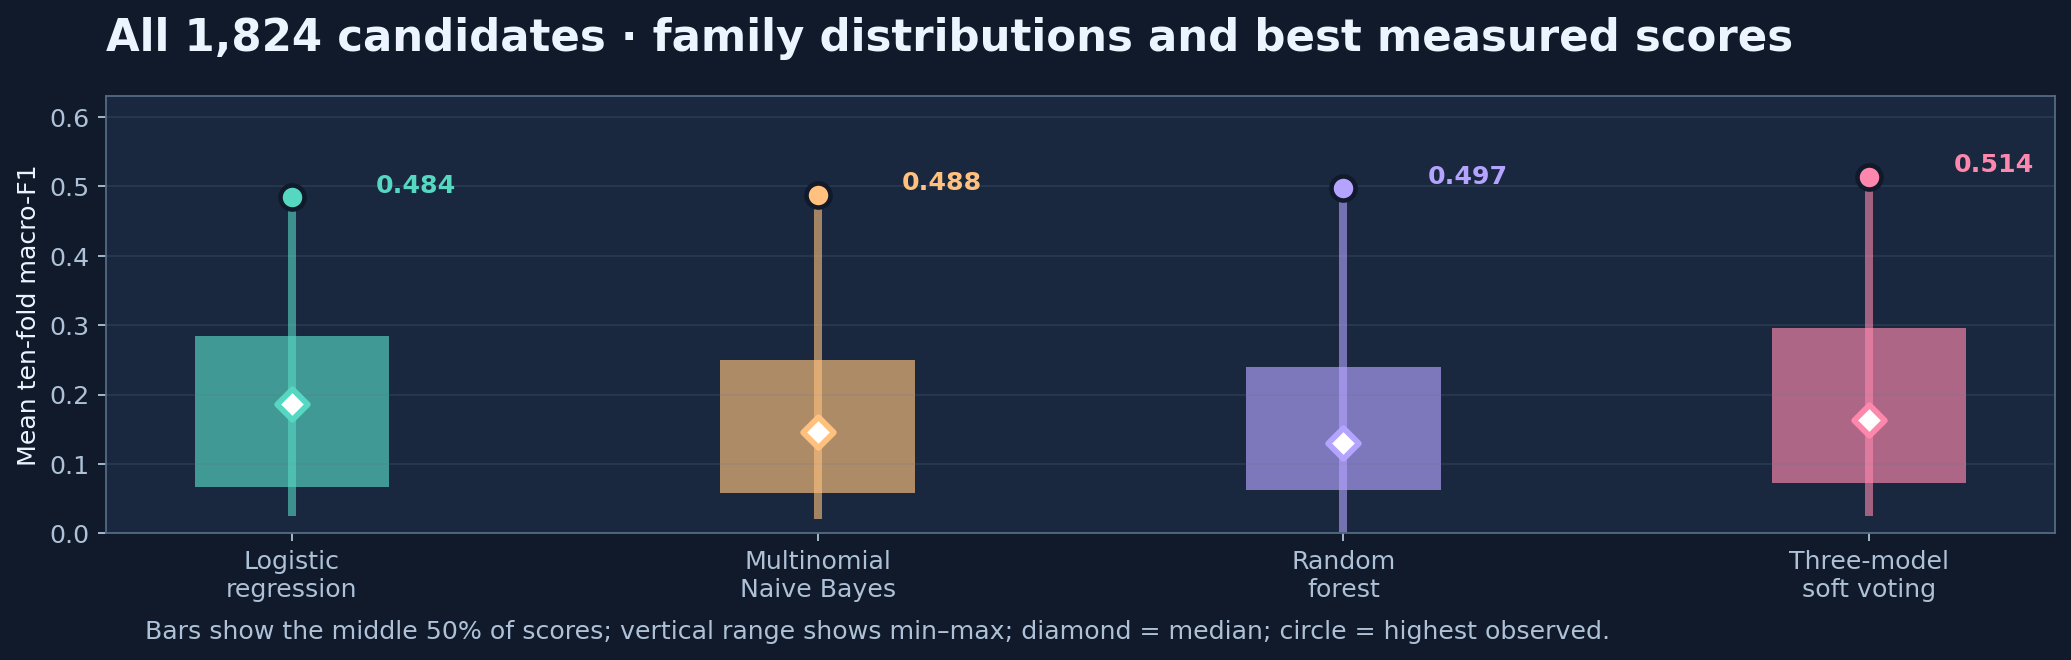

## Every path · 16 highest ranked examples, with all 1,824 rows above

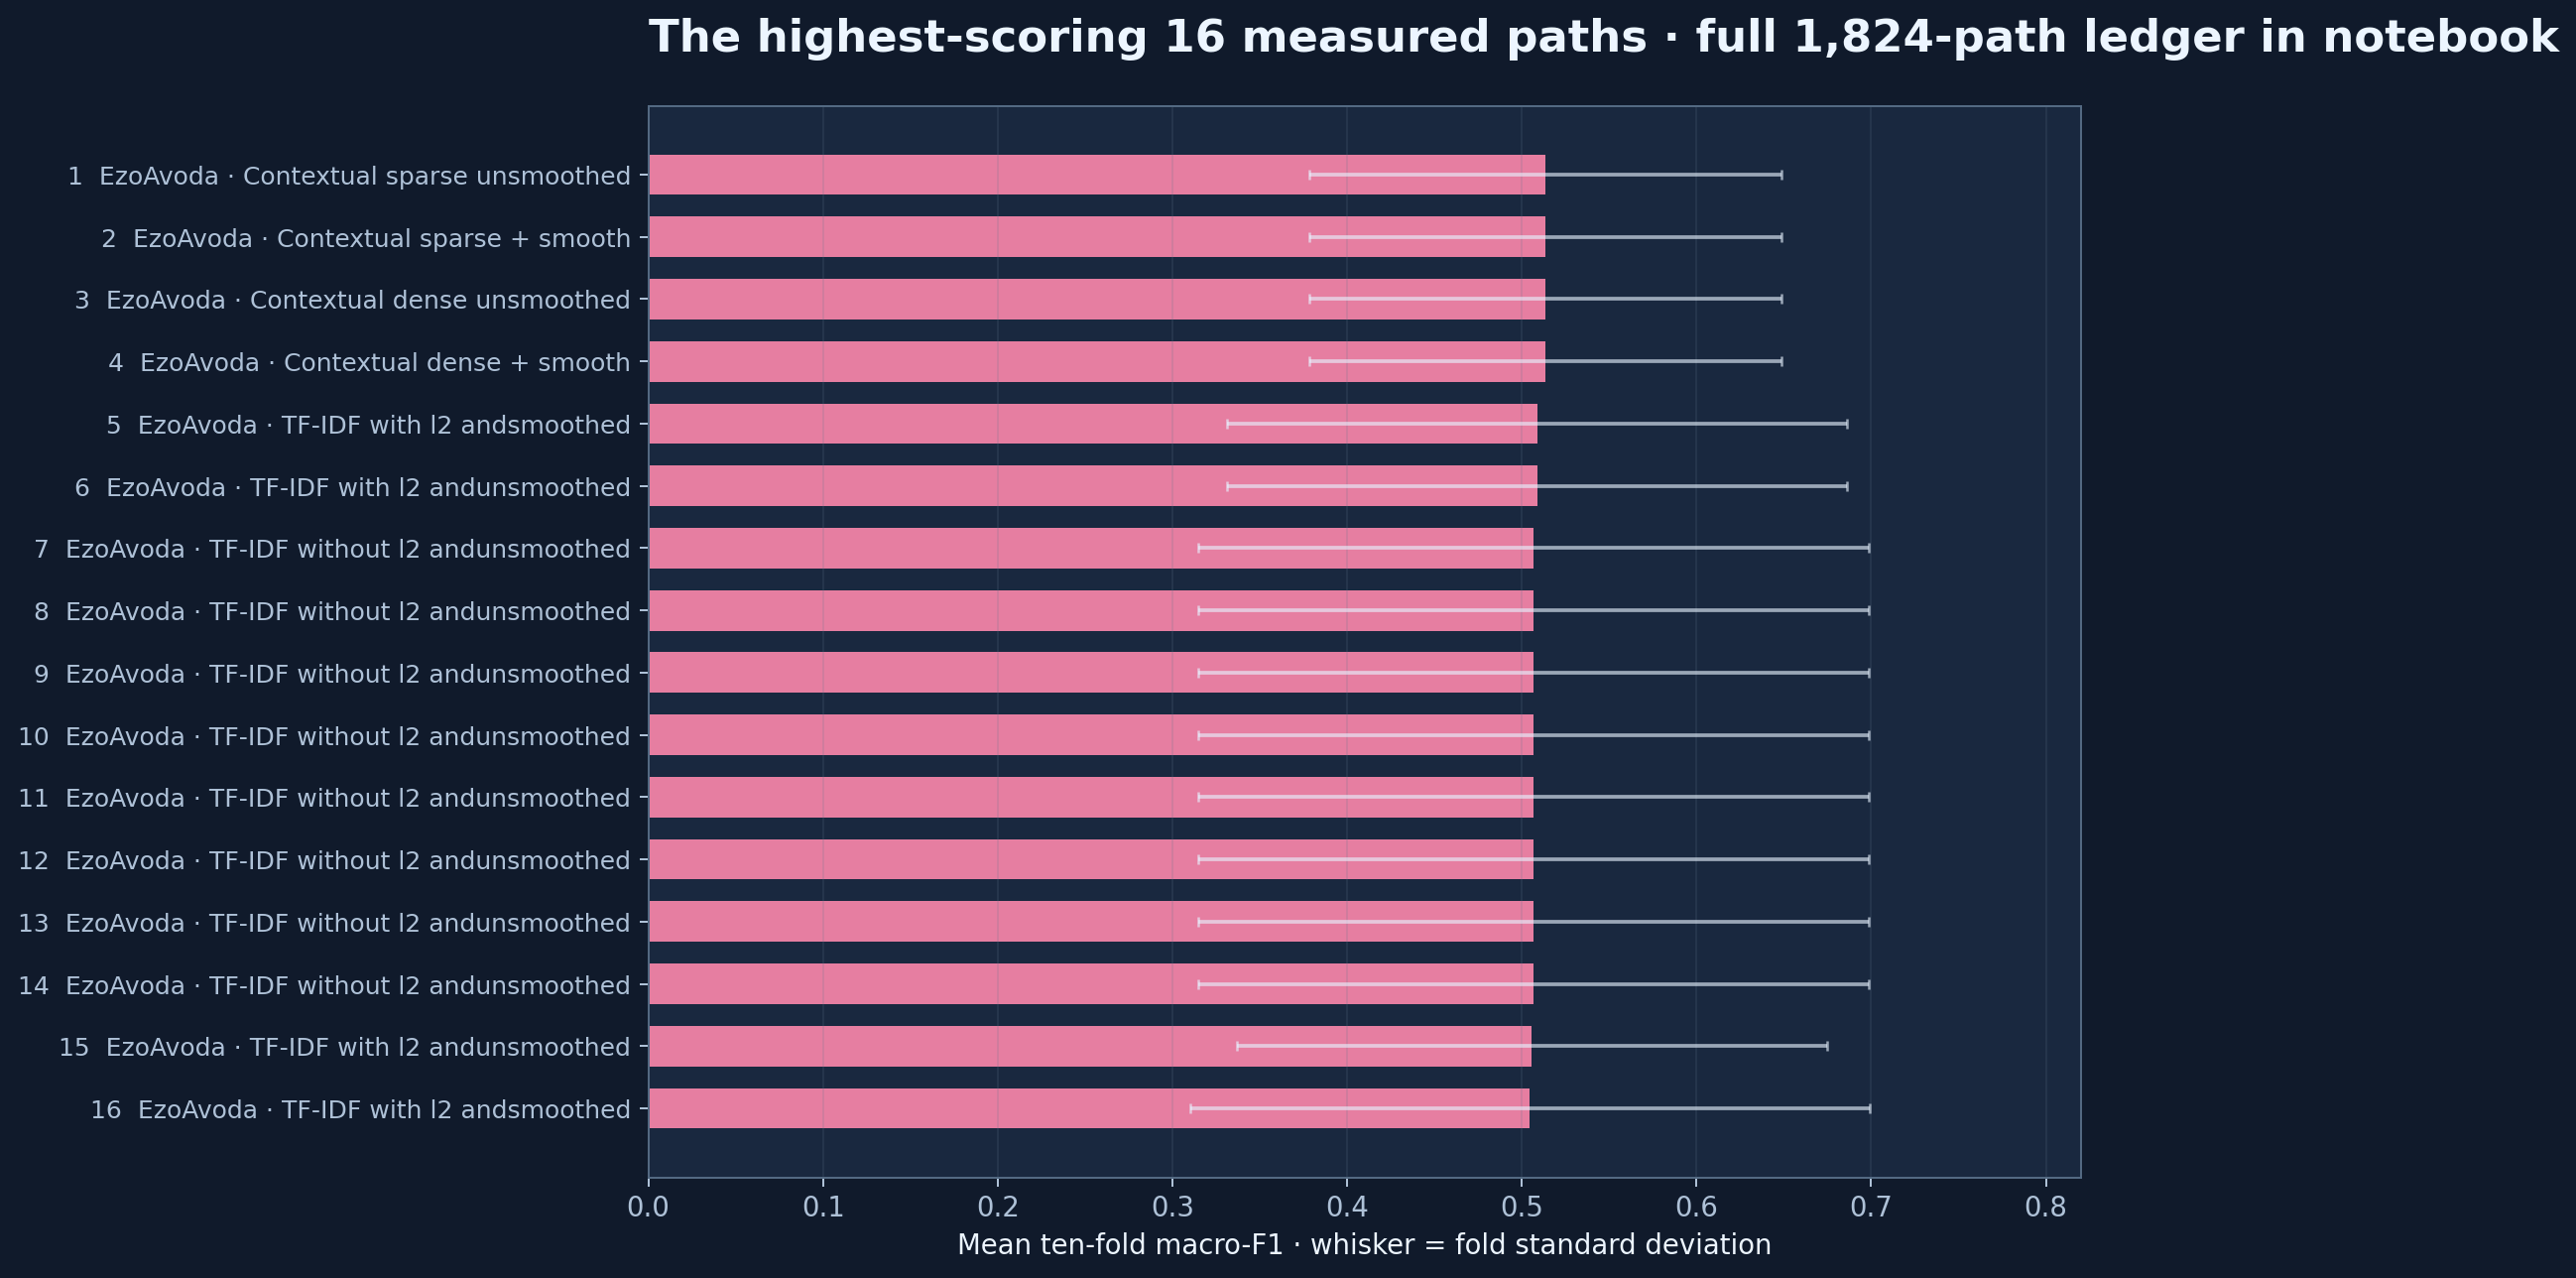

## All six text columns · four contextual-grouping curves per column

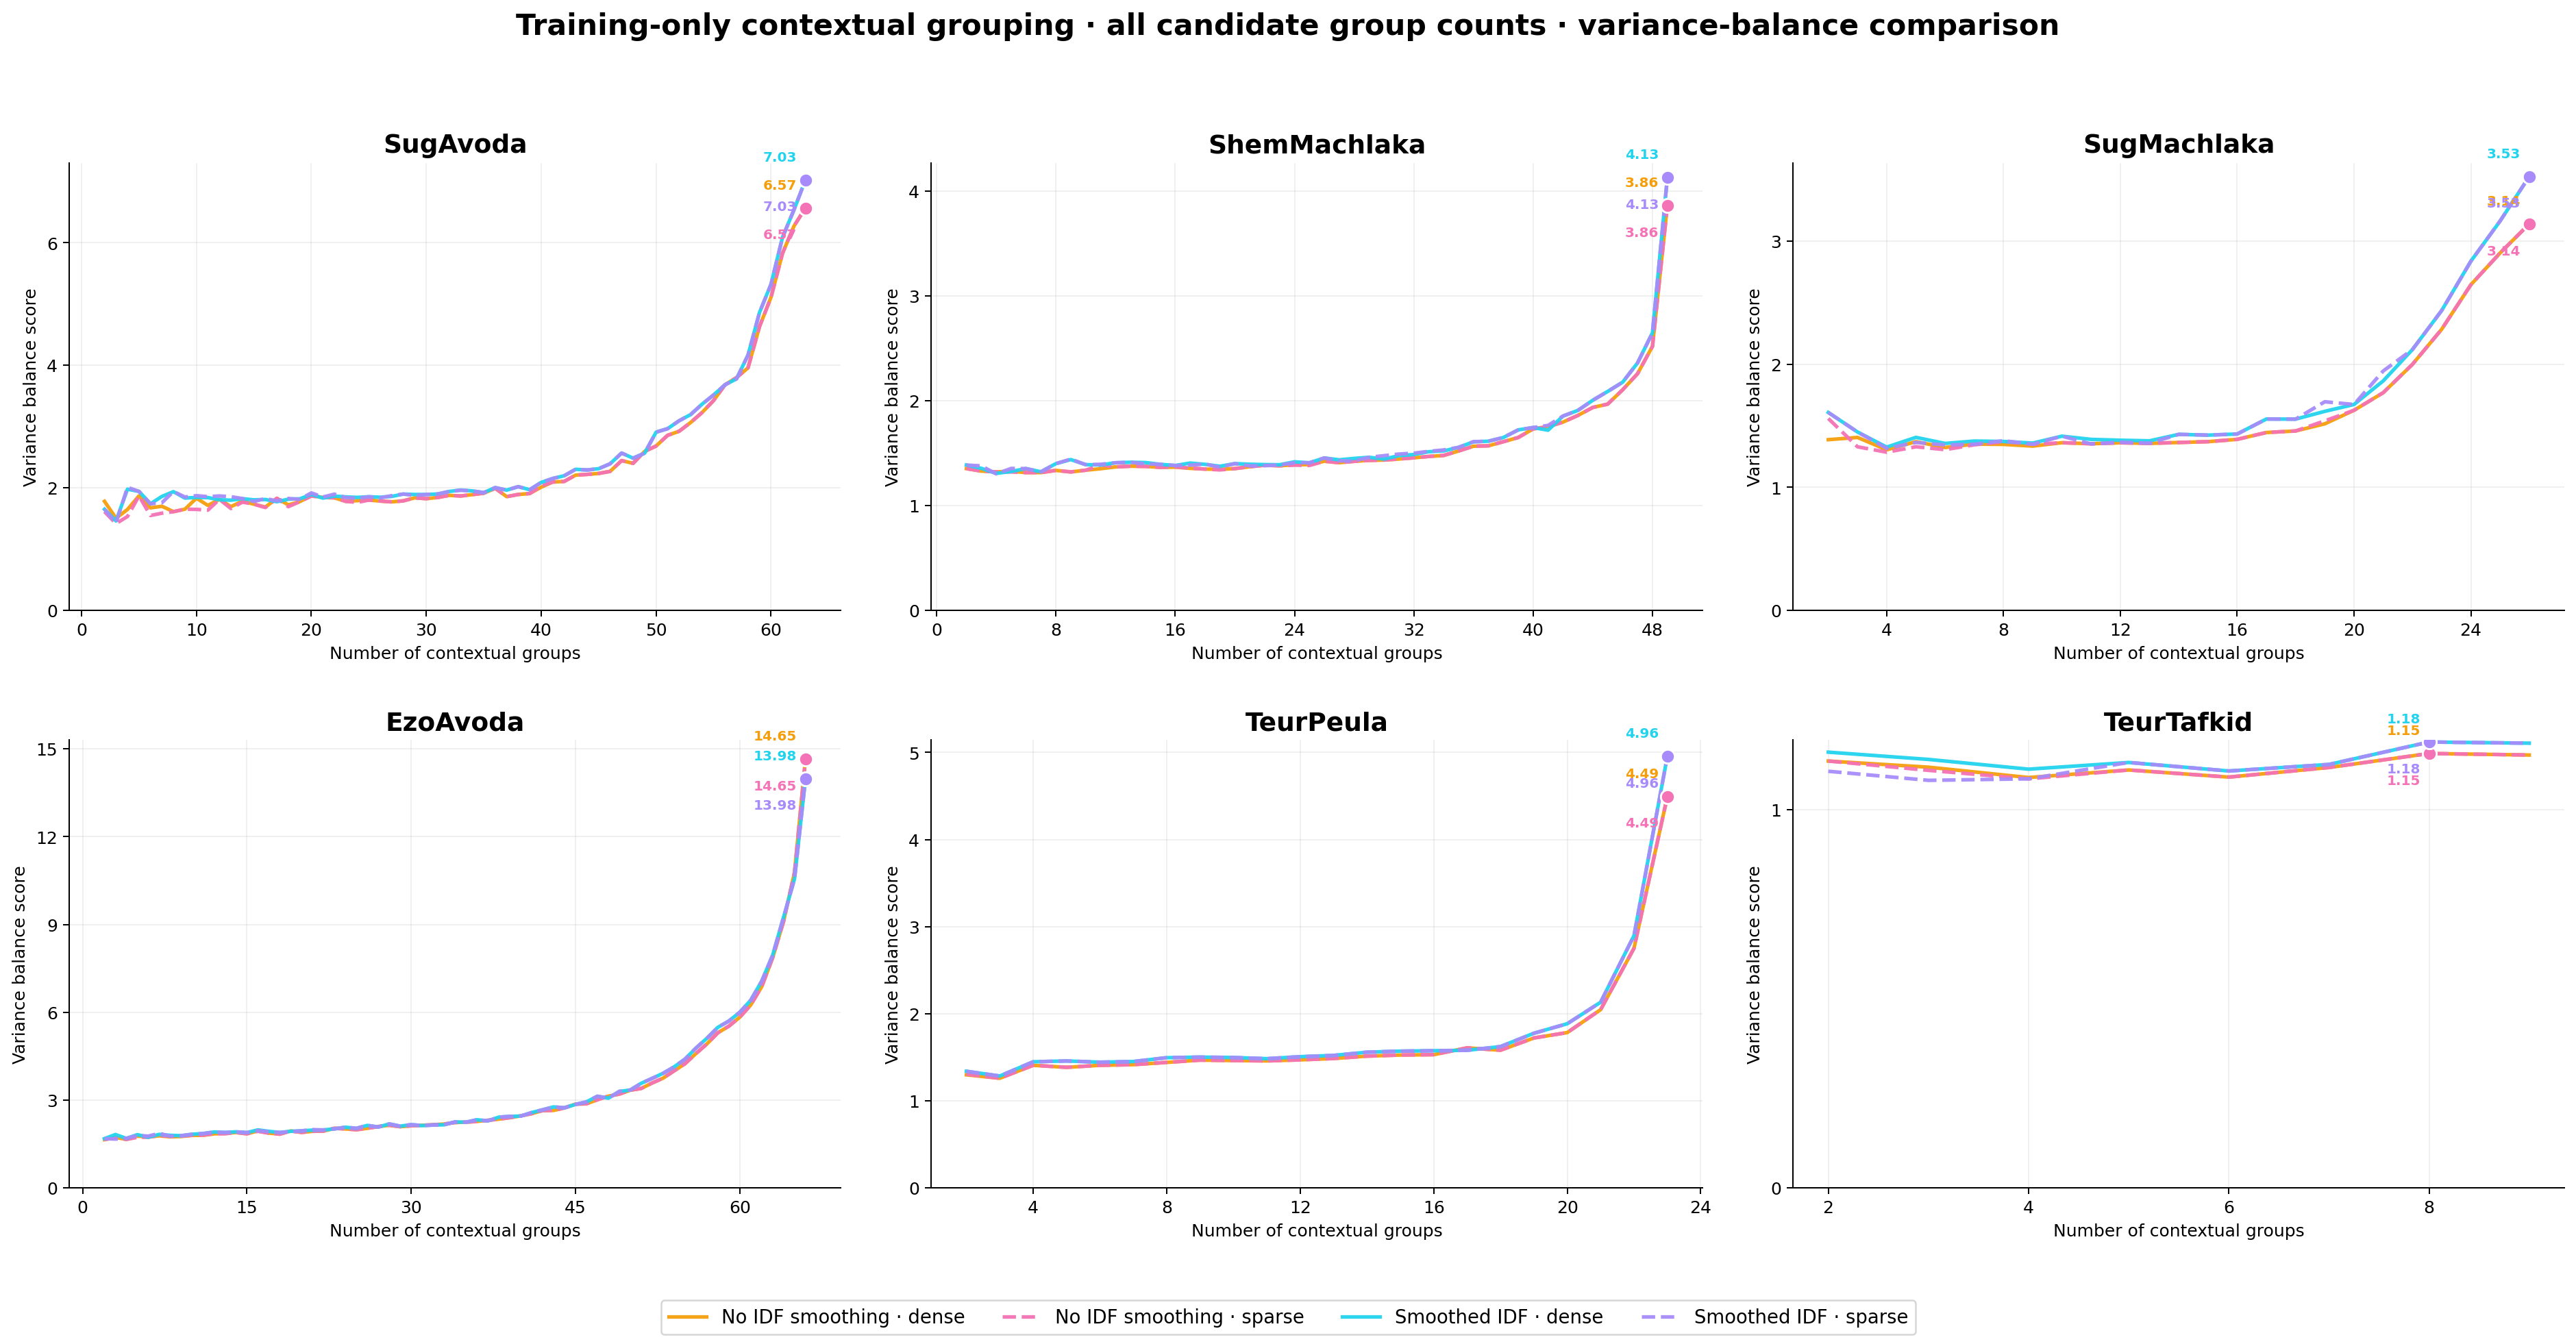

## Ten disjoint folds · winning ensemble compared against all three fitted components

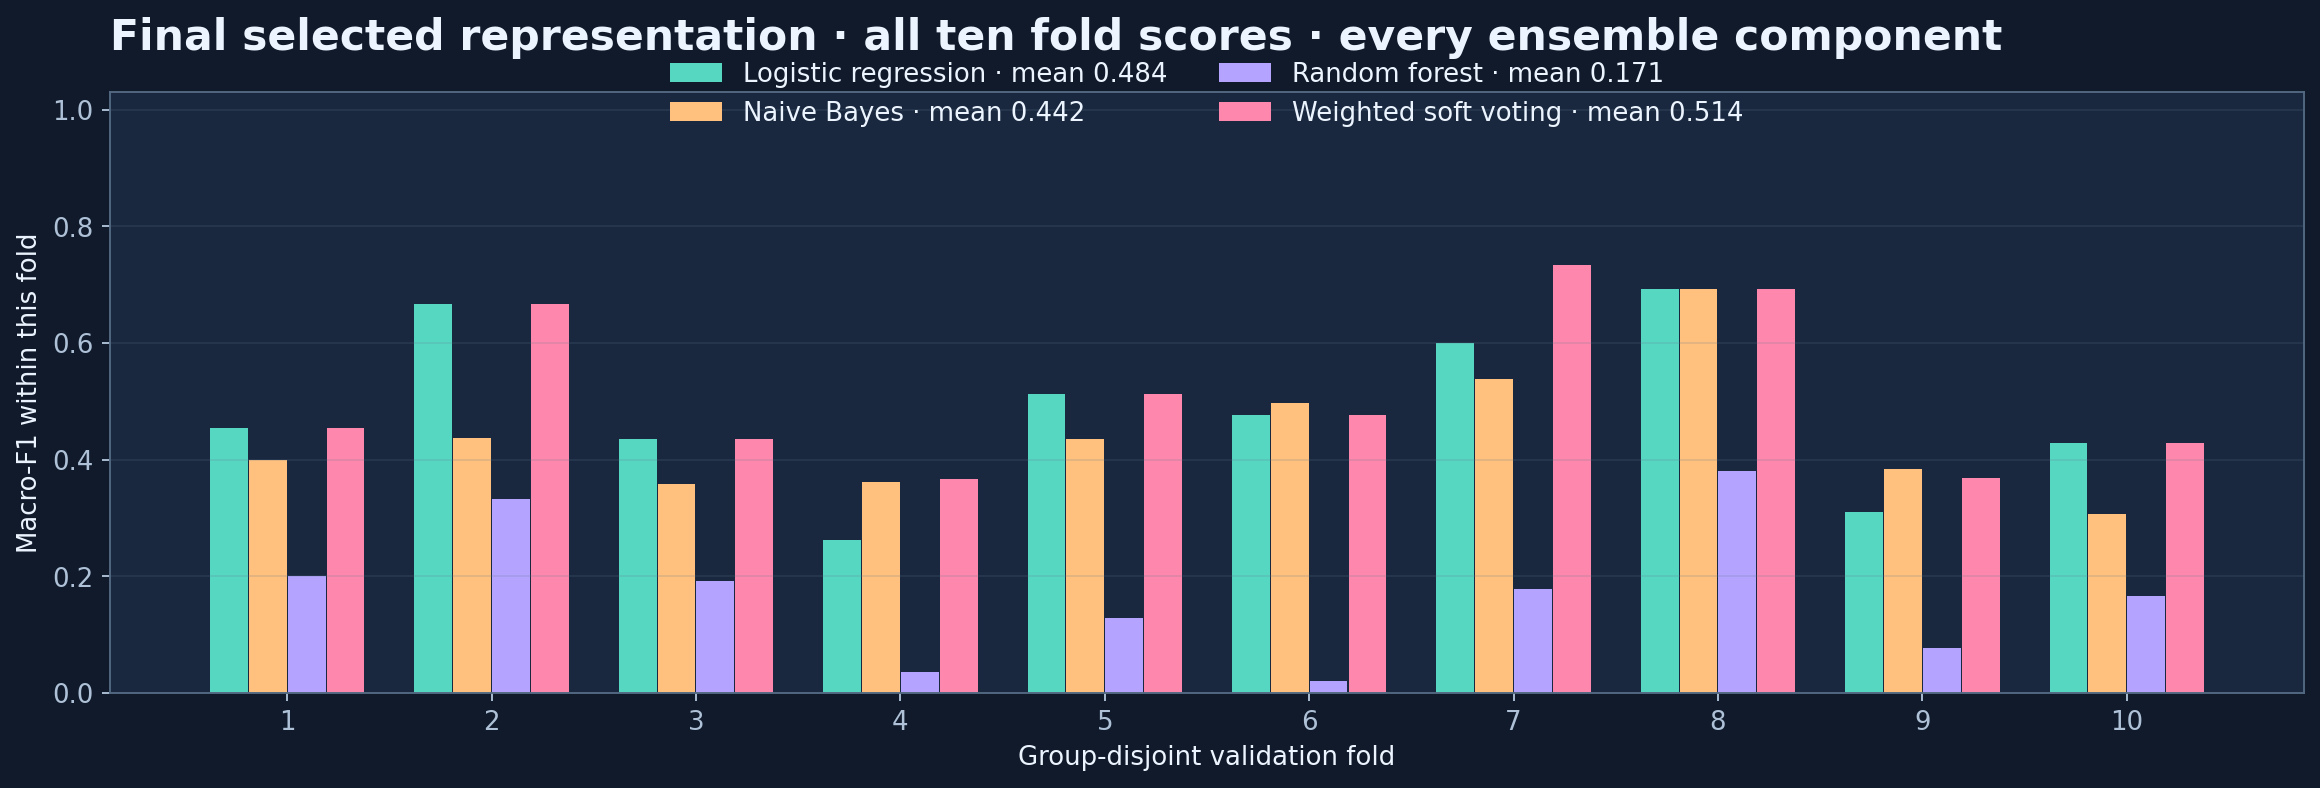

## Full-data refit · tested contextual-group counts and variance-balance scores

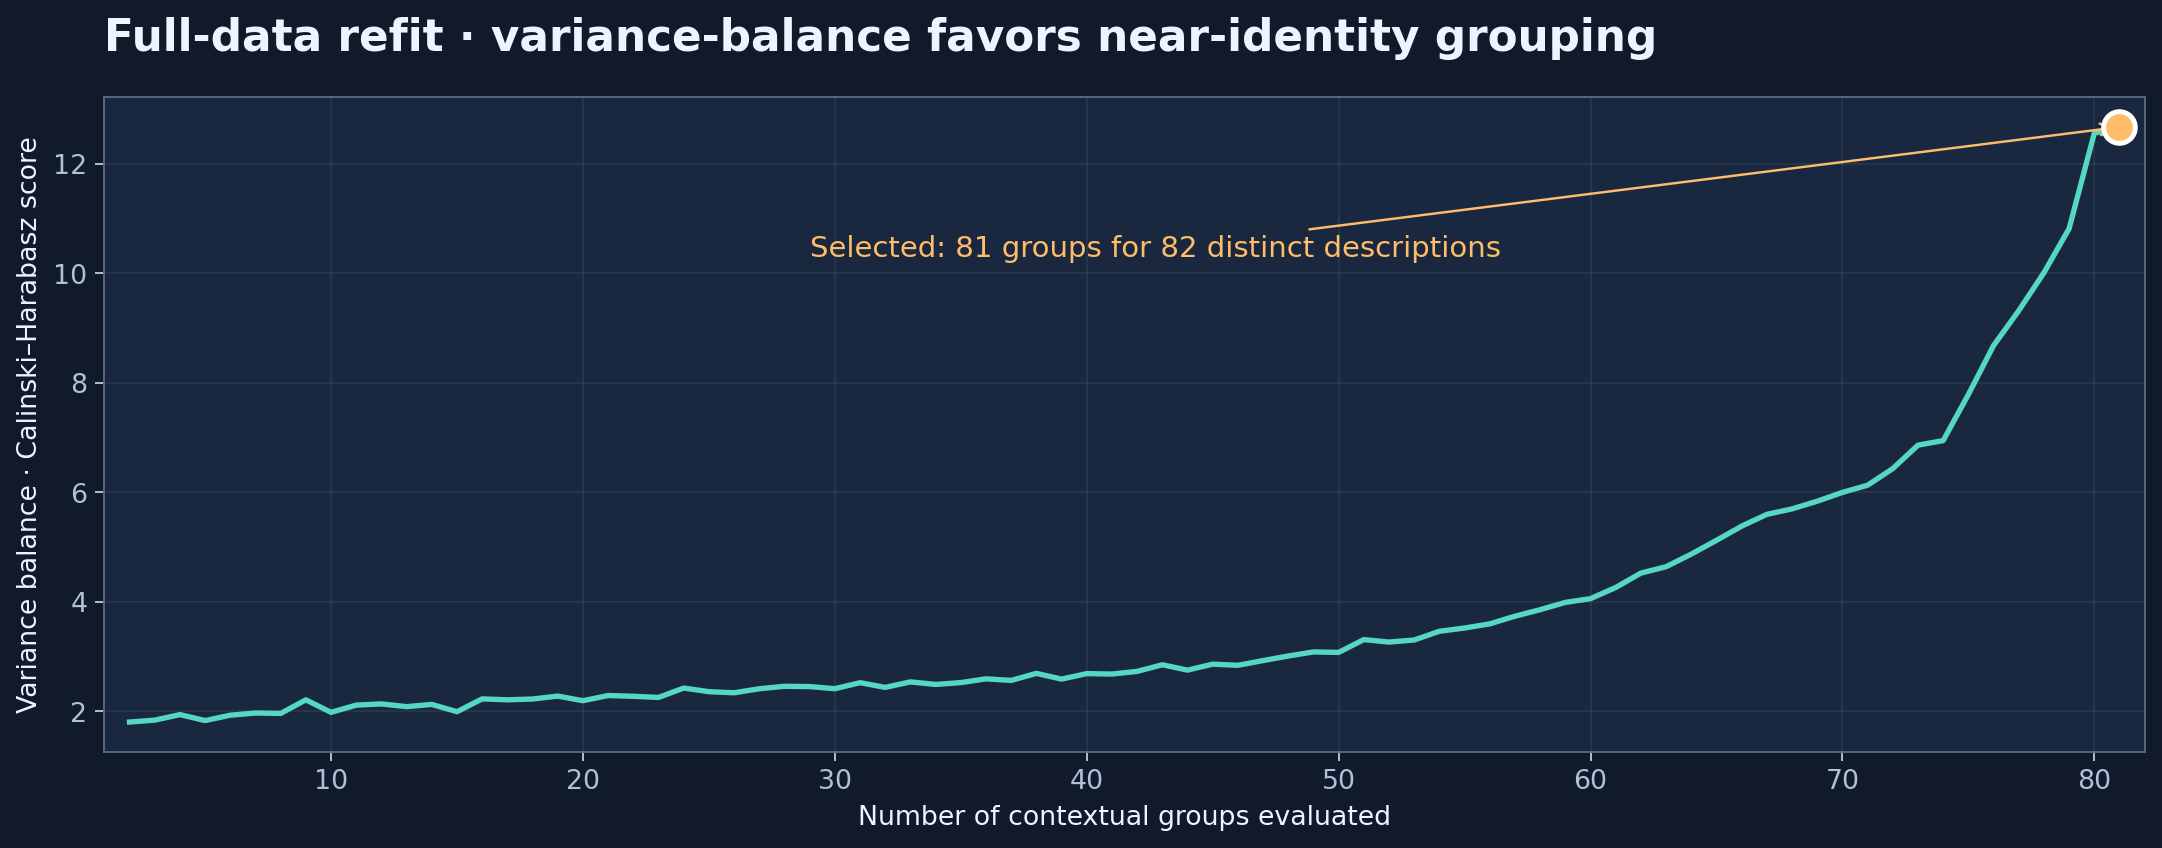

## Final human-review diagnostics · original known digits preserved

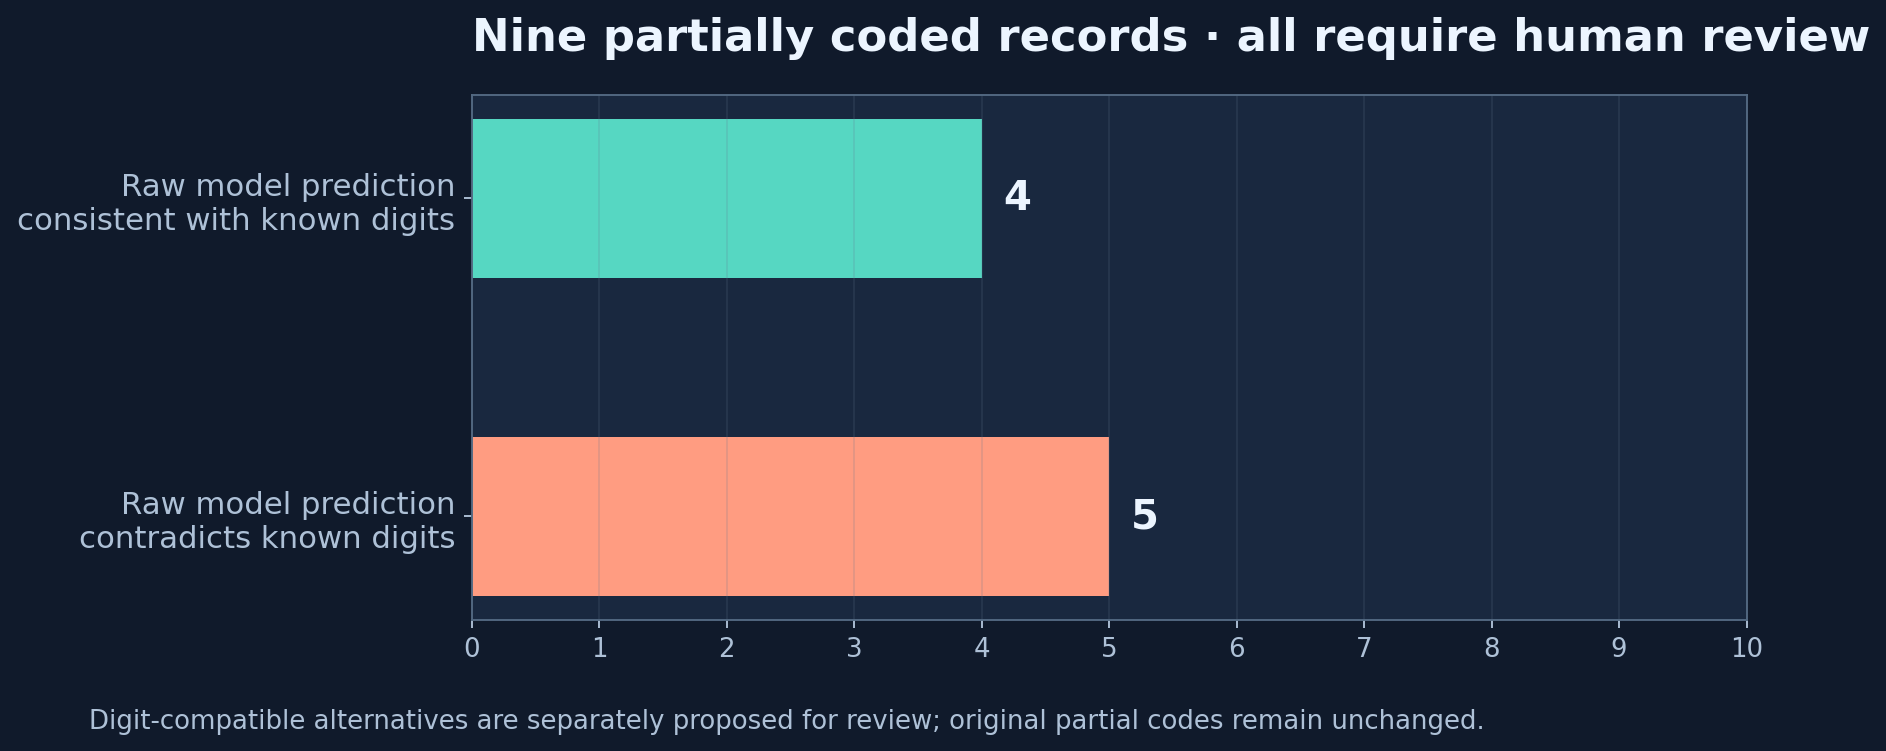

## The selected configuration · full evidence-based decision

**Selected independent text column:** `EzoAvoda`.

**Selected transformation:** unsmoothed, explicitly L2-normalized TF-IDF character vectors, stored sparsely for KMeans. Within each training fold, select the **optimal_number_of_contextual_groups** by maximization of the Calinski–Harabasz variance-balance criterion over every mathematically valid candidate. Represent the resulting contextual-group labels with one-hot encoding before fitting the supervised classifiers.

**Selected supervised model:** a **soft-voting ensemble of three different model types**, with these settings determined by training-only comparison:

| Component | Final selected hyperparameters | Soft-voting weight |
|---|---|---:|
| Logistic regression | `C=0.3`, balanced classes, `solver=lbfgs`, `max_iter=1000` | 2 |
| Multinomial Naive Bayes | `alpha=0.3` | 1 |
| Random forest | `n_estimators=48`, `min_samples_leaf=3`, balanced subsample, square-root feature selection | 1 |

**Ten-fold mean macro-F1:** `0.513605` (**fold standard deviation** `0.135108`). **Pooled out-of-fold macro-F1:** `0.385031`. These are distinct estimands and must not be equated.

**Frozen external holdout, 42 participants:** macro-F1 `0.433016`, macro-recall `0.455556`, accuracy `0.714286` (**30/42 correct**). The holdout did not enter selection. A fresh independent reproduction of the selected path's held-out predictions matched all 42 previously recorded predictions exactly.

The top four configurations tied on the mean-fold selection criterion. The sparse, unsmoothed configuration was chosen as the predetermined lower-memory, simpler representation among measured ties, **not** because it scored higher.

**Caution:** the final refit selects **81 groups from 82 distinct descriptions**, including 80 singleton groups. This is the mathematical optimum under the measured variance-balance criterion, **not** proof of useful semantic consolidation. The validation score is selection-biased, manual labels are not independently verified, and soft-voting probabilities are not calibrated.

## Final training · only after the training-only evaluation is fixed

The code below first fixes the decision **without inspecting holdout scores**, then reconstructs the selected text transformation and each of the three classifiers. It **fits anew on the original 149-record training split** to verify its 42 held-out predictions against the original experiment. Only after this confirmation does it **refit the complete selected representation and ensemble on all 191 fully labeled participant records**, and predict the nine incomplete codes.

The raw soft-voting prediction is kept unchanged for auditing. A **separate** digit-compatible suggestion is computed for human review, because five of the nine raw predictions contradict at least one existing non-`X` occupation-code digit. Neither version overwrites the original labels. Every prediction is marked for manual review. The displayed probabilities are **uncalibrated model scores, not reliable correctness probabilities**.

In [ ]:
from pathlib import Path
import json
import os

import numpy as np
import pandas as pd

from sklearn.ensemble import VotingClassifier


FINAL_RETRAINING_OUTPUT_DIRECTORY = Path(os.environ.get('CBS_OCCUPATION_FINAL_OUTPUT_DIRECTORY', 'occupational_classification_final_model_outputs'))
FINAL_RETRAINING_OUTPUT_DIRECTORY.mkdir(parents=True, exist_ok=True)

all_observed_candidate_scores = verified_experiment_evidence_tables['all_text_columns_all_encoding_paths_all_classifiers_all_hyperparameters_ten_fold_scores.csv'].copy()
all_observed_holdout_scores = verified_experiment_evidence_tables['every_classifier_and_ensemble_external_holdout_score.csv'].copy()
all_observed_holdout_predictions = verified_experiment_evidence_tables['every_external_holdout_prediction_for_every_candidate.csv.gz'].copy()


representation_tie_breaking_preferences = {
    'contextual_grouping_sparse_without_idf_smoothing': 0,
    'contextual_grouping_sparse_with_idf_smoothing': 1,
    'contextual_grouping_dense_without_idf_smoothing': 2,
    'contextual_grouping_dense_with_idf_smoothing': 3,
}

complete_model_selection_ledger = all_observed_candidate_scores.copy()
complete_model_selection_ledger['comparison_mean_macro_f1'] = complete_model_selection_ledger['mean_fold_macro_f1'].round(10)
complete_model_selection_ledger['comparison_mean_macro_recall'] = complete_model_selection_ledger['mean_fold_macro_recall'].round(10)
complete_model_selection_ledger['comparison_fold_macro_f1_deviation'] = complete_model_selection_ledger['std_fold_macro_f1'].round(10)
complete_model_selection_ledger['representation_tie_break_priority'] = complete_model_selection_ledger['representation_path'].map(representation_tie_breaking_preferences).fillna(4)

complete_model_selection_ledger = complete_model_selection_ledger.sort_values(
    ['comparison_mean_macro_f1', 'comparison_mean_macro_recall', 'comparison_fold_macro_f1_deviation', 'representation_tie_break_priority', 'occupational_text_column', 'representation_path', 'classifier_candidate_name'],
    ascending=[False, False, True, True, True, True, True],
    kind='stable',
).reset_index(drop=True)

complete_model_selection_ledger.insert(0, 'training_only_selection_rank', np.arange(1, len(complete_model_selection_ledger) + 1))
training_selected_candidate = complete_model_selection_ledger.iloc[0]


selected_occupational_text_column = training_selected_candidate['occupational_text_column']
selected_representation_name = training_selected_candidate['representation_path']
selected_model_candidate_name = training_selected_candidate['classifier_candidate_name']
selected_ensemble_weighting_name = training_selected_candidate['soft_voting_weights']

selected_representation_configuration = next(configuration for configuration in EVALUATED_TEXT_ENCODING_PATHS if configuration['path_name'] == selected_representation_name)
selected_ensemble_weighting_configuration = next(configuration for configuration in EVALUATED_SOFT_VOTING_WEIGHT_COMBINATIONS if configuration['weight_name'] == selected_ensemble_weighting_name)

selected_ensemble_member_configurations = [
    configuration
    for classifier_family in ['logistic_regression', 'multinomial_naive_bayes', 'random_forest']
    for configuration in CANDIDATES_BY_MODEL_TYPE[classifier_family]
    if configuration['candidate_name'] in selected_model_candidate_name
]

assert len(selected_ensemble_member_configurations) == 3
assert selected_model_candidate_name == 'soft_voting__' + '__'.join(configuration['candidate_name'] for configuration in selected_ensemble_member_configurations) + '__' + selected_ensemble_weighting_name


def fit_selected_ensemble_with_a_fresh_independent_representation(training_descriptions, training_labels, prediction_descriptions):
    transformed_training_descriptions, transformed_prediction_descriptions, evaluated_grouping_candidates, optimal_number_of_contextual_groups = transform_single_description_column_using_training_only_fits(
        selected_occupational_text_column,
        selected_representation_configuration,
        training_descriptions,
        prediction_descriptions,
    )

    ensemble_member_models = [
        (configuration['model_name'], build_classification_model_for_explicit_hyperparameters(configuration))
        for configuration in selected_ensemble_member_configurations
    ]

    selected_soft_voting_classifier = VotingClassifier(
        estimators=ensemble_member_models,
        voting='soft',
        weights=selected_ensemble_weighting_configuration['weights'],
        n_jobs=1,
    )

    selected_soft_voting_classifier.fit(transformed_training_descriptions, training_labels)

    predicted_codes = selected_soft_voting_classifier.predict(transformed_prediction_descriptions)
    predicted_class_probabilities = selected_soft_voting_classifier.predict_proba(transformed_prediction_descriptions)

    return {
        'trained_classifier': selected_soft_voting_classifier,
        'predicted_codes': predicted_codes,
        'predicted_probabilities': predicted_class_probabilities,
        'transformed_training_descriptions': transformed_training_descriptions,
        'transformed_prediction_descriptions': transformed_prediction_descriptions,
        'evaluated_grouping_candidates': evaluated_grouping_candidates,
        'optimal_number_of_contextual_groups': optimal_number_of_contextual_groups,
    }


holdout_model_reverification = fit_selected_ensemble_with_a_fresh_independent_representation(
    training_model_inputs,
    training_occupation_codes,
    external_holdout_model_inputs,
)

observed_holdout_scores = calculate_full_classification_metrics(
    external_holdout_occupation_codes.to_numpy(),
    holdout_model_reverification['predicted_codes'],
)

selected_holdout_experiment_record = all_observed_holdout_scores.loc[
    all_observed_holdout_scores['occupational_text_column'].eq(selected_occupational_text_column)
    & all_observed_holdout_scores['representation_path'].eq(selected_representation_name)
    & all_observed_holdout_scores['classifier_candidate_name'].eq(selected_model_candidate_name)
]

assert len(selected_holdout_experiment_record) == 1

for metric_name, recorded_metric_value in selected_holdout_experiment_record.iloc[0][['macro_recall', 'macro_f1', 'accuracy', 'macro_precision']].items():
    np.testing.assert_allclose(observed_holdout_scores[metric_name], recorded_metric_value, atol=1e-12, rtol=1e-12)


selected_holdout_experiment_predictions = all_observed_holdout_predictions.loc[
    all_observed_holdout_predictions['occupational_text_column'].eq(selected_occupational_text_column)
    & all_observed_holdout_predictions['representation_path'].eq(selected_representation_name)
    & all_observed_holdout_predictions['classifier_candidate_name'].eq(selected_model_candidate_name)
]

holdout_participant_ids = completely_labeled_participant_records.iloc[external_holdout_row_positions]['ID'].astype(int).to_numpy()
recorded_predictions_by_participant_id = selected_holdout_experiment_predictions.set_index('participant_id')['predicted_occupation_code'].astype(str)
verified_recorded_holdout_predictions = recorded_predictions_by_participant_id.loc[holdout_participant_ids].to_numpy()

assert len(selected_holdout_experiment_predictions) == len(holdout_participant_ids)
np.testing.assert_array_equal(holdout_model_reverification['predicted_codes'].astype(str), verified_recorded_holdout_predictions)


partial_record_inputs = prepare_occupation_model_features(partially_labeled_participant_records)

final_retrained_ensemble = fit_selected_ensemble_with_a_fresh_independent_representation(
    all_labeled_model_inputs,
    all_labeled_occupation_codes,
    partial_record_inputs,
)

final_ensemble_model = final_retrained_ensemble['trained_classifier']
final_ensemble_predictions = final_retrained_ensemble['predicted_codes'].astype(str)


def model_code_consistent_with_existing_partial_code(existing_partial_code, proposed_complete_code):
    existing_characters = str(existing_partial_code).upper()
    predicted_characters = str(proposed_complete_code).upper()

    return len(existing_characters) == len(predicted_characters) and all(existing_character == 'X' or existing_character == predicted_character for existing_character, predicted_character in zip(existing_characters, predicted_characters))


original_partial_occupation_codes = partially_labeled_participant_records[OCCUPATION_CLASSIFICATION_TARGET_COLUMN].astype(str).to_numpy()
final_prediction_confidence_uncalibrated = final_retrained_ensemble['predicted_probabilities'].max(axis=1)
final_existing_digits_preserved = [model_code_consistent_with_existing_partial_code(previously_assigned_code, model_suggestion) for previously_assigned_code, model_suggestion in zip(original_partial_occupation_codes, final_ensemble_predictions)]

final_human_review_suggestions = pd.DataFrame({
    'participant_id': partially_labeled_participant_records['ID'].astype(int).to_numpy(),
    'original_partial_occupation_code': original_partial_occupation_codes,
    'final_retrained_soft_voting_ensemble_prediction': final_ensemble_predictions,
    'agrees_with_all_known_original_digits': final_existing_digits_preserved,
    'maximum_uncalibrated_class_probability': final_prediction_confidence_uncalibrated,
    'operational_disposition': 'human_coder_review_required',
})


compatible_code_suggestions = []
compatible_code_candidate_counts = []
compatible_code_unnormalized_scores = []

for original_partial_occupation_code, predicted_class_probabilities in zip(original_partial_occupation_codes, final_retrained_ensemble['predicted_probabilities']):
    compatible_complete_codes = np.array([model_code_consistent_with_existing_partial_code(original_partial_occupation_code, complete_code) for complete_code in final_ensemble_model.classes_], dtype=bool)
    compatible_code_candidate_counts.append(int(np.sum(compatible_complete_codes)))

    if compatible_complete_codes.any():
        compatible_class_indices = np.flatnonzero(compatible_complete_codes)
        highest_scoring_compatible_class_index = compatible_class_indices[np.argmax(predicted_class_probabilities[compatible_class_indices])]
        compatible_code_suggestions.append(str(final_ensemble_model.classes_[highest_scoring_compatible_class_index]))
        compatible_code_unnormalized_scores.append(float(predicted_class_probabilities[highest_scoring_compatible_class_index]))
    else:
        compatible_code_suggestions.append(None)
        compatible_code_unnormalized_scores.append(float('nan'))


final_human_review_suggestions['suggested_code_respecting_existing_digits_for_review'] = compatible_code_suggestions
final_human_review_suggestions['number_of_training_codes_compatible_with_existing_digits'] = compatible_code_candidate_counts
final_human_review_suggestions['uncalibrated_score_of_digit_compatible_suggestion'] = compatible_code_unnormalized_scores

for model_configuration, fitted_member_classifier in zip(selected_ensemble_member_configurations, final_ensemble_model.estimators_):
    final_human_review_suggestions[model_configuration['model_name'] + '_prediction'] = final_ensemble_model.le_.inverse_transform(fitted_member_classifier.predict(final_retrained_ensemble['transformed_prediction_descriptions']))


final_selection_evidence = {
    'selection_source': 'all training-only grouped ten-fold validation summaries, not external holdout',
    'candidate_count': len(complete_model_selection_ledger),
    'training_only_selection_rank': int(training_selected_candidate['training_only_selection_rank']),
    'selected_occupational_text_column': selected_occupational_text_column,
    'selected_text_representation': selected_representation_name,
    'selected_model_type': str(training_selected_candidate['model_name']),
    'selected_model_identifier': selected_model_candidate_name,
    'soft_voting_member_classifier_settings': {configuration['model_name']: configuration['parameters'] for configuration in selected_ensemble_member_configurations},
    'selected_voting_weights': dict(zip([configuration['model_name'] for configuration in selected_ensemble_member_configurations], selected_ensemble_weighting_configuration['weights'])),
    'training_only_validation_mean_macro_f1': float(training_selected_candidate['mean_fold_macro_f1']),
    'training_only_validation_macro_f1_standard_deviation': float(training_selected_candidate['std_fold_macro_f1']),
    'training_only_validation_pooled_macro_f1': float(training_selected_candidate['macro_f1']),
    'frozen_external_holdout_reverification': observed_holdout_scores,
    'number_of_external_holdout_records': len(external_holdout_occupation_codes),
    'external_holdout_correct_predictions': int(np.sum(holdout_model_reverification['predicted_codes'].astype(str) == external_holdout_occupation_codes.to_numpy().astype(str))),
    'final_retraining_number_of_complete_labeled_records': len(all_labeled_occupation_codes),
    'number_of_partial_codes_for_human_review': len(final_human_review_suggestions),
    'selected_group_count_149_training_only': int(holdout_model_reverification['optimal_number_of_contextual_groups']),
    'selected_group_count_191_full_refit': int(final_retrained_ensemble['optimal_number_of_contextual_groups']),
    'number_of_partial_codes_consistent_with_raw_model_prediction': int(sum(final_existing_digits_preserved)),
    'number_of_digit_compatible_human_review_suggestions': int(sum(suggestion is not None for suggestion in compatible_code_suggestions)),
    'historical_original_model_preserved': True,
    'probabilities_verified_as_calibrated': False,
    'possible_overfitting_from_reusing_cv_for_hyperparameter_and_model_selection': True,
    'data_source_is_simulated': True,
}

complete_model_selection_ledger.to_csv(FINAL_RETRAINING_OUTPUT_DIRECTORY / 'every_candidate_training_only_ranking.csv', index=False, encoding='utf-8-sig')
final_human_review_suggestions.to_csv(FINAL_RETRAINING_OUTPUT_DIRECTORY / 'final_retrained_model_all_partial_record_predictions.csv', index=False, encoding='utf-8-sig')

pd.DataFrame(holdout_model_reverification['evaluated_grouping_candidates']).to_csv(FINAL_RETRAINING_OUTPUT_DIRECTORY / 'final_selected_contextual_group_search_on_149_training_records.csv', index=False, encoding='utf-8-sig')
pd.DataFrame(final_retrained_ensemble['evaluated_grouping_candidates']).to_csv(FINAL_RETRAINING_OUTPUT_DIRECTORY / 'final_selected_contextual_group_search_on_all_191_labeled_records.csv', index=False, encoding='utf-8-sig')

(FINAL_RETRAINING_OUTPUT_DIRECTORY / 'final_selected_model_selection_and_retraining_evidence.json').write_text(json.dumps(final_selection_evidence, ensure_ascii=False, indent=2), encoding='utf-8')

print('FINAL SELECTION AND RE-TRAINING VERIFICATION')
print(json.dumps(final_selection_evidence, ensure_ascii=False, indent=2))
print(final_human_review_suggestions.to_string(index=False))


## Verified final predictions and model-readiness assessment

The following table is the actual output of the **final retrained three-model voting ensemble** fitted on all **191 fully labeled records**. It retains original partially coded values, raw classifier predictions, digit-compatible alternatives, model-component predictions, and review flags. It is also produced programmatically by the training cell above.

The final model is a **research submission**, not a production-authorized coder. The dataset is simulated, classification truth is imperfect and sparsely sampled, and a review process is mandatory before applying any predicted code.

### All nine final full-data predictions · raw and digit-consistent alternatives

|   participant_id | original_partial_occupation_code   |   final_retrained_soft_voting_ensemble_prediction |   suggested_code_respecting_existing_digits_for_review | agrees_with_all_known_original_digits   | operational_disposition     |
|-----------------:|:-----------------------------------|--------------------------------------------------:|-------------------------------------------------------:|:----------------------------------------|:----------------------------|
|               18 | 1XXX                               |                                              2511 |                                                   1212 | False                                   | human_coder_review_required |
|               45 | XXXX                               |                                              2511 |                                                   2511 | True                                    | human_coder_review_required |
|               50 | 1XXX                               |                                              2511 |                                                   1212 | False                                   | human_coder_review_required |
|               81 | 1XXX                               |                                              2511 |                                                   1212 | False                                   | human_coder_review_required |
|              108 | XXXX                               |                                              2511 |                                                   2511 | True                                    | human_coder_review_required |
|              113 | 1XXX                               |                                              2511 |                                                   1212 | False                                   | human_coder_review_required |
|              142 | XXXX                               |                                              2511 |                                                   2511 | True                                    | human_coder_review_required |
|              165 | 335X                               |                                              4211 |                                                   3354 | False                                   | human_coder_review_required |
|              193 | XXXX                               |                                              2511 |                                                   2511 | True                                    | human_coder_review_required |

## Completion and reproducibility audit

The original workbook and earlier V5/V6 experiments remain unchanged. The final selection and retraining are appended only after the complete comparison. The in-notebook compressed evidence archive contains **all original candidate paths and fold-level records**, so investigating a weak or unsuccessful path never requires guessing what was omitted.

**Source trace:** original metadata and survey workbook with verified SHA-256, six column-independent representations with a ten-fold grouped evaluation, 38 distinct classifier/ensemble candidates per representation, fold-level score and prediction exports, all contextual group-count searches, immutable selection ranking and final full-data refitting.

**Technical limitations:** class rarity prevents reliable interpretation of some individual fold macro scores. Grouping based on description signatures is not verified participant-identity linkage. The variance-balance optimum does not guarantee semantic usefulness. Three-model probability averaging is not a calibrated probability estimate. The same folds used for hyperparameter selection create optimistic winner estimates. A separate execution in the hosted Google Colab service has not been performed; the execution and re-verification described here were performed locally using scikit-learn.

## Extended multiclass experiment · individual and ensemble comparison

Each text column is evaluated independently. Every classifier predicts nominal occupation-code labels. Existing V7 results and source-code cells remain unchanged. The extended study uses ten grouped folds, seed 42 and at most five tuned hyperparameters with at most three values each.

## Execution coverage

Eight individual classifier families were trained and scored. TensorFlow/Keras, H2O and Spark are excluded from measured rankings because their runtimes were unavailable, not because their results were poor. The source metadata and assignment workbook remain unchanged.

In [ ]:
display(pd.DataFrame([{'Classifier': 'TensorFlow / Keras softmax network', 'Status': 'Not evaluated', 'Reason': 'TensorFlow unavailable in the execution runtime'}, {'Classifier': 'H2OGradientBoostingEstimator', 'Status': 'Not evaluated', 'Reason': 'H2O unavailable in the execution runtime'}, {'Classifier': 'H2ORandomForestEstimator', 'Status': 'Not evaluated', 'Reason': 'H2O unavailable in the execution runtime'}, {'Classifier': 'Spark RandomForestClassifier', 'Status': 'Not evaluated', 'Reason': 'PySpark unavailable in the execution runtime'}, {'Classifier': 'Spark MultilayerPerceptronClassifier', 'Status': 'Not evaluated', 'Reason': 'PySpark unavailable in the execution runtime'}]))

Classifier,Status,Reason
TensorFlow / Keras softmax network,Not evaluated,TensorFlow unavailable in the execution runtime
H2OGradientBoostingEstimator,Not evaluated,H2O unavailable in the execution runtime
H2ORandomForestEstimator,Not evaluated,H2O unavailable in the execution runtime
Spark RandomForestClassifier,Not evaluated,PySpark unavailable in the execution runtime
Spark MultilayerPerceptronClassifier,Not evaluated,PySpark unavailable in the execution runtime


## Independent classifier search · reproducible implementation

The following function fits each of the eight classifier families independently on the requested text column. Every transformation is fitted inside its validation fold. Run the function for any of the six columns to regenerate its exhaustive experiment ledger. Computationally intensive operations are invoked explicitly.

In [ ]:
from scipy.sparse import issparse
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.model_selection import StratifiedGroupKFold, ParameterSampler
from sklearn.metrics import f1_score, recall_score, accuracy_score, precision_score
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
import torch

def reproduce_independent_multiclass_comparison(text_column_name, output_directory=Path("classification_results")):
    independent_occupational_text_column = text_column_name
    OUTPUT_FOLDER = Path(output_directory) / text_column_name
    OUTPUT_FOLDER.mkdir(parents=True, exist_ok=True)

    training_occupation_labels = training_occupation_codes.astype(str).to_numpy()
    all_training_occupation_classes = sorted(np.unique(training_occupation_labels))
    global_class_positions = {occupation_code: position for position, occupation_code in enumerate(all_training_occupation_classes)}
    validation_fold_positions = list(StratifiedGroupKFold(n_splits=10, shuffle=True, random_state=42).split(training_model_inputs, training_occupation_labels, training_description_groups))

    model_parameter_spaces = {
        'RandomForestClassifier': {
            'n_estimators': [20, 50, 100],
            'max_depth': [3, 5, 8],
            'min_samples_split': [2, 3, 4],
            'min_samples_leaf': [1, 2, 3],
            'max_features': ['sqrt', 'log2', 1.0],
        },
        'HistGradientBoostingClassifier': {
            'max_iter': [20, 50, 100],
            'max_depth': [3, 5, 8],
            'min_samples_leaf': [1, 2, 3],
            'learning_rate': [0.05, 0.1, 0.2],
            'max_leaf_nodes': [7, 15, 31],
        },
        'SVC': {
            'C': [0.1, 1.0, 10.0],
            'kernel': ['linear', 'rbf'],
            'gamma': ['scale', 'auto'],
            'class_weight': [None, 'balanced'],
            'tol': [0.001, 0.0001],
        },
        'LogisticRegression': {
            'C': [0.1, 1.0, 10.0],
            'solver': ['lbfgs', 'saga'],
            'class_weight': [None, 'balanced'],
            'tol': [0.001, 0.0001],
            'fit_intercept': [True, False],
        },
        'XGBClassifier': {
            'n_estimators': [20, 50, 100],
            'max_depth': [3, 5, 8],
            'learning_rate': [0.05, 0.1, 0.2],
            'min_child_weight': [1, 2, 3],
            'subsample': [0.8, 1.0],
        },
        'LGBMClassifier': {
            'n_estimators': [20, 50, 100],
            'max_depth': [3, 5, 8],
            'learning_rate': [0.05, 0.1, 0.2],
            'num_leaves': [7, 15, 31],
            'min_child_samples': [1, 2, 3],
        },
        'CatBoostClassifier': {
            'iterations': [20, 50, 100],
            'depth': [3, 5, 8],
            'learning_rate': [0.05, 0.1, 0.2],
            'l2_leaf_reg': [1, 3, 5],
            'random_strength': [0.0, 1.0, 2.0],
        },
        'PyTorchMulticlassClassifier': {
            'hidden_units': [16, 32, 64],
            'learning_rate': [0.001, 0.005, 0.01],
            'training_epochs': [12, 20, 30],
            'weight_decay': [0.0, 0.0001],
            'dropout_rate': [0.0, 0.1, 0.2],
        },
    }

    parameter_candidates_per_model = 2

    model_parameter_candidates = {
        classifier_family: list(ParameterSampler(parameter_space, n_iter=parameter_candidates_per_model, random_state=42))
        for classifier_family, parameter_space in model_parameter_spaces.items()
    }

    for classifier_family in ('RandomForestClassifier', 'HistGradientBoostingClassifier', 'XGBClassifier', 'LGBMClassifier'):
        tree_iteration_parameter = 'max_iter' if classifier_family == 'HistGradientBoostingClassifier' else 'n_estimators'

        for candidate_number, candidate_parameters in enumerate(model_parameter_candidates[classifier_family]):
            candidate_parameters[tree_iteration_parameter] = [20, 50][candidate_number]
            candidate_parameters['max_depth'] = [3, 5][candidate_number]

    for candidate_number, candidate_parameters in enumerate(model_parameter_candidates['CatBoostClassifier']):
        candidate_parameters['iterations'] = [20, 50][candidate_number]
        candidate_parameters['depth'] = [3, 5][candidate_number]

    for candidate_number, candidate_parameters in enumerate(model_parameter_candidates['RandomForestClassifier']):
        candidate_parameters['min_samples_split'] = [2, 3][candidate_number]
        candidate_parameters['min_samples_leaf'] = [1, 2][candidate_number]

    for candidate_number, candidate_parameters in enumerate(model_parameter_candidates['PyTorchMulticlassClassifier']):
        candidate_parameters['training_epochs'] = [12, 20][candidate_number]

    for family, parameter_space in model_parameter_spaces.items():
        assert len(parameter_space) <= 5
        assert all(len(values) <= 3 for values in parameter_space.values())


    def build_multiclass_classifier(model_family, chosen_parameters, number_of_observed_training_classes):
        complete_parameters = dict(chosen_parameters)

        if model_family == 'RandomForestClassifier':
            return RandomForestClassifier(**complete_parameters, random_state=42, n_jobs=1)

        if model_family == 'HistGradientBoostingClassifier':
            return HistGradientBoostingClassifier(**complete_parameters, random_state=42, early_stopping=False)

        if model_family == 'SVC':
            return SVC(**complete_parameters, probability=True, random_state=42)

        if model_family == 'LogisticRegression':
            return LogisticRegression(**complete_parameters, max_iter=1000, random_state=42)

        if model_family == 'XGBClassifier':
            return XGBClassifier(**complete_parameters, objective='multi:softprob', num_class=number_of_observed_training_classes, random_state=42, tree_method='hist', n_jobs=1, verbosity=0)

        if model_family == 'LGBMClassifier':
            return LGBMClassifier(**complete_parameters, objective='multiclass', random_state=42, n_jobs=1, verbosity=-1, max_bin=31)

        if model_family == 'CatBoostClassifier':
            return CatBoostClassifier(**complete_parameters, loss_function='MultiClass', random_seed=42, verbose=False, thread_count=1, allow_writing_files=False)

        raise ValueError('Unknown multiclass classifier family')


    def predict_multiclass_probabilities(model_family, model_parameters, training_features, training_labels, validation_features):
        observed_training_classes = sorted(np.unique(training_labels))
        observed_class_index = {label: index for index, label in enumerate(observed_training_classes)}
        number_of_training_classes = len(observed_training_classes)

        if model_family == 'PyTorchMulticlassClassifier':
            torch.set_num_threads(1)
            torch.manual_seed(42)
            torch.use_deterministic_algorithms(True, warn_only=True)

            training_dense = training_features.toarray() if issparse(training_features) else np.asarray(training_features)
            validation_dense = validation_features.toarray() if issparse(validation_features) else np.asarray(validation_features)
            train_tensor = torch.as_tensor(training_dense, dtype=torch.float32)
            validation_tensor = torch.as_tensor(validation_dense, dtype=torch.float32)
            labels_tensor = torch.as_tensor([observed_class_index[label] for label in training_labels], dtype=torch.long)

            classifier_network = torch.nn.Sequential(
                torch.nn.Linear(train_tensor.shape[1], model_parameters['hidden_units']),
                torch.nn.ReLU(),
                torch.nn.Dropout(model_parameters['dropout_rate']),
                torch.nn.Linear(model_parameters['hidden_units'], number_of_training_classes),
            )
            learning_optimizer = torch.optim.Adam(classifier_network.parameters(), lr=model_parameters['learning_rate'], weight_decay=model_parameters['weight_decay'])

            classifier_network.train()

            for training_epoch in range(model_parameters['training_epochs']):
                learning_optimizer.zero_grad()
                predicted_logits = classifier_network(train_tensor)
                classification_loss = torch.nn.functional.cross_entropy(predicted_logits, labels_tensor)
                classification_loss.backward()
                learning_optimizer.step()

            classifier_network.eval()

            with torch.no_grad():
                local_probabilities = torch.softmax(classifier_network(validation_tensor), dim=1).numpy()

            local_class_order = observed_training_classes

        else:
            if model_family == 'XGBClassifier':
                encoded_labels = np.asarray([observed_class_index[label] for label in training_labels], dtype=int)
            else:
                encoded_labels = np.asarray(training_labels, dtype=str)

            multiclass_classifier = build_multiclass_classifier(model_family, model_parameters, number_of_training_classes)
            training_matrix = training_features.toarray() if model_family in {'HistGradientBoostingClassifier', 'CatBoostClassifier'} and issparse(training_features) else training_features
            validation_matrix = validation_features.toarray() if model_family in {'HistGradientBoostingClassifier', 'CatBoostClassifier'} and issparse(validation_features) else validation_features

            with warnings.catch_warnings():
                warnings.simplefilter('ignore')
                multiclass_classifier.fit(training_matrix, encoded_labels)
                local_probabilities = multiclass_classifier.predict_proba(validation_matrix)

            if model_family == 'XGBClassifier':
                local_class_order = [observed_training_classes[int(index)] for index in multiclass_classifier.classes_]
            else:
                local_class_order = [str(value) for value in multiclass_classifier.classes_]

        complete_probabilities = np.zeros((validation_features.shape[0], len(all_training_occupation_classes)), dtype=float)

        for local_position, occupation_code in enumerate(local_class_order):
            complete_probabilities[:, global_class_positions[occupation_code]] = local_probabilities[:, local_position]

        assert np.all(np.isfinite(complete_probabilities))
        assert np.allclose(complete_probabilities.sum(axis=1), 1.0, atol=1e-5)

        return complete_probabilities


    all_validation_records = []
    all_exception_records = []
    all_transformation_records = []
    all_group_search_records = []
    all_soft_voting_records = []
    experiment_start = time.monotonic()

    for path_number, representation_configuration in enumerate(EVALUATED_TEXT_ENCODING_PATHS, start=1):
        representation_path_name = representation_configuration['path_name']
        print('START', independent_occupational_text_column, path_number, representation_path_name, round(time.monotonic()-experiment_start,1), flush=True)
        candidate_probabilities = {}

        for fold_number, (training_positions, validation_positions) in enumerate(validation_fold_positions, start=1):
            fold_training_features, fold_validation_features, variance_balance_records, optimal_number_of_contextual_groups = transform_single_description_column_using_training_only_fits(
                independent_occupational_text_column,
                representation_configuration,
                training_model_inputs.iloc[training_positions],
                training_model_inputs.iloc[validation_positions],
            )

            all_transformation_records.append({
                'occupational_text_column': independent_occupational_text_column,
                'representation_path': representation_path_name,
                'fold': fold_number,
                'training_records': len(training_positions),
                'validation_records': len(validation_positions),
                'number_of_input_text_columns': 1,
                'group_overlap': len(set(training_description_groups.iloc[training_positions]) & set(training_description_groups.iloc[validation_positions])),
                'output_feature_dimensions': fold_training_features.shape[1],
                'optimal_number_of_contextual_groups': optimal_number_of_contextual_groups,
            })

            for variance_balance_record in variance_balance_records:
                all_group_search_records.append({
                    'occupational_text_column': independent_occupational_text_column,
                    'representation_path': representation_path_name,
                    'fold': fold_number,
                    **variance_balance_record,
                })

            fold_target_labels = training_occupation_labels[validation_positions]

            for classifier_name, parameter_candidates in model_parameter_candidates.items():
                for candidate_number, candidate_parameters in enumerate(parameter_candidates, start=1):
                    candidate_identifier = f'{classifier_name}_configuration_{candidate_number}'

                    try:
                        multiclass_probabilities = predict_multiclass_probabilities(
                            classifier_name,
                            candidate_parameters,
                            fold_training_features,
                            training_occupation_labels[training_positions],
                            fold_validation_features,
                        )
                        categorical_predictions = np.asarray(all_training_occupation_classes)[np.argmax(multiclass_probabilities, axis=1)]

                        all_validation_records.append({
                            'occupational_text_column': independent_occupational_text_column,
                            'representation_path': representation_path_name,
                            'classifier_name': classifier_name,
                            'candidate_identifier': candidate_identifier,
                            'candidate_parameters': json.dumps(candidate_parameters, sort_keys=True),
                            'validation_fold_number': fold_number,
                            'number_of_validation_records': len(validation_positions),
                            'macro_f1': float(f1_score(fold_target_labels, categorical_predictions, average='macro', zero_division=0)),
                            'macro_recall': float(recall_score(fold_target_labels, categorical_predictions, average='macro', zero_division=0)),
                            'macro_precision': float(precision_score(fold_target_labels, categorical_predictions, average='macro', zero_division=0)),
                            'accuracy': float(accuracy_score(fold_target_labels, categorical_predictions)),
                        })

                        if candidate_identifier not in candidate_probabilities:
                            candidate_probabilities[candidate_identifier] = np.full((len(training_occupation_labels), len(all_training_occupation_classes)), np.nan)

                        candidate_probabilities[candidate_identifier][validation_positions] = multiclass_probabilities

                    except Exception as model_error:
                        all_exception_records.append({
                            'occupational_text_column': independent_occupational_text_column,
                            'representation_path': representation_path_name,
                            'classifier_name': classifier_name,
                            'candidate_identifier': candidate_identifier,
                            'validation_fold_number': fold_number,
                            'error_type': type(model_error).__name__,
                            'error_text': str(model_error),
                        })

        path_validation = pd.DataFrame([record for record in all_validation_records if record['representation_path'] == representation_path_name])
        path_summary = path_validation.groupby(['classifier_name', 'candidate_identifier'], as_index=False).agg(
            completed_folds=('macro_f1', 'size'), mean_macro_f1=('macro_f1', 'mean'), mean_macro_recall=('macro_recall', 'mean'), mean_accuracy=('accuracy', 'mean'), std_fold_macro_f1=('macro_f1', 'std')
        )

        selected_candidates_for_soft_voting = {}

        for classifier_name, family_candidates in path_summary.groupby('classifier_name'):
            successful_candidates = family_candidates.loc[family_candidates['completed_folds'].eq(10)].sort_values(['mean_macro_f1', 'mean_macro_recall', 'candidate_identifier'], ascending=[False, False, True])

            if len(successful_candidates):
                selected_candidates_for_soft_voting[classifier_name] = successful_candidates.iloc[0]['candidate_identifier']

        voting_model_families = ['LogisticRegression', 'RandomForestClassifier', 'XGBClassifier', 'LGBMClassifier', 'CatBoostClassifier']

        if all(name in selected_candidates_for_soft_voting for name in voting_model_families):
            ensemble_probabilities = np.mean([candidate_probabilities[selected_candidates_for_soft_voting[name]] for name in voting_model_families], axis=0)
            ensemble_predictions = np.asarray(all_training_occupation_classes)[np.argmax(ensemble_probabilities, axis=1)]

            for fold_number, (training_positions, validation_positions) in enumerate(validation_fold_positions, start=1):
                observed_labels = training_occupation_labels[validation_positions]
                predicted_labels = ensemble_predictions[validation_positions]

                all_soft_voting_records.append({
                    'occupational_text_column': independent_occupational_text_column,
                    'representation_path': representation_path_name,
                    'classifier_name': 'FiveFamilySoftVoting',
                    'candidate_identifier': 'one_weight_per_model',
                    'selected_model_candidates': json.dumps(selected_candidates_for_soft_voting, sort_keys=True),
                    'validation_fold_number': fold_number,
                    'macro_f1': float(f1_score(observed_labels, predicted_labels, average='macro', zero_division=0)),
                    'macro_recall': float(recall_score(observed_labels, predicted_labels, average='macro', zero_division=0)),
                    'accuracy': float(accuracy_score(observed_labels, predicted_labels)),
                })

        print('END', independent_occupational_text_column, path_number, 'elapsed', round(time.monotonic()-experiment_start,1), 'failed',len(all_exception_records),flush=True)

    pd.DataFrame(all_validation_records).to_csv(OUTPUT_FOLDER/'each_classifier_parameter_candidate_each_fold.csv', index=False)
    pd.DataFrame(all_transformation_records).to_csv(OUTPUT_FOLDER/'each_training_only_transformation.csv', index=False)
    pd.DataFrame(all_group_search_records).to_csv(OUTPUT_FOLDER/'each_contextual_group_count_evaluation.csv', index=False)
    pd.DataFrame(all_soft_voting_records).to_csv(OUTPUT_FOLDER/'each_ensemble_fold.csv', index=False)
    pd.DataFrame(all_exception_records, columns=['occupational_text_column','representation_path','classifier_name','candidate_identifier','validation_fold_number','error_type','error_text']).to_csv(OUTPUT_FOLDER/'each_exception.csv', index=False)

    family_summary = pd.DataFrame(all_validation_records).groupby(['occupational_text_column','representation_path','classifier_name','candidate_identifier','candidate_parameters'], as_index=False).agg(
        completed_folds=('macro_f1','size'), mean_macro_f1=('macro_f1','mean'), mean_macro_recall=('macro_recall','mean'), mean_accuracy=('accuracy','mean'), std_fold_macro_f1=('macro_f1','std')
    )

    family_summary.to_csv(OUTPUT_FOLDER/'every_parameter_candidate_summary.csv',index=False)
    (OUTPUT_FOLDER/'five_parameter_search_spaces.json').write_text(json.dumps(model_parameter_spaces,indent=2))
    print('COMPLETE',independent_occupational_text_column,'fold_records',len(all_validation_records),'errors',len(all_exception_records),'seconds',round(time.monotonic()-experiment_start,1),flush=True)


## Five-model soft voting · two independent model instances per configuration

The baseline limits CatBoost to 100 iterations as required by the training budget. The optimized ensemble copies each independently selected parameter dictionary into a new estimator of the same type. Neither ensemble reuses fitted instances. Both use equal-weight class-probability averaging.

In [ ]:
from sklearn.base import ClassifierMixin, BaseEstimator
from sklearn.ensemble import VotingClassifier

class CatBoostMulticlassAdapter(ClassifierMixin, BaseEstimator):
    def __init__(self, iterations=100, depth=6, learning_rate=None, l2_leaf_reg=3, random_strength=1, random_seed=42):
        self.iterations = iterations
        self.depth = depth
        self.learning_rate = learning_rate
        self.l2_leaf_reg = l2_leaf_reg
        self.random_strength = random_strength
        self.random_seed = random_seed

    def fit(self, training_features, training_labels):
        self.classes_ = np.unique(training_labels)
        model_parameters = dict(iterations=self.iterations, depth=self.depth, l2_leaf_reg=self.l2_leaf_reg, random_strength=self.random_strength, random_seed=self.random_seed, loss_function='MultiClass', verbose=False, thread_count=1, allow_writing_files=False)

        if self.learning_rate is not None:
            model_parameters['learning_rate'] = self.learning_rate

        self.fitted_classifier_ = CatBoostClassifier(**model_parameters)
        training_matrix = training_features.toarray() if issparse(training_features) else training_features
        self.fitted_classifier_.fit(training_matrix, training_labels)
        return self

    def predict_proba(self, prediction_features):
        prediction_matrix = prediction_features.toarray() if issparse(prediction_features) else prediction_features
        return self.fitted_classifier_.predict_proba(prediction_matrix)

    def predict(self, prediction_features):
        return self.classes_[np.argmax(self.predict_proba(prediction_features), axis=1)]


def construct_soft_voting_classifier(selected_parameters=None):
    model_parameters = selected_parameters or {}

    forest_parameters = dict(model_parameters.get('RandomForestClassifier', {}))
    xgboost_parameters = dict(model_parameters.get('XGBClassifier', {}))
    lightgbm_parameters = dict(model_parameters.get('LGBMClassifier', {}))
    catboost_parameters = dict(model_parameters.get('CatBoostClassifier', {}))
    logistic_parameters = dict(model_parameters.get('LogisticRegression', {}))

    return VotingClassifier(estimators=[
        ('random_forest', RandomForestClassifier(**forest_parameters, random_state=42, n_jobs=1)),
        ('xgboost', XGBClassifier(**xgboost_parameters, random_state=42, n_jobs=1, verbosity=0)),
        ('lightgbm', LGBMClassifier(**lightgbm_parameters, random_state=42, n_jobs=1, verbosity=-1)),
        ('catboost', CatBoostMulticlassAdapter(**catboost_parameters, random_seed=42)),
        ('logistic', LogisticRegression(**logistic_parameters, max_iter=1000, random_state=42)),
    ], voting='soft', n_jobs=1)




## Complete measured results · embedded and recoverable

The recorded scores and predictions are embedded in the notebook. They are observations from completed executions, not estimates. Reloading these records does not retrain models. The full evaluation code appears above.

In [ ]:
import base64
import gzip
import io
import pandas as pd
from IPython.display import display

embedded_validation_tables = {
  "individual_candidate_each_fold": "...",
  "individual_candidate_summary": "...",
  "representation_fold_audit": "H4sIAF/O6GoC/7Wdy27cRhBF9/kWIhg2+8VlFlkaCGDvCXqGkgYeDQfzUIJ8fSg7jl1tR+piHe1sS3XUZN9bt9lsjeft9nYar/v5OB6G6/TXddjOh9vjsTlPp/N0mY7Xz18clu95aO7mw665nsf9cX+8H87Tdj7vLs3TeNjvvnzX13863h4/Tudhvhv2x9Pt+j340tyf59tpmJ+m82E8NfPt+vwdd9N4vZ2nYbd/nI6XhXVp5tN1/7iM6htsOx+fSbflHz9DLr/8/vf829O8G5vddNme96fPoziMH6fDZZiP0/AwX4fpuJ13y4Cbtmk737Rh+cOmiV2jq3aiOiirO9PP9qJ6o6wOppFHU3UyVWdR7ZXVvemet5ulfKn1X8rd9+X7ReiLqu/2u7vhz/31YRHxcHDDeNz999fnL10e5/n68IP0+s3GBHMkrCNhnoQFEhZJWCJhmYT1JEw64BUap39O/JzyOdlzmucEz6mdkzqn8zcSOaRwSN6QtiFhQ6qGJA3pGRIzpGSFjMtl8/PifbessqeaZr0sfGL762Y9zRVruNhZaB06NqHv0DchW2gBvdKI0hJKy8XKOjoLrUfntFi3t8vz0mu4y2k8g254Eae3w4u4jh2d3hAv4gJ7sZHFJRanN8WLuJ6d2RW2+OYyMCDAdACjAcwFMBTARADjAMwCMAjQFCAjgOz/ZPMnOz/Z9smeTzZ8stuTrb5K+O8fpsd34/bhMH5asVfuU6MnCKH7fgVByDtsVhCEqH1cQQhmghCwzysIyXwfsnkMQqLeryBIYfpQImx76qH3ZqBszZtkBsr+3LZmoGzSaWMGCnkHZ7/kKCfFDkz0pGRaNsIawdtHKJ0S0qtWYX3CmoR1CGsP1husMVhXsJZg/fCGZgCdANoA9ABoAFD9oPRB3YOiBxWvlLtpL39ZdHlfPg2Y9vOXtaRPVmJXPCn4bCV6/KoDTozFE5aPVmLC72PGxyifI7rGOyuxeK6oRdbv+VfPdv2+f7Vt6vf+q+e7fv+fufDAI9dZp/5dAHMvMz/Kde5RvBdY4Ug4cOC0gaMGzhk4ZOCEgeMFzhY4WPBUoSOFzhM6TOgkoWOEzhA6QOj0oKOjziC3+7Xn8Z8fVjXVrnhpoqvuTNXlyzJddTBdt3wh1iqrk6k6m+5ab7ru4slY3HTgPL4B5khYR8I8CQskLJKwRMIyCetJ2E/OeP4/jdM/J35O+ZzsOc1zgufUzkmd0/kbiRxSOCRvSNuQsCFVQ5KG9AyJGVKyQsamPfyvR7NW01yxAvxyPmgtrUNpcl2dm5AstIDet1isXkNvoSWUltFZ6NH7Vqzbaya1fm++anSK8/g1t05xHt+M0xuifi/efu/0llCcxzfjMjsVPXvvVtiibs9daVgwHcBoAHMBDIWXzzVYUJY4ALMADAI0BcgIIPs/2fzJzk+2fbPoa8/jKxs+2e3JVl8l/A/T7fzHdDus2Ch3XaMsFxJ3Xlve2cqFkJ3TlgfbT4+2n55sdz7bBt/bBi+lV4zetmWe+2ij/bivYqF1KE0oNofWRhMCzjnbaELPORnHJuSdY7LRshxbsNF6ObbeqF7hhfyKGUAngDYAPQAaAFQ/KH1Q96DoQcW/ldwprVNCp1ROSZzSNyVuStmUrClNawRt2lBf1lWuFUty0476MjLnTLiOxcn1d9u4jQkX2NFFdnSJndnMXmzPXmyxvq+62vqtdYC3whj1m+sAb4U16rfXgfFFeHwJnt8MX28PX+8ag9RtshtZpsQg44LMCjIoyJQgI4LMBzIc2GRAYwHNBDQQ0DRAowDNATQE0ARA23+1BT6Md5/2O/3Ge/vvw6ai3hnrhb7bVl3vjfXBWB+N15+M9dk4fvn0qi6XGix/vm0H3plxRSd2RlzRi5MR51lcYHGyI286I654zWSd2cxerHBB66NVxsVrqVeGR3qCNATpBtIKpA9IE5AOIOVPav/NhI+pHpM8pndM7JjSMZljGscEjqlbJW3T/nzfZLlwN23Pm2kdSvMoLaC0iNLki6km2WgZHZv8xdQm2GjFr37UDK5+V96OcyyuY3GexQUWF1mc3hP12/H20eldodiMV3oWDAgwHcBoAHMBDAUwEcA4ALMADAI0BcgIIPs/2fzJzk+2fbLnkw2f7PZkq68Q/vvb/fpPn3ehUQPkc23SAzorwJdHv7WAYAXI59asByQrIFtvYl8ev1cLST6XxoJg24L32Vt5xad49VZe8V8mmK/Xw+OTn+LVmXnyt5Fa83wkmJfh+ZCf4gXoWX6K16sTjLoDtQbqC9QUqCNQO6BeQI2AuuDtLMDpnxM/p3xO9pzmOcFzauekzulcJ3LbAXq/LM2KRb7tCH1c1vxGYEcD/c9OOlmAgQbGYrXtohGYaGCmJ6X/2Vk2k7Dl80JYxF1BVByqr/SK4lh95W1UHKwniKvsoj9cbyKuMozigD1BzPjMrPKM5ph9pWkqD9qrw4VNFjZW2ExhA4VNEzZK2BxhQ4ROEDg+4OyAgwNODTgy4LyAwwJOCjgmqmzxD3n4ntB+jgAA",
  "default_and_optimized_ensemble_each_fold": "H4sIAF/O6GoC/9Vc25LjuA19z1fsB6hUBAGS4GMql7dUUjVb++ry2uoZ17rtLl8m2f36AHRLtixqVjst04k0rZlGq8cEQAAHF2m/Wp3flqfNfrfcLk7Nf06L1X57ft1Vh+bt0Byb3Sn9cCH3fKma3bF5/XnbLHbL16b6utxu1pefvuy368Xu/Ppzc6gufy32L4ubGw7Nan9YH6tjs21Wp6a9We9a7Xf6uWf5/M+H/fntWL0uV4f94gXe/yG/u9xu37+RRa02R/kvq6Ws/LBc/Vo12+XbUf7Ll81psdyt9Zb1ZnVaHOUzd/KZ14/a7NbNWyOX3Wn76+J0WG528nty1/G0OZ2Funjdr5vtsWpk6efLyo/782HV/Olvv+3//HW/XlbrjazgtDi9bNYvi39vTl/259Nia9Mnt9/qj46v+/3py2b3ufpr87I8b09/33xt/rJdHo+bl01z+LR/Of20P+nPoQJXVaYm1z+nkyqCGgiQIwAaOXzlqp/A/HCUT/nha/qYj3Dwz7fT5nXzW7N+JA/W1EiBo/PeCQtgaV4mfk8N9p0Fd3coifH2ICUR+NtDSAH7R4VcAwgjaD3EGDmW1krHUuifQvLYOy8s9c8cS2BqtlH+OAuqpGjLKgnbfYaOY7heleTBIV+vSrJogo/tFZTvu6NCWyOaGIKLQZTki5vO/CyF2gMDOuOiHuzL6ojeGYJoKPjrVUgWyLIL3VXvCrcEVh5tZX3NxCaoIIQDJ+TCWumY8GlB8o/LykIdjPhYWZwujK1zZYXrWpO++fIVsJqq2HF0l2WF0vLKr4tqZAyWwKltUSwsLN8uqmdYUVV6Z1nJ/93YlV6FxJXFOjCIdyAicXjiy0tLdgYmfI3eYBCnwKKGgFxWDeGdg/7KLE4mcd/Bhcq6OpJhIuesaqX4dp+fpSBYgRwbAK8ILpRVEX+Un0EQEhUxu0iBWA0HSmtofo4kJkWJZDaEoAyFwiqK7wz11ikhUkncRwoaqdgaB901gYm7HccCAjEYiWcJnZb3bB1HPccWKI98xH+FSNxeFR+5e3hqa4qGvWy45OhCLKsiMBVQ4uh+YVNJTqGPjcF5EUZK5ah4KtcyQXdKGAGkQ9jq+yAvquXIPhPvJgBF4VxOLZ++NK//WK6+bJe/ZPiaJ8MG6yPT9ap2cnfoXRC94+tVSfeaYoGylg0zkjIUeGaOpmfc8/FkazBBeIoJ2oqFYWE1temq9Q5uz7yp2LusPP3inct24sUNEXtMJYWIrrie5mcK6ug0n/ImClMYqbCa8BuBaBJpEIm8ZFeRJVYZjUTRUHEtzc8TCMQjh+Ipk88jLqwl6vZdH9rkl2+dJzDXa96Y5AfGeQar/sHZ4lq6VhYGaM3eMZUqCzdwQa4pf4faO4ziCFhBnCkeito8GdjcVxmtS4sme3vmFQFIbESzyQGE8k6t5cKKE0JZ8vt1xKcNw9HgLqhlPwm6juTT3oLS5uI7c/H3dd1pJFL7UFTkfKrBSAAtrpaOiT4A45QP9KpsyeaxX45LTEDtIoqx+Et9i0JhPbSJdSalmUZSPRCz2JfQtKDL5fXQMXFXsxlhIoOzNcgDOh+N5bSZSmOxNn3O+NWJJNWDaIGsRUgVjfLxomNiWHaeSBJQbAOC2AOFZA+lwVb8eMhzkmB7Y7xNQITBF9dDy4QJfRFPJw0xcECiECim+p+dHdhPTvUzyCmHr4Y2jn2HLF6qFjXFaENIPDGUj+sP4EocmWBjtIZNSsGyPYBP588jBY15En9rQ+9UUp+S2IH+eXEAsTail2DBXexnxuVPz/I/4Ia5Bo/AAnk1B7aABeXfJr+5utFE0n3lP2qJz4vxJ8vPl/4fp4/5GeI6CpRnDqhgHvLe+UHqabNeCP2jbXlOAL5AklBJuDExJKBiyuqj5SAHbyeRBpkISbQECZKcWpbsSuqjy9ld/6JjF5I4oRVvjIppHRWVMn3cC6FEhhisFzbSgFJJL9RmqwhJnP2/hDdZG1tBS45S4ZN9UeH+zuqotlHAnzWklWaCgnLr0sk4pXVhedjNGKT5KLcR+OiMNjfAlRW170TdO0a6MzkGsHYOZPUQKMEZW3Ifh7x7GJYesTbWeEMO1NgQymKWqcvEWrvDwUiSm2Z8CkqSP7qzL17DhygAOSouRCgq4xkYwFpQL+m8iIqf8un5g+Qf81sEM+OGso+9GFvayTBr2Jiet0p6acX1QvCyXR3zZBIOe2wi6RgEMqW5NqSSu/7anr5P0qaSXBUFLDrvydk0DlUWh1xb03YwNDiNNGhNi0KcIFcvkEr5cTkz/rE5H/7VnLePHP4GGMSkaaRhacTUgRiMFkDHBgg+wtEfaE3ffA2WSbXYiAjdujTvlC12PFLwbSan/uX2VFLsn0oazkabTCqEGJ0TN5CcFXNxyc/PlKR3FIQVxDRL7EJhNbUJnul9ga0dBGvZmNTGy44qPFbU+YUJphHPQgbT8M7IwMEj5dWmamYY8ieSBtva1zpQJXJOhmqLS7pjaTjaOpE0bKAa2TyeyKZd7bmwktzYpiZwkuSnykNkhOKizi9M/JqIyom7SOmEpcLiatO2VEDLFKUAuXdk61S2Zis3SuaW+mmhvHPu2LjrASbO+rQ01zWY4BwwJd7GsmQg1l6eLyrtnNtMD4b95omkAeC3NQYnbvPSrIrFlTQ/SySI2SgksBqqXLbA+0gl8ezuU1Jfz0TC3KUKgqG4muZnSniSoEAIXhtVZLGwmrpG750vGPEOpt+hy9qSq73zETg1foygpeJq6hq/MQwmUod+3PhIt0eOKacTUhHFlDiNb5V2eV0Kehe7xRU7BDJ8mTw3vnzWlV8Z1U6AG/pgUjbIY4D0x+XLL5v1/0uG64CCDT51yjHOzdIfSHFnY0r8DzmBohhswqSl1dSljpfGQ1qjyZjoUBfigYCis+W18J1rFlHbgBHpMqiHxWWdzx1jHVgLg44hlaJ8eYGOJbU+CnA2kPpjPFrXeJi8urnf3ISWBsN+fE/kKMmtuGTnLjkeU3lpfs+ysYYYnE7NpefriYoL281fQQCdBESn9e5UkeTyupifK9QBf/HWJj2i7u0oYnyYpny+jGB0hDeKK0kJB8Qn+BE/4keY2GoT24wOSD9UYGHM70YTtcDJqaX7hN0ZRuSlVUR9isRdZueKY7cuzQLovS9kpJ48LDpn4AKQ5I4U2KTxGiwv7NmZwtpRQGskN0v1seIu+5pmDYaEM7mj5ACk+VN7fY87Gt61l63ezOYHzh+smBnYAH19j2wrCAnaWVs82+mysMxWmkQa1JTEZiIFsLpdNefFJ6jmAWyh5vuAAo5SC8eEkVb4+LTz/2BqilBrV4pQEJyigrFxzg8wNVP/1dXGBcPmMtUc8y+yeaz4u0djOdye6TGZu/dTpbskYkAQRI8BooGRadRIyMZfyjDs7BPEPz9bOmMLRqftk6kEX1xV3ZxtZmp+GqmykN77xqQTR4qznqCa7jHfzLBImgu8G1HLTPAo7PcsICbS+FNND9UFfWelRp/f9RIXbRp1QXBPUMB3rl2nEDCKz02RgsamLh8o9O653UwtfhLJao3YhSC5BgGm4a9nKGAGPkjgrmeMyJxCXPnA4ecvUSiGdwobE3Bk5Cfoxj+gRiGpo84bUrKcGMt7q/CNtwG6kQfhM8374EjDeYTU9aEnaCd81HJgGEp0gJgFAaT8nqm4crhTjr7Q8HrNx3BgZvHB3bX1akGHc8l7fUAh+GdYzgx8SFy3sjPZprfPenwCyLrmv0w358jUi4kwHIQZzk9bAvIuXrbYM+yma2xz5m036eEzhSTXP/lBF62yWuSQXg+B5d1YlwDrSxRvz8mkwePloC/yceD1TT7fevTvsbni/HypQ4hs0Titp3qXfaXufwFV3aDjeFwAAA==",
  "default_and_optimized_ensemble_summary": "H4sIAF/O6GoC/7VVy27cMAy891sWBSmJkngs+rgVLZCgV0O15awRPxZebdrm60vJcV5IiwWc+DCwR4I0Gg3pqa5Ph5C6aQx9leLvVNVTfxrG3RwPczzGMZXBSubsd3E8xuFnH6sxDHGX4li1U99UQwxjNYR6nqoWX6TnWIe+fzYUZOs51H8e6GMKYxPmpmriTbfse79sPQ2HPqbYlKnHd59vpw83UxN2TSerpyq1XdNWv7q0n06p6lUlS91/5qHjME1p341Xu0+xDac+felu4sc+HI9d28X5YmrTjynlcXhvHKEnVitmijVaQuvvUChiePxkSgaVUuzJeusVuh3CFqXfDqkbutvY/E8rG4OG0d9hFoaOSBlzh1Yoi8CktF8xayWnvHw4r0mzNVnrxT4OX0O978P1C3q32qqMBy27AS2YqSybFPOCKlNMDo3yKwoF8uo8a3JgSRveKvUcX5WYg0obfYeZsozg7T0W/Y9MFbezWK+VY3SunMOVDFycrv6Rgc2eerlF9oZBZxRGgwJypMhDwUw5++QplvqcZTRy9VYW2aLyHDu16LOAyGxIrjwzCCjuGYXWWW11pthZZDArFjcRCdhb9poBS0ov42n+Hk/92xQ/OAMKJWYLFg2KrLFi6oKFyiAW6xwTK0czsFnbOT6CZakTjegKFhleTFKkVnyQZ5Tzxks0QEKJq7zL0F53zdt4R0geJX6yXcalHEDqxfkFF73PexEQSFk79CzZcMSbpZ5l5SuKldL5dzN6BWNFqVQASjZNwUwxCWn1iuX380QtFv2kUUtAFUnL1Xq72HOslZKWeErVOFMwNyqQX6koXzHP8o/7fGkKwNLNOLsvZ/FLuf8FuSZqL6QIAAA=",
  "default_and_optimized_ensemble_predictions": "...",
  "combined_training_only_ranking": "..."
}


def load_verified_validation_table(table_name):
    compressed_table = base64.b64decode(embedded_validation_tables[table_name])
    return pd.read_csv(io.BytesIO(gzip.decompress(compressed_table)))


complete_independent_classifier_scores = load_verified_validation_table('individual_candidate_summary')
complete_independent_fold_scores = load_verified_validation_table('individual_candidate_each_fold')
complete_ensemble_fold_scores = load_verified_validation_table('default_and_optimized_ensemble_each_fold')
complete_ensemble_predictions = load_verified_validation_table('default_and_optimized_ensemble_predictions')
complete_training_only_ranking = load_verified_validation_table('combined_training_only_ranking')

assert len(complete_independent_fold_scores) == 7680
assert len(complete_ensemble_fold_scores) == 120
assert len(complete_ensemble_predictions) == 1788

print('Individual candidate fold evaluations:', len(complete_independent_fold_scores))
print('Ensemble fold evaluations:', len(complete_ensemble_fold_scores))
print('Saved individual and ensemble prediction records:', len(complete_ensemble_predictions))
display(complete_training_only_ranking)


development_rank,occupational_text_column,representation_path,candidate_name,candidate_configuration,candidate_type,validation_mean_macro_f1,mean_macro_recall,mean_accuracy,std_fold_macro_f1
1,EzoAvoda,direct_tfidf_without_l2_and_without_idf_smoothing,LogisticRegression,LogisticRegression_configuration_1,Independent multiclass classifier,0.500942,0.523716,0.624286,0.141645
2,EzoAvoda,direct_tfidf_without_l2_and_without_idf_smoothing,PyTorchMulticlassClassifier,PyTorchMulticlassClassifier_configuration_1,Independent multiclass classifier,0.499212,0.529396,0.616667,0.173921
3,EzoAvoda,contextual_grouping_dense_with_idf_smoothing,LogisticRegression,LogisticRegression_configuration_1,Independent multiclass classifier,0.497298,0.513312,0.617619,0.157650
4,EzoAvoda,contextual_grouping_dense_without_idf_smoothing,LogisticRegression,LogisticRegression_configuration_1,Independent multiclass classifier,0.497298,0.513312,0.617619,0.157650
5,EzoAvoda,contextual_grouping_sparse_with_idf_smoothing,LogisticRegression,LogisticRegression_configuration_1,Independent multiclass classifier,0.497298,0.513312,0.617619,0.157650
6,EzoAvoda,contextual_grouping_sparse_without_idf_smoothing,LogisticRegression,LogisticRegression_configuration_1,Independent multiclass classifier,0.497298,0.513312,0.617619,0.157650
7,EzoAvoda,direct_tfidf_without_l2_and_without_idf_smoothing,OptimizedFiveClassifierSoftVoting,OptimizedFiveClassifierSoftVoting,Five-classifier soft voting,0.494415,0.517552,0.610952,0.157282
8,EzoAvoda,direct_tfidf_with_l2_and_without_idf_smoothing,LogisticRegression,LogisticRegression_configuration_2,Independent multiclass classifier,0.493849,0.508700,0.590000,0.151032
9,EzoAvoda,contextual_grouping_dense_with_idf_smoothing,HistGradientBoostingClassifier,HistGradientBoostingClassifier_configuration_1,Independent multiclass classifier,0.483965,0.499850,0.610952,0.140135
10,EzoAvoda,contextual_grouping_dense_with_idf_smoothing,LogisticRegression,LogisticRegression_configuration_2,Independent multiclass classifier,0.483965,0.499850,0.610952,0.140135


## Selected hyperparameters · every model and column

The five soft-voting member configurations were selected from the individual classifier results. The parameter dictionaries are stored verbatim so each ensemble member can be reconstructed.

In [ ]:
selected_independent_model_parameters = pd.DataFrame([{'text_column': 'EzoAvoda', 'representation_path': 'direct_tfidf_without_l2_and_without_idf_smoothing', 'classifier': 'RandomForestClassifier', 'selected_parameters': '{"max_depth": 5, "max_features": "sqrt", "min_samples_leaf": 2, "min_samples_split": 3, "n_estimators": 50}'}, {'text_column': 'EzoAvoda', 'representation_path': 'direct_tfidf_without_l2_and_without_idf_smoothing', 'classifier': 'XGBClassifier', 'selected_parameters': '{"learning_rate": 0.2, "max_depth": 5, "min_child_weight": 1, "n_estimators": 50, "subsample": 1.0}'}, {'text_column': 'EzoAvoda', 'representation_path': 'direct_tfidf_without_l2_and_without_idf_smoothing', 'classifier': 'LGBMClassifier', 'selected_parameters': '{"learning_rate": 0.1, "max_depth": 3, "min_child_samples": 3, "n_estimators": 20, "num_leaves": 7}'}, {'text_column': 'EzoAvoda', 'representation_path': 'direct_tfidf_without_l2_and_without_idf_smoothing', 'classifier': 'CatBoostClassifier', 'selected_parameters': '{"depth": 5, "iterations": 50, "l2_leaf_reg": 3, "learning_rate": 0.2, "random_strength": 2.0}'}, {'text_column': 'EzoAvoda', 'representation_path': 'direct_tfidf_without_l2_and_without_idf_smoothing', 'classifier': 'LogisticRegression', 'selected_parameters': '{"C": 1.0, "class_weight": "balanced", "fit_intercept": true, "solver": "saga", "tol": 0.0001}'}, {'text_column': 'ShemMachlaka', 'representation_path': 'direct_tfidf_with_l2_and_without_idf_smoothing', 'classifier': 'RandomForestClassifier', 'selected_parameters': '{"max_depth": 5, "max_features": "sqrt", "min_samples_leaf": 2, "min_samples_split": 3, "n_estimators": 50}'}, {'text_column': 'ShemMachlaka', 'representation_path': 'direct_tfidf_with_l2_and_without_idf_smoothing', 'classifier': 'XGBClassifier', 'selected_parameters': '{"learning_rate": 0.2, "max_depth": 5, "min_child_weight": 1, "n_estimators": 50, "subsample": 1.0}'}, {'text_column': 'ShemMachlaka', 'representation_path': 'direct_tfidf_with_l2_and_without_idf_smoothing', 'classifier': 'LGBMClassifier', 'selected_parameters': '{"learning_rate": 0.1, "max_depth": 3, "min_child_samples": 3, "n_estimators": 20, "num_leaves": 7}'}, {'text_column': 'ShemMachlaka', 'representation_path': 'direct_tfidf_with_l2_and_without_idf_smoothing', 'classifier': 'CatBoostClassifier', 'selected_parameters': '{"depth": 5, "iterations": 50, "l2_leaf_reg": 3, "learning_rate": 0.2, "random_strength": 2.0}'}, {'text_column': 'ShemMachlaka', 'representation_path': 'direct_tfidf_with_l2_and_without_idf_smoothing', 'classifier': 'LogisticRegression', 'selected_parameters': '{"C": 10.0, "class_weight": "balanced", "fit_intercept": true, "solver": "lbfgs", "tol": 0.001}'}, {'text_column': 'SugAvoda', 'representation_path': 'direct_tfidf_with_l2_and_without_idf_smoothing', 'classifier': 'RandomForestClassifier', 'selected_parameters': '{"max_depth": 5, "max_features": "sqrt", "min_samples_leaf": 2, "min_samples_split": 3, "n_estimators": 50}'}, {'text_column': 'SugAvoda', 'representation_path': 'direct_tfidf_with_l2_and_without_idf_smoothing', 'classifier': 'XGBClassifier', 'selected_parameters': '{"learning_rate": 0.2, "max_depth": 5, "min_child_weight": 1, "n_estimators": 50, "subsample": 1.0}'}, {'text_column': 'SugAvoda', 'representation_path': 'direct_tfidf_with_l2_and_without_idf_smoothing', 'classifier': 'LGBMClassifier', 'selected_parameters': '{"learning_rate": 0.1, "max_depth": 3, "min_child_samples": 3, "n_estimators": 20, "num_leaves": 7}'}, {'text_column': 'SugAvoda', 'representation_path': 'direct_tfidf_with_l2_and_without_idf_smoothing', 'classifier': 'CatBoostClassifier', 'selected_parameters': '{"depth": 5, "iterations": 50, "l2_leaf_reg": 3, "learning_rate": 0.2, "random_strength": 2.0}'}, {'text_column': 'SugAvoda', 'representation_path': 'direct_tfidf_with_l2_and_without_idf_smoothing', 'classifier': 'LogisticRegression', 'selected_parameters': '{"C": 10.0, "class_weight": "balanced", "fit_intercept": true, "solver": "lbfgs", "tol": 0.001}'}, {'text_column': 'TeurPeula', 'representation_path': 'direct_tfidf_without_l2_and_without_idf_smoothing', 'classifier': 'RandomForestClassifier', 'selected_parameters': '{"max_depth": 5, "max_features": "sqrt", "min_samples_leaf": 2, "min_samples_split": 3, "n_estimators": 50}'}, {'text_column': 'TeurPeula', 'representation_path': 'direct_tfidf_without_l2_and_without_idf_smoothing', 'classifier': 'XGBClassifier', 'selected_parameters': '{"learning_rate": 0.2, "max_depth": 5, "min_child_weight": 1, "n_estimators": 50, "subsample": 1.0}'}, {'text_column': 'TeurPeula', 'representation_path': 'direct_tfidf_without_l2_and_without_idf_smoothing', 'classifier': 'LGBMClassifier', 'selected_parameters': '{"learning_rate": 0.1, "max_depth": 3, "min_child_samples": 3, "n_estimators": 20, "num_leaves": 7}'}, {'text_column': 'TeurPeula', 'representation_path': 'direct_tfidf_without_l2_and_without_idf_smoothing', 'classifier': 'CatBoostClassifier', 'selected_parameters': '{"depth": 5, "iterations": 50, "l2_leaf_reg": 3, "learning_rate": 0.2, "random_strength": 2.0}'}, {'text_column': 'TeurPeula', 'representation_path': 'direct_tfidf_without_l2_and_without_idf_smoothing', 'classifier': 'LogisticRegression', 'selected_parameters': '{"C": 10.0, "class_weight": "balanced", "fit_intercept": true, "solver": "lbfgs", "tol": 0.001}'}, {'text_column': 'TeurTafkid', 'representation_path': 'direct_tfidf_without_l2_and_without_idf_smoothing', 'classifier': 'RandomForestClassifier', 'selected_parameters': '{"max_depth": 5, "max_features": "sqrt", "min_samples_leaf": 2, "min_samples_split": 3, "n_estimators": 50}'}, {'text_column': 'TeurTafkid', 'representation_path': 'direct_tfidf_without_l2_and_without_idf_smoothing', 'classifier': 'XGBClassifier', 'selected_parameters': '{"learning_rate": 0.2, "max_depth": 5, "min_child_weight": 1, "n_estimators": 50, "subsample": 1.0}'}, {'text_column': 'TeurTafkid', 'representation_path': 'direct_tfidf_without_l2_and_without_idf_smoothing', 'classifier': 'LGBMClassifier', 'selected_parameters': '{"learning_rate": 0.2, "max_depth": 5, "min_child_samples": 2, "n_estimators": 50, "num_leaves": 31}'}, {'text_column': 'TeurTafkid', 'representation_path': 'direct_tfidf_without_l2_and_without_idf_smoothing', 'classifier': 'CatBoostClassifier', 'selected_parameters': '{"depth": 5, "iterations": 50, "l2_leaf_reg": 3, "learning_rate": 0.2, "random_strength": 2.0}'}, {'text_column': 'TeurTafkid', 'representation_path': 'direct_tfidf_without_l2_and_without_idf_smoothing', 'classifier': 'LogisticRegression', 'selected_parameters': '{"C": 10.0, "class_weight": "balanced", "fit_intercept": true, "solver": "lbfgs", "tol": 0.001}'}, {'text_column': 'SugMachlaka', 'representation_path': 'direct_tfidf_without_l2_and_without_idf_smoothing', 'classifier': 'RandomForestClassifier', 'selected_parameters': '{"max_depth": 5, "max_features": "sqrt", "min_samples_leaf": 2, "min_samples_split": 3, "n_estimators": 50}'}, {'text_column': 'SugMachlaka', 'representation_path': 'direct_tfidf_without_l2_and_without_idf_smoothing', 'classifier': 'XGBClassifier', 'selected_parameters': '{"learning_rate": 0.2, "max_depth": 5, "min_child_weight": 1, "n_estimators": 50, "subsample": 1.0}'}, {'text_column': 'SugMachlaka', 'representation_path': 'direct_tfidf_without_l2_and_without_idf_smoothing', 'classifier': 'LGBMClassifier', 'selected_parameters': '{"learning_rate": 0.1, "max_depth": 3, "min_child_samples": 3, "n_estimators": 20, "num_leaves": 7}'}, {'text_column': 'SugMachlaka', 'representation_path': 'direct_tfidf_without_l2_and_without_idf_smoothing', 'classifier': 'CatBoostClassifier', 'selected_parameters': '{"depth": 5, "iterations": 50, "l2_leaf_reg": 3, "learning_rate": 0.2, "random_strength": 2.0}'}, {'text_column': 'SugMachlaka', 'representation_path': 'direct_tfidf_without_l2_and_without_idf_smoothing', 'classifier': 'LogisticRegression', 'selected_parameters': '{"C": 10.0, "class_weight": "balanced", "fit_intercept": true, "solver": "lbfgs", "tol": 0.001}'}])
display(selected_independent_model_parameters)

text_column,representation_path,classifier,selected_parameters
EzoAvoda,direct_tfidf_without_l2_and_without_idf_smoothing,RandomForestClassifier,"{""max_depth"": 5, ""max_features"": ""sqrt"", ""min_samples_leaf"": 2, ""min_samples_split"": 3, ""n_estimators"": 50}"
EzoAvoda,direct_tfidf_without_l2_and_without_idf_smoothing,XGBClassifier,"{""learning_rate"": 0.2, ""max_depth"": 5, ""min_child_weight"": 1, ""n_estimators"": 50, ""subsample"": 1.0}"
EzoAvoda,direct_tfidf_without_l2_and_without_idf_smoothing,LGBMClassifier,"{""learning_rate"": 0.1, ""max_depth"": 3, ""min_child_samples"": 3, ""n_estimators"": 20, ""num_leaves"": 7}"
EzoAvoda,direct_tfidf_without_l2_and_without_idf_smoothing,CatBoostClassifier,"{""depth"": 5, ""iterations"": 50, ""l2_leaf_reg"": 3, ""learning_rate"": 0.2, ""random_strength"": 2.0}"
EzoAvoda,direct_tfidf_without_l2_and_without_idf_smoothing,LogisticRegression,"{""C"": 1.0, ""class_weight"": ""balanced"", ""fit_intercept"": true, ""solver"": ""saga"", ""tol"": 0.0001}"
ShemMachlaka,direct_tfidf_with_l2_and_without_idf_smoothing,RandomForestClassifier,"{""max_depth"": 5, ""max_features"": ""sqrt"", ""min_samples_leaf"": 2, ""min_samples_split"": 3, ""n_estimators"": 50}"
ShemMachlaka,direct_tfidf_with_l2_and_without_idf_smoothing,XGBClassifier,"{""learning_rate"": 0.2, ""max_depth"": 5, ""min_child_weight"": 1, ""n_estimators"": 50, ""subsample"": 1.0}"
ShemMachlaka,direct_tfidf_with_l2_and_without_idf_smoothing,LGBMClassifier,"{""learning_rate"": 0.1, ""max_depth"": 3, ""min_child_samples"": 3, ""n_estimators"": 20, ""num_leaves"": 7}"
ShemMachlaka,direct_tfidf_with_l2_and_without_idf_smoothing,CatBoostClassifier,"{""depth"": 5, ""iterations"": 50, ""l2_leaf_reg"": 3, ""learning_rate"": 0.2, ""random_strength"": 2.0}"
ShemMachlaka,direct_tfidf_with_l2_and_without_idf_smoothing,LogisticRegression,"{""C"": 10.0, ""class_weight"": ""balanced"", ""fit_intercept"": true, ""solver"": ""lbfgs"", ""tol"": 0.001}"


## Ten-fold ensemble comparison

Two independent five-classifier ensembles are evaluated. Both use `VotingClassifier(voting="soft")`. The baseline applies default model settings apart from the 100-iteration CatBoost ceiling and reproducibility controls. The optimized ensemble applies independently selected parameters. The same participant groups and text representation are used within each column.

In [ ]:
display(load_verified_validation_table("default_and_optimized_ensemble_summary"))

occupational_text_column,representation_path,ensemble_name,ten_fold_mean_macro_f1,ten_fold_mean_macro_recall,ten_fold_mean_accuracy,ten_fold_standard_deviation_macro_f1,completed_folds
EzoAvoda,direct_tfidf_without_l2_and_without_idf_smoothing,DefaultFiveClassifierSoftVoting,0.475186,0.493165,0.590000,0.165223,10
EzoAvoda,direct_tfidf_without_l2_and_without_idf_smoothing,OptimizedFiveClassifierSoftVoting,0.494415,0.517552,0.610952,0.157282,10
ShemMachlaka,direct_tfidf_with_l2_and_without_idf_smoothing,DefaultFiveClassifierSoftVoting,0.248038,0.284145,0.295714,0.071479,10
ShemMachlaka,direct_tfidf_with_l2_and_without_idf_smoothing,OptimizedFiveClassifierSoftVoting,0.228212,0.269109,0.282381,0.083279,10
SugAvoda,direct_tfidf_with_l2_and_without_idf_smoothing,DefaultFiveClassifierSoftVoting,0.287290,0.302058,0.376667,0.078682,10
SugAvoda,direct_tfidf_with_l2_and_without_idf_smoothing,OptimizedFiveClassifierSoftVoting,0.303960,0.310182,0.397619,0.081151,10
TeurPeula,direct_tfidf_without_l2_and_without_idf_smoothing,DefaultFiveClassifierSoftVoting,0.074022,0.082565,0.080000,0.058033,10
TeurPeula,direct_tfidf_without_l2_and_without_idf_smoothing,OptimizedFiveClassifierSoftVoting,0.069299,0.080813,0.080000,0.054278,10
TeurTafkid,direct_tfidf_without_l2_and_without_idf_smoothing,DefaultFiveClassifierSoftVoting,0.051581,0.083011,0.080952,0.050350,10
TeurTafkid,direct_tfidf_without_l2_and_without_idf_smoothing,OptimizedFiveClassifierSoftVoting,0.051581,0.083011,0.080952,0.050350,10


In [ ]:
display(complete_ensemble_fold_scores)

occupational_text_column,representation_path,ensemble_name,validation_fold_number,number_of_validation_records,selected_number_of_contextual_groups,macro_f1,macro_recall,macro_precision,accuracy,elapsed_fit_and_predict_seconds,number_of_independently_trained_constituent_models,evaluation_source
EzoAvoda,direct_tfidf_without_l2_and_without_idf_smoothing,DefaultFiveClassifierSoftVoting,1,15,NaN,0.454545,0.454545,0.454545,0.400000,41.141389,5,V10 soft voting
EzoAvoda,direct_tfidf_without_l2_and_without_idf_smoothing,OptimizedFiveClassifierSoftVoting,1,15,NaN,0.454545,0.454545,0.454545,0.400000,20.347896,5,V10 soft voting
EzoAvoda,direct_tfidf_without_l2_and_without_idf_smoothing,DefaultFiveClassifierSoftVoting,2,15,NaN,0.555556,0.583333,0.541667,0.733333,38.110123,5,V10 soft voting
EzoAvoda,direct_tfidf_without_l2_and_without_idf_smoothing,OptimizedFiveClassifierSoftVoting,2,15,NaN,0.575758,0.636364,0.545455,0.733333,10.829830,5,V10 soft voting
EzoAvoda,direct_tfidf_without_l2_and_without_idf_smoothing,DefaultFiveClassifierSoftVoting,3,15,NaN,0.435897,0.461538,0.423077,0.666667,32.330978,5,V10 soft voting
EzoAvoda,direct_tfidf_without_l2_and_without_idf_smoothing,OptimizedFiveClassifierSoftVoting,3,15,NaN,0.435897,0.461538,0.423077,0.666667,7.618135,5,V10 soft voting
EzoAvoda,direct_tfidf_without_l2_and_without_idf_smoothing,DefaultFiveClassifierSoftVoting,4,15,NaN,0.190476,0.214286,0.178571,0.200000,26.848077,5,V10 soft voting
EzoAvoda,direct_tfidf_without_l2_and_without_idf_smoothing,OptimizedFiveClassifierSoftVoting,4,15,NaN,0.160000,0.200000,0.150000,0.200000,7.701305,5,V10 soft voting
EzoAvoda,direct_tfidf_without_l2_and_without_idf_smoothing,DefaultFiveClassifierSoftVoting,5,15,NaN,0.500000,0.500000,0.500000,0.600000,18.733637,5,V10 soft voting
EzoAvoda,direct_tfidf_without_l2_and_without_idf_smoothing,OptimizedFiveClassifierSoftVoting,5,15,NaN,0.500000,0.500000,0.500000,0.600000,4.383724,5,V10 soft voting


In [ ]:
display(complete_ensemble_predictions)

occupational_text_column,ensemble_name,validation_fold_number,source_row_index,actual_occupation_label,predicted_occupation_label,maximum_predicted_class_probability
EzoAvoda,DefaultFiveClassifierSoftVoting,1,3,5414,5153,0.155682
EzoAvoda,DefaultFiveClassifierSoftVoting,1,22,8183,8183,0.716676
EzoAvoda,DefaultFiveClassifierSoftVoting,1,34,5414,5153,0.155682
EzoAvoda,DefaultFiveClassifierSoftVoting,1,63,2120,2120,0.571767
EzoAvoda,DefaultFiveClassifierSoftVoting,1,66,5414,5153,0.155682
EzoAvoda,DefaultFiveClassifierSoftVoting,1,85,8183,8183,0.716676
EzoAvoda,DefaultFiveClassifierSoftVoting,1,97,5414,5153,0.155682
EzoAvoda,DefaultFiveClassifierSoftVoting,1,126,5414,5153,0.155682
EzoAvoda,DefaultFiveClassifierSoftVoting,1,129,2431,2512,0.131856
EzoAvoda,DefaultFiveClassifierSoftVoting,1,131,5414,5153,0.155682


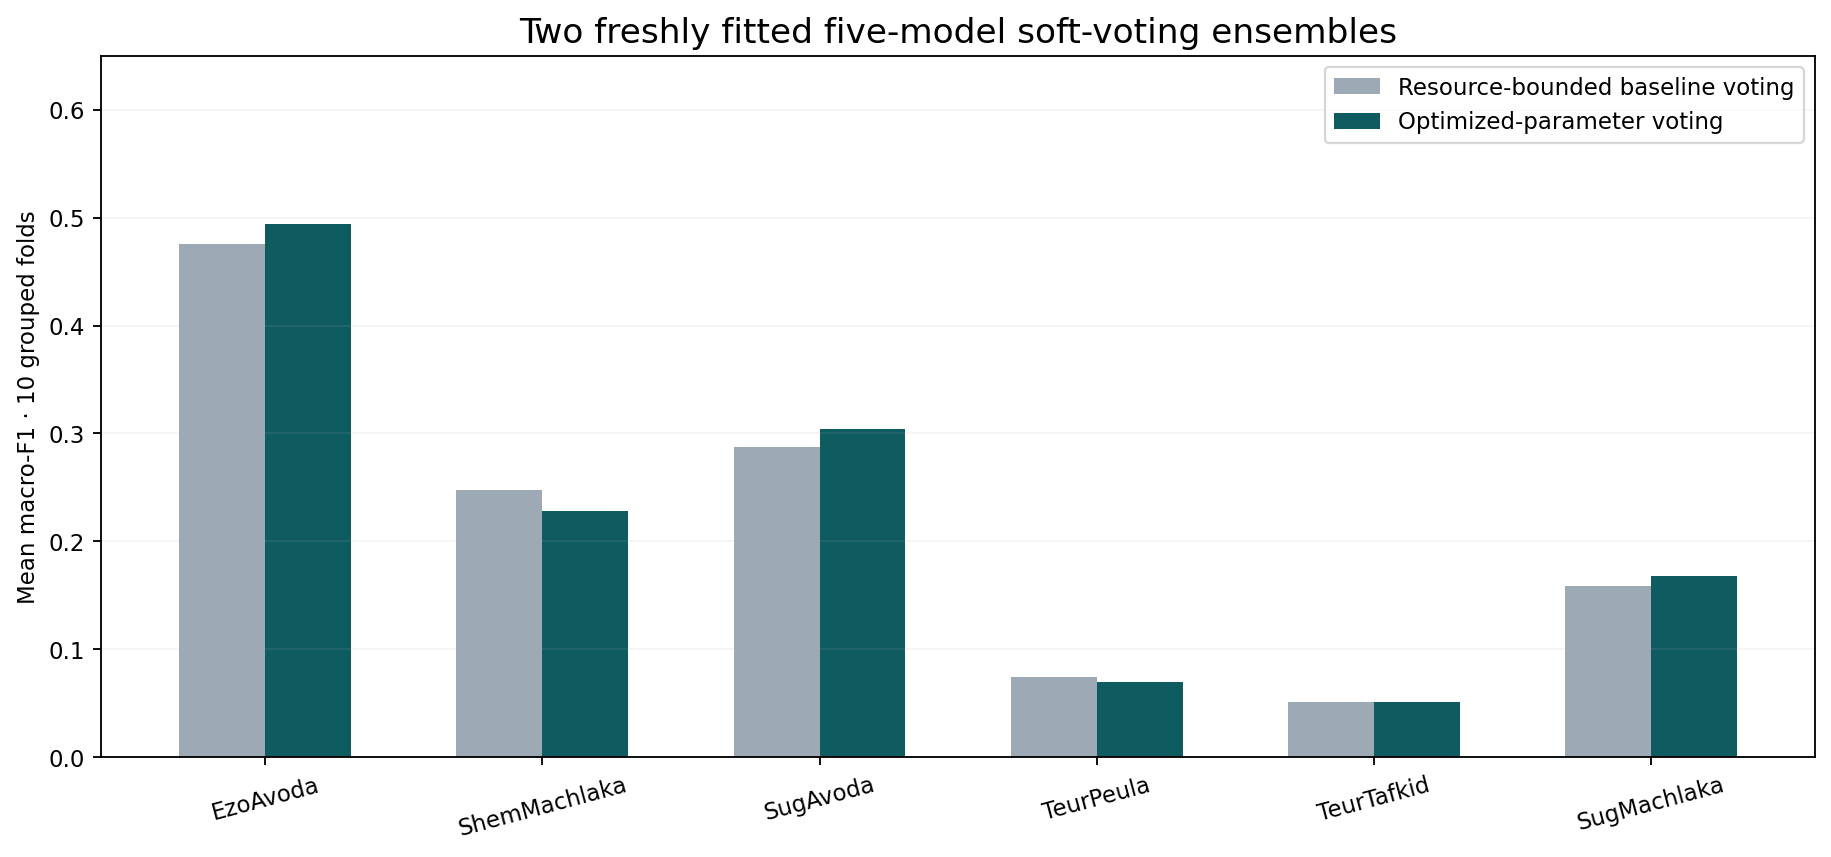

In [ ]:
import matplotlib.pyplot as plt
import numpy as np


def display_two_ensemble_comparison(ensemble_fold_results):
    summary = ensemble_fold_results.groupby(['occupational_text_column','ensemble_name'], as_index=False).agg(mean_macro_f1=('macro_f1','mean'))
    matrix = summary.pivot(index='occupational_text_column',columns='ensemble_name',values='mean_macro_f1')
    axis = matrix.plot.bar(figsize=(12,5.2),rot=15)
    axis.set_ylabel('Mean macro-F1 across 10 grouped folds')
    axis.set_xlabel('Independent occupational text column')
    axis.grid(axis='y',alpha=.15)
    plt.tight_layout()
    plt.show()


display_two_ensemble_comparison(complete_ensemble_fold_scores)


## Every representation · independent classifier macro-F1

All scores shown were measured during training-only grouped validation.

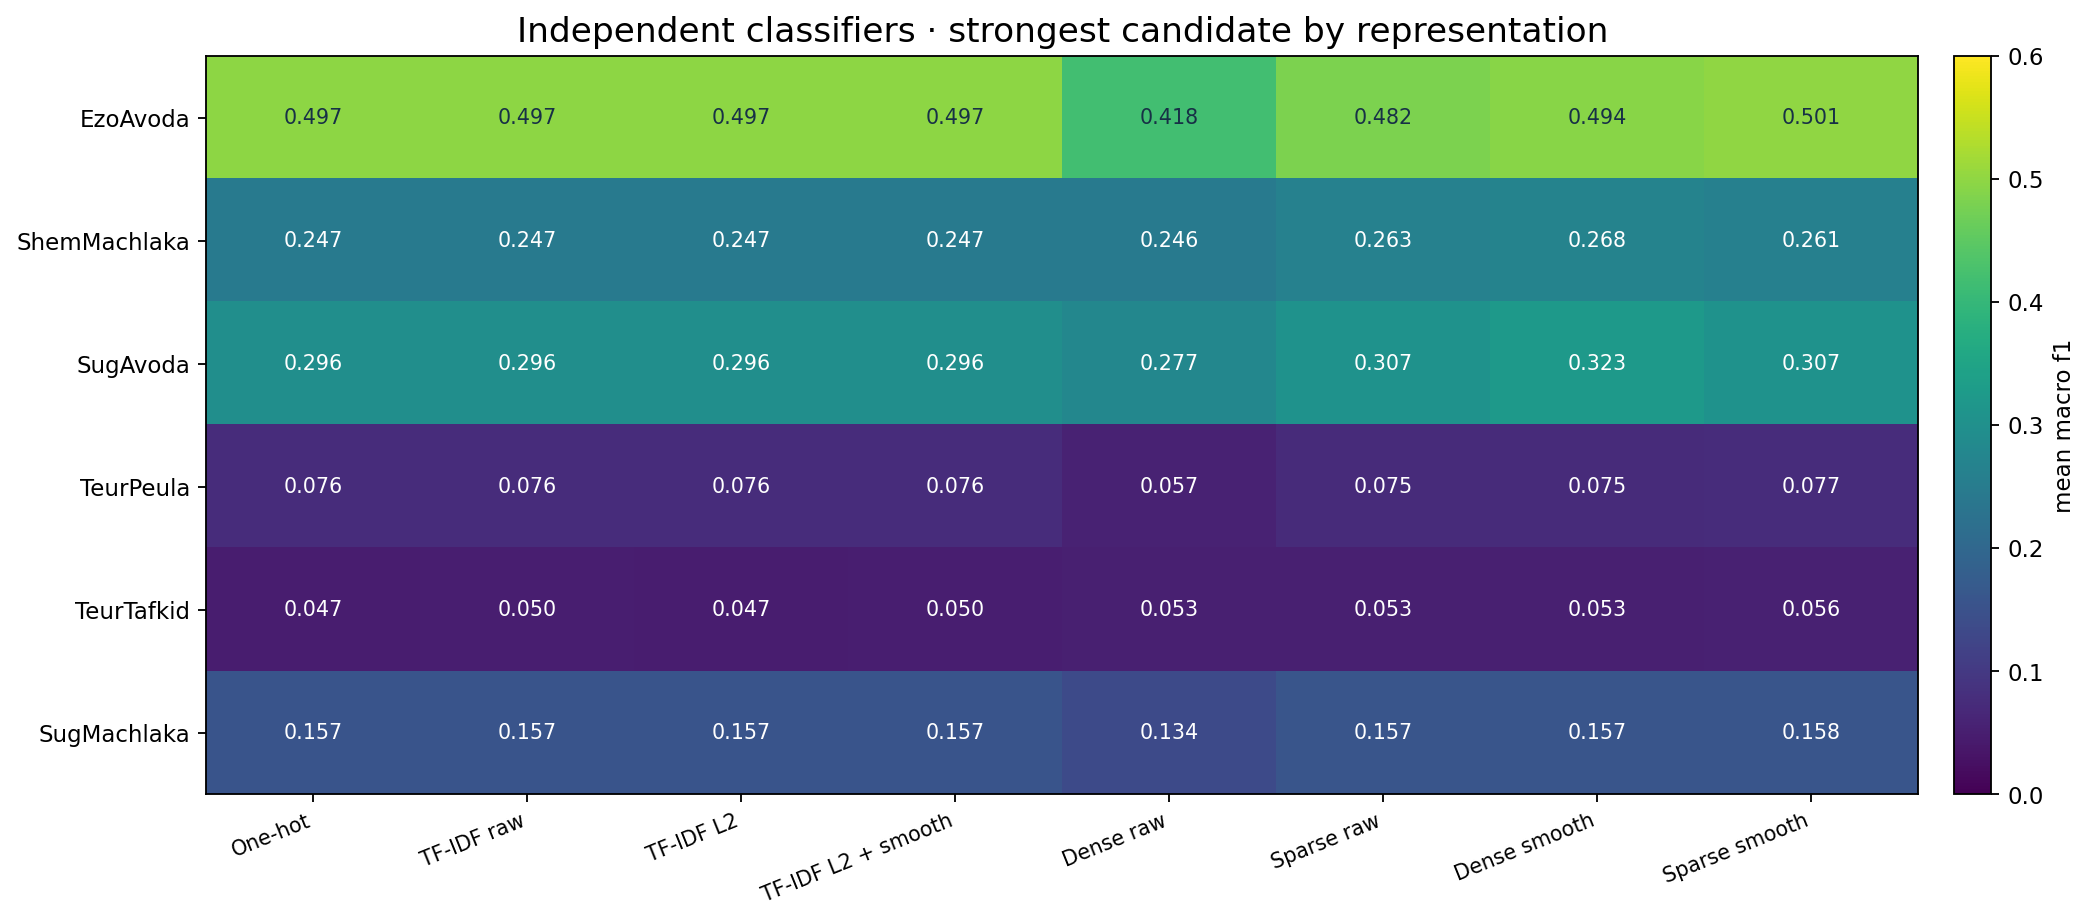

In [ ]:
from IPython.display import Image, display
from base64 import b64decode
display(Image(data=b64decode('...')))

## Every representation · independent classifier accuracy

All scores shown were measured during training-only grouped validation.

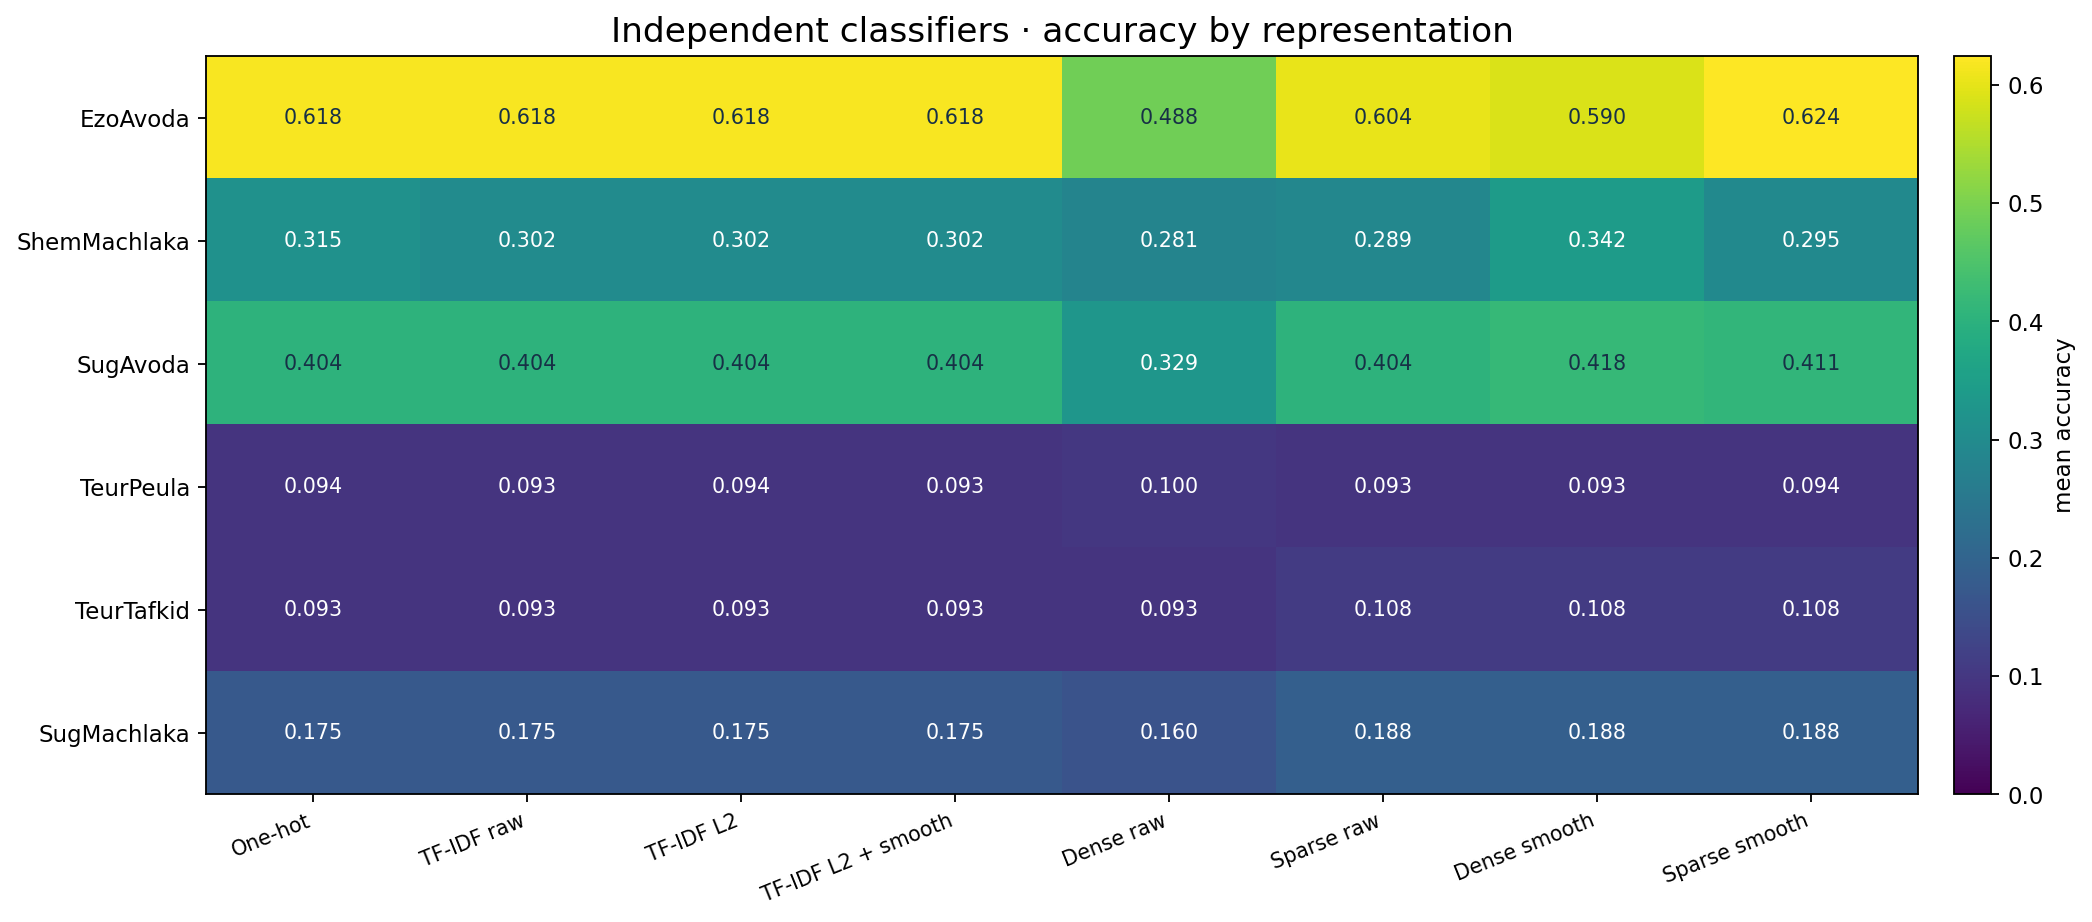

In [ ]:
from IPython.display import Image, display
from base64 import b64decode
display(Image(data=b64decode('...')))

## Independent multiclass classifier families

All scores shown were measured during training-only grouped validation.

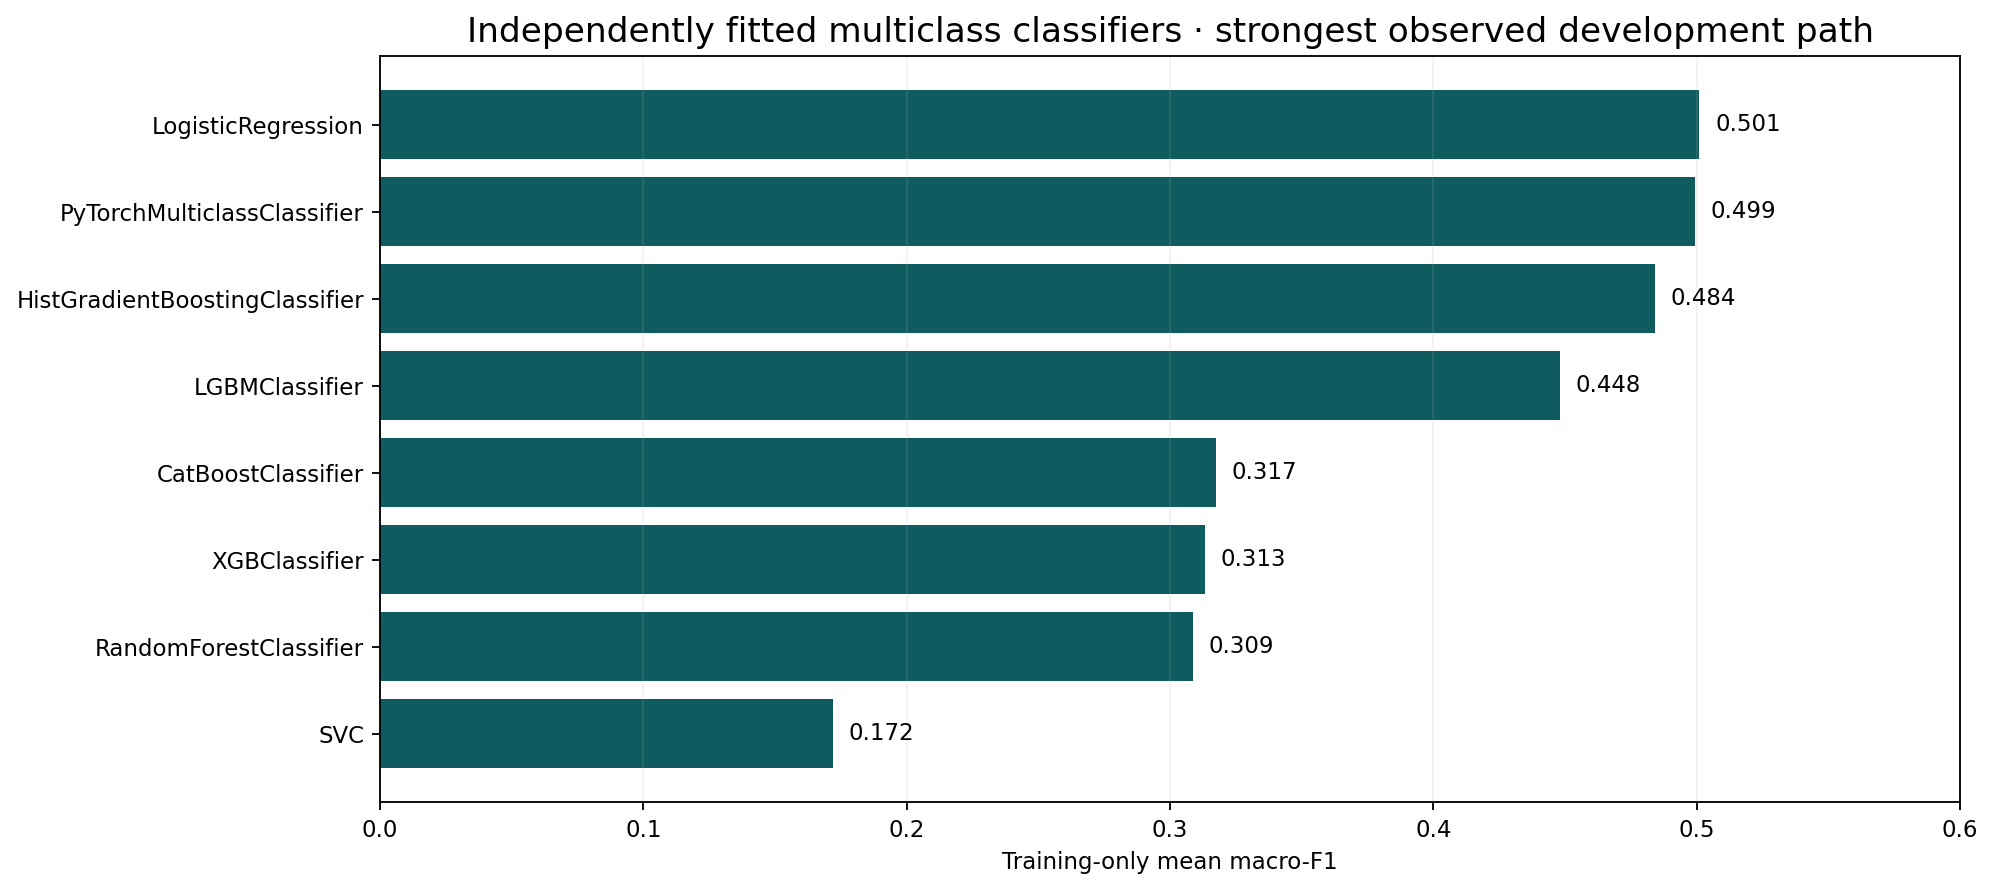

In [ ]:
from IPython.display import Image, display
from base64 import b64decode
display(Image(data=b64decode('...')))

## Ten-fold ensemble comparison

All scores shown were measured during training-only grouped validation.

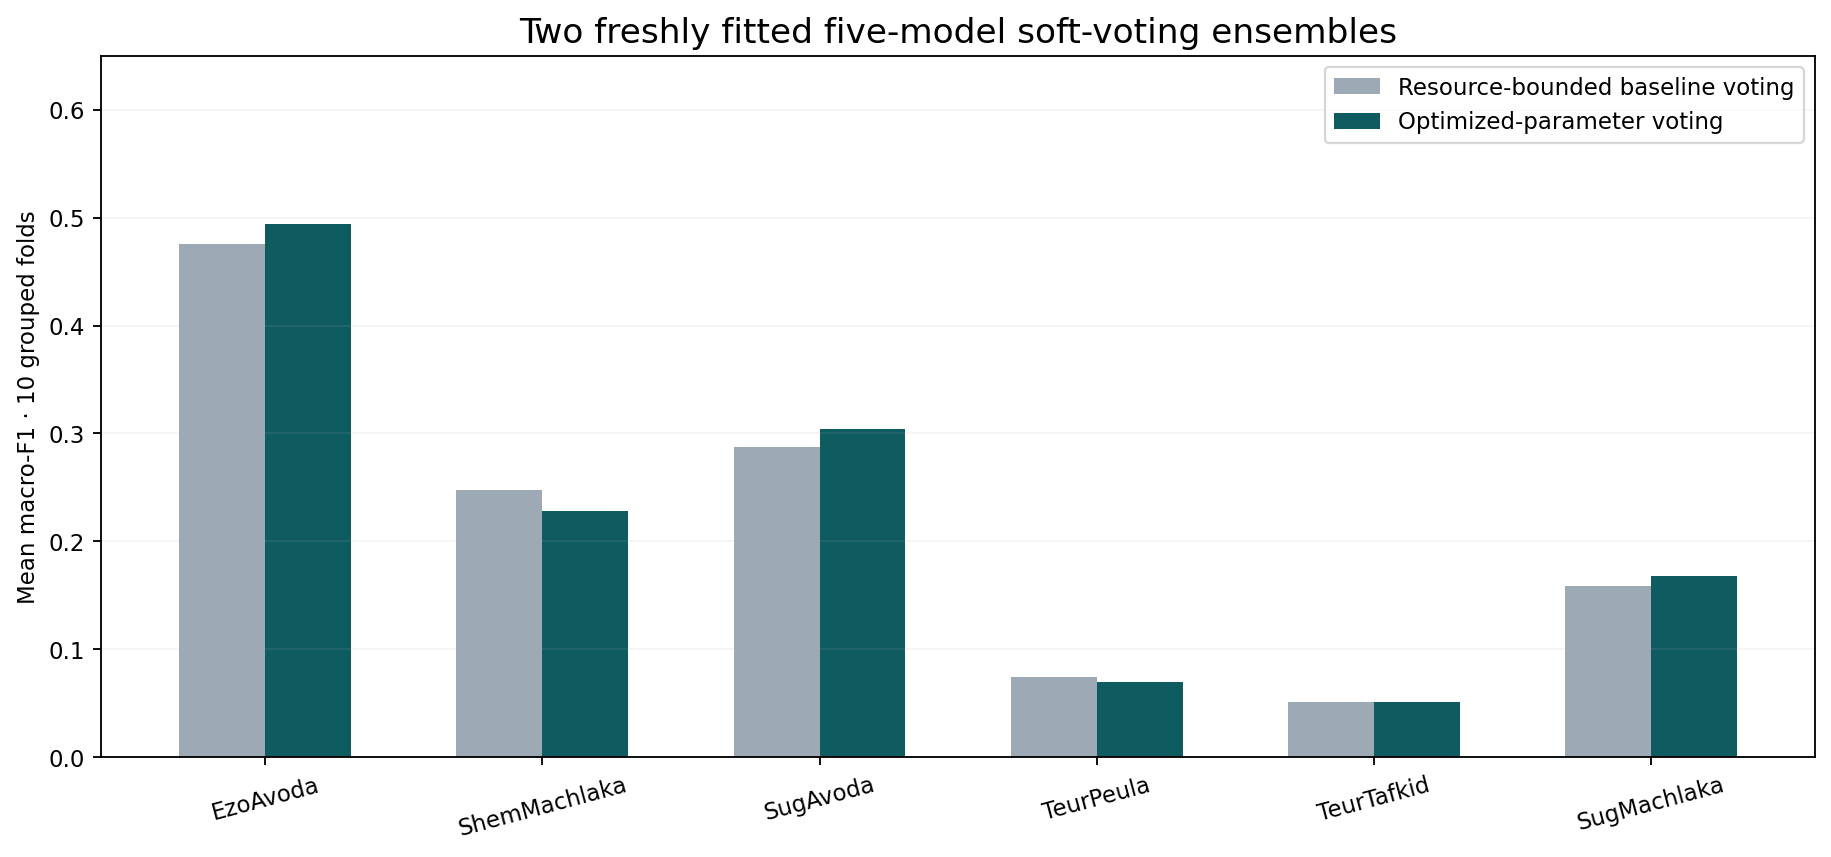

In [ ]:
from IPython.display import Image, display
from base64 import b64decode
display(Image(data=b64decode('...')))

## Each fold · default versus optimized voting

All scores shown were measured during training-only grouped validation.

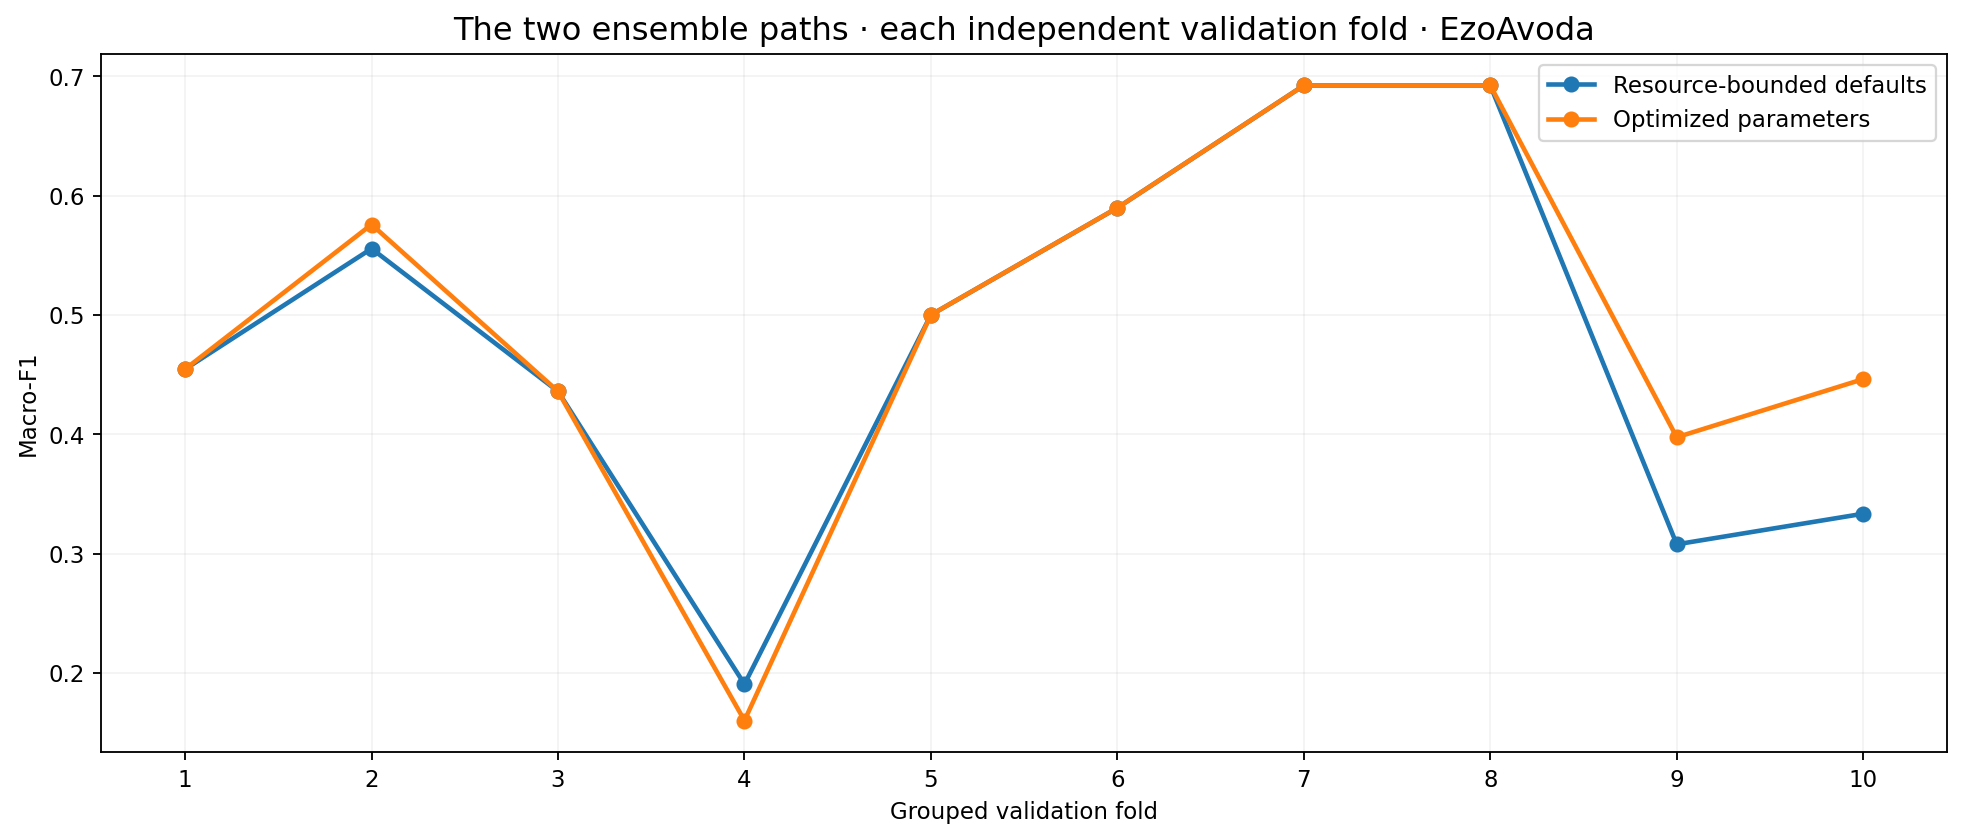

In [ ]:
from IPython.display import Image, display
from base64 import b64decode
display(Image(data=b64decode('...')))

## Model-selection integrity and final retraining

The independent model and ensemble scores use a common ten-fold development partitioning protocol. Hyperparameters were selected on these development folds, so the reported validation means are model-selection evidence, not independent nested cross-validation estimates. The V7 holdout was not used for tuning and its final full-data retraining remains preserved.

In [ ]:
final_selection_comparison = pd.DataFrame([{'v7_reference_mean_macro_f1': 0.5136047286047286, 'new_best_development_mean_macro_f1': 0.5009423909423909, 'selection': 'Preserved V7 final model', 'training_only_selection': True}])
display(final_selection_comparison)

v7_reference_mean_macro_f1,new_best_development_mean_macro_f1,selection,training_only_selection
0.513605,0.500942,Preserved V7 final model,True


## Final retrained classifier · nine records for mandatory manual review

The retained V7 model is trained on all 191 complete occupation-code labels after the held-out assessment. Its nine partial-code suggestions are advisory. The original known digits are preserved in a separate review-compatible suggestion field.

In [ ]:
final_retrained_predictions = pd.DataFrame([{'participant_id': 18, 'original_partial_occupation_code': '1XXX', 'final_retrained_soft_voting_ensemble_prediction': 2511, 'agrees_with_all_known_original_digits': False, 'maximum_uncalibrated_class_probability': 0.0473856922613695, 'operational_disposition': 'human_coder_review_required', 'suggested_code_respecting_existing_digits_for_review': 1212, 'number_of_training_codes_compatible_with_existing_digits': 4, 'uncalibrated_score_of_digit_compatible_suggestion': 0.0132461501826223, 'logistic_regression_prediction': 2411, 'multinomial_naive_bayes_prediction': 2511, 'random_forest_prediction': 2423}, {'participant_id': 45, 'original_partial_occupation_code': 'XXXX', 'final_retrained_soft_voting_ensemble_prediction': 2511, 'agrees_with_all_known_original_digits': True, 'maximum_uncalibrated_class_probability': 0.0473856922613695, 'operational_disposition': 'human_coder_review_required', 'suggested_code_respecting_existing_digits_for_review': 2511, 'number_of_training_codes_compatible_with_existing_digits': 59, 'uncalibrated_score_of_digit_compatible_suggestion': 0.0473856922613695, 'logistic_regression_prediction': 2411, 'multinomial_naive_bayes_prediction': 2511, 'random_forest_prediction': 2423}, {'participant_id': 50, 'original_partial_occupation_code': '1XXX', 'final_retrained_soft_voting_ensemble_prediction': 2511, 'agrees_with_all_known_original_digits': False, 'maximum_uncalibrated_class_probability': 0.0473856922613695, 'operational_disposition': 'human_coder_review_required', 'suggested_code_respecting_existing_digits_for_review': 1212, 'number_of_training_codes_compatible_with_existing_digits': 4, 'uncalibrated_score_of_digit_compatible_suggestion': 0.0132461501826223, 'logistic_regression_prediction': 2411, 'multinomial_naive_bayes_prediction': 2511, 'random_forest_prediction': 2423}, {'participant_id': 81, 'original_partial_occupation_code': '1XXX', 'final_retrained_soft_voting_ensemble_prediction': 2511, 'agrees_with_all_known_original_digits': False, 'maximum_uncalibrated_class_probability': 0.0473856922613695, 'operational_disposition': 'human_coder_review_required', 'suggested_code_respecting_existing_digits_for_review': 1212, 'number_of_training_codes_compatible_with_existing_digits': 4, 'uncalibrated_score_of_digit_compatible_suggestion': 0.0132461501826223, 'logistic_regression_prediction': 2411, 'multinomial_naive_bayes_prediction': 2511, 'random_forest_prediction': 2423}, {'participant_id': 108, 'original_partial_occupation_code': 'XXXX', 'final_retrained_soft_voting_ensemble_prediction': 2511, 'agrees_with_all_known_original_digits': True, 'maximum_uncalibrated_class_probability': 0.0473856922613695, 'operational_disposition': 'human_coder_review_required', 'suggested_code_respecting_existing_digits_for_review': 2511, 'number_of_training_codes_compatible_with_existing_digits': 59, 'uncalibrated_score_of_digit_compatible_suggestion': 0.0473856922613695, 'logistic_regression_prediction': 2411, 'multinomial_naive_bayes_prediction': 2511, 'random_forest_prediction': 2423}, {'participant_id': 113, 'original_partial_occupation_code': '1XXX', 'final_retrained_soft_voting_ensemble_prediction': 2511, 'agrees_with_all_known_original_digits': False, 'maximum_uncalibrated_class_probability': 0.0473856922613695, 'operational_disposition': 'human_coder_review_required', 'suggested_code_respecting_existing_digits_for_review': 1212, 'number_of_training_codes_compatible_with_existing_digits': 4, 'uncalibrated_score_of_digit_compatible_suggestion': 0.0132461501826223, 'logistic_regression_prediction': 2411, 'multinomial_naive_bayes_prediction': 2511, 'random_forest_prediction': 2423}, {'participant_id': 142, 'original_partial_occupation_code': 'XXXX', 'final_retrained_soft_voting_ensemble_prediction': 2511, 'agrees_with_all_known_original_digits': True, 'maximum_uncalibrated_class_probability': 0.0473856922613695, 'operational_disposition': 'human_coder_review_required', 'suggested_code_respecting_existing_digits_for_review': 2511, 'number_of_training_codes_compatible_with_existing_digits': 59, 'uncalibrated_score_of_digit_compatible_suggestion': 0.0473856922613695, 'logistic_regression_prediction': 2411, 'multinomial_naive_bayes_prediction': 2511, 'random_forest_prediction': 2423}, {'participant_id': 165, 'original_partial_occupation_code': '335X', 'final_retrained_soft_voting_ensemble_prediction': 4211, 'agrees_with_all_known_original_digits': False, 'maximum_uncalibrated_class_probability': 0.0505211345085364, 'operational_disposition': 'human_coder_review_required', 'suggested_code_respecting_existing_digits_for_review': 3354, 'number_of_training_codes_compatible_with_existing_digits': 1, 'uncalibrated_score_of_digit_compatible_suggestion': 0.0344533811011617, 'logistic_regression_prediction': 4211, 'multinomial_naive_bayes_prediction': 4211, 'random_forest_prediction': 4211}, {'participant_id': 193, 'original_partial_occupation_code': 'XXXX', 'final_retrained_soft_voting_ensemble_prediction': 2511, 'agrees_with_all_known_original_digits': True, 'maximum_uncalibrated_class_probability': 0.0473856922613695, 'operational_disposition': 'human_coder_review_required', 'suggested_code_respecting_existing_digits_for_review': 2511, 'number_of_training_codes_compatible_with_existing_digits': 59, 'uncalibrated_score_of_digit_compatible_suggestion': 0.0473856922613695, 'logistic_regression_prediction': 2411, 'multinomial_naive_bayes_prediction': 2511, 'random_forest_prediction': 2423}])
display(final_retrained_predictions)

participant_id,original_partial_occupation_code,final_retrained_soft_voting_ensemble_prediction,agrees_with_all_known_original_digits,maximum_uncalibrated_class_probability,operational_disposition,suggested_code_respecting_existing_digits_for_review,number_of_training_codes_compatible_with_existing_digits,uncalibrated_score_of_digit_compatible_suggestion,logistic_regression_prediction,multinomial_naive_bayes_prediction,random_forest_prediction
18,1XXX,2511,False,0.047386,human_coder_review_required,1212,4,0.013246,2411,2511,2423
45,XXXX,2511,True,0.047386,human_coder_review_required,2511,59,0.047386,2411,2511,2423
50,1XXX,2511,False,0.047386,human_coder_review_required,1212,4,0.013246,2411,2511,2423
81,1XXX,2511,False,0.047386,human_coder_review_required,1212,4,0.013246,2411,2511,2423
108,XXXX,2511,True,0.047386,human_coder_review_required,2511,59,0.047386,2411,2511,2423
113,1XXX,2511,False,0.047386,human_coder_review_required,1212,4,0.013246,2411,2511,2423
142,XXXX,2511,True,0.047386,human_coder_review_required,2511,59,0.047386,2411,2511,2423
165,335X,4211,False,0.050521,human_coder_review_required,3354,1,0.034453,4211,4211,4211
193,XXXX,2511,True,0.047386,human_coder_review_required,2511,59,0.047386,2411,2511,2423
